# Modélisation de la probabilité de défaut en risque de crédit

**Livrable de code — notebook unique.** Ce notebook contient **tout le code** du projet et **toutes
les analyses**. Exécuté de haut en bas (*Kernel → Restart & Run All*), il reproduit à l'identique
tous les résultats, tableaux et figures du rapport (`rapport.pdf`).

**Organisation**

| Bloc | Contenu |
|---|---|
| 0 | Mise en place : mécanisme de définition des modules |
| A | **Code** : les 17 modules Python du projet (fonctions pures, documentées) |
| Parties 1 à 8 | **Analyses**, dans l'ordre du sujet, avec l'interprétation de chaque résultat |

**Sommaire des analyses**

1. Qualité des données : variables, cible, identifiants, faible variabilité, manquants, cohérence,
   découpage apprentissage/test (sujet 1.1, Q1–Q4)
2. Valeurs aberrantes : 3 écarts-types contre IQR, stratégies de traitement (Q5–Q6)
3. Variables dérivées DTI, CUR, ACR, ESR, IES (1.2.1)
4. Discrétisation, Khi², T de Tschuprow, WoE, IV (1.2.2–1.2.4)
5. Sélection : 4 bootstraps, PSI, V de Cramér, corrélations (1.3)
6. Régression logistique, stepwise, modèle final (1.4)
7. 100 bootstraps du modèle final, score et PD (1.5.1–1.5.2)
8. XGBoost et comparaison des modèles (1.5.3)

**Règles suivies**

- **Aucune valeur inventée.** Tous les chiffres commentés proviennent des cellules exécutées
  au-dessus du commentaire.
- **Pas de fuite d'information.** Tout paramètre estimé (bornes, imputations, classes, WoE, sélection)
  est appris sur l'échantillon d'apprentissage seul, puis appliqué au test.
- **Reproductibilité.** Graine `RANDOM_STATE = 42`, passée explicitement à chaque tirage.
- **Programmation fonctionnelle.** Les fonctions ne modifient pas leurs entrées. Elles séparent
  l'apprentissage (`fit_*`, qui renvoie des paramètres immuables) de l'application (`apply_*`). Les
  pipelines sont des compositions de fonctions.

**Fichiers.**

- Données brutes : `data/LoanDetails.csv`.
- Sorties écrites par le notebook :
  - `resultats/donnees/` : échantillons traités ;
  - `resultats/tableaux/` : tableaux CSV ;
  - `resultats/tableaux_latex/` : les mêmes tableaux au format LaTeX ;
  - `resultats/figures/` : figures PNG.

## 0. Mise en place

Le code est organisé en **modules** (configuration, qualité des données, discrétisation, modélisation…).
Pour garder ce découpage dans un notebook unique, chaque module est défini dans une cellule qui
commence par la commande `%%module src.<nom>`.

La cellule ci-dessous crée cette commande. Elle exécute le contenu de la cellule comme un module
Python autonome, avec son propre espace de noms, enregistré sous le nom `src.<nom>`. Les instructions
`from src.config import ...` fonctionnent donc exactement comme dans un projet Python classique.

In [1]:
import sys
import types
from pathlib import Path

from IPython.core.magic import register_cell_magic

LIVRABLE_DIR = Path.cwd()  # dossier du livrable (contient data/LoanDetails.csv)
PROJECT_ROOT = LIVRABLE_DIR

package = types.ModuleType("src")
package.__path__ = []
sys.modules["src"] = package


@register_cell_magic
def module(line: str, cell: str) -> None:
    """Exécute la cellule comme le module ``line`` (ex. ``src.config``) et l'enregistre."""
    name = line.strip()
    mod = types.ModuleType(name)
    mod.__file__ = f"<notebook:{name}>"
    sys.modules[name] = mod
    setattr(package, name.split(".", 1)[1], mod)
    exec(compile(cell, name, "exec"), mod.__dict__)
    print(f"module {name} défini")

# A. Code du projet

Les 17 modules sont définis dans l'ordre de leurs dépendances. Chaque fonction porte une *docstring*
qui précise ses entrées, sa sortie et ses hypothèses. La documentation technique (`documentation.pdf`)
les décrit en détail.

**Rôle de chaque module**

| Module | Rôle |
|---|---|
| `src.config` | Paramètres globaux : graine, chemins, rôles des variables, seuils du sujet. |
| `src.data_loading` | Lecture du CSV brut (sans interpréter les manquants), typage, codage de la cible. |
| `src.data_quality` | Analyses de qualité (sujet 1.1, Q1–Q4) et traitements déterministes composés par `reduce`. |
| `src.reporting` | Export des tableaux en CSV et en `tabular` LaTeX (formateurs à la française). |
| `src.binning` | Discrétisation en quantiles, Khi², T de Tschuprow, V de Cramér, regroupements, WoE et IV (1.2.2–1.2.4). |
| `src.selection` | Bootstrap de stabilité, PSI, pouvoir discriminant, corrélations et jeu final (1.3). |
| `src.sampling` | Découpage apprentissage/test stratifié et représentativité (1.4.1). |
| `src.outliers` | Détection (3 écarts-types, IQR), comparaison, stratégies et plafonnement (Q5–Q6). |
| `src.features` | Variables dérivées DTI, CUR, ACR, ESR, IES avec divisions sûres (1.2.1). |
| `src.imputation` | Imputations apprises sur l'apprentissage : hot-deck du montant, mode des faillites. |
| `src.modeling` | Régression logistique, métriques, stepwise, bootstrap, score, PD et contributions (1.4, 1.5.1–1.5.2). |
| `src.xgb_model` | XGBoost : variables d'entrée, recherche sur grille, comparaison (1.5.3). |
| `src.plots` | Style graphique commun et figures de la qualité des données. |
| `src.plots_outliers` | Figures des valeurs aberrantes. |
| `src.plots_features` | Figures des variables dérivées. |
| `src.plots_model` | Figures de la discrétisation, de la sélection et de la modélisation. |
| `src.pipeline` | Préparation commune des parties 4 à 8 : imputation, discrétisation et WoE appris sur l'apprentissage. |

### Module `src.config`

Paramètres globaux : graine, chemins, rôles des variables, seuils du sujet.

In [2]:
%%module src.config
"""Paramètres globaux du projet : chemins, seed, rôles des variables et seuils."""

from pathlib import Path

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd()  # dossier du livrable
RAW_DATA_PATH = PROJECT_ROOT / "data" / "LoanDetails.csv"
PROCESSED_DIR = PROJECT_ROOT / "resultats" / "donnees"
TABLES_DIR = PROJECT_ROOT / "resultats" / "tableaux"
LATEX_TABLES_DIR = PROJECT_ROOT / "resultats" / "tableaux_latex"
FIGURES_DIR = PROJECT_ROOT / "resultats" / "figures"

# --- Variable cible -------------------------------------------------------
TARGET_RAW = "Loan Status"
TARGET = "default"
DEFAULT_LABEL = "Charged Off"
NON_DEFAULT_LABEL = "Fully Paid"

# --- Rôles et natures des variables ---------------------------------------
LOAN_ID = "Loan ID"
ID_COLUMNS = [LOAN_ID, "Customer ID"]

QUANTITATIVE_CONTINUOUS = [
    "Current Loan Amount",
    "Credit Score",
    "Annual Income",
    "Monthly Debt",
    "Years of Credit History",
    "Months since last delinquent",
    "Current Credit Balance",
    "Maximum Open Credit",
]
QUANTITATIVE_DISCRETE = [
    "Number of Open Accounts",
    "Number of Credit Problems",
    "Bankruptcies",
    "Tax Liens",
]
QUALITATIVE_NOMINAL = ["Term", "Home Ownership", "Purpose"]
QUALITATIVE_ORDINAL = ["Years in current job"]

NUMERIC_COLUMNS = QUANTITATIVE_CONTINUOUS + QUANTITATIVE_DISCRETE
CATEGORICAL_COLUMNS = QUALITATIVE_NOMINAL + QUALITATIVE_ORDINAL
FEATURE_COLUMNS = NUMERIC_COLUMNS + CATEGORICAL_COLUMNS

# --- Codage des valeurs manquantes dans le fichier source -----------------
# Le fichier distingue trois codages ; ils sont lus séparément pour pouvoir
# séparer les valeurs non applicables des vraies valeurs manquantes.
MISSING_TOKENS = ("", "NA", "n/a")

# --- Anomalies connues ----------------------------------------------------
LOAN_AMOUNT_SENTINEL = 99_999_999
CREDIT_SCORE_MAX = 850  # borne haute des scores de type FICO
CREDIT_SCORE_SCALE_FACTOR = 10

# Harmonisation purement syntaxique / synonymes stricts (pas de regroupement
# par niveau de risque : celui-ci relève de la phase de transformation).
LABEL_HARMONIZATION = {
    "Purpose": {
        "other": "Other",
        "small_business": "Business Loan",
        "vacation": "Take a Trip",
        "major_purchase": "Major Purchase",
        "moving": "Moving",
        "wedding": "Wedding",
    },
    "Home Ownership": {"HaveMortgage": "Home Mortgage"},
}

# --- Seuils du sujet ------------------------------------------------------
DOMINANT_MODALITY_THRESHOLD = 0.95
HIGH_MISSING_THRESHOLD = 0.10
SIGNIFICANCE_LEVEL = 0.05

# Ordre naturel des modalités de la variable ordinale (pour l'affichage).
YEARS_IN_JOB_ORDER = ["< 1 year", "1 year"] + [f"{i} years" for i in range(2, 10)] + ["10+ years"]

# --- Découpage apprentissage / test (sujet 1.4.1) ---------------------------
TEST_SIZE = 0.20

# --- Valeurs aberrantes (sujet 1.1, Q5–Q6) ---------------------------------
OUTLIER_COLUMNS = [c for c in NUMERIC_COLUMNS if c != "Tax Liens"]  # Tax Liens exclue en Q2
CAPPING_COLUMNS = ["Annual Income", "Monthly Debt", "Current Credit Balance", "Maximum Open Credit"]
CAPPING_QUANTILE = 0.99

# --- Sélection des variables (sujet 1.3.3) ---------------------------------
CORRELATION_THRESHOLD = 0.4

module src.config défini


### Module `src.data_loading`

Lecture du CSV brut (sans interpréter les manquants), typage, codage de la cible.

In [3]:
%%module src.data_loading
"""Chargement du fichier brut et typage des colonnes."""

from pathlib import Path

import pandas as pd

from src.config import (
    DEFAULT_LABEL,
    MISSING_TOKENS,
    NON_DEFAULT_LABEL,
    NUMERIC_COLUMNS,
    RAW_DATA_PATH,
)


def load_raw(path: Path = RAW_DATA_PATH) -> pd.DataFrame:
    """Lit le CSV en texte brut, sans interpréter les valeurs manquantes.

    Toutes les cellules restent des chaînes : une cellule vide vaut ``""``,
    les jetons ``"NA"`` et ``"n/a"`` sont conservés tels quels. Cela permet
    de distinguer ensuite les différents codages du manquant.
    """
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")


def to_typed(raw: pd.DataFrame) -> pd.DataFrame:
    """Remplace les jetons de manquant par NaN et convertit les colonnes numériques.

    La conversion échoue (``ValueError``) si une colonne numérique contient
    une valeur non numérique autre qu'un jeton de manquant connu.
    """
    typed = raw.replace(list(MISSING_TOKENS), pd.NA)
    for col in NUMERIC_COLUMNS:
        typed[col] = pd.to_numeric(typed[col], errors="raise").astype(float)
    return typed


def encode_target(status: pd.Series) -> pd.Series:
    """Code la cible : 1 = défaut (Charged Off), 0 = non-défaut (Fully Paid).

    Lève ``ValueError`` si une modalité inattendue (ou manquante) est présente.
    """
    mapping = {DEFAULT_LABEL: 1, NON_DEFAULT_LABEL: 0}
    unexpected = set(status.dropna().unique()) - set(mapping)
    if unexpected or status.isna().any():
        raise ValueError(f"Modalités de cible inattendues : {sorted(unexpected)}")
    return status.map(mapping).astype(int).rename("default")

module src.data_loading défini


### Module `src.data_quality`

Analyses de qualité (sujet 1.1, Q1–Q4) et traitements déterministes composés par `reduce`.

In [4]:
%%module src.data_quality
"""Analyse de la qualité des données (section 1.1 du sujet, questions 1 à 4).

Les fonctions d'analyse renvoient des tableaux ``pandas`` ; les fonctions de
traitement renvoient une copie modifiée et ne réalisent que des corrections
déterministes (aucun paramètre appris sur les données : pas d'imputation,
pas de binning), afin d'éviter toute fuite d'information avant le découpage
apprentissage / test.
"""

from collections.abc import Callable, Mapping
from functools import partial, reduce

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

from src.config import (
    CATEGORICAL_COLUMNS,
    CREDIT_SCORE_MAX,
    CREDIT_SCORE_SCALE_FACTOR,
    DOMINANT_MODALITY_THRESHOLD,
    HIGH_MISSING_THRESHOLD,
    ID_COLUMNS,
    LOAN_AMOUNT_SENTINEL,
    LOAN_ID,
    MISSING_TOKENS,
    QUALITATIVE_NOMINAL,
    QUALITATIVE_ORDINAL,
    QUANTITATIVE_CONTINUOUS,
    QUANTITATIVE_DISCRETE,
    TARGET_RAW,
)

MISSING_LABEL = "Manquant"

# Nature des valeurs manquantes, établie à partir du codage et du sens métier.
MISSING_NATURE: dict[str, tuple[str, str]] = {
    "Months since last delinquent": (
        "Non applicable",
        "Aucun retard de paiement enregistré : la durée depuis le dernier retard n'existe pas.",
    ),
    "Years in current job": (
        "Ambigu",
        "Jeton 'n/a' : sans emploi salarié (indépendant, retraité…) ou non renseigné.",
    ),
}
DEFAULT_MISSING_NATURE = (
    "Manquant réel",
    "La grandeur existe pour tout emprunteur mais n'a pas été collectée.",
)

_NATURE_BY_GROUP = {
    "Quantitative continue": QUANTITATIVE_CONTINUOUS,
    "Quantitative discrète": QUANTITATIVE_DISCRETE,
    "Qualitative nominale": QUALITATIVE_NOMINAL,
    "Qualitative ordinale": QUALITATIVE_ORDINAL,
}


# ---------------------------------------------------------------------------
# Utilitaires
# ---------------------------------------------------------------------------
def parse_years_in_job(values: pd.Series) -> pd.Series:
    """Convertit 'Years in current job' en nombre d'années (``< 1 year`` → 0, ``10+`` → 10)."""
    text = values.astype("string")
    years = text.str.extract(r"(\d+)")[0].astype(float)
    return years.mask(text.str.startswith("<", na=False), 0.0)


def chi2_pvalue(feature: pd.Series, y: pd.Series) -> float:
    """p-value du test du Khi-deux d'indépendance entre une variable discrète et la cible."""
    table = pd.crosstab(feature, y)
    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan
    return float(chi2_contingency(table)[1])


def with_missing_label(values: pd.Series) -> pd.Series:
    """Remplace les valeurs manquantes par la modalité explicite « Manquant »."""
    return values.astype("object").where(values.notna(), MISSING_LABEL)


def _variable_nature(col: str) -> str:
    if col in ID_COLUMNS:
        return "Identifiant"
    if col == TARGET_RAW:
        return "Qualitative binaire (cible)"
    for nature, cols in _NATURE_BY_GROUP.items():
        if col in cols:
            return nature
    return "Non classée"


def _variable_role(col: str) -> str:
    if col in ID_COLUMNS:
        return "Identifiant"
    return "Cible" if col == TARGET_RAW else "Explicative"


# ---------------------------------------------------------------------------
# Q1 — Inventaire, cible, synthèse
# ---------------------------------------------------------------------------
def variable_inventory(typed: pd.DataFrame) -> pd.DataFrame:
    """Tableau des variables : rôle, nature, type pandas, modalités distinctes, exemples."""
    rows = []
    for col in typed.columns:
        values = typed[col].dropna()
        examples = values.value_counts().index[:3].astype(str)
        rows.append(
            {
                "variable": col,
                "rôle": _variable_role(col),
                "nature": _variable_nature(col),
                "type": str(typed[col].dtype),
                "n_distinct": values.nunique(),
                "n_manquants": int(typed[col].isna().sum()),
                "exemples (plus fréquents)": " | ".join(examples),
            }
        )
    return pd.DataFrame(rows)


def target_summary(y: pd.Series, labels: pd.Series) -> pd.DataFrame:
    """Effectifs et proportions de chaque modalité de la cible."""
    table = (
        pd.DataFrame({"modalité": labels, "code": y})
        .value_counts()
        .rename("effectif")
        .reset_index()
        .sort_values("code")
    )
    table["proportion"] = table["effectif"] / table["effectif"].sum()
    return table.reset_index(drop=True)


def dataset_overview(typed: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """Tableau récapitulatif des principales caractéristiques de la base."""
    features = [c for c in typed.columns if _variable_role(c) == "Explicative"]
    natures = pd.Series([_variable_nature(c) for c in features])
    metrics = {
        "Nombre d'observations": len(typed),
        "Nombre de colonnes": typed.shape[1],
        "Identifiants": len(ID_COLUMNS),
        "Variable cible": 1,
        "Variables explicatives": len(features),
        "dont quantitatives continues": int((natures == "Quantitative continue").sum()),
        "dont quantitatives discrètes": int((natures == "Quantitative discrète").sum()),
        "dont qualitatives": int(natures.str.startswith("Qualitative").sum()),
        "Nombre de défauts": int(y.sum()),
        "Taux de défaut global": round(float(y.mean()), 4),
        "Cellules manquantes (explicatives)": int(typed[features].isna().sum().sum()),
        "Part de cellules manquantes": round(float(typed[features].isna().mean().mean()), 4),
        "Lignes entièrement dupliquées": int(typed.duplicated().sum()),
        "Identifiants de prêt distincts": int(typed[LOAN_ID].nunique()),
    }
    return pd.DataFrame({"indicateur": list(metrics), "valeur": pd.Series(list(metrics.values()), dtype=object)})


def numeric_description(typed: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Statistiques descriptives des variables quantitatives (valeurs brutes)."""
    desc = typed[columns].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
    desc.insert(0, "n_manquants", typed[columns].isna().sum())
    return desc


def category_default_rates(typed: pd.DataFrame, y: pd.Series, column: str) -> pd.DataFrame:
    """Effectif, part et taux de défaut de chaque modalité (manquant inclus)."""
    feature = with_missing_label(typed[column])
    table = y.groupby(feature).agg(effectif="size", n_defauts="sum")
    table["part"] = table["effectif"] / table["effectif"].sum()
    table["taux_defaut"] = table["n_defauts"] / table["effectif"]
    return table.sort_values("effectif", ascending=False).rename_axis("modalité").reset_index()


# ---------------------------------------------------------------------------
# Q2 — Identifiants et faible variabilité
# ---------------------------------------------------------------------------
def identifier_report(raw: pd.DataFrame, id_columns: list[str] = ID_COLUMNS) -> pd.DataFrame:
    """Unicité des colonnes identifiantes."""
    rows = []
    for col in id_columns:
        n_distinct = raw[col].nunique()
        rows.append(
            {
                "variable": col,
                "n_observations": len(raw),
                "n_distinct": n_distinct,
                "part_distinct": n_distinct / len(raw),
                "lignes_en_double": int(raw[col].duplicated().sum()),
            }
        )
    return pd.DataFrame(rows)


def identifier_cardinality(raw: pd.DataFrame) -> pd.DataFrame:
    """Nombre maximal de clients par prêt et de prêts par client."""
    loan_col, customer_col = ID_COLUMNS
    return pd.DataFrame(
        {
            "relation": ["clients distincts par prêt (max)", "prêts distincts par client (max)"],
            "valeur": [
                int(raw.groupby(loan_col)[customer_col].nunique().max()),
                int(raw.groupby(customer_col)[loan_col].nunique().max()),
            ],
        }
    )


def dominant_modality_table(
    typed: pd.DataFrame,
    y: pd.Series,
    columns: list[str],
    threshold: float = DOMINANT_MODALITY_THRESHOLD,
) -> pd.DataFrame:
    """Part de la modalité la plus fréquente (le manquant compte comme une modalité).

    Pour juger l'intérêt statistique d'une variable quasi constante, on compare
    le taux de défaut de la modalité dominante à celui des autres observations
    (test du Khi-deux 2×2).
    """
    rows = []
    for col in columns:
        feature = with_missing_label(typed[col])
        shares = feature.value_counts(normalize=True)
        is_top = feature == shares.index[0]
        rows.append(
            {
                "variable": col,
                "n_modalités": feature.nunique(),
                "modalité_dominante": str(shares.index[0]),
                "part_dominante": shares.iloc[0],
                f"dépasse_{threshold:.0%}": shares.iloc[0] > threshold,
                "taux_defaut_dominante": y[is_top].mean(),
                "taux_defaut_autres": y[~is_top].mean() if (~is_top).any() else np.nan,
                "p_value_khi2": chi2_pvalue(is_top, y),
            }
        )
    return pd.DataFrame(rows).sort_values("part_dominante", ascending=False, ignore_index=True)


# ---------------------------------------------------------------------------
# Q3 — Valeurs manquantes
# ---------------------------------------------------------------------------
def missing_token_counts(raw: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Nombre de cellules par jeton de manquant (vide, 'NA', 'n/a') et par variable."""
    counts = {
        f"n_{token or 'vide'}": [(raw[col] == token).sum() for col in columns]
        for token in MISSING_TOKENS
    }
    return pd.DataFrame(counts, index=pd.Index(columns, name="variable"))


def missing_profile(
    typed: pd.DataFrame,
    y: pd.Series,
    columns: list[str],
    threshold: float = HIGH_MISSING_THRESHOLD,
) -> pd.DataFrame:
    """Taux de manquant, nature et taux de défaut avec / sans valeur, par variable."""
    rows = []
    for col in columns:
        is_missing = typed[col].isna()
        nature, justification = MISSING_NATURE.get(col, DEFAULT_MISSING_NATURE)
        has_missing = bool(is_missing.any())
        rows.append(
            {
                "variable": col,
                "n_manquants": int(is_missing.sum()),
                "taux_manquant": is_missing.mean(),
                f"dépasse_{threshold:.0%}": is_missing.mean() > threshold,
                "nature": nature if has_missing else "—",
                "justification": justification if has_missing else "—",
                "taux_defaut_si_manquant": y[is_missing].mean() if has_missing else np.nan,
                "taux_defaut_si_renseigné": y[~is_missing].mean(),
                "p_value_khi2": chi2_pvalue(is_missing, y) if has_missing else np.nan,
            }
        )
    return pd.DataFrame(rows).set_index("variable")


def missing_value_table(
    raw: pd.DataFrame, typed: pd.DataFrame, y: pd.Series, columns: list[str]
) -> pd.DataFrame:
    """Combine le détail des jetons et le profil de manquant ; trié par taux décroissant."""
    table = missing_token_counts(raw, columns).join(missing_profile(typed, y, columns))
    return table.sort_values("taux_manquant", ascending=False).reset_index()


def missing_co_occurrence(typed: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Nombre d'observations où deux variables sont manquantes simultanément."""
    indicators = typed[columns].isna().astype(int)
    return indicators.T @ indicators


# ---------------------------------------------------------------------------
# Q4 — Doublons et contrôles de cohérence
# ---------------------------------------------------------------------------
def duplicate_summary(raw: pd.DataFrame) -> pd.DataFrame:
    """Doublons exacts et doublons d'identifiant de prêt."""
    deduplicated = raw.drop_duplicates()
    loan_groups = deduplicated.groupby(LOAN_ID)
    near_duplicates = loan_groups.size().gt(1)
    status_conflicts = loan_groups[TARGET_RAW].nunique().gt(1)
    metrics = {
        "Lignes entièrement dupliquées (à supprimer)": int(raw.duplicated().sum()),
        "Lignes après suppression des doublons exacts": len(deduplicated),
        "Loan ID partagés par des lignes différentes": int(near_duplicates.sum()),
        "dont statut de défaut contradictoire": int(status_conflicts.sum()),
        "Prêts uniques (Loan ID distincts)": int(raw[LOAN_ID].nunique()),
    }
    return pd.DataFrame({"contrôle": metrics.keys(), "valeur": metrics.values()})


def near_duplicate_differences(raw: pd.DataFrame) -> pd.DataFrame:
    """Pour chaque Loan ID partagé par des lignes non identiques : colonnes qui diffèrent."""
    deduplicated = raw.drop_duplicates()
    shared = deduplicated[deduplicated[LOAN_ID].duplicated(keep=False)]
    rows = []
    for loan_id, group in shared.groupby(LOAN_ID):
        differing = group.columns[group.nunique() > 1].tolist()
        rows.append(
            {
                LOAN_ID: loan_id,
                "colonnes_différentes": ", ".join(differing),
                "valeurs": " / ".join(
                    "{" + ", ".join(f"{c}={v or 'vide'}" for c, v in row.items()) + "}"
                    for _, row in group[differing].iterrows()
                ),
            }
        )
    return pd.DataFrame(rows)


ConsistencyRule = tuple[str, str, Callable[[pd.DataFrame], pd.Series]]


def consistency_rules() -> list[ConsistencyRule]:
    """Règles de cohérence : (nom, variables concernées, fonction → masque des lignes en anomalie)."""

    def years_in_job(d: pd.DataFrame) -> pd.Series:
        return parse_years_in_job(d["Years in current job"])

    return [
        ("Montant du prêt = 99 999 999 (valeur sentinelle)", "Current Loan Amount",
         lambda d: d["Current Loan Amount"] == LOAN_AMOUNT_SENTINEL),
        (f"Credit Score > {CREDIT_SCORE_MAX} (hors échelle)", "Credit Score",
         lambda d: d["Credit Score"] > CREDIT_SCORE_MAX),
        ("Credit Score < 300 (hors échelle)", "Credit Score",
         lambda d: d["Credit Score"] < 300),
        ("Revenu annuel ≤ 0", "Annual Income", lambda d: d["Annual Income"] <= 0),
        ("Dette mensuelle < 0", "Monthly Debt", lambda d: d["Monthly Debt"] < 0),
        ("Dette mensuelle = 0", "Monthly Debt", lambda d: d["Monthly Debt"] == 0),
        ("Dette annuelle > revenu annuel", "Monthly Debt, Annual Income",
         lambda d: 12 * d["Monthly Debt"] > d["Annual Income"]),
        ("Ancienneté de crédit ≤ 0", "Years of Credit History",
         lambda d: d["Years of Credit History"] <= 0),
        ("Ancienneté emploi > ancienneté de crédit", "Years in current job, Years of Credit History",
         lambda d: years_in_job(d) > d["Years of Credit History"]),
        ("Dernier retard antérieur à l'historique de crédit", "Months since last delinquent, Years of Credit History",
         lambda d: d["Months since last delinquent"] > 12 * d["Years of Credit History"]),
        ("Nombre de comptes ouverts = 0", "Number of Open Accounts",
         lambda d: d["Number of Open Accounts"] == 0),
        ("Crédit maximal autorisé = 0", "Maximum Open Credit",
         lambda d: d["Maximum Open Credit"] == 0),
        ("Encours > crédit maximal autorisé", "Current Credit Balance, Maximum Open Credit",
         lambda d: d["Current Credit Balance"] > d["Maximum Open Credit"]),
        ("Faillites > incidents de crédit", "Bankruptcies, Number of Credit Problems",
         lambda d: d["Bankruptcies"] > d["Number of Credit Problems"]),
        ("Privilèges fiscaux > incidents de crédit", "Tax Liens, Number of Credit Problems",
         lambda d: d["Tax Liens"] > d["Number of Credit Problems"]),
        ("Credit Score et Annual Income manquants séparément", "Credit Score, Annual Income",
         lambda d: d["Credit Score"].isna() != d["Annual Income"].isna()),
    ]


def consistency_checks(typed: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """Applique les règles de cohérence ; donne l'effectif et le taux de défaut des anomalies."""
    rows = []
    for name, variables, rule in consistency_rules():
        mask = rule(typed).fillna(False).astype(bool)
        rows.append(
            {
                "contrôle": name,
                "variables": variables,
                "n_anomalies": int(mask.sum()),
                "part": mask.mean(),
                "taux_defaut_anomalies": y[mask].mean() if mask.any() else np.nan,
                "taux_defaut_autres": y[~mask].mean(),
            }
        )
    return pd.DataFrame(rows)


def label_variants(typed: pd.DataFrame, columns: list[str] = CATEGORICAL_COLUMNS) -> pd.DataFrame:
    """Modalités qui ne diffèrent que par la casse ou les séparateurs (ex. 'other' / 'Other')."""
    rows = []
    for col in columns:
        labels = pd.Series(typed[col].dropna().unique())
        normalized = labels.str.lower().str.replace(r"[\s_\-]+", "", regex=True)
        for _, group in labels.groupby(normalized):
            if len(group) > 1:
                rows.append({"variable": col, "modalités": " | ".join(sorted(group))})
    return pd.DataFrame(rows, columns=["variable", "modalités"])


# ---------------------------------------------------------------------------
# Traitements déterministes
# ---------------------------------------------------------------------------
def replace_loan_amount_sentinel(df: pd.DataFrame) -> pd.DataFrame:
    """Remplace la valeur sentinelle 99 999 999 du montant du prêt par NaN."""
    out = df.copy()
    out["Current Loan Amount"] = out["Current Loan Amount"].mask(
        out["Current Loan Amount"] == LOAN_AMOUNT_SENTINEL
    )
    return out


def rescale_credit_score(df: pd.DataFrame) -> pd.DataFrame:
    """Divise par 10 les Credit Score supérieurs à 850 (erreur d'échelle ×10)."""
    out = df.copy()
    too_high = out["Credit Score"] > CREDIT_SCORE_MAX
    out.loc[too_high, "Credit Score"] = out.loc[too_high, "Credit Score"] / CREDIT_SCORE_SCALE_FACTOR
    return out


def harmonize_labels(df: pd.DataFrame, mapping: Mapping[str, Mapping[str, str]]) -> pd.DataFrame:
    """Uniformise les libellés de modalités équivalentes."""
    out = df.copy()
    for col, col_mapping in mapping.items():
        out[col] = out[col].replace(dict(col_mapping))
    return out


def resolve_loan_id_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    """Supprime les doublons exacts puis garde, par Loan ID, la ligne la plus complète.

    À appeler après la conversion des valeurs sentinelles en NaN : la ligne
    retenue est celle qui a le moins de valeurs manquantes (à égalité, la
    première dans l'ordre du fichier).
    """
    deduplicated = df.drop_duplicates()
    n_missing = deduplicated.isna().sum(axis=1)
    order = n_missing.sort_values(kind="stable").index
    kept = deduplicated.loc[order].drop_duplicates(subset=LOAN_ID, keep="first")
    return kept.sort_index()


def changed_cells(before: pd.DataFrame, after: pd.DataFrame) -> int:
    """Nombre de cellules modifiées entre deux tableaux de même forme."""
    both_missing = before.isna() & after.isna()
    return int(((before != after) & ~both_missing).to_numpy().sum())


Step = tuple[str, Callable[[pd.DataFrame], pd.DataFrame]]


def treatment_steps(harmonization: Mapping[str, Mapping[str, str]]) -> list[Step]:
    """Traitements déterministes, dans leur ordre d'application.

    Ordre : sentinelle → NaN, correction d'échelle du Credit Score,
    harmonisation des libellés, puis dédoublonnage (qui exploite les NaN
    créés par la première étape pour garder la ligne la plus complète).
    """
    return [
        ("Montant sentinelle 99 999 999 → NaN", replace_loan_amount_sentinel),
        ("Credit Score > 850 divisé par 10", rescale_credit_score),
        ("Harmonisation des libellés", partial(harmonize_labels, mapping=harmonization)),
        ("Doublons exacts supprimés, ligne la plus complète gardée par Loan ID",
         resolve_loan_id_duplicates),
    ]


def _log_step(name: str, before: pd.DataFrame, after: pd.DataFrame) -> dict[str, object]:
    same_shape = before.shape == after.shape
    return {
        "étape": name,
        "lignes_avant": len(before),
        "lignes_après": len(after),
        "cellules_modifiées": changed_cells(before, after) if same_shape else np.nan,
    }


def apply_treatments(
    typed: pd.DataFrame, harmonization: Mapping[str, Mapping[str, str]]
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Compose les traitements déterministes et renvoie (base traitée, journal des étapes)."""

    def run(state: tuple[pd.DataFrame, list[dict]], step: Step) -> tuple[pd.DataFrame, list[dict]]:
        df, log = state
        name, transform = step
        result = transform(df)
        return result, [*log, _log_step(name, df, result)]

    cleaned, log = reduce(run, treatment_steps(harmonization), (typed, []))
    return cleaned, pd.DataFrame(log)


# ---------------------------------------------------------------------------
# Tableau de synthèse : manquants, anomalies, traitement, décision
# ---------------------------------------------------------------------------
# (anomalie qualitative, traitement, décision). Les effectifs sont calculés
# séparément par ``quality_summary_table`` à partir des contrôles.
VARIABLE_DECISIONS: dict[str, tuple[str, str, str]] = {
    "Loan ID": ("Identifiant technique ; répété sur plusieurs lignes (doublons)",
                "Utilisé pour le dédoublonnage puis gardé comme index", "Exclue des facteurs de risque"),
    "Customer ID": ("Identifiant technique, en bijection avec Loan ID",
                    "Supprimée", "Exclue des facteurs de risque"),
    "Loan Status": ("Aucune", "Codée 1 = Charged Off (défaut), 0 = Fully Paid", "Cible"),
    "Current Loan Amount": ("Valeur sentinelle 99 999 999 portée uniquement par des non-défauts (fuite)",
                            "Sentinelle → NaN ; imputation par tirage dans la distribution de "
                            "l'apprentissage (hot-deck), sans modalité « Manquant »", "Conservée sous condition"),
    "Term": ("Aucune", "Aucun", "Conservée"),
    "Credit Score": ("Valeurs ×10 (> 850) portées uniquement par des défauts ; manquants réels informatifs",
                     "Division par 10 ; classe « Manquant » à la discrétisation", "Conservée"),
    "Annual Income": ("Manquants réels, simultanés avec Credit Score, informatifs",
                      "Classe « Manquant » à la discrétisation", "Conservée"),
    "Years in current job": ("Jeton 'n/a' ambigu ; ancienneté d'emploi parfois > historique de crédit",
                             "Modalité « Non renseigné » (fusionnée à la discrétisation si < 5 %)", "Conservée"),
    "Home Ownership": ("Libellé 'HaveMortgage' redondant avec 'Home Mortgage'",
                       "Fusion des deux libellés", "Conservée"),
    "Purpose": ("Libellés en double (casse, synonymes) ; modalités rares",
                "Harmonisation ; regroupement par niveau de risque en phase de transformation",
                "Conservée"),
    "Monthly Debt": ("Quelques dettes nulles (plausibles)", "Aucun", "Conservée"),
    "Years of Credit History": ("Aucune", "Aucun", "Conservée"),
    "Months since last delinquent": ("NA = non applicable (aucun retard enregistré)",
                                     "Modalité spécifique « Aucun retard »", "Conservée"),
    "Number of Open Accounts": ("Aucune", "Aucun", "Conservée"),
    "Number of Credit Problems": ("Aucune", "Aucun", "Conservée"),
    "Current Credit Balance": ("Encours parfois > plafond ; encours nuls",
                               "Aucun à ce stade (valeurs plausibles, revues à l'étape outliers)",
                               "Conservée"),
    "Maximum Open Credit": ("Plafonds nuls (CUR et ACR non définis) ; valeurs extrêmes",
                            "Division par zéro gérée au feature engineering ; plafonnement au P99 (partie 2)",
                            "Conservée"),
    "Bankruptcies": ("Manquants réels très rares", "Imputation par le mode, apprise sur l'apprentissage",
                     "Conservée"),
    "Tax Liens": ("Modalité 0 > 95 % ; taux de défaut non différencié", "Aucun", "Exclue (faible variabilité)"),
}


def quality_summary_table(
    typed: pd.DataFrame, cleaned: pd.DataFrame, checks: pd.DataFrame
) -> pd.DataFrame:
    """Tableau final par variable : taux de manquant, anomalies, traitement, décision."""
    rows = []
    for col in typed.columns:
        anomaly, treatment, decision = VARIABLE_DECISIONS[col]
        flagged = checks[checks["variables"].str.contains(col, regex=False) & (checks["n_anomalies"] > 0)]
        rows.append(
            {
                "variable": col,
                "nature": _variable_nature(col),
                "taux_manquant_brut": typed[col].isna().mean(),
                "taux_manquant_après_traitement": cleaned[col].isna().mean(),
                "contrôles_en_anomalie (n)": "; ".join(
                    f"{r['contrôle']} ({r['n_anomalies']})" for _, r in flagged.iterrows()
                ) or "—",
                "anomalies": anomaly,
                "traitement": treatment,
                "décision": decision,
            }
        )
    return pd.DataFrame(rows)

module src.data_quality défini


### Module `src.reporting`

Export des tableaux en CSV et en `tabular` LaTeX (formateurs à la française).

In [5]:
%%module src.reporting
"""Export des tableaux de résultats (CSV pour l'analyse, LaTeX pour le rapport)."""

from collections.abc import Callable, Mapping
from pathlib import Path

import pandas as pd

from src.config import LATEX_TABLES_DIR, TABLES_DIR

Formatter = Callable[[object], str]

_LATEX_ESCAPES = {
    "\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
    "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\^{}",
    "<": r"$<$", ">": r"$>$", "≤": r"$\leq$", "≥": r"$\geq$", "→": r"$\rightarrow$",
    "×": r"$\times$", "σ": r"$\sigma$", "−": r"$-$",
}


def save_table(table: pd.DataFrame, name: str, directory: Path = TABLES_DIR, index: bool = False) -> Path:
    """Enregistre un tableau en CSV (UTF-8 avec BOM, lisible directement par Excel)."""
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / f"{name}.csv"
    table.to_csv(path, index=index, encoding="utf-8-sig")
    return path


def percent(decimals: int = 1) -> Formatter:
    r"""Formateur LaTeX : 0.2307 → ``23,1\,\%``."""
    return lambda v: "" if pd.isna(v) else f"{100 * v:.{decimals}f}".replace(".", ",") + r"\,\%"


def number(decimals: int = 0) -> Formatter:
    r"""Formateur LaTeX : espace fine comme séparateur de milliers (``9\,827``), virgule décimale."""
    def fmt(v: object) -> str:
        if pd.isna(v):
            return ""
        return f"{v:,.{decimals}f}".replace(",", " ").replace(".", ",").replace(" ", r"\,")
    return fmt


def pvalue(v: object) -> str:
    """Formateur LaTeX des p-values (``< 0,001`` en dessous du millième)."""
    if pd.isna(v):
        return ""
    return r"$<$\,0,001" if v < 0.001 else f"{v:.3f}".replace(".", ",")


_HEADER_WORDS = {"defaut": "défaut", "defauts": "défauts", "p value": "p-value", "khi2": "Khi²"}


def header_label(column: object) -> str:
    """Libellé d'en-tête lisible : ``taux_defaut_autres`` → ``taux défaut autres``."""
    label = str(column).replace("_", " ")
    for word, replacement in _HEADER_WORDS.items():
        label = label.replace(word, replacement)
    return label


def latex_escape(text: object) -> str:
    """Échappe les caractères spéciaux LaTeX d'un texte."""
    return "".join(_LATEX_ESCAPES.get(ch, ch) for ch in str(text))


def to_latex_tabular(
    table: pd.DataFrame,
    formatters: Mapping[str, Formatter] | None = None,
    column_format: str | None = None,
) -> str:
    """Convertit un tableau en environnement ``tabular`` (booktabs), cellules échappées.

    Les colonnes présentes dans ``formatters`` sont mises en forme par la fonction
    associée ; les autres sont converties en texte puis échappées pour LaTeX.
    Les noms de colonnes sont rendus lisibles par ``header_label``.
    """
    formatters = formatters or {}
    cells = table.apply(
        lambda col: col.map(formatters[col.name]) if col.name in formatters else col.map(latex_escape)
    )
    header = " & ".join(r"\textbf{" + latex_escape(header_label(c)) + "}" for c in table.columns) + r" \\"
    body = [" & ".join(row) + r" \\" for row in cells.astype(str).to_numpy()]
    spec = column_format or "l" + "r" * (table.shape[1] - 1)
    return "\n".join(
        [r"\begin{tabular}{" + spec + "}", r"\toprule", header, r"\midrule", *body,
         r"\bottomrule", r"\end{tabular}", ""]
    )


def save_latex_table(
    table: pd.DataFrame,
    name: str,
    formatters: Mapping[str, Formatter] | None = None,
    column_format: str | None = None,
    directory: Path = LATEX_TABLES_DIR,
) -> Path:
    r"""Écrit le ``tabular`` LaTeX d'un tableau, à inclure dans le rapport avec ``\input``."""
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / f"{name}.tex"
    path.write_text(to_latex_tabular(table, formatters, column_format), encoding="utf-8")
    return path


def auto_number(v: object) -> str:
    """Formateur LaTeX : entier sans décimale, sinon jusqu'à 4 décimales (virgule décimale)."""
    if pd.isna(v):
        return ""
    value = float(v)
    if value.is_integer():
        return number(0)(value)
    return f"{value:.4f}".rstrip("0").replace(".", ",")

module src.reporting défini


### Module `src.binning`

Discrétisation en quantiles, Khi², T de Tschuprow, V de Cramér, regroupements, WoE et IV (1.2.2–1.2.4).

In [6]:
%%module src.binning
"""Discrétisation, Khi², T de Tschuprow, WoE et IV (sujet 1.2.2–1.2.4 et annexe).

Vocabulaire
-----------
* **atome** : plus petite classe possible d'une variable — un intervalle de
  quantiles (variable quantitative) ou une modalité (variable qualitative) ;
  la valeur manquante / non définie forme un atome spécial ;
* **classe** : regroupement d'atomes ; c'est la modalité finale de la variable
  discrétisée.

Toutes les règles (bornes, regroupements, WoE) sont apprises sur l'échantillon
d'apprentissage et stockées dans un ``BinningSpec`` immuable, puis appliquées à
n'importe quel échantillon par ``apply_spec`` / ``woe_transform``.

Conventions des formules (annexe du sujet)
------------------------------------------
* ``WoE_i = ln[(Bad_i / Bad) / (Good_i / Good)]`` : un WoE positif signale une
  classe plus risquée que la moyenne.
* ``IV = Σ (Bad_i / Bad − Good_i / Good) × WoE_i``. L'énoncé écrit le premier
  facteur dans l'ordre ``Good − Bad`` ; avec le WoE défini ci-dessus, cette
  écriture donne une somme toujours négative ou nulle, incompatible avec la table
  d'interprétation (IV ≥ 0). On utilise donc la forme positive, qui en est
  l'opposé exact.
* ``T = sqrt(χ² / (n sqrt((r − 1)(c − 1))))`` (Tschuprow) et
  ``V = sqrt(χ² / (n min(r − 1, c − 1)))`` (Cramér).
"""

from collections.abc import Mapping
from dataclasses import dataclass, field
from typing import Literal

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

from src.config import SIGNIFICANCE_LEVEL

Kind = Literal["numeric", "nominal", "ordinal"]

MIN_SHARE = 0.05  # seuil de représentativité du sujet (observations, défauts, encours)
SIGNIFICANCE = SIGNIFICANCE_LEVEL
SPECIAL = "Manquant"
SMOOTHING = 0.5  # correction de continuité si une classe n'a aucun Bad ou aucun Good


@dataclass(frozen=True)
class BinningSpec:
    """Règle de discrétisation d'une variable, apprise sur l'apprentissage."""

    variable: str
    kind: Kind
    edges: tuple[float, ...] = ()  # bornes internes (variables quantitatives)
    groups: Mapping[str, str] = field(default_factory=dict)  # atome -> classe
    order: tuple[str, ...] = ()  # ordre d'affichage des classes
    special_label: str = SPECIAL
    default_class: str | None = None  # classe des modalités inconnues à l'apprentissage


# ---------------------------------------------------------------------------
# Statistiques d'association
# ---------------------------------------------------------------------------
def contingency(classes: pd.Series, y: pd.Series) -> pd.DataFrame:
    """Table de contingence classes × cible (colonnes 0 et 1 toujours présentes)."""
    table = pd.crosstab(np.asarray(classes, dtype=object), np.asarray(y), rownames=["classe"], colnames=["y"])
    return table.reindex(columns=[0, 1], fill_value=0)


def chi2_stat(classes: pd.Series, y: pd.Series) -> float:
    """Statistique du Khi² d'indépendance entre une variable discrétisée et la cible binaire."""
    table = contingency(classes, y)
    table = table[(table.sum(axis=1) > 0)]
    if table.shape[0] < 2 or (table.sum(axis=0) == 0).any():
        return 0.0
    return float(chi2_contingency(table, correction=False)[0])


def chi2_between(a: pd.Series, b: pd.Series) -> float:
    """Statistique du Khi² d'indépendance entre deux variables qualitatives quelconques."""
    table = pd.crosstab(np.asarray(a, dtype=object), np.asarray(b, dtype=object))
    if min(table.shape) < 2:
        return 0.0
    return float(chi2_contingency(table, correction=False)[0])


def tschuprow_t(chi2: float, n: int, r: int, c: int = 2) -> float:
    """T de Tschuprow : sqrt(χ² / (n sqrt((r − 1)(c − 1))))."""
    if r < 2 or c < 2:
        return 0.0
    return float(np.sqrt(chi2 / (n * np.sqrt((r - 1) * (c - 1)))))


def cramers_v(chi2: float, n: int, r: int, c: int = 2) -> float:
    """V de Cramér : sqrt(χ² / (n min(r − 1, c − 1)))."""
    if min(r, c) < 2:
        return 0.0
    return float(np.sqrt(chi2 / (n * min(r - 1, c - 1))))


def association(classes: pd.Series, y: pd.Series) -> dict[str, float]:
    """χ², χ²/n, T de Tschuprow et V de Cramér d'une variable discrétisée avec la cible."""
    n, r = len(classes), classes.nunique()
    chi2 = chi2_stat(classes, y)
    return {"n_classes": r, "chi2": chi2, "chi2_normalise": chi2 / n,
            "tschuprow_t": tschuprow_t(chi2, n, r), "cramer_v": cramers_v(chi2, n, r)}


# ---------------------------------------------------------------------------
# Atomes
# ---------------------------------------------------------------------------
def _fmt(v: float) -> str:
    return f"{v:,.4g}".replace(",", " ") if abs(v) < 1e4 else f"{v:,.0f}".replace(",", " ")


def interval_labels(edges: tuple[float, ...]) -> list[str]:
    """Libellés des intervalles ``]a ; b]`` définis par les bornes internes."""
    bounds = [-np.inf, *edges, np.inf]
    return [f"]{'-inf' if np.isinf(a) else _fmt(a)} ; {'+inf' if np.isinf(b) else _fmt(b)}]"
            for a, b in zip(bounds[:-1], bounds[1:])]


def quantile_edges(x: pd.Series, k: int) -> tuple[float, ...]:
    """Bornes internes d'un découpage en k quantiles (bornes dupliquées supprimées)."""
    values = x.dropna()
    edges = np.unique(values.quantile(np.arange(1, k) / k).to_numpy())
    edges = edges[edges < values.max()]  # une borne au maximum créerait une classe vide
    return tuple(float(e) for e in edges)


def numeric_atoms(x: pd.Series, edges: tuple[float, ...], special_label: str = SPECIAL) -> pd.Series:
    """Atome de chaque observation : intervalle ``]a ; b]`` ou libellé spécial si manquante."""
    labels = interval_labels(edges)
    codes = pd.cut(x, [-np.inf, *edges, np.inf], right=True, labels=False)
    atoms = pd.Series(np.asarray(labels, dtype=object)[codes.fillna(0).astype(int)], index=x.index)
    return atoms.where(x.notna(), special_label)


def categorical_atoms(x: pd.Series, special_label: str = SPECIAL) -> pd.Series:
    """Atome d'une variable qualitative : la modalité, ou le libellé spécial si manquante."""
    return x.astype("object").where(x.notna(), special_label)


# ---------------------------------------------------------------------------
# Profils de classes et regroupements
# ---------------------------------------------------------------------------
def class_profile(classes: pd.Series, y: pd.Series, encours: pd.Series | None = None) -> pd.DataFrame:
    """Effectif, défauts, encours et leurs parts, taux de défaut par classe."""
    frame = pd.DataFrame({"classe": np.asarray(classes, dtype=object), "y": np.asarray(y),
                          "encours": np.asarray(encours) if encours is not None else 0.0})
    profile = frame.groupby("classe", sort=False).agg(n=("y", "size"), bad=("y", "sum"), encours=("encours", "sum"))
    profile["part_obs"] = profile["n"] / profile["n"].sum()
    profile["part_defauts"] = profile["bad"] / max(profile["bad"].sum(), 1)
    total_encours = profile["encours"].sum()
    profile["part_encours"] = profile["encours"] / total_encours if total_encours > 0 else np.nan
    profile["taux_defaut"] = profile["bad"] / profile["n"]
    return profile


def _violations(profile: pd.DataFrame, min_share: float) -> pd.Series:
    """Part la plus faible (observations, défauts, encours) des classes sous le seuil."""
    shares = profile[["part_obs", "part_defauts", "part_encours"]].fillna(1.0)
    return shares.min(axis=1)[shares.min(axis=1) < min_share]


def _merge(groups: dict[str, str], a: str, b: str) -> dict[str, str]:
    """Fusionne les classes a et b (la classe fusionnée garde le nom de b)."""
    return {atom: (b if cls == a else cls) for atom, cls in groups.items()}


def _neighbour(target: str, order: list[str], profile: pd.DataFrame, special: str | None) -> str:
    """Classe à fusionner avec ``target`` : voisine dans l'ordre, au taux de défaut le plus proche.

    La classe spéciale (manquant) n'a pas de voisine naturelle : elle rejoint la classe
    ordinaire de taux de défaut le plus proche.
    """
    rate = profile["taux_defaut"]
    if target == special:
        candidates = [c for c in order if c != target]
    else:
        regular = [c for c in order if c != special]
        i = regular.index(target)
        candidates = [regular[j] for j in (i - 1, i + 1) if 0 <= j < len(regular)]
        if not candidates:  # seule classe ordinaire : fusion avec la classe spéciale
            candidates = [c for c in order if c != target]
    return min(candidates, key=lambda c: abs(rate[c] - rate[target]))


def enforce_min_share(
    atoms: pd.Series, y: pd.Series, encours: pd.Series | None, order: list[str],
    special: str | None, min_share: float = MIN_SHARE,
) -> dict[str, str]:
    """Regroupe les classes jusqu'à ce que chacune atteigne ``min_share`` des observations,
    des défauts et de l'encours (contrainte de représentativité du sujet)."""
    groups = {a: a for a in order}
    while True:
        classes = atoms.map(groups)
        current = [c for c in dict.fromkeys(groups[a] for a in order)]
        profile = class_profile(classes, y, encours).reindex(current)
        weak = _violations(profile, min_share)
        if weak.empty or len(current) <= 2:
            return groups
        target = weak.idxmin()
        groups = _merge(groups, target, _neighbour(target, current, profile, special))


def merge_similar(
    atoms: pd.Series, y: pd.Series, groups: dict[str, str], order: list[str],
    special: str | None, alpha: float = SIGNIFICANCE,
) -> dict[str, str]:
    """Fusionne les classes voisines dont les taux de défaut ne diffèrent pas significativement
    (test du Khi² 2×2, la paire la moins significative d'abord) : profils de risque distincts."""
    while True:
        current = [c for c in dict.fromkeys(groups[a] for a in order)]
        regular = [c for c in current if c != special]
        if len(current) <= 2 or len(regular) < 2:
            return groups
        classes = atoms.map(groups)
        pvalues = {}
        for a, b in zip(regular[:-1], regular[1:]):
            mask = classes.isin([a, b])
            pvalues[(a, b)] = float(chi2_contingency(contingency(classes[mask], y[mask]), correction=False)[1])
        (a, b), p = max(pvalues.items(), key=lambda item: item[1])
        if p <= alpha:
            return groups
        groups = _merge(groups, a, b)


def _class_order(groups: Mapping[str, str], atom_order: list[str]) -> tuple[str, ...]:
    return tuple(dict.fromkeys(groups[a] for a in atom_order))


def _rename_groups(groups: dict[str, str], atom_order: list[str], kind: Kind, special: str) -> dict[str, str]:
    """Nomme chaque classe par ses atomes (intervalles réunis, ou modalités listées)."""
    members: dict[str, list[str]] = {}
    for atom in atom_order:
        members.setdefault(groups[atom], []).append(atom)
    names = {}
    for cls, atoms in members.items():
        regular = [a for a in atoms if a != special]
        if kind == "numeric" and regular:
            low = regular[0].split(" ; ")[0]
            high = regular[-1].split(" ; ")[1]
            name = f"{low} ; {high}"
        else:
            name = " + ".join(regular)
        if special in atoms:
            name = f"{name} + {special}" if regular else special
        names[cls] = name
    return {atom: names[groups[atom]] for atom in atom_order}


# ---------------------------------------------------------------------------
# Construction des règles
# ---------------------------------------------------------------------------
def _numeric_spec(x: pd.Series, y: pd.Series, encours: pd.Series | None, edges: tuple[float, ...],
                  variable: str, special_label: str) -> BinningSpec:
    atoms = numeric_atoms(x, edges, special_label)
    order = interval_labels(edges) + ([special_label] if x.isna().any() else [])
    order = [a for a in order if (atoms == a).any()]
    groups = enforce_min_share(atoms, y, encours, order, special_label)
    groups = _rename_groups(groups, order, "numeric", special_label)
    largest = atoms.map(groups).value_counts().idxmax()
    return BinningSpec(variable, "numeric", edges, groups, _class_order(groups, order), special_label, largest)


def numeric_candidates(
    x: pd.Series, y: pd.Series, encours: pd.Series | None = None, ks: range = range(2, 11),
    variable: str = "", special_label: str = SPECIAL,
) -> tuple[pd.DataFrame, dict[int, BinningSpec]]:
    """Découpages en k = 2…10 quantiles : association avant et après regroupement."""
    rows, specs = [], {}
    for k in ks:
        edges = quantile_edges(x, k)
        atoms = numeric_atoms(x, edges, special_label)
        before = association(atoms, y)
        spec = _numeric_spec(x, y, encours, edges, variable, special_label)
        after = association(apply_spec(x.to_frame(variable), spec), y)
        rows.append({"k_quantiles": k, "n_atomes": before["n_classes"], "chi2": before["chi2"],
                     "chi2_normalise": before["chi2_normalise"], "tschuprow_t": before["tschuprow_t"],
                     "n_classes_finales": after["n_classes"], "tschuprow_t_final": after["tschuprow_t"],
                     "cramer_v_final": after["cramer_v"]})
        specs[k] = spec
    return pd.DataFrame(rows), specs


def select_candidate(candidates: pd.DataFrame) -> int:
    """k retenu : T de Tschuprow maximal après regroupement (à égalité, le moins de classes)."""
    best = candidates.sort_values(["tschuprow_t_final", "n_classes_finales"], ascending=[False, True])
    return int(best["k_quantiles"].iloc[0])


def fit_numeric_binning(
    x: pd.Series, y: pd.Series, encours: pd.Series | None = None, variable: str = "",
    special_label: str = SPECIAL,
) -> tuple[BinningSpec, pd.DataFrame]:
    """Règle retenue pour une variable quantitative et tableau des découpages candidats."""
    candidates, specs = numeric_candidates(x, y, encours, variable=variable, special_label=special_label)
    k = select_candidate(candidates)
    return specs[k], candidates.assign(retenu=candidates["k_quantiles"] == k)


def fit_categorical_binning(
    x: pd.Series, y: pd.Series, encours: pd.Series | None = None, variable: str = "",
    kind: Kind = "nominal", natural_order: list[str] | None = None, special_label: str = SPECIAL,
) -> BinningSpec:
    """Regroupement d'une variable qualitative (sujet 1.2.4).

    Ordre de voisinage : naturel pour une variable ordinale, taux de défaut croissant
    pour une variable nominale. Les classes trop petites sont d'abord fusionnées
    (5 % des observations, des défauts et de l'encours), puis les classes voisines
    de risque non significativement différent.
    """
    atoms = categorical_atoms(x, special_label)
    rates = y.groupby(atoms).mean()
    regular = [m for m in rates.index if m != special_label]
    if kind == "ordinal" and natural_order is not None:
        order = [m for m in natural_order if m in regular]
    else:
        order = sorted(regular, key=lambda m: rates[m])
    order += [special_label] if special_label in rates.index else []
    groups = enforce_min_share(atoms, y, encours, order, special_label)
    groups = merge_similar(atoms, y, groups, order, special_label)
    groups = _rename_groups(groups, order, kind, special_label)
    largest = atoms.map(groups).value_counts().idxmax()
    return BinningSpec(variable, kind, (), groups, _class_order(groups, order), special_label, largest)


# ---------------------------------------------------------------------------
# Application
# ---------------------------------------------------------------------------
def apply_spec(df: pd.DataFrame, spec: BinningSpec) -> pd.Series:
    """Classe de chaque observation selon la règle apprise (modalité inconnue → classe par défaut)."""
    x = df[spec.variable]
    if spec.kind == "numeric":
        atoms = numeric_atoms(x, spec.edges, spec.special_label)
    else:
        atoms = categorical_atoms(x, spec.special_label)
    classes = atoms.map(spec.groups)
    if spec.default_class is not None:
        classes = classes.fillna(spec.default_class)
    if classes.isna().any():
        raise ValueError(f"{spec.variable} : valeurs sans classe ({atoms[classes.isna()].unique()[:3]})")
    return classes.rename(spec.variable)


def apply_specs(df: pd.DataFrame, specs: Mapping[str, BinningSpec]) -> pd.DataFrame:
    """Discrétise toutes les variables d'un échantillon."""
    return pd.DataFrame({name: apply_spec(df, spec) for name, spec in specs.items()}, index=df.index)


# ---------------------------------------------------------------------------
# WoE et IV
# ---------------------------------------------------------------------------
def woe_table(classes: pd.Series, y: pd.Series, order: tuple[str, ...] | None = None) -> pd.DataFrame:
    """WoE, IV et taux de défaut par classe (formules de l'annexe, IV de signe positif)."""
    table = contingency(classes, y).rename(columns={0: "good", 1: "bad"})
    if order is not None:
        table = table.reindex(list(order), fill_value=0)
    smoothed = table.astype(float)
    empty = (smoothed["good"] == 0) | (smoothed["bad"] == 0)
    smoothed.loc[empty] += SMOOTHING
    dist_bad = smoothed["bad"] / smoothed["bad"].sum()
    dist_good = smoothed["good"] / smoothed["good"].sum()
    woe = np.log(dist_bad / dist_good)
    out = table.assign(
        n=table["good"] + table["bad"],
        part=(table["good"] + table["bad"]) / (table["good"] + table["bad"]).sum(),
        taux_defaut=table["bad"] / (table["good"] + table["bad"]),
        dist_bad=dist_bad, dist_good=dist_good, woe=woe, iv_classe=(dist_bad - dist_good) * woe,
    )
    return out.rename_axis("classe").reset_index()


def information_value(classes: pd.Series, y: pd.Series) -> float:
    """IV d'une variable discrétisée."""
    return float(woe_table(classes, y)["iv_classe"].sum())


def iv_strength(iv: float) -> str:
    """Interprétation de l'IV (table 3 de l'annexe)."""
    if iv < 0.02:
        return "non prédictive"
    if iv < 0.10:
        return "faible"
    if iv < 0.30:
        return "moyen"
    if iv < 0.50:
        return "fort"
    return "très fort (à examiner)"


def fit_woe(classes: pd.DataFrame, y: pd.Series, specs: Mapping[str, BinningSpec]) -> dict[str, dict[str, float]]:
    """WoE de chaque classe de chaque variable, appris sur l'apprentissage."""
    return {var: woe_table(classes[var], y, specs[var].order).set_index("classe")["woe"].to_dict()
            for var in classes.columns}


def woe_transform(classes: pd.DataFrame, woe_maps: Mapping[str, Mapping[str, float]]) -> pd.DataFrame:
    """Remplace chaque classe par son WoE appris."""
    encoded = pd.DataFrame({var: classes[var].map(woe_maps[var]) for var in classes.columns}, index=classes.index)
    if encoded.isna().any().any():
        raise ValueError("Classe sans WoE : la règle de discrétisation n'a pas été apprise sur ces données.")
    return encoded


def iv_summary(classes: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """IV, V de Cramér, nombre de classes et interprétation de chaque variable."""
    rows = []
    for var in classes.columns:
        iv = information_value(classes[var], y)
        stats = association(classes[var], y)
        rows.append({"variable": var, "n_classes": stats["n_classes"], "iv": iv, "pouvoir": iv_strength(iv),
                     "tschuprow_t": stats["tschuprow_t"], "cramer_v": stats["cramer_v"]})
    return pd.DataFrame(rows).sort_values("iv", ascending=False, ignore_index=True)

module src.binning défini


### Module `src.selection`

Bootstrap de stabilité, PSI, pouvoir discriminant, corrélations et jeu final (1.3).

In [7]:
%%module src.selection
"""Stabilité (bootstrap, PSI), pouvoir discriminant (V de Cramér, IV) et corrélations (sujet 1.3).

PSI (annexe) : ``PSI = Σ (Q_i − P_i) ln(Q_i / P_i)``. L'énoncé écrit le premier facteur
``P_i − Q_i`` ; avec ``ln(Q_i / P_i)`` cette écriture est toujours négative ou nulle,
incompatible avec les seuils d'interprétation (PSI ≥ 0). On utilise la forme positive,
qui en est l'opposé exact (et qui est symétrique en P et Q).
"""

from collections.abc import Mapping
from itertools import combinations

import numpy as np
import pandas as pd

from scipy.stats import chi2_contingency

from src.binning import BinningSpec, association, chi2_between, contingency, cramers_v, woe_table
from src.config import CORRELATION_THRESHOLD, RANDOM_STATE, SIGNIFICANCE_LEVEL

PSI_EPSILON = 1e-4  # proportion plancher pour une classe vide (évite ln 0)
PSI_STABLE, PSI_WATCH = 0.10, 0.25
IV_MIN = 0.02


# ---------------------------------------------------------------------------
# PSI
# ---------------------------------------------------------------------------
def psi(p: pd.Series, q: pd.Series, epsilon: float = PSI_EPSILON) -> float:
    """PSI entre deux distributions de proportions indexées par classe."""
    p, q = p.align(q, fill_value=0.0)
    p, q = p.clip(lower=epsilon), q.clip(lower=epsilon)
    return float(((q - p) * np.log(q / p)).sum())


def psi_status(value: float) -> str:
    """Interprétation du PSI (table 4 de l'annexe)."""
    if value < PSI_STABLE:
        return "stable"
    return "à surveiller" if value < PSI_WATCH else "instable"


def class_distribution(classes: pd.Series) -> pd.Series:
    """Proportion des observations dans chaque classe."""
    return classes.value_counts(normalize=True)


# ---------------------------------------------------------------------------
# Bootstrap de stabilité (sujet 1.3.1)
# ---------------------------------------------------------------------------
def bootstrap_indices(n: int, n_samples: int = 4, random_state: int = RANDOM_STATE) -> list[np.ndarray]:
    """Positions des observations de ``n_samples`` échantillons bootstrap (tirage avec remise)."""
    rng = np.random.default_rng(random_state)
    return [rng.integers(0, n, size=n) for _ in range(n_samples)]


def bootstrap_woe(classes: pd.DataFrame, y: pd.Series, specs: Mapping[str, BinningSpec],
                  samples: list[np.ndarray]) -> pd.DataFrame:
    """Taux de défaut, part, WoE et IV par classe, variable et échantillon bootstrap."""
    frames = []
    for b, idx in enumerate(samples, start=1):
        sample_classes, sample_y = classes.iloc[idx], y.iloc[idx]
        for var in classes.columns:
            table = woe_table(sample_classes[var], sample_y, specs[var].order)
            frames.append(table.assign(variable=var, echantillon=b, iv=table["iv_classe"].sum()))
    return pd.concat(frames, ignore_index=True)


def psi_matrix(classes: pd.DataFrame, samples: list[np.ndarray]) -> pd.DataFrame:
    """PSI de chaque variable pour chaque paire d'échantillons bootstrap (table 2 du sujet)."""
    distributions = [{var: class_distribution(classes[var].iloc[idx]) for var in classes.columns} for idx in samples]
    pairs = list(combinations(range(len(samples)), 2))
    return pd.DataFrame(
        {f"{i + 1} vs {j + 1}": {var: psi(distributions[i][var], distributions[j][var]) for var in classes.columns}
         for i, j in pairs}
    ).rename_axis("variable")


def woe_stability(boot: pd.DataFrame, reference: pd.DataFrame) -> pd.DataFrame:
    """Synthèse de stabilité par variable : IV (moyenne, écart-type, CV), dispersion des WoE,
    changements de signe des WoE et inversions de l'ordre des taux de défaut entre échantillons."""
    rows = []
    for var, grp in boot.groupby("variable", sort=False):
        ivs = grp.groupby("echantillon")["iv"].first()
        woe = grp.pivot(index="classe", columns="echantillon", values="woe")
        rates = grp.pivot(index="classe", columns="echantillon", values="taux_defaut")
        ref_rank = reference.loc[reference["variable"] == var].set_index("classe")["taux_defaut"].rank()
        rank_agreement = min(rates[c].rank().corr(ref_rank.reindex(rates.index), method="spearman")
                             if len(rates) > 1 else 1.0 for c in rates.columns)
        sign_flips = int((np.sign(woe).nunique(axis=1) > 1).sum())
        rows.append({"variable": var, "iv_moyen": ivs.mean(), "iv_ecart_type": ivs.std(),
                     "iv_cv": ivs.std() / ivs.mean() if ivs.mean() > 0 else np.nan,
                     "woe_ecart_type_max": woe.std(axis=1).max(), "classes_woe_signe_instable": sign_flips,
                     "concordance_rangs_min": rank_agreement})
    return pd.DataFrame(rows)


def optimal_k_by_sample(df: pd.DataFrame, y: pd.Series, encours: pd.Series, variables: list[str],
                        samples: list[np.ndarray], fit) -> pd.DataFrame:
    """Nombre de quantiles retenu (T maximal) quand la discrétisation est réapprise sur chaque
    échantillon bootstrap : stabilité des « seuils optimaux »."""
    rows = []
    for var in variables:
        row = {"variable": var}
        for b, idx in enumerate(samples, start=1):
            sub = df.iloc[idx].reset_index(drop=True)
            spec, cand = fit(sub[var], y.iloc[idx].reset_index(drop=True), encours.iloc[idx].reset_index(drop=True), var)
            row[f"k_echantillon_{b}"] = int(cand.loc[cand["retenu"], "k_quantiles"].iloc[0])
        rows.append(row)
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# Pouvoir discriminant (sujet 1.3.2)
# ---------------------------------------------------------------------------
def discrimination_table(classes: pd.DataFrame, y: pd.Series, iv: pd.Series) -> pd.DataFrame:
    """V de Cramér avec la cible, IV et rangs respectifs."""
    rows = []
    for var in classes.columns:
        table = contingency(classes[var], y)
        rows.append({"variable": var, "cramer_v": association(classes[var], y)["cramer_v"], "iv": iv[var],
                     "p_value_khi2": float(chi2_contingency(table, correction=False)[1])})
    table = pd.DataFrame(rows)
    return table.assign(rang_v=table["cramer_v"].rank(ascending=False).astype(int),
                        rang_iv=table["iv"].rank(ascending=False).astype(int)).sort_values("iv", ascending=False,
                                                                                        ignore_index=True)


# ---------------------------------------------------------------------------
# Corrélations entre variables (sujet 1.3.3)
# ---------------------------------------------------------------------------
def pairwise_cramer_v(classes: pd.DataFrame) -> pd.DataFrame:
    """Matrice des V de Cramér entre variables discrétisées."""
    cols = list(classes.columns)
    matrix = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for a, b in combinations(cols, 2):
        r, c = classes[a].nunique(), classes[b].nunique()
        v = cramers_v(chi2_between(classes[a], classes[b]), len(classes), r, c)
        matrix.loc[a, b] = matrix.loc[b, a] = v
    return matrix


def cramer_v_observed(classes: pd.DataFrame, a: str, b: str, specs: Mapping[str, BinningSpec]) -> float:
    """V de Cramér calculé sur les seules observations renseignées pour les deux variables
    (hors classes contenant le libellé spécial « manquant »)."""
    mask = ~classes[a].str.contains(specs[a].special_label, regex=False) & \
           ~classes[b].str.contains(specs[b].special_label, regex=False)
    sub = classes[mask]
    if sub[a].nunique() < 2 or sub[b].nunique() < 2:
        return np.nan
    return cramers_v(chi2_between(sub[a], sub[b]), len(sub), sub[a].nunique(), sub[b].nunique())


def correlated_pairs(classes: pd.DataFrame, woe: pd.DataFrame, specs: Mapping[str, BinningSpec],
                     iv: pd.Series, threshold: float = CORRELATION_THRESHOLD) -> pd.DataFrame:
    """Paires avec |V| > seuil, complétées par le V hors manquants et la corrélation des WoE.

    Le V de Cramér (> seuil) définit les groupes de variables associées (sujet 1.3.3). Au sein
    d'un groupe, la paire est jugée **redondante** si les variables codées en WoE — telles
    qu'elles entrent dans la régression logistique — ont une corrélation linéaire supérieure
    au même seuil : c'est cette corrélation qui crée la multicolinéarité du modèle. Le V
    calculé hors classes « manquant » indique si l'association ne provient que d'un motif
    de valeurs manquantes partagé.
    """
    v_matrix = pairwise_cramer_v(classes)
    woe_corr = woe.corr()
    rows = []
    for a, b in combinations(classes.columns, 2):
        if v_matrix.loc[a, b] <= threshold:
            continue
        v_obs = cramer_v_observed(classes, a, b, specs)
        rho = woe_corr.loc[a, b]
        redundant = abs(rho) > threshold
        keep, drop = (a, b) if iv[a] >= iv[b] else (b, a)
        rows.append({"variable_1": a, "variable_2": b, "cramer_v": v_matrix.loc[a, b], "cramer_v_hors_manquants": v_obs,
                     "correlation_woe": rho, "redondante": redundant,
                     "a_conserver": keep if redundant else "les deux", "a_exclure": drop if redundant else ""})
    return pd.DataFrame(rows, columns=["variable_1", "variable_2", "cramer_v", "cramer_v_hors_manquants",
                                       "correlation_woe", "redondante", "a_conserver", "a_exclure"])


# ---------------------------------------------------------------------------
# Jeu final
# ---------------------------------------------------------------------------
def final_selection(discrimination: pd.DataFrame, psi_max: pd.Series, stability: pd.DataFrame,
                    pairs: pd.DataFrame, iv_min: float = IV_MIN, alpha: float = SIGNIFICANCE_LEVEL) -> pd.DataFrame:
    """Décision par variable, règles appliquées dans l'ordre :

    1. pouvoir discriminant : IV < 0,02 **et** Khi² non significatif (p ≥ 5 %) → exclue ;
       IV < 0,02 mais Khi² significatif → candidate « faible », arbitrée par le stepwise ;
    2. stabilité : PSI ≥ 0,25 entre échantillons bootstrap → exclue ;
    3. redondance : paire redondante (sujet 1.3.3) → la variable de plus faible IV est exclue ;
    sinon candidate retenue (IV ≥ 0,5 signalé : risque de fuite à examiner).
    """
    redundant = pairs.loc[pairs["redondante"]]
    excluded_by = {}
    for _, row in redundant.sort_values("cramer_v", ascending=False).iterrows():
        excluded_by.setdefault(row["a_exclure"], row["a_conserver"])
    stab = stability.set_index("variable")
    rows = []
    for _, r in discrimination.iterrows():
        var, iv, p = r["variable"], r["iv"], r["p_value_khi2"]
        if iv < iv_min and p >= alpha:
            decision, reason = "exclue", f"IV < 0,02 et Khi² non significatif (p = {p:.2f}) : non prédictive".replace(".", ",")
        elif psi_max[var] >= PSI_WATCH:
            decision, reason = "exclue", f"PSI max = {psi_max[var]:.3f} : instable".replace(".", ",")
        elif var in excluded_by and excluded_by[var] not in excluded_by:
            decision, reason = "exclue", f"redondante avec {excluded_by[var]} (IV plus élevé)"
        elif iv < iv_min:
            decision, reason = "candidate (faible)", "IV < 0,02 mais association significative : arbitrée par le stepwise"
        else:
            decision = "candidate"
            reason = "IV ≥ 0,02, stable, non redondante" + (" ; IV ≥ 0,5 : à examiner" if iv >= 0.5 else "")
        rows.append({"variable": var, "iv": iv, "cramer_v": r["cramer_v"], "p_value_khi2": p, "psi_max": psi_max[var],
                     "iv_cv_bootstrap": stab.loc[var, "iv_cv"], "decision": decision, "justification": reason})
    return pd.DataFrame(rows)

module src.selection défini


### Module `src.sampling`

Découpage apprentissage/test stratifié et représentativité (1.4.1).

In [8]:
%%module src.sampling
"""Découpage apprentissage / test stratifié et reproductible."""

from typing import NamedTuple

import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split

from src.config import RANDOM_STATE, TARGET, TEST_SIZE
from src.selection import class_distribution, psi, psi_status


class TrainTestSplit(NamedTuple):
    """Échantillons d'apprentissage et de test (immuables par convention)."""

    train: pd.DataFrame
    test: pd.DataFrame


def stratified_split(
    df: pd.DataFrame,
    target: str = TARGET,
    test_size: float = TEST_SIZE,
    random_state: int = RANDOM_STATE,
) -> TrainTestSplit:
    """Partitionne la base en apprentissage / test en conservant le taux de défaut.

    Le tirage est stratifié sur la cible et entièrement déterminé par
    ``random_state`` : deux appels identiques renvoient les mêmes échantillons.
    """
    train, test = train_test_split(
        df, test_size=test_size, stratify=df[target], random_state=random_state
    )
    return TrainTestSplit(train=train.sort_index(), test=test.sort_index())


def split_summary(split: TrainTestSplit, target: str = TARGET) -> pd.DataFrame:
    """Effectif, nombre de défauts et taux de défaut de chaque échantillon."""
    full = pd.concat([split.train, split.test])
    samples = {"Population": full, "Apprentissage": split.train, "Test": split.test}
    return pd.DataFrame(
        {
            "échantillon": list(samples),
            "effectif": [len(s) for s in samples.values()],
            "part": [len(s) / len(full) for s in samples.values()],
            "n_defauts": [int(s[target].sum()) for s in samples.values()],
            "taux_defaut": [s[target].mean() for s in samples.values()],
        }
    )


def representativity(train_classes: pd.DataFrame, test_classes: pd.DataFrame) -> pd.DataFrame:
    """PSI apprentissage → test et test d'homogénéité du Khi² pour chaque variable discrétisée."""
    rows = []
    for var in train_classes.columns:
        counts = pd.DataFrame({"apprentissage": train_classes[var].value_counts(),
                               "test": test_classes[var].value_counts()}).fillna(0)
        value = psi(class_distribution(train_classes[var]), class_distribution(test_classes[var]))
        rows.append({"variable": var, "psi": value, "stabilite": psi_status(value),
                     "p_value_homogeneite": float(chi2_contingency(counts, correction=False)[1])})
    return pd.DataFrame(rows).sort_values("psi", ascending=False, ignore_index=True)


def default_rate_by_class(train_classes: pd.DataFrame, test_classes: pd.DataFrame, y_train: pd.Series,
                          y_test: pd.Series, variable: str) -> pd.DataFrame:
    """Part et taux de défaut de chaque classe d'une variable, dans les deux échantillons."""
    def profile(classes: pd.Series, y: pd.Series, name: str) -> pd.DataFrame:
        grouped = y.groupby(classes.to_numpy())
        return pd.DataFrame({f"part_{name}": grouped.size() / len(y), f"taux_defaut_{name}": grouped.mean()})
    return profile(train_classes[variable], y_train, "apprentissage").join(
        profile(test_classes[variable], y_test, "test"), how="outer").rename_axis("classe").reset_index()

module src.sampling défini


### Module `src.outliers`

Détection (3 écarts-types, IQR), comparaison, stratégies et plafonnement (Q5–Q6).

In [9]:
%%module src.outliers
"""Détection et traitement des valeurs aberrantes (section 1.1 du sujet, questions 5 et 6).

Deux méthodes de détection sont exigées par le sujet :

* la règle des trois écarts-types : ``|x - moyenne| > 3 s`` ;
* la méthode de l'intervalle interquartile : ``x < Q1 - 1,5 IQR`` ou ``x > Q3 + 1,5 IQR``.

Chaque méthode est une fonction ``Series -> Bounds`` : les bornes sont apprises
sur l'échantillon d'apprentissage puis appliquées telles quelles au test.
Les valeurs manquantes sont ignorées (elles sont traitées à une autre étape).
"""

from collections.abc import Callable, Mapping
from typing import NamedTuple

import numpy as np
import pandas as pd


class Bounds(NamedTuple):
    """Bornes d'acceptation ``[lower, upper]`` (``±inf`` si non bornée)."""

    lower: float
    upper: float


Detector = Callable[[pd.Series], Bounds]


# ---------------------------------------------------------------------------
# Méthodes de détection (fonctions Series -> Bounds)
# ---------------------------------------------------------------------------
def sigma_bounds(values: pd.Series, k: float = 3.0) -> Bounds:
    """Règle des k écarts-types : ``[moyenne - k s, moyenne + k s]`` (s : écart-type empirique)."""
    x = values.dropna()
    mean, std = x.mean(), x.std()
    return Bounds(mean - k * std, mean + k * std)


def iqr_bounds(values: pd.Series, k: float = 1.5) -> Bounds:
    """Clôtures de Tukey : ``[Q1 - k IQR, Q3 + k IQR]``."""
    q1, q3 = values.dropna().quantile([0.25, 0.75])
    iqr = q3 - q1
    return Bounds(q1 - k * iqr, q3 + k * iqr)


def log_iqr_bounds(values: pd.Series, k: float = 3.0) -> Bounds:
    """Clôtures « très éloignées » de Tukey (k = 3) calculées sur ``log(x)``, x > 0.

    Pour une variable monétaire asymétrique, une valeur hors de ces bornes est
    extrême **en ordre de grandeur** : c'est un critère de suspicion d'erreur.
    """
    logs = np.log(values[values > 0].dropna())
    low, high = iqr_bounds(logs, k)
    return Bounds(float(np.exp(low)), float(np.exp(high)))


def upper_percentile_bounds(values: pd.Series, q: float = 0.99) -> Bounds:
    """Borne supérieure au quantile ``q`` ; pas de borne inférieure."""
    return Bounds(-np.inf, float(values.dropna().quantile(q)))


DETECTORS: dict[str, Detector] = {
    "3 écarts-types": sigma_bounds,
    "IQR": iqr_bounds,
}


def is_outlier(values: pd.Series, bounds: Bounds) -> pd.Series:
    """Masque des valeurs hors bornes (les valeurs manquantes ne sont jamais signalées)."""
    return (values < bounds.lower) | (values > bounds.upper)


def fit_bounds(df: pd.DataFrame, columns: list[str], detector: Detector) -> dict[str, Bounds]:
    """Apprend les bornes de chaque variable avec la méthode ``detector``."""
    return {col: detector(df[col]) for col in columns}


# ---------------------------------------------------------------------------
# Description des distributions (Q5)
# ---------------------------------------------------------------------------
def distribution_shape(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Statistiques de forme : tendance centrale, dispersion, asymétrie, aplatissement, extrêmes."""
    def describe(x: pd.Series) -> dict[str, float]:
        x = x.dropna()
        return {
            "n": len(x), "n_distinct": x.nunique(), "moyenne": x.mean(), "médiane": x.median(),
            "écart_type": x.std(), "asymétrie": x.skew(), "kurtosis": x.kurt(),
            "min": x.min(), "P1": x.quantile(0.01), "Q1": x.quantile(0.25),
            "Q3": x.quantile(0.75), "P99": x.quantile(0.99), "max": x.max(),
        }
    return pd.DataFrame({col: describe(df[col]) for col in columns}).T.rename_axis("variable")


# ---------------------------------------------------------------------------
# Détection et comparaison des deux méthodes (Q5)
# ---------------------------------------------------------------------------
def detection_table(df: pd.DataFrame, y: pd.Series, columns: list[str]) -> pd.DataFrame:
    """Bornes, effectif, part et taux de défaut des outliers pour chaque méthode du sujet."""
    rows = []
    for col in columns:
        n_obs = int(df[col].notna().sum())
        for method, detector in DETECTORS.items():
            bounds = detector(df[col])
            mask = is_outlier(df[col], bounds)
            rows.append(
                {
                    "variable": col,
                    "méthode": method,
                    "borne_inf": bounds.lower,
                    "borne_sup": bounds.upper,
                    "n_bas": int((df[col] < bounds.lower).sum()),
                    "n_haut": int((df[col] > bounds.upper).sum()),
                    "n_outliers": int(mask.sum()),
                    "part": mask.sum() / n_obs,
                    "taux_defaut_outliers": y[mask].mean() if mask.any() else np.nan,
                    "taux_defaut_autres": y[~mask & df[col].notna()].mean(),
                }
            )
    return pd.DataFrame(rows)


def method_overlap(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Recouvrement des deux méthodes : communs, propres à chacune, indice de Jaccard."""
    rows = []
    for col in columns:
        sigma = is_outlier(df[col], sigma_bounds(df[col]))
        iqr = is_outlier(df[col], iqr_bounds(df[col]))
        union = int((sigma | iqr).sum())
        rows.append(
            {
                "variable": col,
                "les_deux": int((sigma & iqr).sum()),
                "seulement_3_écarts_types": int((sigma & ~iqr).sum()),
                "seulement_IQR": int((iqr & ~sigma).sum()),
                "jaccard": (sigma & iqr).sum() / union if union else np.nan,
                "iqr_nul": bool(df[col].quantile(0.75) == df[col].quantile(0.25)),
            }
        )
    return pd.DataFrame(rows)


def suspicious_magnitudes(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Valeurs extrêmes en ordre de grandeur (clôtures de Tukey k = 3 sur log x).

    Les zéros, hors du domaine du logarithme, sont comptés à part.
    """
    rows = []
    for col in columns:
        x = df[col]
        bounds = log_iqr_bounds(x)
        rows.append(
            {
                "variable": col,
                "n_zéros": int((x == 0).sum()),
                "borne_inf_log": bounds.lower,
                "borne_sup_log": bounds.upper,
                "n_sous_borne": int(((x > 0) & (x < bounds.lower)).sum()),
                "n_sur_borne": int((x > bounds.upper).sum()),
            }
        )
    return pd.DataFrame(rows)


def ratio_to_reference(df: pd.DataFrame, column: str, reference: str, mask: pd.Series) -> pd.DataFrame:
    """Lignes signalées avec le ratio ``column / reference`` (contrôle de vraisemblance métier)."""
    selected = df.loc[mask, [column, reference]]
    return selected.assign(ratio=selected[column] / selected[reference]).sort_values(column)


# ---------------------------------------------------------------------------
# Stratégies de traitement (Q6)
# ---------------------------------------------------------------------------
def delete(values: pd.Series, mask: pd.Series) -> pd.Series:
    """Suppression : les observations signalées sont retirées (marquées NaN pour le comptage)."""
    return values.mask(mask)


def cap(values: pd.Series, bounds: Bounds) -> pd.Series:
    """Plafonnement (winsorisation) : les valeurs hors bornes sont ramenées sur la borne."""
    return values.clip(lower=bounds.lower, upper=bounds.upper)


def impute_median(values: pd.Series, mask: pd.Series) -> pd.Series:
    """Imputation : les valeurs signalées sont remplacées par la médiane des autres."""
    return values.mask(mask, values[~mask].median())


def log_transform(values: pd.Series) -> pd.Series:
    """Transformation ``log(1 + x)`` (variables positives asymétriques)."""
    return np.log1p(values)


def strategies(train_col: pd.Series) -> dict[str, Callable[[pd.Series], pd.Series]]:
    """Stratégies comparées, paramétrées par la colonne d'apprentissage."""
    sigma, iqr, p99 = sigma_bounds(train_col), iqr_bounds(train_col), upper_percentile_bounds(train_col)
    return {
        "Aucun traitement": lambda x: x,
        "Suppression (3 écarts-types)": lambda x: delete(x, is_outlier(x, sigma)),
        "Suppression (IQR)": lambda x: delete(x, is_outlier(x, iqr)),
        "Imputation médiane (IQR)": lambda x: impute_median(x, is_outlier(x, iqr)),
        "Plafonnement (IQR)": lambda x: cap(x, iqr),
        "Plafonnement (P99)": lambda x: cap(x, p99),
        "Transformation log(1+x)": log_transform,
    }


def strategy_comparison(df: pd.DataFrame, y: pd.Series, column: str) -> pd.DataFrame:
    """Impact de chaque stratégie sur la distribution et sur le nombre d'observations."""
    original = df[column]
    rows = []
    for name, strategy in strategies(original).items():
        treated = strategy(original)
        kept = treated.notna()
        rows.append(
            {
                "variable": column,
                "stratégie": name,
                "n_conservées": int(kept.sum()),
                "n_retirées": int((original.notna() & ~kept).sum()),
                "valeurs_modifiées": int((original.notna() & kept & (treated != original)).sum()),
                "moyenne": treated.mean(),
                "écart_type": treated.std(),
                "asymétrie": treated.skew(),
                "max": treated.max(),
                "taux_defaut_conservées": y[kept].mean(),
            }
        )
    return pd.DataFrame(rows)


def row_deletion_impact(df: pd.DataFrame, y: pd.Series, columns: list[str]) -> pd.DataFrame:
    """Lignes perdues si l'on supprime toute ligne signalée sur au moins une variable."""
    rows = [{"méthode": "Aucune suppression", "lignes_conservées": len(df), "part_conservée": 1.0,
             "défauts_conservés": int(y.sum()), "taux_defaut": y.mean()}]
    for method, detector in DETECTORS.items():
        flagged = pd.concat([is_outlier(df[c], detector(df[c])) for c in columns], axis=1).any(axis=1)
        kept = ~flagged
        rows.append(
            {
                "méthode": f"Suppression ({method})",
                "lignes_conservées": int(kept.sum()),
                "part_conservée": kept.mean(),
                "défauts_conservés": int(y[kept].sum()),
                "taux_defaut": y[kept].mean(),
            }
        )
    return pd.DataFrame(rows)


def quantile_bins_preserved(original: pd.Series, treated: pd.Series, n_bins: int = 10) -> bool:
    """Vrai si la discrétisation en ``n_bins`` quantiles est identique avant et après traitement."""
    def bins(x: pd.Series) -> pd.Series:
        return pd.qcut(x, n_bins, labels=False, duplicates="drop")
    return bool(bins(original).fillna(-1).equals(bins(treated).fillna(-1)))


# ---------------------------------------------------------------------------
# Traitement retenu : apprentissage des bornes sur train, application à tout échantillon
# ---------------------------------------------------------------------------
def fit_capping(train: pd.DataFrame, columns: list[str], q: float = 0.99) -> dict[str, Bounds]:
    """Apprend sur l'apprentissage la borne de plafonnement (quantile ``q``) de chaque variable."""
    return fit_bounds(train, columns, lambda x: upper_percentile_bounds(x, q))


def apply_capping(df: pd.DataFrame, bounds: Mapping[str, Bounds]) -> pd.DataFrame:
    """Applique les bornes apprises (nouveau DataFrame, l'entrée n'est pas modifiée)."""
    return df.assign(**{col: cap(df[col], b) for col, b in bounds.items()})


def capping_report(samples: Mapping[str, pd.DataFrame], bounds: Mapping[str, Bounds]) -> pd.DataFrame:
    """Nombre et part de valeurs plafonnées, par variable et par échantillon."""
    rows = [
        {
            "variable": col,
            "borne_sup": b.upper,
            **{f"n_plafonnées_{name}": int((df[col] > b.upper).sum()) for name, df in samples.items()},
            **{f"part_{name}": (df[col] > b.upper).sum() / df[col].notna().sum() for name, df in samples.items()},
        }
        for col, b in bounds.items()
    ]
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# Décisions par variable : origine des valeurs extrêmes, traitement, justification
# ---------------------------------------------------------------------------
OUTLIER_DECISIONS: dict[str, tuple[str, str, str]] = {
    "Current Loan Amount": ("Aucun outlier (sentinelle déjà retirée)", "Aucun",
                            "Distribution bornée et peu asymétrique."),
    "Credit Score": ("Valeurs réelles (queue basse)", "Aucun",
                     "Scores dans l'échelle 300–850 ; les scores bas sont les plus risqués : information à conserver."),
    "Annual Income": ("Valeurs réelles (queue haute)", "Plafonnement au P99 appris sur train",
                      "Revenus élevés plausibles ; plafond pour l'usage continu du montant (ratios calculés avant)."),
    "Monthly Debt": ("Valeurs réelles (queue haute)", "Plafonnement au P99 appris sur train",
                     "Cohérentes avec le revenu (dette annuelle < revenu) ; plafond pour l'usage continu du montant."),
    "Years of Credit History": ("Valeurs réelles", "Aucun",
                                "Historiques d'une cinquantaine d'années au plus : plausibles."),
    "Months since last delinquent": ("Valeurs réelles", "Aucun",
                                     "Très peu d'outliers, cohérents avec l'historique de crédit."),
    "Current Credit Balance": ("Valeurs réelles (queue haute)", "Plafonnement au P99 appris sur train",
                               "Asymétrie très forte ; plafond pour l'usage continu du montant."),
    "Maximum Open Credit": ("Erreurs probables (ordre de grandeur) et queue haute réelle",
                            "Plafonnement au P99 appris sur train",
                            "Plafonds sans rapport avec le revenu ; le plafonnement les neutralise sans perdre la ligne."),
    "Number of Open Accounts": ("Valeurs réelles", "Aucun", "Comptage plausible ; traité par la discrétisation."),
    "Number of Credit Problems": ("Valeurs réelles (comptage rare)", "Regroupement à la discrétisation",
                                  "IQR nul : la méthode IQR signale toute valeur non nulle, ce qui est inadapté."),
    "Bankruptcies": ("Valeurs réelles (comptage rare)", "Regroupement à la discrétisation",
                     "IQR nul : la méthode IQR signale toute valeur non nulle, ce qui est inadapté."),
}


def decision_table(
    detection: pd.DataFrame, decisions: Mapping[str, tuple[str, str, str]] = OUTLIER_DECISIONS
) -> pd.DataFrame:
    """Tableau récapitulatif : effectifs détectés par méthode, origine, traitement, justification."""
    counts = detection.pivot(index="variable", columns="méthode", values="n_outliers")
    return pd.DataFrame(
        [
            {
                "variable": col,
                "n_3_écarts_types": int(counts.loc[col, "3 écarts-types"]),
                "n_IQR": int(counts.loc[col, "IQR"]),
                "origine": origin,
                "traitement": treatment,
                "justification": why,
            }
            for col, (origin, treatment, why) in decisions.items()
        ]
    )

module src.outliers défini


### Module `src.features`

Variables dérivées DTI, CUR, ACR, ESR, IES avec divisions sûres (1.2.1).

In [10]:
%%module src.features
"""Variables dérivées (section 1.2.1 du sujet) : DTI, CUR, ACR, ESR, IES.

=====  ===========================================================
DTI    12 × Monthly Debt / Annual Income
CUR    Current Credit Balance / Maximum Open Credit
ACR    (Maximum Open Credit − Current Credit Balance) / Maximum Open Credit
ESR    Years in current job / Years of Credit History
IES    Annual Income × Years in current job
=====  ===========================================================

Choix de construction :

* Les ratios sont calculés sur les montants **non plafonnés** (sortie de la qualité
  des données) : plafonner séparément numérateur et dénominateur déformerait le
  rapport entre les deux.
* Toute division dont le dénominateur est nul ou manquant renvoie ``NaN`` (valeur
  non définie), jamais ``inf`` ni une valeur arbitraire ; la cause est comptée par
  ``undefined_report``.
* Les plafonds de crédit identifiés comme erreurs probables (extrêmes en ordre de
  grandeur, bornes apprises sur l'apprentissage) sont considérés comme inconnus
  pour le calcul de CUR et ACR.
* Seul paramètre appris : les bornes ci-dessus et le plafond P99 de l'IES, estimés
  sur l'apprentissage (``fit_feature_params``) puis appliqués à tout échantillon.
"""

from collections.abc import Mapping
from typing import NamedTuple

import numpy as np
import pandas as pd

from src.data_quality import parse_years_in_job
from src.outliers import Bounds, cap, log_iqr_bounds, upper_percentile_bounds

INCOME, DEBT = "Annual Income", "Monthly Debt"
BALANCE, LIMIT = "Current Credit Balance", "Maximum Open Credit"
JOB, HISTORY = "Years in current job", "Years of Credit History"
DERIVED_COLUMNS = ["DTI", "CUR", "ACR", "ESR", "IES"]


class FeatureDefinition(NamedTuple):
    """Description économique d'une variable dérivée."""

    formula: str
    meaning: str
    expected_effect: str
    expected_sign: int  # +1 : la PD croît avec la variable ; -1 : elle décroît


FEATURE_DEFINITIONS: dict[str, FeatureDefinition] = {
    "DTI": FeatureDefinition(
        "12 × Monthly Debt / Annual Income",
        "Part du revenu annuel absorbée par le service de la dette : mesure la capacité de remboursement.",
        "Plus le DTI est élevé, moins il reste de revenu pour absorber un choc : PD croissante.",
        +1,
    ),
    "CUR": FeatureDefinition(
        "Current Credit Balance / Maximum Open Credit",
        "Taux d'utilisation des lignes de crédit renouvelables : dépendance au crédit.",
        "Une utilisation proche du plafond signale une tension de trésorerie : PD croissante.",
        +1,
    ),
    "ACR": FeatureDefinition(
        "(Maximum Open Credit − Current Credit Balance) / Maximum Open Credit",
        "Part du plafond encore disponible : réserve de liquidité mobilisable (ACR = 1 − CUR).",
        "Une réserve importante permet de faire face à un imprévu : PD décroissante.",
        -1,
    ),
    "ESR": FeatureDefinition(
        "Years in current job / Years of Credit History",
        "Ancienneté dans l'emploi rapportée à l'ancienneté de crédit : stabilité professionnelle relative.",
        "Un emploi stable sur une grande partie de la vie de crédit rassure : PD décroissante.",
        -1,
    ),
    "IES": FeatureDefinition(
        "Annual Income × Years in current job",
        "Revenu pondéré par sa durabilité : niveau et stabilité des ressources.",
        "Un revenu élevé et ancien est plus sûr : PD décroissante.",
        -1,
    ),
}


class FeatureParams(NamedTuple):
    """Paramètres appris sur l'apprentissage."""

    limit_bounds: Bounds  # plafonds de crédit plausibles (clôtures de Tukey sur log)
    ies_cap: Bounds  # plafonnement de l'IES au P99


# ---------------------------------------------------------------------------
# Briques de calcul
# ---------------------------------------------------------------------------
def safe_divide(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """Division élément par élément ; ``NaN`` si le dénominateur est nul ou manquant."""
    defined = denominator.notna() & (denominator != 0)
    return (numerator / denominator.where(defined)).astype(float)


def years_in_job(df: pd.DataFrame) -> pd.Series:
    """Ancienneté dans l'emploi en années (``< 1 year`` → 0, ``10+ years`` → 10, ``n/a`` → NaN)."""
    return parse_years_in_job(df[JOB])


def plausible_limit(df: pd.DataFrame, bounds: Bounds) -> pd.Series:
    """Plafond de crédit, rendu inconnu (NaN) au-delà de la borne d'erreur probable."""
    return df[LIMIT].mask(df[LIMIT] > bounds.upper)


def compute_ratios(df: pd.DataFrame, limit_bounds: Bounds) -> pd.DataFrame:
    """Calcule les cinq variables dérivées, sans plafonnement (fonction ligne à ligne)."""
    limit = plausible_limit(df, limit_bounds)
    job = years_in_job(df)
    return pd.DataFrame(
        {
            "DTI": safe_divide(12 * df[DEBT], df[INCOME]),
            "CUR": safe_divide(df[BALANCE], limit),
            "ACR": safe_divide(limit - df[BALANCE], limit),
            "ESR": safe_divide(job, df[HISTORY]),
            "IES": (df[INCOME] * job).astype(float),
        },
        index=df.index,
    )


# ---------------------------------------------------------------------------
# Apprentissage / application
# ---------------------------------------------------------------------------
def fit_feature_params(train_dq: pd.DataFrame, ies_quantile: float = 0.99) -> FeatureParams:
    """Apprend sur l'apprentissage la borne d'erreur des plafonds et le plafond de l'IES."""
    limit_bounds = log_iqr_bounds(train_dq[LIMIT])
    ies = compute_ratios(train_dq, limit_bounds)["IES"]
    return FeatureParams(limit_bounds=limit_bounds, ies_cap=upper_percentile_bounds(ies, ies_quantile))


def derive_features(dq: pd.DataFrame, params: FeatureParams) -> pd.DataFrame:
    """Variables dérivées finales : ratios calculés sur les montants non plafonnés, IES plafonné."""
    ratios = compute_ratios(dq, params.limit_bounds)
    return ratios.assign(IES=cap(ratios["IES"], params.ies_cap))


def add_features(base: pd.DataFrame, dq: pd.DataFrame, params: FeatureParams) -> pd.DataFrame:
    """Ajoute les variables dérivées à la base traitée (les deux tables doivent être alignées)."""
    if not base.index.equals(dq.index) or not base["Loan ID"].equals(dq["Loan ID"]):
        raise ValueError("Les tables base et dq ne sont pas alignées ligne à ligne.")
    return base.assign(**derive_features(dq, params))


# ---------------------------------------------------------------------------
# Contrôles et analyses
# ---------------------------------------------------------------------------
def undefined_report(dq: pd.DataFrame, params: FeatureParams) -> pd.DataFrame:
    """Nombre de valeurs non définies par variable dérivée, ventilé par cause."""
    limit = dq[LIMIT]
    suspicious = limit > params.limit_bounds.upper
    job_missing = years_in_job(dq).isna()
    causes = {
        "DTI": {"revenu manquant": dq[INCOME].isna(), "revenu nul": dq[INCOME] == 0},
        "CUR": {"plafond nul": limit == 0, "plafond erroné (ordre de grandeur)": suspicious},
        "ESR": {"ancienneté d'emploi manquante": job_missing,
                "ancienneté de crédit nulle": dq[HISTORY] == 0},
        "IES": {"revenu manquant": dq[INCOME].isna(), "ancienneté d'emploi manquante": job_missing},
    }
    causes["ACR"] = causes["CUR"]
    derived = compute_ratios(dq, params.limit_bounds)
    rows = [
        {"variable": var, "cause": cause, "n": int(mask.sum())}
        for var in DERIVED_COLUMNS
        for cause, mask in causes[var].items()
    ]
    totals = [{"variable": var, "cause": "total non défini", "n": int(derived[var].isna().sum())}
              for var in DERIVED_COLUMNS]
    table = pd.DataFrame(rows + totals)
    return table.assign(part=table["n"] / len(dq)).sort_values(["variable", "cause"], ignore_index=True)


def zero_denominator_profile(dq: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """Prêts sans plafond de crédit : avec ou sans encours, et taux de défaut."""
    zero_limit = dq[LIMIT] == 0
    groups = {
        "plafond nul, encours nul": zero_limit & (dq[BALANCE] == 0),
        "plafond nul, encours > 0": zero_limit & (dq[BALANCE] > 0),
        "plafond > 0": ~zero_limit,
    }
    return pd.DataFrame(
        [{"situation": name, "n": int(mask.sum()), "taux_defaut": y[mask].mean()} for name, mask in groups.items()]
    )


def capping_distortion(dq: pd.DataFrame, capped: pd.DataFrame, params: FeatureParams) -> pd.DataFrame:
    """Écart entre ratios calculés sur montants plafonnés et non plafonnés (justifie le choix)."""
    raw = compute_ratios(dq, params.limit_bounds)
    from_capped = compute_ratios(capped, params.limit_bounds)
    rows = []
    for col in DERIVED_COLUMNS:
        changed = (raw[col] - from_capped[col]).abs() > 1e-12
        relative = ((raw[col] - from_capped[col]).abs() / raw[col].abs().replace(0, np.nan))[changed]
        rows.append(
            {
                "variable": col,
                "lignes_modifiées": int(changed.sum()),
                "écart_relatif_médian": relative.median() if changed.any() else np.nan,
                "écart_relatif_max": relative.max() if changed.any() else np.nan,
            }
        )
    return pd.DataFrame(rows)


def default_rate_by_quantile(df: pd.DataFrame, y: pd.Series, column: str, n_bins: int = 5) -> pd.DataFrame:
    """Taux de défaut par classe de quantiles (descriptif ; classes calculées sur ``df``)."""
    bins = pd.qcut(df[column], n_bins, duplicates="drop")
    table = y.groupby(bins, observed=True).agg(effectif="size", taux_defaut="mean").reset_index()
    return table.rename(columns={column: "classe"}).assign(variable=column)


def expected_vs_observed(
    df: pd.DataFrame,
    y: pd.Series,
    definitions: Mapping[str, FeatureDefinition] = FEATURE_DEFINITIONS,
    n_bins: int = 5,
) -> pd.DataFrame:
    """Compare le sens attendu de l'effet sur la PD au sens observé (quantiles extrêmes, Spearman)."""
    rows = []
    for col, definition in definitions.items():
        table = default_rate_by_quantile(df, y, col, n_bins)
        first, last = table["taux_defaut"].iloc[0], table["taux_defaut"].iloc[-1]
        rho = df[col].corr(y, method="spearman")
        observed_sign = int(np.sign(last - first))
        rows.append(
            {
                "variable": col,
                "sens_attendu": "+" if definition.expected_sign > 0 else "−",
                "taux_defaut_1re_classe": first,
                "taux_defaut_dernière_classe": last,
                "spearman_avec_défaut": rho,
                "sens_observé": "+" if observed_sign > 0 else ("−" if observed_sign < 0 else "0"),
                "conforme": observed_sign == definition.expected_sign,
                "monotone": bool(table["taux_defaut"].is_monotonic_increasing
                                 or table["taux_defaut"].is_monotonic_decreasing),
            }
        )
    return pd.DataFrame(rows)


def definitions_table(definitions: Mapping[str, FeatureDefinition] = FEATURE_DEFINITIONS) -> pd.DataFrame:
    """Tableau formule / signification économique / effet attendu."""
    return pd.DataFrame(
        [{"variable": name, "formule": d.formula, "signification": d.meaning, "effet_attendu": d.expected_effect}
         for name, d in definitions.items()]
    )

module src.features défini


### Module `src.imputation`

Imputations apprises sur l'apprentissage : hot-deck du montant, mode des faillites.

In [11]:
%%module src.imputation
"""Imputations apprises sur l'apprentissage (stratégie définie en partie 1, section 4.4).

Seules deux variables sont imputées ; les autres valeurs manquantes forment une
classe dédiée lors de la discrétisation, car leur absence est informative.

* **Current Loan Amount** : les manquants proviennent de la valeur sentinelle
  99 999 999, portée exclusivement par des prêts remboursés. Une classe
  « Manquant » reproduirait cette fuite d'information, et une imputation par une
  valeur unique (médiane) créerait une classe artificiellement peu risquée. On
  tire donc chaque valeur manquante **au hasard dans la distribution observée de
  l'apprentissage** (hot-deck) : les prêts concernés se répartissent dans toutes
  les classes sans y créer de signal.
* **Bankruptcies** : 17 manquants dans la base ; imputation par le mode.
"""

from typing import NamedTuple

import numpy as np
import pandas as pd

from src.config import RANDOM_STATE

LOAN_AMOUNT, BANKRUPTCIES = "Current Loan Amount", "Bankruptcies"


class ImputationParams(NamedTuple):
    """Paramètres appris sur l'apprentissage."""

    loan_amount_pool: tuple[float, ...]  # montants observés de l'apprentissage
    bankruptcies_mode: float


def fit_imputation(train: pd.DataFrame) -> ImputationParams:
    """Apprend le réservoir de montants et le mode des faillites sur l'apprentissage."""
    return ImputationParams(
        loan_amount_pool=tuple(train[LOAN_AMOUNT].dropna().to_numpy()),
        bankruptcies_mode=float(train[BANKRUPTCIES].mode().iloc[0]),
    )


def hot_deck(values: pd.Series, pool: tuple[float, ...], random_state: int = RANDOM_STATE) -> pd.Series:
    """Remplace chaque manquant par une valeur tirée au hasard (avec remise) dans ``pool``."""
    missing = values.isna()
    draws = np.random.default_rng(random_state).choice(np.asarray(pool), size=int(missing.sum()), replace=True)
    return values.mask(missing, pd.Series(draws, index=values.index[missing]))


def apply_imputation(df: pd.DataFrame, params: ImputationParams, random_state: int = RANDOM_STATE) -> pd.DataFrame:
    """Applique les imputations (nouveau DataFrame)."""
    return df.assign(**{
        LOAN_AMOUNT: hot_deck(df[LOAN_AMOUNT], params.loan_amount_pool, random_state),
        BANKRUPTCIES: df[BANKRUPTCIES].fillna(params.bankruptcies_mode),
    })

module src.imputation défini


### Module `src.modeling`

Régression logistique, métriques, stepwise, bootstrap, score, PD et contributions (1.4, 1.5.1–1.5.2).

In [12]:
%%module src.modeling
"""Régression logistique, sélection pas à pas, robustesse et PD (sujet 1.4 et 1.5.1–1.5.2).

Les variables explicatives entrent dans le modèle sous forme **WoE** : une colonne et un
coefficient par variable. Avec la convention ``WoE = ln(part des Bad / part des Good)``,
un WoE élevé signale une classe risquée ; un coefficient **positif** est donc le signe
attendu (cohérence avec le comportement univarié de la variable).
"""

from collections.abc import Callable, Mapping
from typing import Literal

import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from statsmodels.discrete.discrete_model import BinaryResultsWrapper
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src.config import RANDOM_STATE

Criterion = Literal["aic", "bic"]
Direction = Literal["forward", "backward", "both"]


# ---------------------------------------------------------------------------
# Estimation
# ---------------------------------------------------------------------------
def fit_logit(X: pd.DataFrame, y: pd.Series) -> BinaryResultsWrapper:
    """Régression logistique par maximum de vraisemblance (statsmodels), avec constante."""
    return sm.Logit(y.astype(float), sm.add_constant(X, has_constant="add")).fit(disp=0, maxiter=200)


def coefficient_table(result: BinaryResultsWrapper) -> pd.DataFrame:
    """Coefficients, écarts-types, z, p-values, odds ratios et intervalles de confiance à 95 %."""
    ci = result.conf_int()
    return pd.DataFrame({
        "coefficient": result.params, "ecart_type": result.bse, "z": result.tvalues, "p_value": result.pvalues,
        "odds_ratio": np.exp(result.params), "or_ic_bas": np.exp(ci[0]), "or_ic_haut": np.exp(ci[1]),
    }).rename_axis("variable").reset_index()


def predict_pd(result: BinaryResultsWrapper, X: pd.DataFrame) -> pd.Series:
    """PD prédite par le modèle ajusté."""
    return pd.Series(result.predict(sm.add_constant(X[result.model.exog_names[1:]], has_constant="add")),
                     index=X.index, name="pd")


# ---------------------------------------------------------------------------
# Mesures de performance
# ---------------------------------------------------------------------------
def accuracy_ratio(y: pd.Series, p: pd.Series) -> float:
    """Accuracy Ratio (coefficient de Gini) : AR = 2 AUC − 1."""
    return 2 * roc_auc_score(y, p) - 1


def log_likelihood(y: pd.Series, p: pd.Series) -> float:
    """Log-vraisemblance de Bernoulli d'un vecteur de PD."""
    p = np.clip(np.asarray(p, dtype=float), 1e-15, 1 - 1e-15)
    y = np.asarray(y, dtype=float)
    return float(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)))


def sample_metrics(y: pd.Series, p: pd.Series) -> dict[str, float]:
    """AUC, AR, log-vraisemblance, log-loss moyenne, Brier, PD moyenne et taux observé."""
    return {"auc": roc_auc_score(y, p), "accuracy_ratio": accuracy_ratio(y, p),
            "log_vraisemblance": log_likelihood(y, p), "log_loss": log_loss(y, p),
            "brier": brier_score_loss(y, p), "pd_moyenne": float(np.mean(p)), "taux_defaut_observe": float(np.mean(y))}


def model_metrics(result: BinaryResultsWrapper, X: pd.DataFrame, y: pd.Series) -> dict[str, float]:
    """Indicateurs du sujet sur l'apprentissage : log-vraisemblance, AIC, BIC, AUC, AR (+ R² de McFadden)."""
    p = predict_pd(result, X)
    return {"n_variables": len(result.params) - 1, "log_vraisemblance": result.llf, "aic": result.aic,
            "bic": result.bic, "r2_mcfadden": result.prsquared, "auc": roc_auc_score(y, p),
            "accuracy_ratio": accuracy_ratio(y, p)}


def confusion_table(y: pd.Series, p: pd.Series, threshold: float) -> pd.DataFrame:
    """Matrice de confusion pour un seuil de décision (défaut prédit si PD ≥ seuil)."""
    predicted = (np.asarray(p) >= threshold).astype(int)
    table = pd.crosstab(pd.Series(np.asarray(y), name="observé"), pd.Series(predicted, name="prédit"))
    return table.reindex(index=[0, 1], columns=[0, 1], fill_value=0)


def classification_metrics(y: pd.Series, p: pd.Series, threshold: float) -> dict[str, float]:
    """Taux de bonne classification, précision, rappel (sensibilité), spécificité, F1."""
    (tn, fp), (fn, tp) = confusion_table(y, p, threshold).to_numpy()
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    return {"seuil": threshold, "accuracy": (tp + tn) / (tp + tn + fp + fn), "precision": precision,
            "rappel": recall, "specificite": tn / (tn + fp) if tn + fp else np.nan,
            "f1": 2 * precision * recall / (precision + recall) if precision + recall else np.nan}


def train_test_comparison(result: BinaryResultsWrapper, X_train: pd.DataFrame, y_train: pd.Series,
                          X_test: pd.DataFrame, y_test: pd.Series, threshold: float) -> pd.DataFrame:
    """Indicateurs de discrimination et de classification sur l'apprentissage et le test."""
    rows = {}
    for name, X, y in [("apprentissage", X_train, y_train), ("test", X_test, y_test)]:
        p = predict_pd(result, X)
        rows[name] = {**sample_metrics(y, p), **classification_metrics(y, p, threshold)}
    table = pd.DataFrame(rows)
    return table.assign(ecart=table["test"] - table["apprentissage"])


def vif_table(X: pd.DataFrame) -> pd.DataFrame:
    """Facteurs d'inflation de la variance (multicolinéarité) des variables du modèle."""
    exog = sm.add_constant(X, has_constant="add").to_numpy()
    return pd.DataFrame({"variable": X.columns,
                         "vif": [variance_inflation_factor(exog, i + 1) for i in range(X.shape[1])]})


# ---------------------------------------------------------------------------
# Sélection pas à pas (sujet 1.4.3)
# ---------------------------------------------------------------------------
def _criterion(X: pd.DataFrame, y: pd.Series, variables: list[str], criterion: Criterion) -> float:
    return float(getattr(fit_logit(X[variables], y), criterion))


def stepwise(X: pd.DataFrame, y: pd.Series, direction: Direction = "both",
             criterion: Criterion = "aic") -> tuple[list[str], pd.DataFrame]:
    """Sélection pas à pas par minimisation de l'AIC ou du BIC.

    * ``forward`` : part du modèle constant et ajoute, à chaque étape, la variable qui
      diminue le plus le critère ;
    * ``backward`` : part du modèle complet et retire la variable dont le retrait diminue le
      plus le critère ;
    * ``both`` (bidirectionnelle) : part du modèle constant ; à chaque étape, envisage tous les
      ajouts et tous les retraits et applique le meilleur.

    S'arrête quand aucun mouvement ne diminue le critère. Renvoie les variables retenues et
    le chemin suivi (une ligne par étape).
    """
    candidates = list(X.columns)
    selected = [] if direction in ("forward", "both") else candidates.copy()
    current = _criterion(X, y, selected, criterion)
    path = [{"etape": 0, "mouvement": "départ", "variable": "", "critere": current, "variables": ", ".join(selected)}]
    while True:
        moves: list[tuple[float, str, str]] = []
        if direction in ("forward", "both"):
            moves += [(_criterion(X, y, selected + [v], criterion), "ajout", v) for v in candidates if v not in selected]
        if direction in ("backward", "both") and selected:
            moves += [(_criterion(X, y, [s for s in selected if s != v], criterion), "retrait", v) for v in selected]
        if not moves:
            break
        best_value, move, var = min(moves, key=lambda m: m[0])
        if best_value >= current - 1e-9:
            break
        selected = selected + [var] if move == "ajout" else [s for s in selected if s != var]
        current = best_value
        path.append({"etape": len(path), "mouvement": move, "variable": var, "critere": current,
                     "variables": ", ".join(selected)})
    return selected, pd.DataFrame(path)


# ---------------------------------------------------------------------------
# Robustesse (sujet 1.5.1)
# ---------------------------------------------------------------------------
def bootstrap_coefficients(X: pd.DataFrame, y: pd.Series, n_samples: int = 100,
                           random_state: int = RANDOM_STATE) -> pd.DataFrame:
    """Coefficients du modèle réestimé sur ``n_samples`` échantillons bootstrap de l'apprentissage."""
    rng = np.random.default_rng(random_state)
    rows = []
    for b in range(n_samples):
        idx = rng.integers(0, len(X), size=len(X))
        rows.append(fit_logit(X.iloc[idx].reset_index(drop=True), y.iloc[idx].reset_index(drop=True)).params
                    .rename(b + 1))
    return pd.DataFrame(rows).rename_axis("echantillon")


def bootstrap_summary(boot: pd.DataFrame, result: BinaryResultsWrapper) -> pd.DataFrame:
    """Moyenne, écart-type et intervalle percentile des coefficients bootstrap, comparés au modèle initial."""
    reference = result.params
    return pd.DataFrame({
        "coefficient_initial": reference, "moyenne_bootstrap": boot.mean(), "ecart_type_bootstrap": boot.std(),
        "ecart_type_asymptotique": result.bse, "biais": boot.mean() - reference,
        "cv": boot.std() / boot.mean().abs(), "percentile_2_5": boot.quantile(0.025),
        "percentile_97_5": boot.quantile(0.975),
        "part_meme_signe": (np.sign(boot) == np.sign(reference)).mean(),
    }).rename_axis("variable").reset_index()


# ---------------------------------------------------------------------------
# Score et PD (sujet 1.5.2)
# ---------------------------------------------------------------------------
def logistic_score(X: pd.DataFrame, params: pd.Series) -> pd.Series:
    """Score S_i = β0 + Σ βj X_ij calculé explicitement à partir des coefficients."""
    betas = params.drop("const")
    return (params["const"] + X[betas.index] @ betas).rename("score")


def pd_from_score(score: pd.Series) -> pd.Series:
    """PD_i = 1 / (1 + exp(−S_i))."""
    return (1 / (1 + np.exp(-score))).rename("pd")


def distribution_summary(values: pd.Series, quantiles: tuple[float, ...] = (0.01, 0.05, 0.10, 0.25, 0.5, 0.75,
                                                                            0.90, 0.95, 0.99)) -> pd.DataFrame:
    """Statistiques descriptives et quantiles d'une distribution de PD."""
    stats = {"n": len(values), "moyenne": values.mean(), "ecart_type": values.std(), "min": values.min()}
    stats |= {f"q{int(round(q * 100)):02d}": values.quantile(q) for q in quantiles}
    stats["max"] = values.max()
    return pd.DataFrame({"statistique": list(stats), "valeur": list(stats.values())})


def calibration_table(y: pd.Series, p: pd.Series, n_bins: int = 10) -> pd.DataFrame:
    """PD moyenne et taux de défaut observé par décile de PD."""
    bins = pd.qcut(p, n_bins, labels=False, duplicates="drop")
    frame = pd.DataFrame({"classe": bins + 1, "pd": p, "y": y})
    return frame.groupby("classe").agg(n=("y", "size"), pd_moyenne=("pd", "mean"),
                                       taux_observe=("y", "mean")).reset_index()


def contributions(X: pd.DataFrame, params: pd.Series) -> pd.DataFrame:
    """Contribution relative de chaque variable au score (annexe du sujet).

    Pour une variable discrète de modalités k, de proportions p_k et de coefficients
    α_k, σ(α X) = sqrt(Σ p_k α_k² − (Σ p_k α_k)²). En codage WoE, α_k = β × WoE_k ;
    C_i = σ_i / Σ_j σ_j.
    """
    sigmas = {}
    for var in params.drop("const").index:
        terms = params[var] * X[var]
        shares = terms.value_counts(normalize=True)
        alphas = shares.index.to_numpy(dtype=float)
        sigmas[var] = float(np.sqrt(np.sum(shares * alphas ** 2) - np.sum(shares * alphas) ** 2))
    sigma = pd.Series(sigmas)
    return pd.DataFrame({"variable": sigma.index, "ecart_type_terme": sigma.to_numpy(),
                         "contribution": (sigma / sigma.sum()).to_numpy()}).sort_values("contribution",
                                                                                       ascending=False,
                                                                                       ignore_index=True)


def compare_models(models: Mapping[str, list[str]], X_train: pd.DataFrame, y_train: pd.Series,
                   X_test: pd.DataFrame, y_test: pd.Series,
                   fit: Callable[[pd.DataFrame, pd.Series], BinaryResultsWrapper] = fit_logit) -> pd.DataFrame:
    """Indicateurs du sujet (apprentissage) et AUC/AR (test) pour une liste de modèles."""
    rows = []
    for name, variables in models.items():
        result = fit(X_train[variables], y_train)
        p_test = predict_pd(result, X_test)
        n_not_significant = int((result.pvalues.drop("const") > 0.05).sum())
        rows.append({"modele": name, **model_metrics(result, X_train[variables], y_train),
                     "auc_test": roc_auc_score(y_test, p_test), "ar_test": accuracy_ratio(y_test, p_test),
                     "variables_non_significatives": n_not_significant,
                     "coefficients_negatifs": int((result.params.drop("const") < 0).sum()),
                     "variables": ", ".join(variables)})
    return pd.DataFrame(rows)

module src.modeling défini


### Module `src.xgb_model`

XGBoost : variables d'entrée, recherche sur grille, comparaison (1.5.3).

In [13]:
%%module src.xgb_model
"""XGBoost et comparaison avec la régression logistique (sujet 1.5.3)."""

from collections.abc import Mapping

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier

from src.config import RANDOM_STATE
from src.modeling import sample_metrics

PARAM_GRID: dict[str, list] = {
    "n_estimators": [100, 300, 600],
    "max_depth": [1, 2, 3, 4],
    "learning_rate": [0.01, 0.05, 0.1],
    "min_child_weight": [1, 10],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
}


def base_model(random_state: int = RANDOM_STATE) -> XGBClassifier:
    """Classifieur XGBoost (objectif logistique binaire, graine fixée, mono-thread pour la reproductibilité)."""
    return XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                         random_state=random_state, n_jobs=1)


def grid_search(X: pd.DataFrame, y: pd.Series, param_grid: Mapping[str, list] = PARAM_GRID, n_folds: int = 5,
                random_state: int = RANDOM_STATE) -> GridSearchCV:
    """Recherche sur grille par validation croisée stratifiée (critère : AUC), sur l'apprentissage seul."""
    cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=random_state)
    search = GridSearchCV(base_model(random_state), dict(param_grid), scoring="roc_auc", cv=cv, n_jobs=-1,
                          refit=True, return_train_score=True)
    return search.fit(X, y)


def cv_results_table(search: GridSearchCV, top: int = 10) -> pd.DataFrame:
    """Meilleures combinaisons d'hyperparamètres : AUC moyenne de validation et d'apprentissage."""
    results = pd.DataFrame(search.cv_results_)
    params = pd.json_normalize(results["params"])
    table = pd.concat([params, results[["mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]]],
                      axis=1)
    table = table.rename(columns={"mean_test_score": "auc_validation", "std_test_score": "ecart_type_validation",
                                  "mean_train_score": "auc_apprentissage", "rank_test_score": "rang"})
    return table.sort_values("rang").head(top).reset_index(drop=True)


def comparison_table(y: pd.Series, predictions: Mapping[str, pd.Series]) -> pd.DataFrame:
    """Indicateurs de discrimination et de calibration de plusieurs modèles sur un même échantillon."""
    return pd.DataFrame({name: sample_metrics(y, p) for name, p in predictions.items()}).T.rename_axis("modele") \
        .reset_index()


def bootstrap_auc_difference(y: pd.Series, p_a: pd.Series, p_b: pd.Series, n_samples: int = 1000,
                             random_state: int = RANDOM_STATE) -> dict[str, float]:
    """Écart d'AUC (A − B) sur le même échantillon : estimation, IC bootstrap à 95 %, part des écarts ≤ 0."""
    y, p_a, p_b = np.asarray(y), np.asarray(p_a), np.asarray(p_b)
    rng = np.random.default_rng(random_state)
    diffs = []
    for _ in range(n_samples):
        idx = rng.integers(0, len(y), size=len(y))
        if y[idx].min() == y[idx].max():
            continue
        diffs.append(roc_auc_score(y[idx], p_a[idx]) - roc_auc_score(y[idx], p_b[idx]))
    diffs = np.asarray(diffs)
    return {"ecart_auc": roc_auc_score(y, p_a) - roc_auc_score(y, p_b), "ic_bas": float(np.quantile(diffs, 0.025)),
            "ic_haut": float(np.quantile(diffs, 0.975)), "part_ecarts_negatifs": float((diffs <= 0).mean())}


def roc_points(y: pd.Series, p: pd.Series) -> pd.DataFrame:
    """Points de la courbe ROC."""
    fpr, tpr, _ = roc_curve(y, p)
    return pd.DataFrame({"taux_faux_positifs": fpr, "taux_vrais_positifs": tpr})


def feature_importance(model: XGBClassifier, columns: list[str]) -> pd.DataFrame:
    """Importance des variables (gain moyen des divisions), normalisée à 1."""
    gain = model.get_booster().get_score(importance_type="gain")
    values = pd.Series({c: gain.get(c, 0.0) for c in columns})
    return pd.DataFrame({"variable": values.index, "importance_gain": (values / values.sum()).to_numpy()}) \
        .sort_values("importance_gain", ascending=False, ignore_index=True)


def pd_agreement(p_a: pd.Series, p_b: pd.Series) -> dict[str, float]:
    """Concordance des PD de deux modèles : corrélations et écart absolu."""
    return {"correlation_pearson": float(np.corrcoef(p_a, p_b)[0, 1]),
            "correlation_spearman": float(pd.Series(np.asarray(p_a)).corr(pd.Series(np.asarray(p_b)), method="spearman")),
            "ecart_absolu_moyen": float(np.mean(np.abs(np.asarray(p_a) - np.asarray(p_b)))),
            "ecart_absolu_p95": float(np.quantile(np.abs(np.asarray(p_a) - np.asarray(p_b)), 0.95))}


# ---------------------------------------------------------------------------
# Variables d'entrée « brutes » (valeurs traitées, non discrétisées)
# ---------------------------------------------------------------------------
def safe_name(name: str) -> str:
    """Nom de colonne accepté par XGBoost (sans espaces ni crochets)."""
    return "".join(ch if ch.isalnum() else "_" for ch in name)


def fit_levels(train: pd.DataFrame, categorical: list[str]) -> dict[str, list[str]]:
    """Modalités de chaque variable qualitative, apprises sur l'apprentissage (la première sert de référence)."""
    return {var: sorted(train[var].dropna().unique()) for var in categorical}


def raw_features(df: pd.DataFrame, variables: list[str], levels: Mapping[str, list[str]]) -> pd.DataFrame:
    """Valeurs traitées des variables : quantitatives telles quelles (manquants conservés, gérés
    nativement par XGBoost), qualitatives en indicatrices (modalité de référence omise)."""
    columns = {}
    for var in variables:
        if var in levels:
            for level in levels[var][1:]:
                columns[safe_name(f"{var}_{level}")] = (df[var] == level).astype(int)
        else:
            columns[safe_name(var)] = df[var].astype(float)
    return pd.DataFrame(columns, index=df.index)

module src.xgb_model défini


### Module `src.plots`

Style graphique commun et figures de la qualité des données.

In [14]:
%%module src.plots
"""Figures statiques (matplotlib) au style commun du projet."""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.figure import Figure

from src.config import CREDIT_SCORE_MAX

# Palette de référence (ordre catégoriel fixe) et encres de texte.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
NON_DEFAULT_COLOR, DEFAULT_COLOR = SERIES[0], SERIES[1]
TEXT_PRIMARY, TEXT_SECONDARY, GRID = "#0b0b0b", "#52514e", "#e4e3df"
REFERENCE_LINE = "#8a8984"


def set_style() -> None:
    """Style sobre : grille discrète, pas de cadre haut/droit, texte en encre neutre."""
    plt.rcParams.update(
        {
            "figure.dpi": 110,
            "savefig.dpi": 150,
            "savefig.bbox": "tight",
            "figure.facecolor": "#fcfcfb",
            "axes.facecolor": "#fcfcfb",
            "axes.edgecolor": GRID,
            "axes.labelcolor": TEXT_SECONDARY,
            "axes.titlecolor": TEXT_PRIMARY,
            "axes.titleweight": "bold",
            "axes.titlesize": 11,
            "axes.titlelocation": "left",
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.grid": True,
            "grid.color": GRID,
            "grid.linewidth": 0.8,
            "axes.axisbelow": True,
            "xtick.color": TEXT_SECONDARY,
            "ytick.color": TEXT_SECONDARY,
            "legend.frameon": False,
            "font.size": 9,
        }
    )


def save(fig: Figure, path: Path) -> Path:
    """Enregistre la figure en PNG et renvoie son chemin."""
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path


def _reference_line(ax: plt.Axes, value: float, label: str, vertical: bool = True) -> None:
    draw = ax.axvline if vertical else ax.axhline
    draw(value, color=REFERENCE_LINE, linestyle="--", linewidth=1)
    if vertical:
        ax.text(value, 0.995, f" {label}", transform=ax.get_xaxis_transform(),
                ha="left", va="top", color=TEXT_SECONDARY, fontsize=8)
    else:
        ax.text(1.0, value, f" {label}", transform=ax.get_yaxis_transform(),
                ha="left", va="center", color=TEXT_SECONDARY, fontsize=8)


def plot_target_distribution(summary: pd.DataFrame) -> Figure:
    """Barres des effectifs de la cible, annotées de la proportion."""
    fig, ax = plt.subplots(figsize=(5.5, 3.2))
    colors = [NON_DEFAULT_COLOR if c == 0 else DEFAULT_COLOR for c in summary["code"]]
    labels = [f"{m}\n(code {c})" for m, c in zip(summary["modalité"], summary["code"])]
    bars = ax.bar(labels, summary["effectif"], color=colors, width=0.55)
    for bar, n, p in zip(bars, summary["effectif"], summary["proportion"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{n:,}".replace(",", " ")
                + f"  ({p:.1%})", ha="center", va="bottom", color=TEXT_PRIMARY)
    ax.set_ylim(0, summary["effectif"].max() * 1.12)
    ax.set_ylabel("Nombre de prêts")
    ax.set_title("Distribution de la variable cible (Loan Status)")
    ax.grid(axis="x", visible=False)
    return fig


def plot_missing_rates(missing: pd.DataFrame, threshold: float) -> Figure:
    """Taux de manquant par variable, coloré selon la nature du manquant."""
    data = missing[missing["n_manquants"] > 0].sort_values("taux_manquant")
    natures = list(dict.fromkeys(data["nature"]))
    color_of = dict(zip(natures, SERIES))
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(data) + 1.2))
    ax.barh(data["variable"], data["taux_manquant"], color=data["nature"].map(color_of), height=0.6)
    for y_pos, (rate, n) in enumerate(zip(data["taux_manquant"], data["n_manquants"])):
        ax.text(rate, y_pos, f" {rate:.1%} (n={n})", va="center", color=TEXT_PRIMARY)
    _reference_line(ax, threshold, f"seuil {threshold:.0%}")
    ax.set_xlim(0, data["taux_manquant"].max() * 1.3)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=color_of[n]) for n in natures]
    ax.legend(handles, natures, loc="lower right", title="Nature")
    ax.set_title("Taux de valeurs manquantes par variable")
    return fig


def plot_missing_default_rates(missing: pd.DataFrame, global_rate: float) -> Figure:
    """Taux de défaut quand la variable est manquante vs renseignée (barres horizontales groupées)."""
    data = missing[missing["n_manquants"] > 0].sort_values("taux_manquant")
    y_pos = np.arange(len(data))
    height = 0.38
    fig, ax = plt.subplots(figsize=(8, 0.75 * len(data) + 1.3))
    series = [("taux_defaut_si_manquant", "Valeur manquante", SERIES[1], 1),
              ("taux_defaut_si_renseigné", "Valeur renseignée", SERIES[0], -1)]
    for col, label, color, side in series:
        positions = y_pos + side * (height / 2 + 0.01)
        ax.barh(positions, data[col], height, color=color, label=label)
        for pos, rate in zip(positions, data[col]):
            ax.text(rate, pos, f" {rate:.1%}", va="center", color=TEXT_PRIMARY, fontsize=7.5)
    _reference_line(ax, global_rate, f"global {global_rate:.1%}")
    ax.set_yticks(y_pos, [f"{v}  (n manquants = {n})" for v, n in zip(data["variable"], data["n_manquants"])])
    ax.set_xlim(0, max(data["taux_defaut_si_manquant"].max(), global_rate) * 1.25)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("Taux de défaut")
    ax.grid(axis="y", visible=False)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="lower right")
    ax.set_title("Le manquant est-il informatif ? Taux de défaut selon la présence de la valeur")
    return fig


def plot_dominant_modality(table: pd.DataFrame, threshold: float, top: int = 10) -> Figure:
    """Part de la modalité dominante pour les variables les plus concentrées."""
    data = table.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.42 * len(data) + 1.2))
    colors = [SERIES[1] if s > threshold else SERIES[0] for s in data["part_dominante"]]
    ax.barh(data["variable"], data["part_dominante"], color=colors, height=0.6)
    for y_pos, (share, mod) in enumerate(zip(data["part_dominante"], data["modalité_dominante"])):
        ax.text(share, y_pos, f" {share:.1%} ({mod})", va="center", color=TEXT_PRIMARY, fontsize=8)
    _reference_line(ax, threshold, f"seuil {threshold:.0%}")
    ax.set_xlim(0, 1.3)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (SERIES[1], SERIES[0])]
    ax.legend(handles, [f"> {threshold:.0%}", f"≤ {threshold:.0%}"], loc="lower right")
    ax.set_title(f"Part de la modalité dominante ({top} variables les plus concentrées)")
    return fig


def plot_check_default_rates(checks: pd.DataFrame, global_rate: float) -> Figure:
    """Taux de défaut des observations en anomalie, pour chaque contrôle non vide."""
    data = checks[checks["n_anomalies"] > 0].sort_values("taux_defaut_anomalies")
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(data) + 1.2))
    ax.barh(data["contrôle"], data["taux_defaut_anomalies"], color=SERIES[0], height=0.6)
    for y_pos, (rate, n) in enumerate(zip(data["taux_defaut_anomalies"], data["n_anomalies"])):
        ax.text(rate, y_pos, f" {rate:.1%} (n={n})", va="center", color=TEXT_PRIMARY, fontsize=8)
    _reference_line(ax, global_rate, f"global {global_rate:.1%}")
    ax.set_xlim(0, 1.2)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Taux de défaut des lignes en anomalie")
    ax.set_title("Contrôles de cohérence : taux de défaut des lignes signalées")
    return fig


def plot_credit_score_correction(before: pd.Series, after: pd.Series, y: pd.Series) -> Figure:
    """Histogrammes du Credit Score avant / après correction, par statut."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    panels = [(axes[0], before, "Avant correction (valeurs brutes)"),
              (axes[1], after, "Après division par 10 des valeurs > 850")]
    for ax, values, title in panels:
        bins = np.histogram_bin_edges(values.dropna(), bins=40)
        groups = [values[y == code].dropna() for code in (0, 1)]
        ax.hist(groups, bins=bins, stacked=True, color=[NON_DEFAULT_COLOR, DEFAULT_COLOR],
                label=["Fully Paid", "Charged Off"], edgecolor="#fcfcfb", linewidth=0.5)
        ax.set_title(title)
        ax.set_xlabel("Credit Score")
        ax.grid(axis="x", visible=False)
    scaled = before > CREDIT_SCORE_MAX
    axes[0].annotate(f"{int(scaled.sum())} valeurs > {CREDIT_SCORE_MAX}\ndont {int(y[scaled].sum())} Charged Off",
                     xy=(7000, 150), xytext=(4200, 2500),
                     color=TEXT_PRIMARY, fontsize=8, arrowprops={"arrowstyle": "->", "color": TEXT_SECONDARY})
    axes[0].set_ylabel("Nombre de prêts (histogramme empilé)")
    axes[0].legend()
    fig.tight_layout()
    return fig


def plot_category_default_rates(tables: dict[str, pd.DataFrame], global_rate: float) -> Figure:
    """Petits multiples : taux de défaut par modalité des variables qualitatives."""
    fig, axes = plt.subplots(len(tables), 1, figsize=(8, sum(0.32 * len(t) + 0.9 for t in tables.values())),
                             gridspec_kw={"height_ratios": [len(t) for t in tables.values()]})
    for ax, (name, table) in zip(np.atleast_1d(axes), tables.items()):
        data = table.iloc[::-1]
        ax.barh(data["modalité"].astype(str), data["taux_defaut"], color=SERIES[0], height=0.6)
        for y_pos, (rate, n) in enumerate(zip(data["taux_defaut"], data["effectif"])):
            ax.text(rate, y_pos, f" {rate:.1%} (n={n})", va="center", color=TEXT_PRIMARY, fontsize=7.5)
        ax.axvline(global_rate, color=REFERENCE_LINE, linestyle="--", linewidth=1)
        ax.set_xlim(0, 0.6)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.grid(axis="y", visible=False)
        ax.set_title(name, fontsize=10)
        ax.tick_params(axis="y", labelsize=8)
    fig.suptitle(f"Taux de défaut par modalité (pointillés : taux global {global_rate:.1%})",
                 x=0.01, ha="left", fontweight="bold", color=TEXT_PRIMARY)
    fig.tight_layout()
    return fig

module src.plots défini


### Module `src.plots_outliers`

Figures des valeurs aberrantes.

In [15]:
%%module src.plots_outliers
"""Figures de l'analyse des valeurs aberrantes (même style que ``src.plots``)."""

from collections.abc import Mapping

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.figure import Figure
from matplotlib.ticker import EngFormatter

from src.outliers import Bounds, iqr_bounds, sigma_bounds
from src.plots import REFERENCE_LINE, SERIES, TEXT_PRIMARY, TEXT_SECONDARY

SIGMA_COLOR, IQR_COLOR = SERIES[1], SERIES[2]


def _grid(n_panels: int, n_cols: int = 3, panel_size: tuple[float, float] = (3.6, 2.4)):
    n_rows = int(np.ceil(n_panels / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(panel_size[0] * n_cols, panel_size[1] * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n_panels:]:
        ax.set_visible(False)
    return fig, axes[:n_panels]


def _format_large_values(ax: plt.Axes, x: pd.Series) -> None:
    """Notation compacte (k, M) pour les grandes valeurs uniquement."""
    if x.abs().max() >= 1e4:
        ax.xaxis.set_major_formatter(EngFormatter(sep=" "))


def _bins(x: pd.Series, log_scale: bool) -> np.ndarray:
    if log_scale:
        positive = x[x > 0]
        return np.logspace(np.log10(positive.min()), np.log10(positive.max()), 40)
    return np.histogram_bin_edges(x, bins=40)


def _draw_bounds(ax: plt.Axes, bounds: Bounds, color: str, style: str, x: pd.Series, log_scale: bool) -> None:
    for value in bounds:
        inside = x.min() <= value <= x.max()
        if np.isfinite(value) and inside and (value > 0 or not log_scale):
            ax.axvline(value, color=color, linestyle=style, linewidth=1.3)


def plot_histograms_with_bounds(
    df: pd.DataFrame,
    columns: list[str],
    log_columns: list[str],
    title: str = "Distributions des variables quantitatives (apprentissage)",
) -> Figure:
    """Histogramme de chaque variable avec les bornes 3 écarts-types et IQR (si dans la plage observée)."""
    fig, axes = _grid(len(columns))
    for ax, col in zip(axes, columns):
        x = df[col].dropna()
        log_scale = col in log_columns
        ax.hist(x, bins=_bins(x, log_scale), color=SERIES[0], edgecolor="#fcfcfb", linewidth=0.4)
        _draw_bounds(ax, sigma_bounds(x), SIGMA_COLOR, "--", x, log_scale)
        _draw_bounds(ax, iqr_bounds(x), IQR_COLOR, ":", x, log_scale)
        if log_scale:
            ax.set_xscale("log")
        else:
            _format_large_values(ax, x)
        ax.set_title(col + (" (échelle log)" if log_scale else ""), fontsize=9)
        ax.grid(axis="x", visible=False)
        ax.tick_params(labelsize=7)
    handles = [plt.Line2D([], [], color=SIGMA_COLOR, linestyle="--", label="bornes 3 écarts-types"),
               plt.Line2D([], [], color=IQR_COLOR, linestyle=":", label="bornes IQR (1,5)")]
    fig.legend(handles=handles, loc="upper right", ncol=2, frameon=False)
    fig.suptitle(title, x=0.01, ha="left",
                 fontweight="bold", color=TEXT_PRIMARY)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig


def plot_boxplots(df: pd.DataFrame, columns: list[str], log_columns: list[str]) -> Figure:
    """Boîtes à moustaches (moustaches à 1,5 IQR : points = outliers au sens IQR)."""
    fig, axes = _grid(len(columns), panel_size=(3.6, 1.5))
    for ax, col in zip(axes, columns):
        log_scale = col in log_columns
        x = df[col].dropna()
        x = x[x > 0] if log_scale else x  # le log exclut les zéros
        ax.boxplot(x, vert=False, widths=0.5, whis=1.5, patch_artist=True,
                   boxprops={"facecolor": SERIES[0], "edgecolor": TEXT_SECONDARY},
                   medianprops={"color": "#fcfcfb", "linewidth": 1.5},
                   flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": SIGMA_COLOR,
                               "markeredgecolor": "none", "alpha": 0.6})
        if log_scale:
            ax.set_xscale("log")
        else:
            _format_large_values(ax, x)
        ax.set_yticks([])
        ax.set_title(col + (" (log, valeurs > 0)" if log_scale else ""), fontsize=9)
        ax.tick_params(labelsize=7)
        ax.grid(axis="y", visible=False)
    fig.suptitle("Boîtes à moustaches (points : valeurs hors 1,5 IQR)", x=0.01, ha="left",
                 fontweight="bold", color=TEXT_PRIMARY)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig


def plot_detection_counts(detection: pd.DataFrame) -> Figure:
    """Part d'observations signalées par variable, pour chaque méthode."""
    table = detection.pivot(index="variable", columns="méthode", values="part")
    table = table.loc[table.max(axis=1).sort_values().index]
    y_pos = np.arange(len(table))
    height = 0.38
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(table) + 1.3))
    for side, (method, color) in zip((-1, 1), (("3 écarts-types", SIGMA_COLOR), ("IQR", IQR_COLOR))):
        positions = y_pos + side * (height / 2 + 0.01)
        ax.barh(positions, table[method], height, color=color, label=method)
        for pos, share in zip(positions, table[method]):
            ax.text(share, pos, f" {share:.1%}", va="center", color=TEXT_PRIMARY, fontsize=7)
    ax.set_yticks(y_pos, table.index)
    ax.set_xlim(0, table.to_numpy().max() * 1.2)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("Part des observations renseignées signalées comme aberrantes")
    ax.grid(axis="y", visible=False)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="lower right")
    ax.set_title("Outliers détectés : règle des 3 écarts-types contre méthode IQR")
    return fig


def plot_outlier_default_rates(detection: pd.DataFrame, global_rate: float) -> Figure:
    """Taux de défaut des observations signalées, par méthode (variables avec outliers)."""
    data = detection[detection["n_outliers"] > 0]
    table = data.pivot(index="variable", columns="méthode", values="taux_defaut_outliers")
    counts = data.pivot(index="variable", columns="méthode", values="n_outliers")
    table = table.loc[table["IQR"].sort_values().index]
    y_pos = np.arange(len(table))
    height = 0.38
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(table) + 1.3))
    for side, (method, color) in zip((-1, 1), (("3 écarts-types", SIGMA_COLOR), ("IQR", IQR_COLOR))):
        positions = y_pos + side * (height / 2 + 0.01)
        ax.barh(positions, table[method].fillna(0), height, color=color, label=method)
        for pos, rate, n in zip(positions, table[method], counts.loc[table.index, method]):
            label = f" {rate:.1%} (n={int(n)})" if pd.notna(rate) else " aucun"
            ax.text(0 if pd.isna(rate) else rate, pos, label, va="center", color=TEXT_PRIMARY, fontsize=7)
    ax.axvline(global_rate, color=REFERENCE_LINE, linestyle="--", linewidth=1)
    ax.text(global_rate, 0.995, f" global {global_rate:.1%}", transform=ax.get_xaxis_transform(),
            ha="left", va="top", color=TEXT_SECONDARY, fontsize=8)
    ax.set_yticks(y_pos, table.index)
    ax.set_xlim(0, 0.6)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("Taux de défaut des observations signalées")
    ax.grid(axis="y", visible=False)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="lower right")
    ax.set_title("Les valeurs extrêmes sont-elles plus risquées ?")
    return fig


def plot_capping_effect(before: pd.DataFrame, after: pd.DataFrame, bounds: Mapping[str, Bounds]) -> Figure:
    """Distribution (échelle log) avant / après plafonnement, avec la borne apprise."""
    fig, axes = _grid(len(bounds), n_cols=2, panel_size=(5.0, 2.6))
    for ax, (col, b) in zip(axes, bounds.items()):
        raw, capped = before[col].dropna(), after[col].dropna()
        bins = _bins(raw, log_scale=True)
        ax.hist(capped[capped > 0], bins=bins, color=SERIES[0], label="après plafonnement")
        ax.hist(raw[raw > 0], bins=bins, color=TEXT_SECONDARY, histtype="step", linewidth=1, label="avant")
        ax.axvline(b.upper, color=SIGMA_COLOR, linestyle="--", linewidth=1.2)
        ax.text(b.upper, 0.98, f" P99 = {b.upper:,.0f}".replace(",", " "), transform=ax.get_xaxis_transform(),
                ha="left", va="top", color=TEXT_SECONDARY, fontsize=7.5)
        ax.set_xscale("log")
        ax.set_title(col, fontsize=9)
        ax.tick_params(labelsize=7)
        ax.grid(axis="x", visible=False)
    axes[0].legend(loc="upper left", fontsize=7.5)
    fig.suptitle("Effet du plafonnement au 99e percentile (bornes apprises sur l'apprentissage)",
                 x=0.01, ha="left", fontweight="bold", color=TEXT_PRIMARY)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    return fig

module src.plots_outliers défini


### Module `src.plots_features`

Figures des variables dérivées.

In [16]:
%%module src.plots_features
"""Figures des variables dérivées (même style que ``src.plots``)."""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.figure import Figure

from src.plots import REFERENCE_LINE, SERIES, TEXT_PRIMARY, TEXT_SECONDARY


def plot_default_rate_by_quantile(tables: dict[str, pd.DataFrame], global_rate: float) -> Figure:
    """Petits multiples : taux de défaut par quintile de chaque variable dérivée."""
    n = len(tables)
    fig, axes = plt.subplots(1, n, figsize=(2.9 * n, 3.0), sharey=True)
    for ax, (name, table) in zip(np.atleast_1d(axes), tables.items()):
        x = np.arange(len(table))
        ax.bar(x, table["taux_defaut"], color=SERIES[0], width=0.65)
        for xi, rate in zip(x, table["taux_defaut"]):
            ax.text(xi, rate, f"{rate:.0%}", ha="center", va="bottom", fontsize=7, color=TEXT_PRIMARY)
        ax.axhline(global_rate, color=REFERENCE_LINE, linestyle="--", linewidth=1)
        ax.set_xticks(x, [f"Q{i + 1}" for i in x], fontsize=8)
        ax.set_title(name, fontsize=10)
        ax.grid(axis="x", visible=False)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    np.atleast_1d(axes)[0].set_ylabel("Taux de défaut")
    fig.suptitle(f"Taux de défaut par quintile (Q1 : valeurs les plus faibles ; pointillés : {global_rate:.1%})",
                 x=0.01, ha="left", fontweight="bold", color=TEXT_PRIMARY)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    return fig


def plot_correlation_heatmap(corr: pd.DataFrame, threshold: float) -> Figure:
    """Matrice de corrélation (diverging bleu–rouge, gris au centre) ; |r| > seuil en gras."""
    from matplotlib.colors import LinearSegmentedColormap

    cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
    fig, ax = plt.subplots(figsize=(0.62 * len(corr) + 2.2, 0.55 * len(corr) + 1.4))
    image = ax.imshow(corr.to_numpy(), cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
    for i in range(len(corr)):
        for j in range(len(corr)):
            value = corr.iat[i, j]
            strong = abs(value) > threshold and i != j
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color=TEXT_PRIMARY if strong else TEXT_SECONDARY, fontweight="bold" if strong else "normal")
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.8, label="Spearman")
    ax.set_title(f"Corrélations de Spearman (gras : |r| > {threshold})")
    return fig

module src.plots_features défini


### Module `src.plots_model`

Figures de la discrétisation, de la sélection et de la modélisation.

In [17]:
%%module src.plots_model
"""Figures de la discrétisation, de la sélection et de la modélisation (style de ``src.plots``)."""

from collections.abc import Mapping

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.figure import Figure

from src.plots import GRID, REFERENCE_LINE, SERIES, TEXT_PRIMARY, TEXT_SECONDARY

SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])


def _suptitle(fig: Figure, text: str) -> None:
    fig.suptitle(text, x=0.01, ha="left", fontweight="bold", color=TEXT_PRIMARY)


def _grid(n: int, n_cols: int, size: tuple[float, float]):
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size[0] * n_cols, size[1] * n_rows), squeeze=False)
    axes = axes.ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes[:n]


def plot_tschuprow_by_k(candidates: pd.DataFrame, variables: list[str]) -> Figure:
    """T de Tschuprow (après regroupement) selon le nombre de quantiles ; point : découpage retenu."""
    fig, axes = _grid(len(variables), 4, (3.0, 2.1))
    for ax, var in zip(axes, variables):
        data = candidates[candidates["variable"] == var]
        ax.plot(data["k_quantiles"], data["tschuprow_t_final"], color=SERIES[0], linewidth=2, marker="o", markersize=3)
        best = data[data["retenu"]]
        ax.plot(best["k_quantiles"], best["tschuprow_t_final"], "o", color=SERIES[1], markersize=8,
                markeredgecolor="#fcfcfb", markeredgewidth=1.5)
        ax.set_title(var, fontsize=8.5)
        ax.set_xticks(range(2, 11))
        ax.tick_params(labelsize=7)
        ax.grid(axis="x", visible=False)
    _suptitle(fig, "T de Tschuprow selon le nombre de quantiles (orange : découpage retenu)")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig


def plot_woe_profiles(tables: Mapping[str, pd.DataFrame]) -> Figure:
    """WoE de chaque classe (barres) et taux de défaut (étiquettes)."""
    fig, axes = _grid(len(tables), 2, (6.2, 2.4))
    for ax, (var, table) in zip(axes, tables.items()):
        y_pos = np.arange(len(table))[::-1]
        colors = [SERIES[1] if w > 0 else SERIES[0] for w in table["woe"]]
        ax.barh(y_pos, table["woe"], color=colors, height=0.6)
        for yp, w, rate, part in zip(y_pos, table["woe"], table["taux_defaut"], table["part"]):
            ax.text(w, yp, f" {rate:.0%} ({part:.0%})" if w >= 0 else f"{rate:.0%} ({part:.0%}) ",
                    va="center", ha="left" if w >= 0 else "right", fontsize=7, color=TEXT_PRIMARY)
        labels = [c if len(c) <= 34 else c[:31] + "…" for c in table["classe"]]
        ax.set_yticks(y_pos, labels, fontsize=7)
        ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
        lim = max(table["woe"].abs().max() * 1.9, 0.3)
        ax.set_xlim(-lim, lim)
        ax.set_title(f"{var} (IV = {table['iv_classe'].sum():.3f})", fontsize=9)
        ax.grid(axis="y", visible=False)
        ax.tick_params(axis="x", labelsize=7)
    _suptitle(fig, "WoE par classe (orange : classe plus risquée que la moyenne) ; étiquettes : taux de défaut (part)")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig


def plot_iv_ranking(summary: pd.DataFrame) -> Figure:
    """IV de chaque variable, avec les seuils 0,02 et 0,10 de l'annexe."""
    data = summary.sort_values("iv")
    fig, ax = plt.subplots(figsize=(7.5, 0.33 * len(data) + 1.2))
    colors = [SERIES[0] if v >= 0.02 else GRID for v in data["iv"]]
    ax.barh(data["variable"], data["iv"], color=colors, height=0.65)
    for yp, v in enumerate(data["iv"]):
        ax.text(v, yp, f" {v:.3f}", va="center", fontsize=7.5, color=TEXT_PRIMARY)
    for threshold, label in [(0.02, "0,02 : non prédictive en deçà"), (0.10, "0,10 : moyen")]:
        ax.axvline(threshold, color=REFERENCE_LINE, linestyle="--", linewidth=1)
        ax.text(threshold, 0.995, f" {label}", transform=ax.get_xaxis_transform(), va="top", fontsize=7.5,
                color=TEXT_SECONDARY)
    ax.set_xlim(0, data["iv"].max() * 1.35)
    ax.grid(axis="y", visible=False)
    ax.set_title("Information Value des variables discrétisées (apprentissage)")
    return fig


def plot_matrix(matrix: pd.DataFrame, title: str, cmap=SEQUENTIAL, vmin: float = 0.0, vmax: float | None = None,
                fmt: str = "{:.2f}", highlight: float | None = None, label: str = "") -> Figure:
    """Carte de chaleur annotée (valeurs au-dessus de ``highlight`` en gras)."""
    vmax = vmax if vmax is not None else float(np.nanmax(matrix.to_numpy()))
    fig, ax = plt.subplots(figsize=(0.55 * matrix.shape[1] + 3.2, 0.36 * matrix.shape[0] + 1.6))
    image = ax.imshow(matrix.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(matrix.shape[1]), matrix.columns, rotation=45, ha="right", fontsize=7.5)
    ax.set_yticks(range(matrix.shape[0]), matrix.index, fontsize=7.5)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix.iat[i, j]
            strong = highlight is not None and abs(value) > highlight and matrix.index[i] != matrix.columns[j]
            intensity = abs(value - (vmin + vmax) / 2) * 2 / (vmax - vmin) if cmap is DIVERGING else \
                (value - vmin) / (vmax - vmin)
            ax.text(j, i, fmt.format(value), ha="center", va="center", fontsize=6.5,
                    color="#ffffff" if intensity > 0.6 else TEXT_PRIMARY, fontweight="bold" if strong else "normal")
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.8, label=label)
    ax.set_title(title)
    return fig


def plot_stepwise_paths(paths: Mapping[str, pd.DataFrame], criterion: str) -> Figure:
    """Valeur du critère à chaque étape des procédures pas à pas."""
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    for color, (name, path) in zip(SERIES, paths.items()):
        ax.plot(path["etape"], path["critere"], marker="o", markersize=4, linewidth=2, color=color, label=name)
    ax.set_xlabel("Étape")
    ax.set_ylabel(criterion.upper())
    ax.grid(axis="x", visible=False)
    ax.legend()
    ax.set_title(f"Sélection pas à pas : évolution du {criterion.upper()}")
    return fig


def plot_bootstrap_coefficients(boot: pd.DataFrame, reference: pd.Series) -> Figure:
    """Distribution des coefficients sur 100 bootstraps ; losange : coefficient du modèle initial."""
    cols = [c for c in boot.columns if c != "const"]
    fig, ax = plt.subplots(figsize=(7.5, 0.5 * len(cols) + 1.4))
    ax.boxplot([boot[c] for c in cols], vert=False, widths=0.5, patch_artist=True, labels=cols,
               boxprops={"facecolor": "#b7d3f6", "edgecolor": TEXT_SECONDARY},
               medianprops={"color": SERIES[0], "linewidth": 2},
               flierprops={"marker": "o", "markersize": 3, "markerfacecolor": TEXT_SECONDARY})
    ax.plot(reference[cols], np.arange(1, len(cols) + 1), "D", color=SERIES[1], markersize=6, label="modèle initial")
    ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
    ax.set_xlabel("Coefficient (variable codée en WoE)")
    ax.set_title("Coefficients estimés sur 100 échantillons bootstrap")
    return fig


def plot_pd_distribution(pds: Mapping[str, pd.Series]) -> Figure:
    """Histogrammes des PD (un panneau par échantillon ou modèle)."""
    fig, axes = plt.subplots(1, len(pds), figsize=(4.4 * len(pds), 3.0), sharey=False, squeeze=False)
    bins = np.linspace(0, max(float(p.max()) for p in pds.values()) * 1.02, 40)
    for ax, color, (name, p) in zip(axes.ravel(), SERIES, pds.items()):
        ax.hist(p, bins=bins, color=color, edgecolor="#fcfcfb", linewidth=0.4)
        ax.axvline(p.mean(), color=TEXT_PRIMARY, linestyle="--", linewidth=1)
        ax.text(p.mean(), 0.98, f" moyenne {p.mean():.1%}", transform=ax.get_xaxis_transform(), va="top",
                fontsize=7.5, color=TEXT_SECONDARY)
        ax.set_title(name, fontsize=9.5)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.grid(axis="x", visible=False)
    axes.ravel()[0].set_ylabel("Nombre de prêts")
    _suptitle(fig, "Distribution des probabilités de défaut")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    return fig


def plot_calibration(tables: Mapping[str, pd.DataFrame]) -> Figure:
    """PD moyenne contre taux de défaut observé, par décile de PD."""
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    upper = max(max(t["pd_moyenne"].max(), t["taux_observe"].max()) for t in tables.values()) * 1.1
    ax.plot([0, upper], [0, upper], color=REFERENCE_LINE, linestyle="--", linewidth=1, label="calibration parfaite")
    for color, (name, table) in zip(SERIES, tables.items()):
        ax.plot(table["pd_moyenne"], table["taux_observe"], marker="o", markersize=5, linewidth=2, color=color,
                label=name)
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("PD moyenne du décile")
    ax.set_ylabel("Taux de défaut observé")
    ax.legend(fontsize=7.5)
    ax.set_title("Calibration par décile de PD (test)")
    return fig


def plot_roc(curves: Mapping[str, pd.DataFrame], aucs: Mapping[str, float]) -> Figure:
    """Courbes ROC de plusieurs modèles sur le même échantillon."""
    fig, ax = plt.subplots(figsize=(4.8, 4.4))
    ax.plot([0, 1], [0, 1], color=REFERENCE_LINE, linestyle="--", linewidth=1, label="aléatoire (AUC = 0,5)")
    for color, (name, curve) in zip(SERIES, curves.items()):
        ax.plot(curve["taux_faux_positifs"], curve["taux_vrais_positifs"], color=color, linewidth=2,
                label=f"{name} (AUC = {aucs[name]:.3f})")
    ax.set_xlabel("Taux de faux positifs (1 − spécificité)")
    ax.set_ylabel("Taux de vrais positifs (rappel)")
    ax.legend(fontsize=7.5, loc="lower right")
    ax.set_title("Courbes ROC (test)")
    return fig


def plot_pd_scatter(p_x: pd.Series, p_y: pd.Series, name_x: str, name_y: str) -> Figure:
    """Nuage des PD de deux modèles pour les mêmes emprunteurs."""
    fig, ax = plt.subplots(figsize=(4.6, 4.4))
    ax.scatter(p_x, p_y, s=6, color=SERIES[0], alpha=0.35, edgecolors="none")
    upper = max(float(p_x.max()), float(p_y.max())) * 1.05
    ax.plot([0, upper], [0, upper], color=REFERENCE_LINE, linestyle="--", linewidth=1)
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel(f"PD {name_x}")
    ax.set_ylabel(f"PD {name_y}")
    ax.set_title("PD des deux modèles (test)")
    return fig


def plot_contributions(contributions: pd.DataFrame) -> Figure:
    """Contribution relative de chaque variable au score (annexe du sujet)."""
    data = contributions.sort_values("contribution")
    fig, ax = plt.subplots(figsize=(6.5, 0.4 * len(data) + 1.2))
    ax.barh(data["variable"], data["contribution"], color=SERIES[0], height=0.6)
    for yp, v in enumerate(data["contribution"]):
        ax.text(v, yp, f" {v:.1%}", va="center", fontsize=8, color=TEXT_PRIMARY)
    ax.set_xlim(0, data["contribution"].max() * 1.25)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    ax.set_title("Contribution relative des variables au score")
    return fig


def plot_importance(importance: pd.DataFrame) -> Figure:
    """Importance des variables XGBoost (gain)."""
    data = importance.sort_values("importance_gain")
    fig, ax = plt.subplots(figsize=(6.5, 0.4 * len(data) + 1.2))
    ax.barh(data["variable"], data["importance_gain"], color=SERIES[2], height=0.6)
    for yp, v in enumerate(data["importance_gain"]):
        ax.text(v, yp, f" {v:.1%}", va="center", fontsize=8, color=TEXT_PRIMARY)
    ax.set_xlim(0, data["importance_gain"].max() * 1.25)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    ax.set_title("Importance des variables XGBoost (gain)")
    return fig

module src.plots_model défini


### Module `src.pipeline`

Préparation commune des parties 4 à 8 : imputation, discrétisation et WoE appris sur l'apprentissage.

In [18]:
%%module src.pipeline
"""Préparation commune aux étapes de modélisation : imputation, discrétisation, WoE.

Les notebooks 04 à 08 appellent ``prepare()`` : les règles sont réapprises sur
l'apprentissage de façon déterministe (quelques secondes), ce qui évite de faire
circuler des objets sérialisés entre notebooks.
"""

import json
from typing import NamedTuple

import pandas as pd

from src import binning as bn
from src.config import PROCESSED_DIR, TARGET, YEARS_IN_JOB_ORDER
from src.imputation import ImputationParams, apply_imputation, fit_imputation

ENCOURS = "Current Loan Amount"

NUMERIC_CANDIDATES = [
    "Current Loan Amount", "Credit Score", "Annual Income", "Monthly Debt", "Years of Credit History",
    "Months since last delinquent", "Current Credit Balance", "Maximum Open Credit", "Number of Open Accounts",
    "Number of Credit Problems", "Bankruptcies", "DTI", "CUR", "ACR", "ESR", "IES",
]
CATEGORICAL_CANDIDATES: dict[str, tuple[bn.Kind, list[str] | None]] = {
    "Term": ("nominal", None),
    "Home Ownership": ("nominal", None),
    "Purpose": ("nominal", None),
    "Years in current job": ("ordinal", YEARS_IN_JOB_ORDER),
}
SPECIAL_LABELS = {
    "Months since last delinquent": "Aucun retard",
    "CUR": "Sans plafond",
    "ACR": "Sans plafond",
    "ESR": "Non renseigné",
    "Years in current job": "Non renseigné",
}


class Prepared(NamedTuple):
    """Échantillons discrétisés et codés en WoE, avec les règles apprises."""

    train: pd.DataFrame
    test: pd.DataFrame
    y_train: pd.Series
    y_test: pd.Series
    imputation: ImputationParams
    specs: dict[str, bn.BinningSpec]
    candidates: pd.DataFrame
    classes_train: pd.DataFrame
    classes_test: pd.DataFrame
    woe_maps: dict[str, dict[str, float]]
    woe_train: pd.DataFrame
    woe_test: pd.DataFrame


def load_samples() -> tuple[pd.DataFrame, pd.DataFrame]:
    """Échantillons issus de la partie 3 (variables dérivées incluses)."""
    return pd.read_csv(PROCESSED_DIR / "train_features.csv"), pd.read_csv(PROCESSED_DIR / "test_features.csv")


def fit_binning(train: pd.DataFrame, y: pd.Series) -> tuple[dict[str, bn.BinningSpec], pd.DataFrame]:
    """Apprend la discrétisation de toutes les variables candidates sur l'apprentissage."""
    encours = train[ENCOURS]
    specs, tables = {}, []
    for var in NUMERIC_CANDIDATES:
        spec, candidates = bn.fit_numeric_binning(train[var], y, encours, variable=var,
                                                  special_label=SPECIAL_LABELS.get(var, bn.SPECIAL))
        specs[var] = spec
        tables.append(candidates.assign(variable=var))
    for var, (kind, order) in CATEGORICAL_CANDIDATES.items():
        specs[var] = bn.fit_categorical_binning(train[var], y, encours, variable=var, kind=kind, natural_order=order,
                                                special_label=SPECIAL_LABELS.get(var, bn.SPECIAL))
    return specs, pd.concat(tables, ignore_index=True)


def prepare() -> Prepared:
    """Imputation, discrétisation et codage WoE, tous appris sur l'apprentissage."""
    train_raw, test_raw = load_samples()
    imputation = fit_imputation(train_raw)
    train, test = apply_imputation(train_raw, imputation), apply_imputation(test_raw, imputation)
    y_train, y_test = train[TARGET], test[TARGET]
    specs, candidates = fit_binning(train, y_train)
    classes_train, classes_test = bn.apply_specs(train, specs), bn.apply_specs(test, specs)
    woe_maps = bn.fit_woe(classes_train, y_train, specs)
    return Prepared(train, test, y_train, y_test, imputation, specs, candidates, classes_train, classes_test,
                    woe_maps, bn.woe_transform(classes_train, woe_maps), bn.woe_transform(classes_test, woe_maps))


def save_variables(name: str, variables: list[str]) -> None:
    """Enregistre une liste de variables (``candidates`` en partie 5, ``final`` en partie 6)."""
    (PROCESSED_DIR / f"variables_{name}.json").write_text(json.dumps(variables, ensure_ascii=False, indent=2),
                                                         encoding="utf-8")


def load_variables(name: str) -> list[str]:
    """Lit une liste de variables enregistrée par ``save_variables``."""
    return json.loads((PROCESSED_DIR / f"variables_{name}.json").read_text(encoding="utf-8"))

module src.pipeline défini


In [19]:
from src.config import FIGURES_DIR, LATEX_TABLES_DIR, PROCESSED_DIR, TABLES_DIR

for directory in (PROCESSED_DIR, TABLES_DIR, LATEX_TABLES_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Modules définis :", sorted(m for m in sys.modules if m.startswith("src.")))

Modules définis : ['src.binning', 'src.config', 'src.data_loading', 'src.data_quality', 'src.features', 'src.imputation', 'src.modeling', 'src.outliers', 'src.pipeline', 'src.plots', 'src.plots_features', 'src.plots_model', 'src.plots_outliers', 'src.reporting', 'src.sampling', 'src.selection', 'src.xgb_model']


# Partie 1 — Qualité des données (sujet 1.1, Q1–Q4)

**Sujet, section 1.1, questions 1 à 4** : présentation des variables, définition de la cible,
identifiants, variables à faible variabilité, valeurs manquantes et contrôles de cohérence.

Les valeurs aberrantes (questions 5 et 6) font l'objet de l'étape suivante.

**Règles suivies dans ce notebook**

- Chaque chiffre commenté provient d'une cellule de code exécutée au-dessus du commentaire.
- Les traitements appliqués ici sont **déterministes** : correction d'erreurs, dédoublonnage,
  harmonisation de libellés. Ils n'utilisent aucun paramètre estimé sur les données.
- Les imputations et discrétisations sont seulement **proposées**. Elles seront apprises sur
  l'échantillon d'apprentissage, après le découpage apprentissage/test, pour éviter toute fuite d'information.
- Les tableaux sont exportés dans `resultats/tableaux/`, les figures dans `resultats/figures/`.

In [20]:
import sys
from pathlib import Path


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.config import (
    CATEGORICAL_COLUMNS, DOMINANT_MODALITY_THRESHOLD, FEATURE_COLUMNS,
    FIGURES_DIR, HIGH_MISSING_THRESHOLD, LABEL_HARMONIZATION, LOAN_ID, NUMERIC_COLUMNS,
    PROCESSED_DIR, RANDOM_STATE, RAW_DATA_PATH, TARGET, TARGET_RAW, TEST_SIZE,
    YEARS_IN_JOB_ORDER,
)
from src.data_loading import encode_target, load_raw, to_typed
from src import data_quality as dq
from src import plots
from src.reporting import number, percent, pvalue, save_latex_table, save_table
from src.sampling import split_summary, stratified_split

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plots.set_style()

## 0. Chargement

Le fichier est lu **en texte brut**, sans conversion automatique des valeurs manquantes.
On peut ainsi distinguer les trois codages présents dans la source :

- la cellule vide ;
- le jeton `NA` ;
- le jeton `n/a`.

Une version typée est ensuite construite : jetons de manquant → `NaN`, colonnes numériques → `float`.

In [21]:
raw = load_raw(RAW_DATA_PATH)
typed = to_typed(raw)
y = encode_target(typed[TARGET_RAW])
print(f"Fichier : {RAW_DATA_PATH.relative_to(PROJECT_ROOT)} — {raw.shape[0]} lignes × {raw.shape[1]} colonnes")
raw.head()

Fichier : data\LoanDetails.csv — 9999 lignes × 19 colonnes


,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
0,14dd8831-6af5-400b-83ec-68e61888a048,981165ec-3274-42f5-a3b4-d104041a9ca9,Fully Paid,445412,Short Term,709,1167493,8 years,Home Mortgage,Home Improvements,5214.74,17.2,NA,6,1,228190,416746,1,0
1,4771cc26-131a-45db-b5aa-537ea4ba5342,2de017a3-2e01-49cb-a581-08169e83be29,Fully Paid,262328,Short Term,,,10+ years,Home Mortgage,Debt Consolidation,33295.98,21.1,8,35,0,229976,850784,0,0
2,4eed4e6a-aa2f-4c91-8651-ce984ee8fb26,5efb2b2b-bf11-4dfd-a572-3761a2694725,Fully Paid,99999999,Short Term,741,2231892,8 years,Own Home,Debt Consolidation,29200.53,14.9,29,18,1,297996,750090,0,0
3,77598f7b-32e7-4e3b-a6e5-06ba0d98fe8a,e777faab-98ae-45af-9a86-7ce5b33b1011,Fully Paid,347666,Long Term,721,806949,3 years,Own Home,Debt Consolidation,8741.9,12,NA,9,0,256329,386958,0,0
4,d4062e70-befa-4995-8643-a0de73938182,81536ad9-5ccf-4eb8-befb-47a4d608658e,Fully Paid,176220,Short Term,,,5 years,Rent,Debt Consolidation,20639.7,6.1,NA,15,0,253460,427174,0,0


**Écart avec l'énoncé.** Le sujet annonce 10 000 observations et 18 variables. Le fichier fourni contient
**9 999 lignes et 19 colonnes** : 2 identifiants, la cible et 16 variables explicatives.
L'analyse porte sur le fichier réel.

## 1. Variables disponibles et nature (Q1)

Le tableau ci-dessous classe chaque colonne selon son **rôle** (identifiant, cible, explicative)
et sa **nature** statistique.

- **Quantitative continue** : montants, scores, durées.
- **Quantitative discrète** : comptages d'événements.
- **Qualitative nominale** : modalités sans ordre.
- **Qualitative ordinale** : modalités ordonnées.

In [22]:
inventory = dq.variable_inventory(typed)
save_table(inventory, "01_inventaire_variables")
inventory

,variable,rôle,nature,type,n_distinct,n_manquants,exemples (plus fréquents)
0,Loan ID,Identifiant,Identifiant,object,9827,0,fa7d4423-3e08-49ad-815a-0e4f079ffeea | b4715c52-bc90-4439-a05c-51ad98e2e649 | 3ea33bd6...
1,Customer ID,Identifiant,Identifiant,object,9827,0,24228ba1-2004-499d-8782-0a4e2f474c76 | 70d52005-13e3-44e3-8942-f9ba6d920912 | 9dbdf5a9...
2,Loan Status,Cible,Qualitative binaire (cible),object,2,0,Fully Paid | Charged Off
3,Current Loan Amount,Explicative,Quantitative continue,float64,6762,0,99999999.0 | 134288.0 | 112706.0
4,Term,Explicative,Qualitative nominale,object,2,0,Short Term | Long Term
5,Credit Score,Explicative,Quantitative continue,float64,281,1937,747.0 | 745.0 | 740.0
6,Annual Income,Explicative,Quantitative continue,float64,7129,1937,1130196.0 | 1138518.0 | 1243284.0
7,Years in current job,Explicative,Qualitative ordinale,object,11,430,10+ years | 2 years | < 1 year
8,Home Ownership,Explicative,Qualitative nominale,object,4,0,Home Mortgage | Rent | Own Home
9,Purpose,Explicative,Qualitative nominale,object,15,0,Debt Consolidation | other | Home Improvements


**Lecture.**

- Les 16 variables explicatives se répartissent en 8 quantitatives continues, 4 quantitatives
  discrètes (comptages) et 4 qualitatives.
- *Years in current job* est stockée en texte (`"10+ years"`, `"< 1 year"`…), mais elle est
  **ordinale** : ses modalités ont un ordre naturel. Elle est donc traitée comme qualitative ordinale,
  et sa conversion en nombre d'années n'est utilisée que pour les contrôles de cohérence.
- Les comptages *Bankruptcies*, *Tax Liens* et *Number of Credit Problems* prennent très peu de
  valeurs distinctes (6 à 8). En pratique, ils se comportent comme des variables discrètes à faible cardinalité.

In [23]:
numeric_desc = dq.numeric_description(typed, NUMERIC_COLUMNS)
save_table(numeric_desc, "01_statistiques_descriptives_brutes", index=True)
numeric_desc

,n_manquants,count,mean,std,min,1%,25%,50%,75%,99%,max
Current Loan Amount,0,"9,999.0000","11,638,383.6568","31,636,678.3110","21,472.0000","33,788.4800","178,794.0000","311,762.0000","524,700.0000","99,999,999.0000","99,999,999.0000"
Credit Score,1937,"8,062.0000","1,105.6197","1,527.7483",589.0000,623.0000,705.0000,724.0000,741.0000,"7,390.0000","7,510.0000"
Annual Income,1937,"8,062.0000","1,373,292.1505","858,766.0252","111,245.0000","334,024.1800","845,595.0000","1,167,692.5000","1,640,816.2500","4,692,558.4400","9,458,200.0000"
Monthly Debt,0,"9,999.0000","18,437.8183","12,075.7671",0.0000,"1,363.7402","10,064.3000","16,189.5200","24,069.1050","58,971.5654","120,559.5600"
Years of Credit History,0,"9,999.0000",18.2341,6.9516,3.6000,6.5000,13.6000,17.0000,21.7000,40.5000,53.2000
Months since last delinquent,5298,"4,701.0000",35.4427,22.1277,0.0000,2.0000,17.0000,32.0000,52.0000,81.0000,152.0000
Current Credit Balance,0,"9,999.0000","293,452.1554","349,184.5216",0.0000,"2,374.2400","111,387.5000","209,285.0000","369,645.0000","1,602,499.9000","7,423,870.0000"
Maximum Open Credit,0,"9,999.0000","838,937.7998","8,533,715.8488",0.0000,"28,664.6800","269,731.0000","463,892.0000","784,718.0000","3,604,752.3600","632,477,736.0000"
Number of Open Accounts,0,"9,999.0000",11.0955,4.9960,1.0000,3.0000,8.0000,10.0000,14.0000,27.0000,48.0000
Number of Credit Problems,0,"9,999.0000",0.1724,0.4851,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,7.0000


**Lecture des statistiques brutes.** Deux distributions sont manifestement contaminées par des valeurs anormales.

- **Current Loan Amount.** Le 99ᵉ percentile vaut 99 999 999, et la moyenne (11,6 M) est
  37 fois la médiane (0,31 M). C'est la signature d'une **valeur sentinelle** (code technique) et non d'un vrai montant.
- **Credit Score.** Le maximum vaut 7 510, alors que l'échelle usuelle (type FICO) s'arrête à 850.
  La moyenne (1 106) est tirée vers le haut par ces valeurs.

Les autres variables ont des ordres de grandeur cohérents entre elles. Par exemple, la dette annuelle
(12 × *Monthly Debt*) reste toujours inférieure au revenu annuel, comme le montre le contrôle de la section 5.
Ces deux anomalies sont analysées en détail en section 5.

### 1.1 Variable cible

La cible est **`Loan Status`**, statut final du prêt :

- **Charged Off** (prêt passé en perte) = **défaut**, codé **1** ;
- **Fully Paid** (prêt intégralement remboursé) = **non-défaut**, codé **0**.

La fonction `encode_target` refuse toute autre modalité et toute valeur manquante.
Son exécution sans erreur garantit que la cible est binaire et complète.

,modalité,code,effectif,proportion
0,Fully Paid,0,7692,0.7693
1,Charged Off,1,2307,0.2307


Taux de défaut global : 23.07%  (2307 défauts / 9999 prêts)
Rapport non-défauts / défauts : 3.33


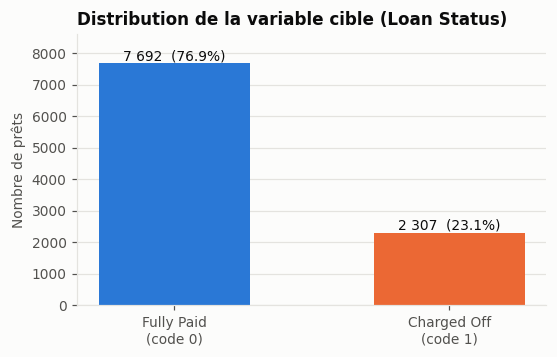

In [24]:
target = dq.target_summary(y, typed[TARGET_RAW])
save_table(target, "01_distribution_cible")
display(target)
default_rate = y.mean()
print(f"Taux de défaut global : {default_rate:.2%}  ({y.sum()} défauts / {len(y)} prêts)")
print(f"Rapport non-défauts / défauts : {(1 - default_rate) / default_rate:.2f}")
fig = plots.plot_target_distribution(target)
plots.save(fig, FIGURES_DIR / "01_distribution_cible.png");

**Interprétation.** Le taux de défaut brut est de **23,07 %** (2 307 défauts sur 9 999 lignes),
soit environ 3,3 non-défauts pour 1 défaut. Il sera recalculé après dédoublonnage (section 5.6).

- **Le portefeuille n'est pas équilibré**, mais le déséquilibre reste modéré : la classe minoritaire
  représente près d'un quart des observations, et 2 307 défauts suffisent pour estimer une régression logistique.
- **Conséquences pour la suite :**
  - stratifier le découpage apprentissage/test sur la cible, comme le demande le sujet ;
  - évaluer les modèles avec des indicateurs insensibles au déséquilibre (AUC, Accuracy Ratio)
    plutôt qu'avec le taux de bonne classification. Un modèle naïf prédisant toujours « non-défaut »
    obtiendrait déjà 76,9 % de bonnes classifications.
- **Point d'attention :** un taux de 23 % est très supérieur à celui d'un portefeuille bancaire de détail
  typique. L'échantillon est probablement sur-représenté en défauts, ce qui est fréquent dans les jeux
  de données de modélisation. Les PD estimées refléteront ce niveau moyen et ne doivent pas être
  interprétées comme des PD calibrées sur un portefeuille réel.

### 1.2 Tableau récapitulatif de la base

In [25]:
overview = dq.dataset_overview(typed, y)
save_table(overview, "01_synthese_base")
overview

,indicateur,valeur
0,Nombre d'observations,9999
1,Nombre de colonnes,19
2,Identifiants,2
3,Variable cible,1
4,Variables explicatives,16
5,dont quantitatives continues,8
6,dont quantitatives discrètes,4
7,dont qualitatives,4
8,Nombre de défauts,2307
9,Taux de défaut global,0.2307


**Lecture.**

- 6,0 % des cellules explicatives sont manquantes. Elles sont concentrées sur trois variables (section 4).
- La base contient **99 lignes strictement identiques** à une autre ligne et seulement **9 827 identifiants
  de prêt distincts** pour 9 999 lignes. Ce problème de doublons est traité en section 5.

### 1.3 Taux de défaut par modalité des variables qualitatives (descriptif)

Ce premier regard sur la relation entre chaque variable qualitative et la cible est purement descriptif.
La mesure formelle du pouvoir discriminant (Khi², T de Tschuprow, IV, V de Cramér) relève des étapes suivantes.
Les libellés sont présentés **après harmonisation** (section 5.5), pour ne pas répartir artificiellement
une même modalité sur deux lignes.

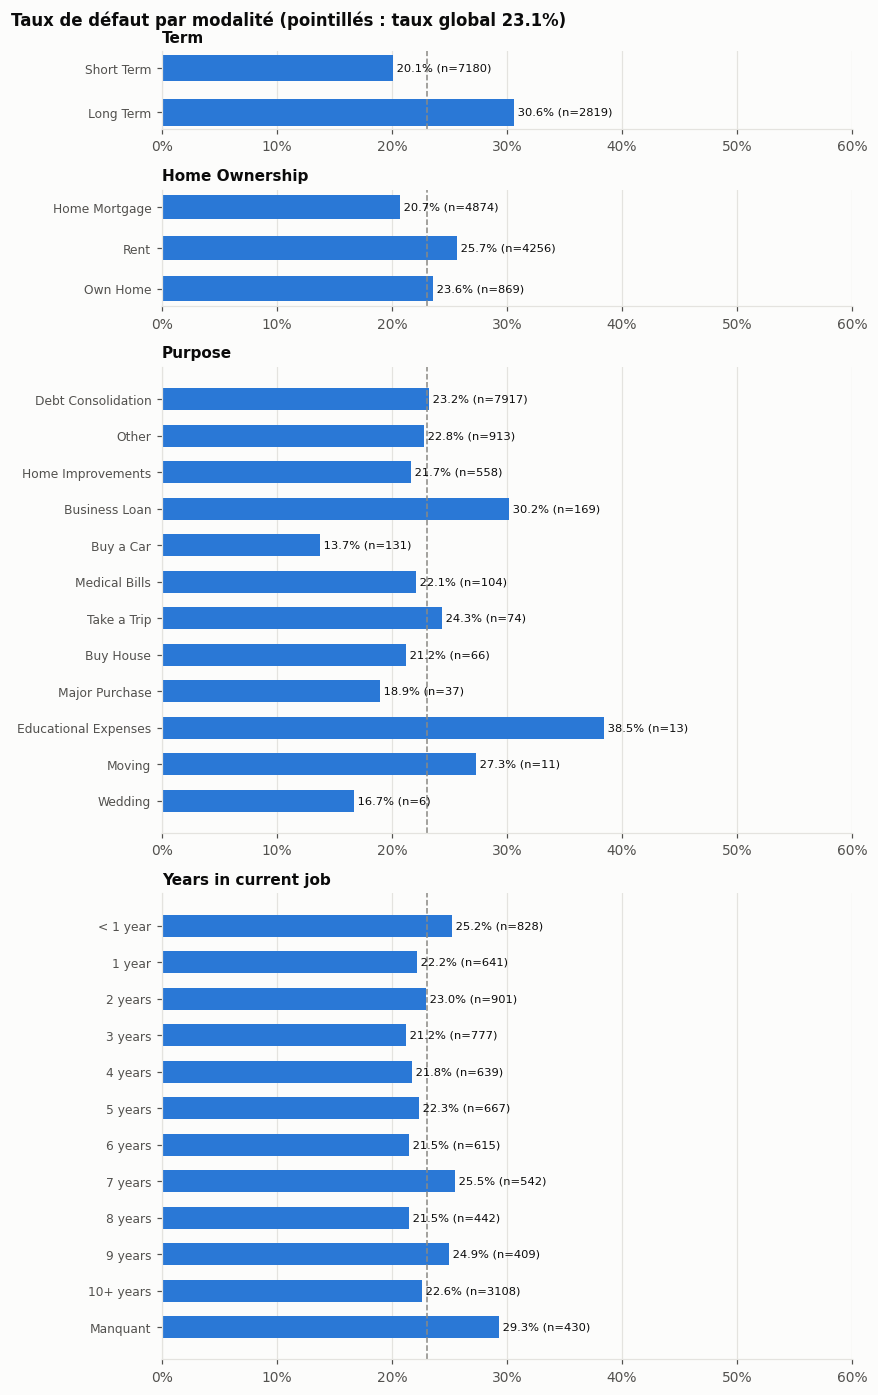

In [26]:
harmonized = dq.harmonize_labels(typed, LABEL_HARMONIZATION)
category_tables = {col: dq.category_default_rates(harmonized, y, col) for col in CATEGORICAL_COLUMNS}
years_order = YEARS_IN_JOB_ORDER + [dq.MISSING_LABEL]
category_tables["Years in current job"] = (
    category_tables["Years in current job"].set_index("modalité").loc[years_order].reset_index()
)
for col, table in category_tables.items():
    save_table(table, f"01_taux_defaut_{col.lower().replace(' ', '_')}")
fig = plots.plot_category_default_rates(category_tables, y.mean())
plots.save(fig, FIGURES_DIR / "01_taux_defaut_qualitatives.png");

**Lecture** (taux calculés sur les 9 999 lignes brutes, libellés harmonisés).

- **Term.** C'est l'écart le plus net : **30,6 %** de défaut pour les prêts longs contre **20,1 %**
  pour les prêts courts. Un prêt long expose plus longtemps l'emprunteur à un choc de revenu.
- **Home Ownership.** Les locataires (*Rent*) font plus défaut que les emprunteurs titulaires d'un
  crédit immobilier (*Home Mortgage*), ce qui est cohérent avec une stabilité patrimoniale moindre.
- **Purpose.** *Debt Consolidation* représente près de 80 % des prêts. Les autres motifs ont des
  effectifs faibles, parfois moins de 20 prêts : leurs taux de défaut sont donc peu fiables et
  devront être regroupés (question 1.2.4).
- **Years in current job.** On n'observe pas de gradient monotone avec l'ancienneté. La modalité
  **manquante** (`n/a`) présente en revanche le taux de défaut le plus élevé (29,3 %), point repris en section 4.

## 2. Variables identifiantes (Q2)

Un identifiant technique (numéro de prêt, de client, de dossier) est attribué arbitrairement. Il ne
décrit pas l'emprunteur, ne peut pas avoir de lien causal avec le défaut, et prend autant de valeurs
qu'il y a d'observations. L'intégrer au modèle reviendrait à **apprendre l'échantillon par cœur**
(sur-apprentissage), sans aucune capacité de généralisation à un nouveau client.

In [27]:
ids = dq.identifier_report(raw)
ids_card = dq.identifier_cardinality(raw)
save_table(ids, "02_identifiants")
display(ids, ids_card)

,variable,n_observations,n_distinct,part_distinct,lignes_en_double
0,Loan ID,9999,9827,0.9828,172
1,Customer ID,9999,9827,0.9828,172


,relation,valeur
0,clients distincts par prêt (max),1
1,prêts distincts par client (max),1


**Interprétation.**

- *Loan ID* et *Customer ID* prennent 9 827 valeurs distinctes pour 9 999 lignes, soit 98,3 % de
  valeurs uniques. Les 172 répétitions correspondent aux doublons étudiés en section 5.1.
- La relation entre les deux identifiants est **strictement 1-1** : un prêt appartient à un seul client
  et chaque client n'a qu'un seul prêt. *Customer ID* n'apporte donc aucune information de plus que *Loan ID*.

**Décision : les deux identifiants sont exclus des facteurs de risque.**

- *Loan ID* est conservé comme **clé technique** (index) pour le dédoublonnage et la traçabilité des observations.
- *Customer ID* est supprimé.

## 3. Variables à faible variabilité (Q2)

Une variable dont une modalité concentre presque toutes les observations ne peut pas discriminer.

**Règle du sujet :** exclure la variable si sa modalité dominante dépasse **95 %**, sauf justification
métier ou statistique.

- **Justification statistique testée :** on compare le taux de défaut de la modalité dominante à celui
  des autres observations, par un test du Khi² d'indépendance 2 × 2.
- La valeur manquante est comptée comme une modalité à part entière.

,variable,n_modalités,modalité_dominante,part_dominante,dépasse_95%,taux_defaut_dominante,taux_defaut_autres,p_value_khi2
0,Tax Liens,8,0.0,0.9789,True,0.2310,0.2180,0.7185
1,Bankruptcies,7,0.0,0.8851,False,0.2331,0.2124,0.1252
2,Number of Credit Problems,8,0.0,0.8564,False,0.2329,0.2180,0.2278
3,Purpose,15,Debt Consolidation,0.7918,False,0.2322,0.2253,0.5253
4,Term,2,Short Term,0.7181,False,0.2010,0.3065,0.0000
5,Months since last delinquent,92,Manquant,0.5299,False,0.2354,0.2255,0.2511
6,Home Ownership,4,Home Mortgage,0.4857,False,0.2073,0.2528,0.0000
7,Years in current job,12,10+ years,0.3108,False,0.2262,0.2328,0.4859
8,Credit Score,282,Manquant,0.1937,False,0.2824,0.2183,0.0000
9,Annual Income,7130,Manquant,0.1937,False,0.2824,0.2183,0.0000


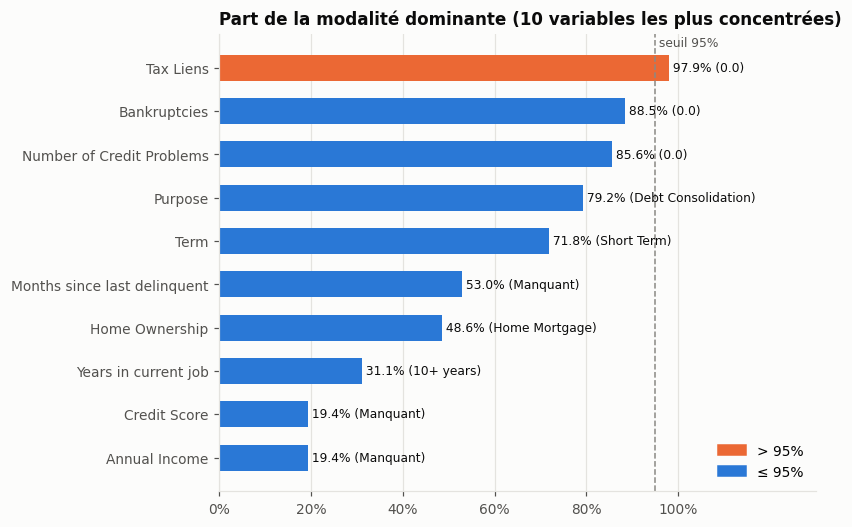

In [28]:
dominant = dq.dominant_modality_table(typed, y, FEATURE_COLUMNS)
save_table(dominant, "03_modalite_dominante")
display(dominant)
fig = plots.plot_dominant_modality(dominant, DOMINANT_MODALITY_THRESHOLD)
plots.save(fig, FIGURES_DIR / "03_modalite_dominante.png");

**Interprétation.**

- **Tax Liens** (privilèges fiscaux) est la seule variable au-dessus du seuil : **97,9 %** des prêts
  ont la valeur 0. Les 211 autres observations (210 prêts avec au moins un privilège et 1 valeur
  manquante) n'ont pas un taux de défaut plus élevé (21,8 % contre 23,1 %), et le test du Khi² ne rejette pas l'indépendance (p = 0,72).
  Ni le sens métier attendu (plus de privilèges, plus de risque) ni la statistique ne justifient de la garder.
  **Décision : exclusion.**
- **Bankruptcies (88,5 %)** et **Number of Credit Problems (85,6 %)** restent sous le seuil et sont
  conservées. Leurs écarts de taux de défaut entre la modalité 0 et les autres ne sont pas significatifs
  à 5 % (p = 0,13 et 0,23). Leur pouvoir discriminant sera mesuré plus finement (IV, V de Cramér) avant sélection.
- **Aucune variable n'est constante.**
- Pour les variables quantitatives continues, la « modalité dominante » est sans objet : moins de 2 %
  des observations partagent la même valeur. Deux exceptions confirment les anomalies déjà repérées :
  - *Current Loan Amount* a pour valeur la plus fréquente 99 999 999 (11,4 %), avec 0 % de défaut ;
  - *Credit Score* et *Annual Income* ont pour « modalité » la plus fréquente le manquant (19,4 %).

## 4. Valeurs manquantes (Q3)

### 4.1 Recensement et nature

Pour chaque variable, on donne :

- le nombre de cellules par codage (vide, `NA`, `n/a`) ;
- le taux global de manquant ;
- la **nature** du manquant :
  - **non applicable** : la grandeur n'existe pas pour l'emprunteur ;
  - **manquant réel** : la grandeur existe mais n'a pas été collectée ;
  - **ambigu** : les deux interprétations sont possibles ;
- le taux de défaut quand la valeur est manquante ou renseignée, avec la p-value du Khi² entre
  l'indicateur de manquant et la cible.

In [29]:
missing = dq.missing_value_table(raw, typed, y, FEATURE_COLUMNS)
save_table(missing, "04_valeurs_manquantes")
missing[missing["n_manquants"] > 0]

,variable,n_vide,n_NA,n_n/a,n_manquants,taux_manquant,dépasse_10%,nature,justification,taux_defaut_si_manquant,taux_defaut_si_renseigné,p_value_khi2
0,Months since last delinquent,0,5298,0,5298,0.5299,True,Non applicable,Aucun retard de paiement enregistré : la durée depuis le dernier retard n'existe pas.,0.2354,0.2255,0.2511
1,Credit Score,1937,0,0,1937,0.1937,True,Manquant réel,La grandeur existe pour tout emprunteur mais n'a pas été collectée.,0.2824,0.2183,0.0000
2,Annual Income,1937,0,0,1937,0.1937,True,Manquant réel,La grandeur existe pour tout emprunteur mais n'a pas été collectée.,0.2824,0.2183,0.0000
3,Years in current job,0,0,430,430,0.0430,False,Ambigu,"Jeton 'n/a' : sans emploi salarié (indépendant, retraité…) ou non renseigné.",0.2930,0.2279,0.0021
4,Bankruptcies,0,17,0,17,0.0017,False,Manquant réel,La grandeur existe pour tout emprunteur mais n'a pas été collectée.,0.3529,0.2305,0.3633
5,Tax Liens,0,1,0,1,0.0001,False,Manquant réel,La grandeur existe pour tout emprunteur mais n'a pas été collectée.,0.0000,0.2307,1.0000


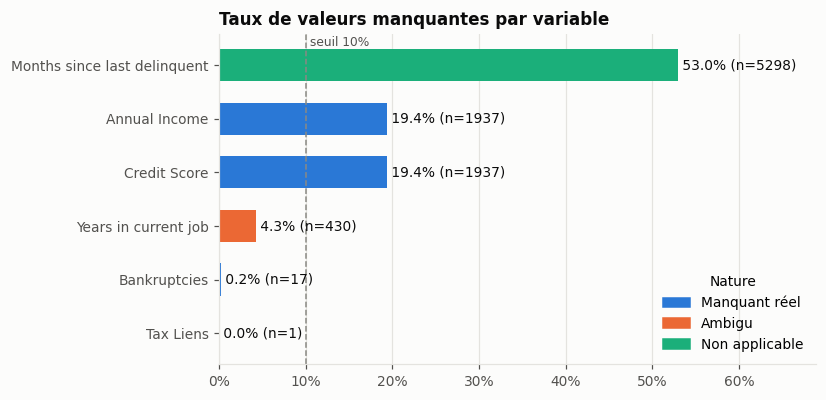

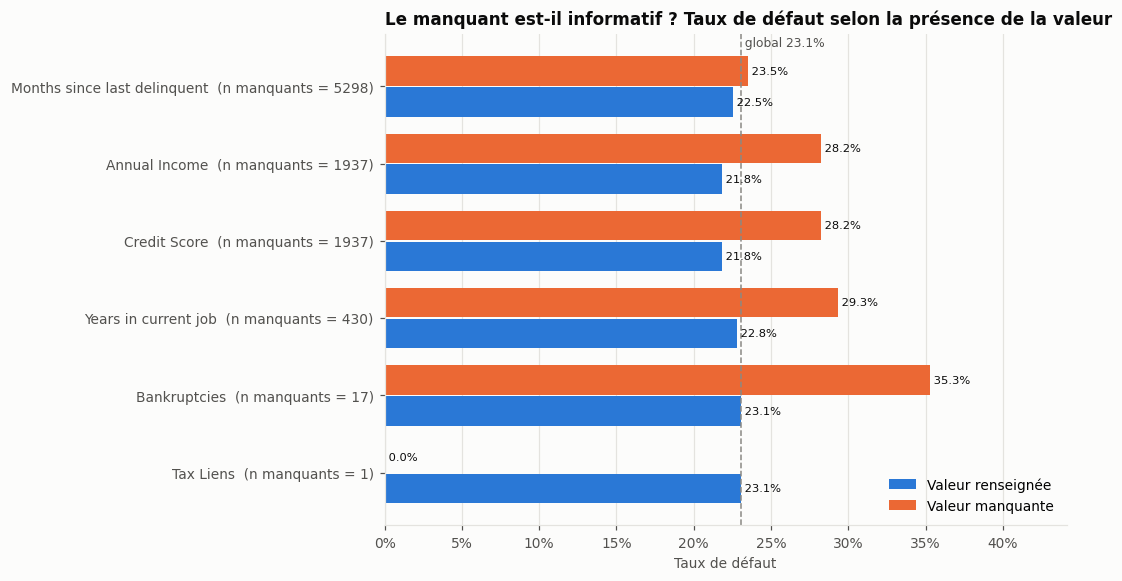

In [30]:
fig = plots.plot_missing_rates(missing, HIGH_MISSING_THRESHOLD)
plots.save(fig, FIGURES_DIR / "04_taux_manquants.png")
fig = plots.plot_missing_default_rates(missing, y.mean())
plots.save(fig, FIGURES_DIR / "04_taux_defaut_selon_manquant.png");

**Interprétation par variable.** Six variables sur seize ont au moins une valeur manquante. Trois
dépassent le seuil de 10 % : *Months since last delinquent*, *Credit Score* et *Annual Income*.

| Variable | Codage | Taux | Nature | Lecture |
|---|---|---|---|---|
| Months since last delinquent | `NA` | 53,0 % | **Non applicable** | Le `NA` signifie qu'aucun retard de paiement n'est enregistré. La durée depuis le dernier retard n'existe pas : ce n'est pas une donnée perdue. |
| Credit Score | vide | 19,4 % | **Manquant réel** | Tout emprunteur a un score, mais il n'a pas été transmis. |
| Annual Income | vide | 19,4 % | **Manquant réel** | Toujours manquant **sur les mêmes lignes** que le Credit Score (voir 4.2) : défaut de collecte commun aux deux champs. |
| Years in current job | `n/a` | 4,3 % | **Ambigu** | Peut signifier « sans emploi salarié » (indépendant, retraité…) ou « non renseigné ». |
| Bankruptcies | `NA` | 0,2 % | Manquant réel | 17 cas. |
| Tax Liens | `NA` | < 0,1 % | Manquant réel | 1 cas ; variable exclue de toute façon (section 3). |

**Le manquant est-il informatif ?**

- **Credit Score / Annual Income.** Quand ils manquent, le taux de défaut vaut 28,2 % contre 21,8 %
  quand ils sont renseignés (p < 0,001). L'absence d'information est **un signal de risque** : dossiers
  incomplets, emprunteurs sans historique vérifiable.
- **Years in current job.** Taux de défaut de 29,3 % si `n/a`, contre 22,8 % (p = 0,002) : même constat.
- **Months since last delinquent.** 23,5 % si `NA` contre 22,5 % (p = 0,25), différence non significative.
  Le fait de n'avoir jamais eu de retard ne réduit pas ici le risque de défaut, mais la modalité garde
  un sens métier clair.
- **Bankruptcies.** 35,3 % sur seulement 17 prêts (p = 0,36) : effectif trop faible pour conclure.

### 4.2 Co-occurrence des manquants

Ce tableau compte, pour chaque paire de variables, le nombre d'observations où les deux sont
manquantes simultanément. La diagonale donne le nombre de manquants de chaque variable.

In [31]:
missing_cols = missing.loc[missing["n_manquants"] > 0, "variable"].tolist()
co_missing = dq.missing_co_occurrence(typed, missing_cols)
save_table(co_missing, "04_cooccurrence_manquants", index=True)
co_missing

,Months since last delinquent,Credit Score,Annual Income,Years in current job,Bankruptcies,Tax Liens
Months since last delinquent,5298,1039,1039,216,0,0
Credit Score,1039,1937,1937,89,3,0
Annual Income,1039,1937,1937,89,3,0
Years in current job,216,89,89,430,0,0
Bankruptcies,0,3,3,0,17,1
Tax Liens,0,0,0,0,1,1


**Lecture.**

- *Credit Score* et *Annual Income* sont manquants **exactement sur les mêmes 1 937 lignes** : leur
  co-occurrence est égale à leur effectif. Il s'agit d'un même défaut de collecte, qui sera traité de
  la même manière pour les deux variables.
- Les autres manquants se recouvrent partiellement, sans structure particulière.

### 4.3 Variables à plus de 10 % de manquants : conservation ou exclusion ?

| Variable | Taux | Décision | Justification |
|---|---|---|---|
| Months since last delinquent | 53,0 % | **Conservée** | Le manquant est un « non applicable » porteur de sens (jamais en retard). Il devient une modalité à part entière. Exclure la variable ferait perdre l'information sur la récence des retards des 47 % d'emprunteurs concernés. |
| Credit Score | 19,4 % | **Conservée** | Variable centrale du risque de crédit. Le manquant est lui-même discriminant. |
| Annual Income | 19,4 % | **Conservée** | Nécessaire au calcul du DTI et de l'IES. Même mécanisme de manquant que le Credit Score. |

### 4.4 Stratégie de traitement proposée

Ces traitements ne sont **pas appliqués** dans ce notebook. Ils dépendent de la discrétisation ou de
statistiques (mode, médiane) qui doivent être apprises sur l'échantillon d'apprentissage seulement.

| Variable | Stratégie | Raison |
|---|---|---|
| Months since last delinquent | Modalité spécifique **« Aucun retard »** dans la discrétisation | Non applicable : imputer une durée inventerait un retard qui n'a pas eu lieu. |
| Credit Score, Annual Income | Classe **« Manquant »** dans la discrétisation | Le manquant est informatif : une imputation par la médiane le noierait dans la classe centrale et ferait perdre ce signal. Supprimer les lignes retirerait 19 % de la base et biaiserait l'échantillon vers les dossiers complets, moins risqués. |
| Years in current job | Modalité **« Non renseigné »**, fusionnée à la discrétisation si elle représente moins de 5 % des prêts | Manquant informatif et ambigu ; variable déjà qualitative. |
| Bankruptcies | Imputation par le **mode** (0), calculé sur l'apprentissage | 17 cas : impact négligeable, la modalité 0 est très majoritaire. |
| Tax Liens | Sans objet | Variable exclue. |

### 4.5 Dans quels cas une valeur manquante contient-elle une information sur le risque ?

Une valeur manquante est informative lorsque **le fait qu'elle manque n'est pas dû au hasard mais est
lié au profil de l'emprunteur**, c'est-à-dire lorsque le mécanisme de manquant n'est pas « complètement aléatoire » (MCAR). On retrouve trois cas typiques.

1. **Non applicable.** L'absence décrit une situation : pas de retard (*Months since last delinquent*),
   pas d'emploi salarié (*Years in current job*).
2. **Information non fournie par l'emprunteur.** Un emprunteur fragile peut être moins enclin à
   déclarer ses revenus ou à fournir des justificatifs. C'est cohérent avec le taux de défaut plus
   élevé observé ici quand *Annual Income* / *Credit Score* manquent.
3. **Processus d'octroi différent.** Certains canaux de distribution ou certaines générations de
   dossiers ne collectent pas la donnée et ont un risque propre.

Dans ces cas, il faut **conserver l'information de manque** (modalité dédiée) plutôt que l'imputer.
La section 5.6 montre un cas où le manque, au contraire, est un **artefact** révélant la cible
et ne doit surtout pas être conservé comme modalité.

## 5. Contrôles de cohérence (Q4)

### 5.1 Doublons

In [32]:
duplicates = dq.duplicate_summary(raw)
near_dups = dq.near_duplicate_differences(raw)
save_table(duplicates, "05_doublons")
save_table(near_dups, "05_doublons_loan_id_differences")
display(duplicates)
print("Colonnes qui diffèrent entre les deux lignes d'un même Loan ID :")
display(near_dups["colonnes_différentes"].value_counts().rename("nombre de Loan ID").to_frame())
print("Statut des lignes dont le Loan ID est répété :")
display(raw.loc[raw[LOAN_ID].duplicated(keep=False), TARGET_RAW].value_counts().to_frame())
near_dups.head(4)

,contrôle,valeur
0,Lignes entièrement dupliquées (à supprimer),99
1,Lignes après suppression des doublons exacts,9900
2,Loan ID partagés par des lignes différentes,73
3,dont statut de défaut contradictoire,0
4,Prêts uniques (Loan ID distincts),9827


Colonnes qui diffèrent entre les deux lignes d'un même Loan ID :


,nombre de Loan ID
colonnes_différentes,
"Credit Score, Annual Income",39
Current Loan Amount,34


Statut des lignes dont le Loan ID est répété :


,count
Loan Status,
Fully Paid,344


,Loan ID,colonnes_différentes,valeurs
0,025ce9ad-0cee-42e2-9567-c0aca27c5823,Current Loan Amount,{Current Loan Amount=308022} / {Current Loan Amount=99999999}
1,05010552-0172-4319-807d-a320517a1a82,"Credit Score, Annual Income","{Credit Score=vide, Annual Income=vide} / {Credit Score=716, Annual Income=1126776}"
2,09997824-a068-4fb6-85dd-3ee8d6c0b532,"Credit Score, Annual Income","{Credit Score=vide, Annual Income=vide} / {Credit Score=717, Annual Income=1765290}"
3,0dd687d7-62c4-4105-8f93-7e3b24217826,"Credit Score, Annual Income","{Credit Score=679, Annual Income=1116288} / {Credit Score=vide, Annual Income=vide}"


**Interprétation.**

- **99 lignes sont des copies exactes** d'une autre ligne. Elles sont supprimées : un prêt compté
  deux fois pèserait double dans l'estimation et pourrait se retrouver à la fois dans l'apprentissage
  et dans le test, ce qui gonflerait artificiellement les performances.
- **73 Loan ID** apparaissent sur deux lignes qui diffèrent, toujours d'une seule des deux manières suivantes :
  - **34 cas** : l'une des deux lignes porte le montant sentinelle 99 999 999, l'autre un montant réel ;
  - **39 cas** : l'une des deux lignes n'a ni *Credit Score* ni *Annual Income*, l'autre les a.
- Le statut de défaut n'est **jamais contradictoire** entre les deux lignes.
- Les 344 lignes dont le Loan ID est répété (172 prêts × 2) sont **toutes des prêts remboursés**
  (*Fully Paid*). La duplication est donc elle-même liée à la cible : sans dédoublonnage, les
  non-défauts seraient sur-représentés et une partie d'entre eux serait vue deux fois par le modèle.

Ces paires sont donc des enregistrements d'un même prêt, l'un plus complet que l'autre.
**Règle retenue :** garder la ligne la plus complète, après conversion de la sentinelle en manquant.
On obtient **9 827 prêts uniques**.

### 5.2 Contrôles de plages et de cohérence entre variables

Chaque règle signale les lignes en anomalie. Le taux de défaut de ces lignes permet de repérer
les anomalies **liées à la cible**, qui sont les plus dangereuses pour la modélisation.

,contrôle,variables,n_anomalies,part,taux_defaut_anomalies,taux_defaut_autres
0,Montant du prêt = 99 999 999 (valeur sentinelle),Current Loan Amount,1136,0.1136,0.0000,0.2603
1,Credit Score > 850 (hors échelle),Credit Score,492,0.0492,1.0000,0.1909
2,Credit Score < 300 (hors échelle),Credit Score,0,0.0000,NaN,0.2307
3,Revenu annuel ≤ 0,Annual Income,0,0.0000,NaN,0.2307
4,Dette mensuelle < 0,Monthly Debt,0,0.0000,NaN,0.2307
5,Dette mensuelle = 0,Monthly Debt,9,0.0009,0.1111,0.2308
6,Dette annuelle > revenu annuel,"Monthly Debt, Annual Income",0,0.0000,NaN,0.2307
7,Ancienneté de crédit ≤ 0,Years of Credit History,0,0.0000,NaN,0.2307
8,Ancienneté emploi > ancienneté de crédit,"Years in current job, Years of Credit History",74,0.0074,0.2432,0.2306
9,Dernier retard antérieur à l'historique de crédit,"Months since last delinquent, Years of Credit History",0,0.0000,NaN,0.2307


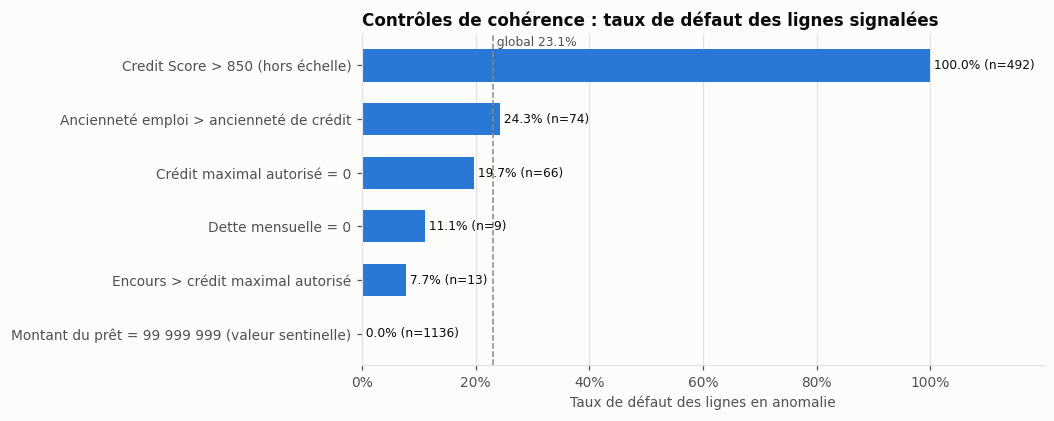

In [33]:
checks = dq.consistency_checks(typed, y)
save_table(checks, "05_controles_coherence")
display(checks)
fig = plots.plot_check_default_rates(checks, y.mean())
plots.save(fig, FIGURES_DIR / "05_controles_taux_defaut.png");

**Interprétation.** Seize contrôles ont été appliqués ; dix ne signalent **aucune** anomalie :

- pas de revenu nul ou négatif, pas de dette négative ;
- pas de dette annuelle supérieure au revenu ;
- pas de Credit Score sous 300 ;
- pas d'ancienneté de crédit nulle, pas de dernier retard antérieur à l'ouverture de l'historique de crédit ;
- pas d'emprunteur sans compte ouvert ;
- faillites et privilèges fiscaux toujours inférieurs ou égaux au nombre d'incidents de crédit ;
- *Credit Score* et *Annual Income* jamais manquants séparément.

Les six contrôles en anomalie se répartissent en deux groupes.

**Anomalies critiques : elles révèlent directement la cible (fuite d'information)**

| Anomalie | n | Taux de défaut | Diagnostic |
|---|---|---|---|
| Montant = 99 999 999 | 1 136 | **0 %** | Valeur sentinelle (code « montant inconnu ») portée **exclusivement** par des prêts remboursés. |
| Credit Score > 850 | 492 | **100 %** | Erreur d'échelle (×10) portée **exclusivement** par des prêts en défaut. |

Ces deux anomalies sont des **artefacts de constitution de la base**, pas des caractéristiques des
emprunteurs : au moment de l'octroi, rien ne permet de savoir si le prêt finira remboursé.
Laissées en l'état, elles produiraient un modèle quasi parfait en apparence (IV, AUC très élevés)
mais **inutilisable en production**.

**Anomalies mineures : plausibles ou de faible effectif**

| Anomalie | n | Lecture |
|---|---|---|
| Ancienneté emploi > ancienneté de crédit | 74 | Plausible : on peut occuper un emploi plusieurs années avant d'ouvrir un premier crédit. Conservé tel quel ; à surveiller pour le ratio ESR, qui dépassera alors 1. |
| Crédit maximal autorisé = 0 | 66 | Plausible (lignes de crédit fermées), mais rend **CUR et ACR non définis** (division par zéro), à gérer explicitement au feature engineering. |
| Encours > crédit maximal autorisé | 13 | Dépassement de limite ou plafond réduit après tirage : plausible, CUR > 1. Faible effectif. |
| Dette mensuelle = 0 | 9 | Plausible (aucune dette en cours). |

### 5.3 Correction de l'échelle du Credit Score

Hypothèse : les valeurs supérieures à 850 sont des scores multipliés par 10. On la vérifie de deux façons :

1. toutes ces valeurs doivent être des multiples de 10 ;
2. une fois divisées par 10, elles doivent retomber dans la plage des scores normaux.

Valeurs > 850 : 492 ; toutes multiples de 10 : True


,Scores > 850 après division par 10,Scores ≤ 850 (inchangés)
count,492.0000,"7,570.0000"
mean,708.8679,716.7604
std,32.4730,27.9735
min,586.0000,589.0000
25%,694.0000,704.0000
50%,718.0000,723.0000
75%,734.0000,739.0000
max,751.0000,751.0000


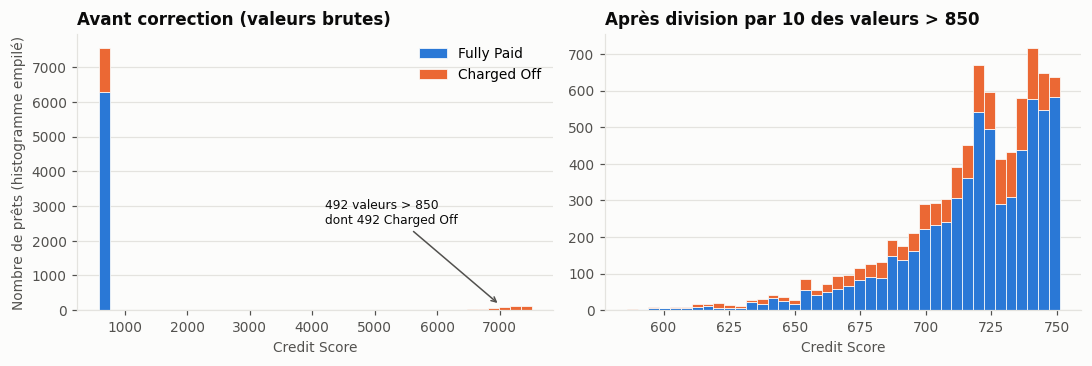

In [34]:
cs = typed["Credit Score"]
too_high = cs > 850
corrected = dq.rescale_credit_score(typed)["Credit Score"]
print(f"Valeurs > 850 : {too_high.sum()} ; toutes multiples de 10 : {bool((cs[too_high] % 10 == 0).all())}")
cs_check = pd.DataFrame({
    "Scores > 850 après division par 10": corrected[too_high].describe(),
    "Scores ≤ 850 (inchangés)": cs[cs <= 850].describe(),
})
save_table(cs_check, "05_credit_score_correction", index=True)
display(cs_check)
fig = plots.plot_credit_score_correction(cs, corrected, y)
plots.save(fig, FIGURES_DIR / "05_credit_score_correction.png");

**Interprétation.**

- Les 492 valeurs hors échelle sont toutes des multiples de 10.
- Une fois divisées par 10, elles couvrent **586 à 751**, ce qui coïncide avec la plage des scores
  normaux (**589 à 751**). Leur médiane (718) est proche de celle des autres scores (723).
- L'hypothèse d'une erreur d'échelle est donc confirmée. **Correction appliquée : division par 10.**

Après correction, ces emprunteurs ont des scores ordinaires : la valeur du score ne permet plus de
deviner leur statut, ce qui supprime la fuite. Le graphique de droite montre une seule distribution
continue, alors que celui de gauche isolait un second groupe entièrement en défaut.

### 5.4 Montant sentinelle 99 999 999

Le montant maximal hors sentinelle est 789 096 : 99 999 999 n'est pas un montant plausible, c'est un
code « valeur inconnue ». **Traitement appliqué : remplacement par une valeur manquante.**

**Contrainte pour la suite.** Ces manquants sont portés uniquement par des prêts remboursés (vérifié
en 5.6). Une modalité « Manquant » pour *Current Loan Amount* reproduirait donc la fuite. À l'étape
d'imputation, apprise sur l'apprentissage, il faudra :

- soit imputer **sans** indicateur de manquant ;
- soit exclure la variable si son pouvoir discriminant sur les montants réels est faible.

**Décision prise en partie 4** : les montants manquants sont remplacés par des montants tirés au hasard
dans la distribution de l'apprentissage (hot-deck). Ils se répartissent ainsi dans toutes les classes sans
créer de signal artificiel.

### 5.5 Libellés incohérents des variables qualitatives

In [35]:
variants = dq.label_variants(typed)
display(variants)
harmonization = pd.DataFrame(
    [(col, old, new) for col, mapping in LABEL_HARMONIZATION.items() for old, new in mapping.items()],
    columns=["variable", "libellé source", "libellé harmonisé"],
)
harmonization["effectif"] = [int((typed[c] == old).sum()) for c, old in harmonization[["variable", "libellé source"]].itertuples(index=False)]
save_table(harmonization, "05_harmonisation_libelles")
harmonization

,variable,modalités
0,Purpose,Other | other


,variable,libellé source,libellé harmonisé,effectif
0,Purpose,other,Other,586
1,Purpose,small_business,Business Loan,26
2,Purpose,vacation,Take a Trip,18
3,Purpose,major_purchase,Major Purchase,37
4,Purpose,moving,Moving,11
5,Purpose,wedding,Wedding,6
6,Home Ownership,HaveMortgage,Home Mortgage,17


**Interprétation.**

- La détection automatique (insensible à la casse et aux séparateurs) trouve `other` / `Other` dans *Purpose*.
- L'examen des libellés révèle en plus des **doublons sémantiques** issus de conventions de saisie
  différentes (`snake_case` contre mots capitalisés) :
  - `small_business` ≈ `Business Loan` ;
  - `vacation` ≈ `Take a Trip` ;
  - `HaveMortgage` ≈ `Home Mortgage` (17 prêts).

Seules des **équivalences strictes de sens** sont fusionnées ici. *Purpose* passe ainsi de 15 à 12 modalités
et *Home Ownership* de 4 à 3. Le regroupement des modalités **selon leur niveau de risque** relève de
la transformation des variables (question 1.2.4) et n'est pas fait à ce stade.

### 5.6 Application des traitements déterministes

Les traitements sont appliqués dans cet ordre :

1. montant sentinelle → manquant ;
2. correction du Credit Score ;
3. harmonisation des libellés ;
4. dédoublonnage (doublons exacts supprimés, puis ligne la plus complète gardée par Loan ID).

Le dédoublonnage vient en dernier pour pouvoir compter les sentinelles comme des manquants lors du
choix de la ligne la plus complète.

In [36]:
clean, treatment_log = dq.apply_treatments(typed, LABEL_HARMONIZATION)
y_clean = encode_target(clean[TARGET_RAW])
save_table(treatment_log, "05_journal_traitements")
display(treatment_log)
print(f"Base après traitements : {len(clean)} prêts, {clean[LOAN_ID].is_unique=}")
print(f"Taux de défaut : {y.mean():.2%} (brut)  →  {y_clean.mean():.2%} (après traitements)")
removed = typed.index.difference(clean.index)
print(f"Lignes supprimées : {len(removed)}, dont défauts : {y[removed].sum()} ; défauts conservés : {y_clean.sum()}")

,étape,lignes_avant,lignes_après,cellules_modifiées
0,Montant sentinelle 99 999 999 → NaN,9999,9999,"1,136.0000"
1,Credit Score > 850 divisé par 10,9999,9999,492.0000
2,Harmonisation des libellés,9999,9999,701.0000
3,"Doublons exacts supprimés, ligne la plus complète gardée par Loan ID",9999,9827,NaN


Base après traitements : 9827 prêts, clean[LOAN_ID].is_unique=True
Taux de défaut : 23.07% (brut)  →  23.48% (après traitements)
Lignes supprimées : 172, dont défauts : 0 ; défauts conservés : 2307


In [37]:
checks_after = dq.consistency_checks(clean, y_clean)
save_table(checks_after, "05_controles_coherence_apres_traitement")
display(checks_after[checks_after["n_anomalies"] > 0])
missing_after = dq.missing_profile(clean, y_clean, FEATURE_COLUMNS)
save_table(missing_after, "05_valeurs_manquantes_apres_traitement", index=True)
missing_after[missing_after["n_manquants"] > 0]

,contrôle,variables,n_anomalies,part,taux_defaut_anomalies,taux_defaut_autres
5,Dette mensuelle = 0,Monthly Debt,9,0.0009,0.1111,0.2349
8,Ancienneté emploi > ancienneté de crédit,"Years in current job, Years of Credit History",72,0.0073,0.2500,0.2346
11,Crédit maximal autorisé = 0,Maximum Open Credit,65,0.0066,0.2000,0.2350
12,Encours > crédit maximal autorisé,"Current Credit Balance, Maximum Open Credit",12,0.0012,0.0833,0.2349


,n_manquants,taux_manquant,dépasse_10%,nature,justification,taux_defaut_si_manquant,taux_defaut_si_renseigné,p_value_khi2
variable,,,,,,,,
Current Loan Amount,1102,0.1121,True,Manquant réel,La grandeur existe pour tout emprunteur mais n'a pas été collectée.,0.0000,0.2644,0.0000
Credit Score,1898,0.1931,True,Manquant réel,La grandeur existe pour tout emprunteur mais n'a pas été collectée.,0.2882,0.2220,0.0000
Annual Income,1898,0.1931,True,Manquant réel,La grandeur existe pour tout emprunteur mais n'a pas été collectée.,0.2882,0.2220,0.0000
Months since last delinquent,5217,0.5309,True,Non applicable,Aucun retard de paiement enregistré : la durée depuis le dernier retard n'existe pas.,0.2390,0.2299,0.2996
Bankruptcies,17,0.0017,False,Manquant réel,La grandeur existe pour tout emprunteur mais n'a pas été collectée.,0.3529,0.2346,0.3874
Tax Liens,1,0.0001,False,Manquant réel,La grandeur existe pour tout emprunteur mais n'a pas été collectée.,0.0000,0.2348,1.0000
Years in current job,423,0.0430,False,Ambigu,"Jeton 'n/a' : sans emploi salarié (indépendant, retraité…) ou non renseigné.",0.2979,0.2319,0.0021


**Interprétation.**

- **Taille de la base.** Elle passe de 9 999 lignes à **9 827 prêts uniques**. Le taux de défaut passe
  de 23,07 % à **23,48 %**. Les 172 lignes supprimées sont toutes des prêts remboursés : le nombre
  de défauts reste 2 307, seul le dénominateur diminue.
- **Contrôles après traitement.** Les deux anomalies critiques (sentinelle, Credit Score > 850) ont
  disparu. Il ne reste que les anomalies mineures jugées plausibles en 5.2.
- **Manquants après traitement.** *Current Loan Amount* compte désormais **1 102 manquants (11,2 %)**,
  tous issus de la sentinelle, avec un **taux de défaut de 0 %**. Cela confirme la contrainte énoncée
  en 5.4 : ce manquant ne doit **pas** devenir une modalité.
- Les manquants de *Credit Score* / *Annual Income* (1 898 lignes, 28,8 % de défaut contre 22,2 %)
  restent informatifs, comme avant dédoublonnage.

### 5.7 Tableau récapitulatif par variable

Le tableau croise les éléments suivants :

- les taux de manquant, avant et après traitement ;
- les contrôles en anomalie, avec leur effectif calculé sur les données brutes ;
- l'anomalie qualitative retenue ;
- le traitement ;
- la décision finale.

In [38]:
summary = dq.quality_summary_table(typed, clean, checks)
save_table(summary, "05_synthese_qualite_par_variable")
summary

,variable,nature,taux_manquant_brut,taux_manquant_après_traitement,contrôles_en_anomalie (n),anomalies,traitement,décision
0,Loan ID,Identifiant,0.0000,0.0000,—,Identifiant technique ; répété sur plusieurs lignes (doublons),Utilisé pour le dédoublonnage puis gardé comme index,Exclue des facteurs de risque
1,Customer ID,Identifiant,0.0000,0.0000,—,"Identifiant technique, en bijection avec Loan ID",Supprimée,Exclue des facteurs de risque
2,Loan Status,Qualitative binaire (cible),0.0000,0.0000,—,Aucune,"Codée 1 = Charged Off (défaut), 0 = Fully Paid",Cible
3,Current Loan Amount,Quantitative continue,0.0000,0.1121,Montant du prêt = 99 999 999 (valeur sentinelle) (1136),Valeur sentinelle 99 999 999 portée uniquement par des non-défauts (fuite),Sentinelle → NaN ; imputation par tirage dans la distribution de l'apprentissage (hot-...,Conservée sous condition
4,Term,Qualitative nominale,0.0000,0.0000,—,Aucune,Aucun,Conservée
5,Credit Score,Quantitative continue,0.1937,0.1931,Credit Score > 850 (hors échelle) (492),Valeurs ×10 (> 850) portées uniquement par des défauts ; manquants réels informatifs,Division par 10 ; classe « Manquant » à la discrétisation,Conservée
6,Annual Income,Quantitative continue,0.1937,0.1931,—,"Manquants réels, simultanés avec Credit Score, informatifs",Classe « Manquant » à la discrétisation,Conservée
7,Years in current job,Qualitative ordinale,0.0430,0.0430,Ancienneté emploi > ancienneté de crédit (74),Jeton 'n/a' ambigu ; ancienneté d'emploi parfois > historique de crédit,Modalité « Non renseigné » (fusionnée à la discrétisation si < 5 %),Conservée
8,Home Ownership,Qualitative nominale,0.0000,0.0000,—,Libellé 'HaveMortgage' redondant avec 'Home Mortgage',Fusion des deux libellés,Conservée
9,Purpose,Qualitative nominale,0.0000,0.0000,—,"Libellés en double (casse, synonymes) ; modalités rares",Harmonisation ; regroupement par niveau de risque en phase de transformation,Conservée


### 5.8 Une variable fortement prédictive mais de mauvaise qualité doit-elle être conservée ?

**Pas en l'état.** Un pouvoir prédictif élevé ne compense pas une mauvaise qualité, pour trois raisons :

1. **La performance peut être artificielle.** Ici, *Credit Score* brut et *Current Loan Amount* brut
   seraient parmi les variables les plus « prédictives » de la base, uniquement grâce à des artefacts
   (0 % et 100 % de défaut). Un IV très élevé (≥ 0,5) doit faire **soupçonner une fuite** plutôt que
   réjouir, comme le rappelle l'annexe du sujet.
2. **Le modèle doit fonctionner sur les futurs dossiers.** Si l'anomalie ne se reproduit pas en
   production, ou se reproduit différemment, les prédictions seront fausses et la performance s'effondrera.
3. **Exigences réglementaires.** Un modèle de notation interne doit être traçable, justifiable et
   stable dans le temps. Une variable de qualité douteuse fragilise sa validation.

**La bonne démarche consiste donc à :**

- **corriger** l'anomalie quand son origine est identifiée et la correction certaine (Credit Score ×10) ;
- **neutraliser** l'artefact quand il ne peut pas être corrigé (sentinelle → manquant, sans modalité dédiée) ;
- **réévaluer** ensuite le pouvoir prédictif sur les données corrigées ;
- **exclure** la variable si la qualité ne peut pas être restaurée ou si l'intérêt prédictif ne
  survit pas à la correction.

## 6. Export de la base après contrôle qualité

La base exportée contient :

- *Loan ID* comme clé technique, non utilisée comme variable ;
- les 15 variables explicatives conservées (toutes sauf *Tax Liens*) ;
- la cible codée `default` (1 = défaut).

*Customer ID* et *Loan Status* (remplacée par `default`) sont retirées. Les valeurs manquantes sont
laissées en `NaN` : leur traitement sera appris sur l'échantillon d'apprentissage.

In [39]:
excluded = [v for v, (_, _, decision) in dq.VARIABLE_DECISIONS.items() if decision.startswith("Exclue")]
kept_features = [c for c in FEATURE_COLUMNS if c not in excluded]
dq_dataset = clean[[LOAN_ID] + kept_features].assign(**{TARGET: y_clean.to_numpy()})
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
output_path = PROCESSED_DIR / "loans_after_data_quality.csv"
dq_dataset.to_csv(output_path, index=False, encoding="utf-8")
print(f"Variables exclues : {excluded}")
print(f"{output_path.relative_to(PROJECT_ROOT)} : {dq_dataset.shape[0]} lignes × {dq_dataset.shape[1]} colonnes")
print(f"Taux de défaut : {dq_dataset[TARGET].mean():.2%}")

Variables exclues : ['Loan ID', 'Customer ID', 'Tax Liens']
resultats\donnees\loans_after_data_quality.csv : 9827 lignes × 17 colonnes
Taux de défaut : 23.48%


## 7. Découpage apprentissage / test

Le découpage est fait **ici**, juste après les traitements déterministes et **avant** toute étape
qui estime un paramètre sur les données (bornes d'outliers, imputation, discrétisation, WoE,
sélection des variables). Deux raisons :

1. **Pas de fuite d'information.** Si les bornes de plafonnement ou les classes de discrétisation
   étaient calculées sur toute la base, le test aurait contribué à construire le modèle, et sa
   performance mesurée serait optimiste.
2. **Le sujet l'impose implicitement.** Les bootstraps de stabilité (section 1.3) sont tirés
   « à partir de l'échantillon d'apprentissage », qui doit donc exister dès la transformation des variables.

**Paramètres :**

- 80 % apprentissage / 20 % test ;
- stratification sur la cible, pour conserver le même taux de défaut ;
- `random_state = 42`, pour un tirage reproductible à l'identique.

La comparaison détaillée des distributions (PSI, sujet 1.4.1) sera faite sur les variables transformées.

In [40]:
split = stratified_split(dq_dataset, target=TARGET, test_size=TEST_SIZE, random_state=RANDOM_STATE)
split_table = split_summary(split)
save_table(split_table, "07_decoupage_apprentissage_test")
split.train.to_csv(PROCESSED_DIR / "train_dq.csv", index=False, encoding="utf-8")
split.test.to_csv(PROCESSED_DIR / "test_dq.csv", index=False, encoding="utf-8")
print(f"Intersection des Loan ID train/test : {len(set(split.train[LOAN_ID]) & set(split.test[LOAN_ID]))}")
split_table

Intersection des Loan ID train/test : 0


,échantillon,effectif,part,n_defauts,taux_defaut
0,Population,9827,1.0000,2307,0.2348
1,Apprentissage,7861,0.7999,1845,0.2347
2,Test,1966,0.2001,462,0.2350


**Lecture.** L'apprentissage compte 7 861 prêts (1 845 défauts) et le test 1 966 prêts (462 défauts).
Grâce à la stratification, les taux de défaut sont identiques à 0,03 point près : 23,47 % et 23,50 %,
pour 23,48 % dans la population. Aucun prêt n'appartient aux deux échantillons.

## 8. Tableaux exportés pour le rapport LaTeX

Les tableaux principaux sont écrits au format LaTeX dans `resultats/tableaux_latex/`, puis inclus tels
quels dans le rapport avec `\input` : aucun chiffre n'est recopié à la main.

In [41]:
pct1, pct2, int0 = percent(1), percent(2), number(0)
latex_exports = {
    "01_synthese_base": (overview.assign(valeur=overview["valeur"].map(
        lambda v: pct2(v) if isinstance(v, float) else int0(v))), {"valeur": str}, "lr"),
    "01_distribution_cible": (target, {"effectif": int0, "proportion": pct2}, None),
    "03_modalite_dominante": (
        dominant.head(6)[["variable", "modalité_dominante", "part_dominante", "taux_defaut_dominante",
                          "taux_defaut_autres", "p_value_khi2"]],
        {"part_dominante": pct1, "taux_defaut_dominante": pct1, "taux_defaut_autres": pct1, "p_value_khi2": pvalue},
        "llrrrr"),
    "04_valeurs_manquantes": (
        missing.loc[missing["n_manquants"] > 0, ["variable", "n_vide", "n_NA", "n_n/a", "taux_manquant", "nature",
                                                 "taux_defaut_si_manquant", "taux_defaut_si_renseigné", "p_value_khi2"]],
        {"n_vide": int0, "n_NA": int0, "n_n/a": int0, "taux_manquant": pct1, "taux_defaut_si_manquant": pct1,
         "taux_defaut_si_renseigné": pct1, "p_value_khi2": pvalue},
        "lrrrrlrrr"),
    "05_doublons": (duplicates, {"valeur": int0}, "lr"),
    "05_controles_coherence": (
        checks[["contrôle", "n_anomalies", "part", "taux_defaut_anomalies"]],
        {"n_anomalies": int0, "part": pct2, "taux_defaut_anomalies": pct1}, "lrrr"),
    "05_journal_traitements": (treatment_log, {"lignes_avant": int0, "lignes_après": int0,
                                               "cellules_modifiées": int0}, "lrrr"),
    "05_synthese_qualite_par_variable": (
        summary[["variable", "taux_manquant_brut", "taux_manquant_après_traitement", "traitement", "décision"]],
        {"taux_manquant_brut": pct1, "taux_manquant_après_traitement": pct1},
        "lrrp{6cm}p{3cm}"),
    "07_decoupage_apprentissage_test": (split_table, {"effectif": int0, "part": pct1, "n_defauts": int0,
                                                      "taux_defaut": pct2}, None),
}
for name, (table, formatters, spec) in latex_exports.items():
    save_latex_table(table, name, formatters, spec)
print(f"{len(latex_exports)} tableaux LaTeX écrits dans resultats/tableaux_latex/")

9 tableaux LaTeX écrits dans resultats/tableaux_latex/


## 9. Conclusion de la phase qualité des données

| Thème | Constat | Décision |
|---|---|---|
| Cible | *Loan Status* : Charged Off = 1, Fully Paid = 0 ; 23,1 % de défaut brut (23,5 % après traitements) | Portefeuille déséquilibré mais exploitable ; découpage stratifié, AUC/AR |
| Identifiants | *Loan ID*, *Customer ID* : uniques par prêt, en bijection | Exclus ; *Loan ID* gardé comme clé |
| Faible variabilité | *Tax Liens* : 97,9 % de zéros, aucun lien avec le défaut | Exclue |
| Manquants > 10 % | *Months since last delinquent* (non applicable), *Credit Score* et *Annual Income* (manquants réels informatifs) | Conservées ; modalités dédiées à la discrétisation |
| Doublons | 99 doublons exacts ; 73 paires de versions d'un même prêt | Dédoublonnage → 9 827 prêts |
| **Fuites d'information** | Sentinelle 99 999 999 (0 % de défaut) ; Credit Score ×10 (100 % de défaut) | Score corrigé ; sentinelle → manquant **sans modalité dédiée** |
| Libellés | Doublons de casse et de convention dans *Purpose* et *Home Ownership* | Harmonisés |
| Découpage | 80/20 stratifié, `random_state = 42` | `train_dq.csv` (7 861 prêts), `test_dq.csv` (1 966 prêts) |

**Points à reprendre aux étapes suivantes**

- **Outliers (Q5–Q6), partie 2.** Valeurs extrêmes de *Maximum Open Credit* (maximum 632 M pour un
  99ᵉ percentile à 3,6 M), de *Current Credit Balance* et de *Annual Income*. Bornes apprises sur l'apprentissage.
- **Feature engineering.**
  - Divisions par zéro de CUR et ACR quand *Maximum Open Credit* = 0 (65 prêts après dédoublonnage).
  - DTI et IES non calculables quand *Annual Income* manque.
- **Imputation de *Current Loan Amount*.** Sans indicateur de manquant, et apprise sur l'apprentissage seulement.

# Partie 2 — Valeurs aberrantes (sujet 1.1, Q5–Q6)

**Sujet, section 1.1, questions 5 et 6** : détecter les valeurs aberrantes avec les deux méthodes
exigées, les comparer, distinguer les erreurs de qualité des valeurs réelles extrêmes, puis choisir
et justifier un traitement pour chaque variable.

**Cadre**

- Les données sont celles de la partie 1, après corrections déterministes et dédoublonnage.
- Toutes les statistiques (moyennes, écarts-types, quartiles, percentiles) sont calculées sur
  **l'échantillon d'apprentissage** (`train_dq.csv`). Le test (`test_dq.csv`) ne sert qu'à vérifier
  que les bornes apprises se transposent : c'est la règle anti-fuite du projet.
- Les valeurs manquantes sont ignorées ici : elles seront traitées par une modalité ou une imputation
  dédiée, apprise sur l'apprentissage (partie 1, section 4.4).
- Sont analysées les 11 variables quantitatives conservées (*Tax Liens* a été exclue en partie 1).

**Définitions (sujet).** Une observation $x_i$ est aberrante :

- selon la **règle des trois écarts-types** si $|x_i - \bar{x}| > 3s$ ;
- selon la **méthode IQR** si $x_i < Q_1 - 1{,}5\,(Q_3 - Q_1)$ ou $x_i > Q_3 + 1{,}5\,(Q_3 - Q_1)$.

In [42]:
import sys
from pathlib import Path


import pandas as pd
from IPython.display import display

from src.config import (
    CAPPING_COLUMNS, CAPPING_QUANTILE, FIGURES_DIR, LOAN_ID, OUTLIER_COLUMNS, PROCESSED_DIR, TARGET,
)
from src import outliers as ol
from src import plots, plots_outliers
from src.reporting import number, percent, save_latex_table, save_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plots.set_style()

train = pd.read_csv(PROCESSED_DIR / "train_dq.csv")
test = pd.read_csv(PROCESSED_DIR / "test_dq.csv")
y_train = train[TARGET]
MONETARY = ["Current Loan Amount", "Annual Income", "Monthly Debt", "Current Credit Balance", "Maximum Open Credit"]
print(f"Apprentissage : {len(train)} prêts ; test : {len(test)} prêts ; {len(OUTLIER_COLUMNS)} variables analysées")

Apprentissage : 7861 prêts ; test : 1966 prêts ; 11 variables analysées


## 1. Distribution des variables quantitatives (Q5)

### 1.1 Statistiques descriptives et indicateurs de forme

On calcule, pour chaque variable :

- la moyenne et la médiane ;
- l'écart-type ;
- l'**asymétrie** (*skewness*) : 0 pour une loi symétrique, positive si la queue droite est longue ;
- le **kurtosis** (excès d'aplatissement) : 0 pour une loi normale, très grand si les queues sont lourdes ;
- les percentiles extrêmes (P1, P99) et les valeurs minimale et maximale.

In [43]:
shape = ol.distribution_shape(train, OUTLIER_COLUMNS)
save_table(shape, "08_forme_distributions", index=True)
shape

,n,n_distinct,moyenne,médiane,écart_type,asymétrie,kurtosis,min,P1,Q1,Q3,P99,max
variable,,,,,,,,,,,,,
Current Loan Amount,"7,002.0000","5,682.0000","311,477.5710","266,937.0000","186,114.3541",0.7468,-0.1539,"21,472.0000","33,022.4400","172,040.0000","433,873.0000","778,624.0000","788,942.0000"
Credit Score,"6,332.0000",158.0000,716.2879,723.0000,28.4489,-1.3196,1.8302,586.0000,621.0000,703.0000,738.0000,750.0000,751.0000
Annual Income,"6,332.0000","5,807.0000","1,362,427.9559","1,166,543.0000","841,832.2290",2.9757,15.8988,"111,245.0000","334,012.7800","843,481.2500","1,629,473.2500","4,685,500.5100","9,458,200.0000"
Monthly Debt,"7,861.0000","7,701.0000","18,305.7135","16,046.2600","11,908.5953",1.6115,5.1266,0.0000,"1,443.7720","9,999.7000","23,940.7600","58,126.4720","120,559.5600"
Years of Credit History,"7,861.0000",408.0000,18.2581,17.0000,7.0130,1.0757,1.6674,3.6000,6.5000,13.5000,21.7000,41.2400,53.2000
Months since last delinquent,"3,693.0000",90.0000,35.4454,32.0000,22.2414,0.4401,-0.6712,0.0000,1.0000,17.0000,52.0000,81.0000,152.0000
Current Credit Balance,"7,861.0000","6,874.0000","290,144.2216","209,285.0000","347,169.0146",6.6603,79.4818,0.0000,"2,264.8000","110,466.0000","362,843.0000","1,511,305.6000","7,423,870.0000"
Maximum Open Credit,"7,861.0000","7,271.0000","790,817.8016","460,834.0000","6,329,932.7975",62.9781,"4,613.3283",0.0000,"22,343.2000","270,182.0000","779,108.0000","3,617,451.2000","489,343,206.0000"
Number of Open Accounts,"7,861.0000",42.0000,11.0487,10.0000,4.9798,1.2201,3.0759,1.0000,3.0000,8.0000,14.0000,27.0000,48.0000


**Lecture.**

- **Asymétrie positive marquée** pour les montants : *Annual Income* (asymétrie 3,0 ; kurtosis 15,9),
  *Monthly Debt* (1,6), *Current Credit Balance* (6,7 ; kurtosis 79) et surtout *Maximum Open Credit*
  (asymétrie 63 ; **kurtosis 4 613**).
  - Pour *Maximum Open Credit*, le maximum (489 M) vaut **135 fois** le 99ᵉ percentile (3,6 M).
  - L'écart-type (6,3 M) est 14 fois la médiane (0,46 M) : il est entièrement dicté par quelques valeurs.
- **Credit Score** est la seule variable asymétrique **à gauche** (asymétrie −1,3) : la queue est
  constituée de scores bas.
- **Current Loan Amount**, *Years of Credit History* et *Months since last delinquent* sont proches
  de la symétrie ou modérément asymétriques.
- **Number of Credit Problems** et **Bankruptcies** sont des comptages concentrés sur 0 : médiane,
  Q1 et Q3 valent tous 0, ce qui annule l'écart interquartile.

Ces formes conditionnent le comportement des deux méthodes. La règle des 3 écarts-types repose
implicitement sur une loi **normale**, hypothèse manifestement fausse pour la plupart de ces variables.

### 1.2 Représentations graphiques

- **Histogrammes.** Les montants très asymétriques sont tracés en **échelle logarithmique** pour rester
  lisibles. Les lignes verticales marquent les bornes des deux méthodes lorsqu'elles tombent dans la
  plage observée : une borne négative n'est pas tracée.
- **Boîtes à moustaches.** Les moustaches s'étendent jusqu'à 1,5 IQR : chaque point au-delà est un
  outlier au sens de la méthode IQR.

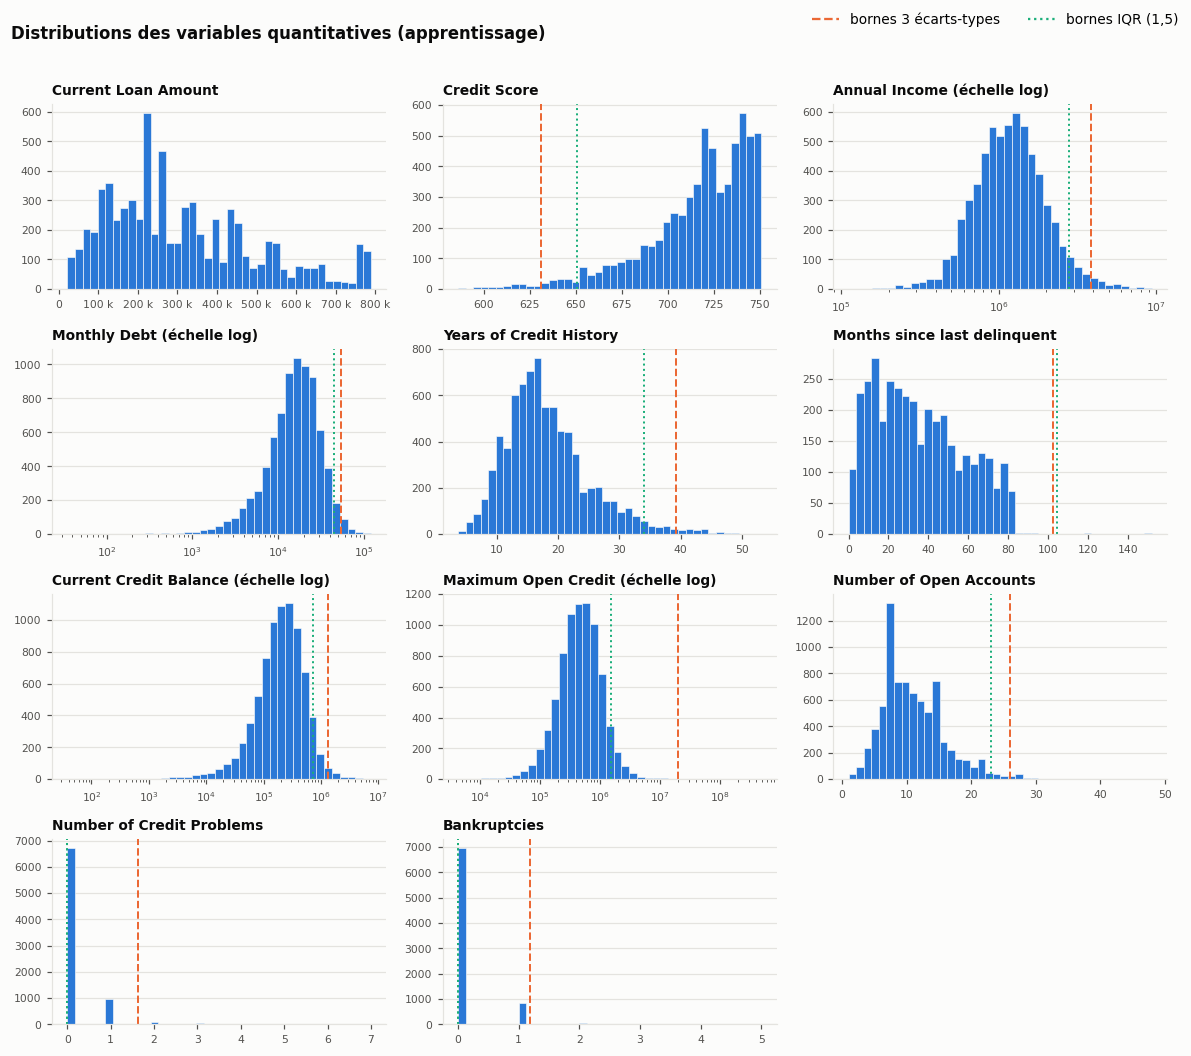

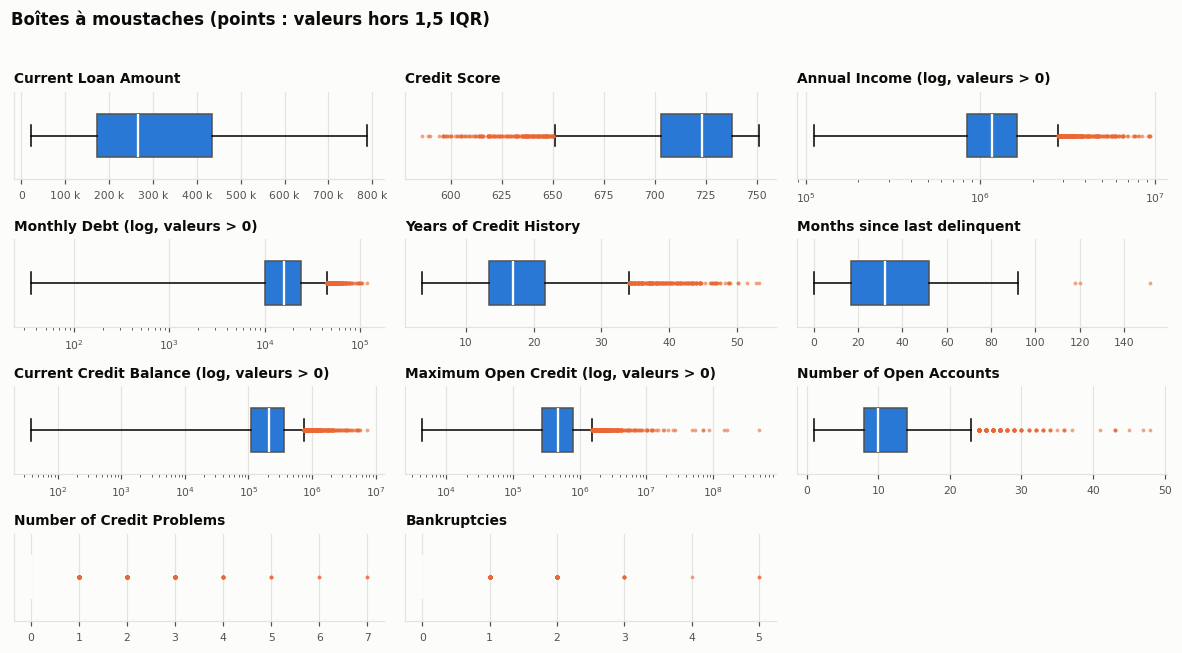

In [44]:
fig = plots_outliers.plot_histograms_with_bounds(train, OUTLIER_COLUMNS, log_columns=MONETARY[1:])
plots.save(fig, FIGURES_DIR / "08_histogrammes_bornes.png")
fig = plots_outliers.plot_boxplots(train, OUTLIER_COLUMNS, log_columns=MONETARY[1:])
plots.save(fig, FIGURES_DIR / "08_boites_a_moustaches.png");

**Lecture des figures.**

- **Bornes des deux méthodes.** Pour toutes les variables positives sauf *Credit Score*, la borne
  basse des deux méthodes est négative, donc hors du domaine des valeurs : **seules les valeurs élevées
  peuvent être signalées**. La borne IQR (pointillés) est toujours plus proche du centre que la borne
  3 écarts-types (tirets).
- **Échelle logarithmique.** Les montants y prennent une forme bien plus régulière, proche d'une
  cloche : leur asymétrie vient surtout de la nature multiplicative des montants. *Maximum Open Credit*
  garde cependant une poignée de points isolés à droite, à plusieurs ordres de grandeur du reste.
- **Comptages.** Pour *Number of Credit Problems* et *Bankruptcies*, la boîte est réduite à un trait
  en 0 : **toute valeur non nulle** apparaît comme un point aberrant.

## 2. Détection par les deux méthodes (Q5)

Les bornes sont calculées sur l'apprentissage, variable par variable. Le tableau donne, pour chaque
méthode :

- les bornes ;
- le nombre d'outliers (en bas, en haut, au total) et leur part parmi les valeurs renseignées ;
- le taux de défaut des observations signalées et celui des autres.

,variable,méthode,borne_inf,borne_sup,n_bas,n_haut,n_outliers,part,taux_defaut_outliers,taux_defaut_autres
0,Current Loan Amount,3 écarts-types,"-246,865.4914","869,820.6334",0,0,0,0.0000,NaN,0.2635
1,Current Loan Amount,IQR,"-220,709.5000","826,622.5000",0,0,0,0.0000,NaN,0.2635
2,Credit Score,3 écarts-types,630.9411,801.6347,91,0,91,0.0144,0.4505,0.2189
3,Credit Score,IQR,650.5000,790.5000,220,0,220,0.0347,0.3682,0.2170
4,Annual Income,3 écarts-types,"-1,163,068.7312","3,887,924.6430",0,107,107,0.0169,0.1589,0.2233
5,Annual Income,IQR,"-335,506.7500","2,808,461.2500",0,309,309,0.0488,0.1294,0.2270
6,Monthly Debt,3 écarts-types,"-17,420.0725","54,031.4994",0,115,115,0.0146,0.1565,0.2359
7,Monthly Debt,IQR,"-10,911.8900","44,852.3500",0,249,249,0.0317,0.2088,0.2355
8,Years of Credit History,3 écarts-types,-2.7810,39.2971,0,109,109,0.0139,0.1651,0.2357
9,Years of Credit History,IQR,1.2000,34.0000,0,249,249,0.0317,0.1928,0.2361


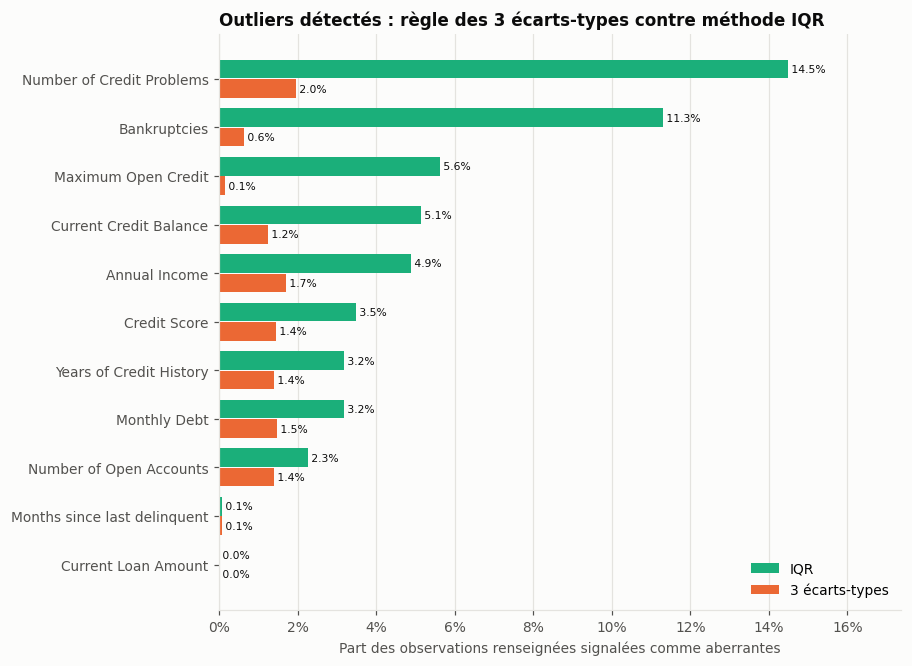

In [45]:
detection = ol.detection_table(train, y_train, OUTLIER_COLUMNS)
save_table(detection, "08_detection_outliers")
display(detection)
fig = plots_outliers.plot_detection_counts(detection)
plots.save(fig, FIGURES_DIR / "08_parts_outliers_par_methode.png");

**Lecture.**

- **La méthode IQR signale toujours au moins autant d'observations** que la règle des 3 écarts-types,
  souvent deux à quatre fois plus :
  - *Current Credit Balance* : 404 contre 98 ;
  - *Annual Income* : 309 contre 107 ;
  - *Credit Score* : 220 contre 91.
- **Cas extrême : *Maximum Open Credit*.** L'IQR signale 443 valeurs (5,6 %), la règle des 3 écarts-types
  seulement 11 (0,14 %). La borne 3σ (19,8 M) est tellement haute qu'elle ne retient que les valeurs
  démesurées.
- **Comptages.**
  - *Number of Credit Problems* : l'IQR signale 1 138 observations (14,5 %), c'est-à-dire tous les
    emprunteurs ayant au moins un incident.
  - *Bankruptcies* : 886 observations (11,3 %), tous ceux ayant au moins une faillite.
- **Variables sans problème.**
  - *Current Loan Amount* : aucun outlier, quelle que soit la méthode. Les montants réels sont bornés
    (maximum 788 942) depuis le retrait de la sentinelle en partie 1.
  - *Months since last delinquent* : 3 outliers seulement, les mêmes pour les deux méthodes.

## 3. Comparaison des deux méthodes (Q5)

Pour chaque variable, on compte :

- les observations signalées par les **deux** méthodes ;
- celles signalées par **une seule** méthode ;
- l'indice de **Jaccard** = |communs| / |union|, qui vaut 1 si les deux méthodes signalent exactement
  les mêmes observations.

In [46]:
overlap = ol.method_overlap(train, OUTLIER_COLUMNS)
save_table(overlap, "08_recouvrement_methodes")
overlap

,variable,les_deux,seulement_3_écarts_types,seulement_IQR,jaccard,iqr_nul
0,Current Loan Amount,0,0,0,NaN,False
1,Credit Score,91,0,129,0.4136,False
2,Annual Income,107,0,202,0.3463,False
3,Monthly Debt,115,0,134,0.4618,False
4,Years of Credit History,109,0,140,0.4378,False
5,Months since last delinquent,3,0,0,1.0000,False
6,Current Credit Balance,98,0,306,0.2426,False
7,Maximum Open Credit,11,0,432,0.0248,False
8,Number of Open Accounts,109,0,68,0.6158,False
9,Number of Credit Problems,154,0,984,0.1353,True


**Constat central : les outliers à 3 écarts-types sont *inclus* dans les outliers IQR, pour toutes
les variables.** La colonne « seulement 3 écarts-types » vaut 0 partout. Les deux méthodes ne divergent
donc que par les observations que **seule l'IQR** signale. Le recouvrement est faible pour les
variables à queue lourde : Jaccard de 0,02 pour *Maximum Open Credit*, 0,24 pour *Current Credit Balance*.

**Pourquoi ces différences ?**

| | Règle des 3 écarts-types | Méthode IQR |
|---|---|---|
| Statistiques utilisées | Moyenne et écart-type | Quartiles |
| Hypothèse implicite | Loi normale : environ 0,27 % d'observations au-delà de 3σ | Aucune hypothèse de loi |
| Sensibilité aux extrêmes | **Forte** : les extrêmes gonflent l'écart-type et repoussent la borne | **Faible** : les quartiles ne bougent pas |
| Effet sur une loi asymétrique | Borne basse négative, borne haute très éloignée : peu de détections | Signale une part importante de la queue droite, même réelle |
| Variable avec Q1 = Q3 | Fonctionne | **Dégénère** : IQR = 0, toute valeur ≠ Q1 est signalée |

**Effet de masquage.** *Maximum Open Credit* en est l'exemple type. Les quelques plafonds démesurés
(jusqu'à 489 M) portent l'écart-type à 6,3 M, si bien que la borne 3σ (19,8 M) ne signale plus que
11 valeurs. Les extrêmes **se cachent eux-mêmes** en dilatant l'échelle de mesure.

**Méthode retenue pour la suite.**

- **Variables continues : la méthode IQR sert au repérage.** Elle est robuste au masquage et ne
  suppose pas de loi normale. Mais sur des montants très asymétriques, elle signale 3 à 6 % de valeurs
  qui sont **réelles**, donc une observation signalée n'est pas pour autant une erreur. Les sections 4
  et 5 examinent ce point.
- **Comptages (*Credit Problems*, *Bankruptcies*) : ni l'une ni l'autre méthode n'est utilisée.** L'IQR
  est dégénéré, et la règle des 3 écarts-types n'a pas de sens pour une variable à 6–8 valeurs entières.
  Ces variables seront regroupées en classes lors de la discrétisation.
- **Pour le traitement, la borne n'est pas celle de l'IQR** mais le 99ᵉ percentile (section 6). Ce
  choix est justifié par la comparaison des stratégies.

## 4. Les valeurs extrêmes sont-elles plus risquées ?

Avant de décider d'un traitement, on vérifie si les observations signalées ont un **profil de risque
différent**. Si c'est le cas, elles portent de l'information, et les supprimer ou les imputer
appauvrirait le modèle.

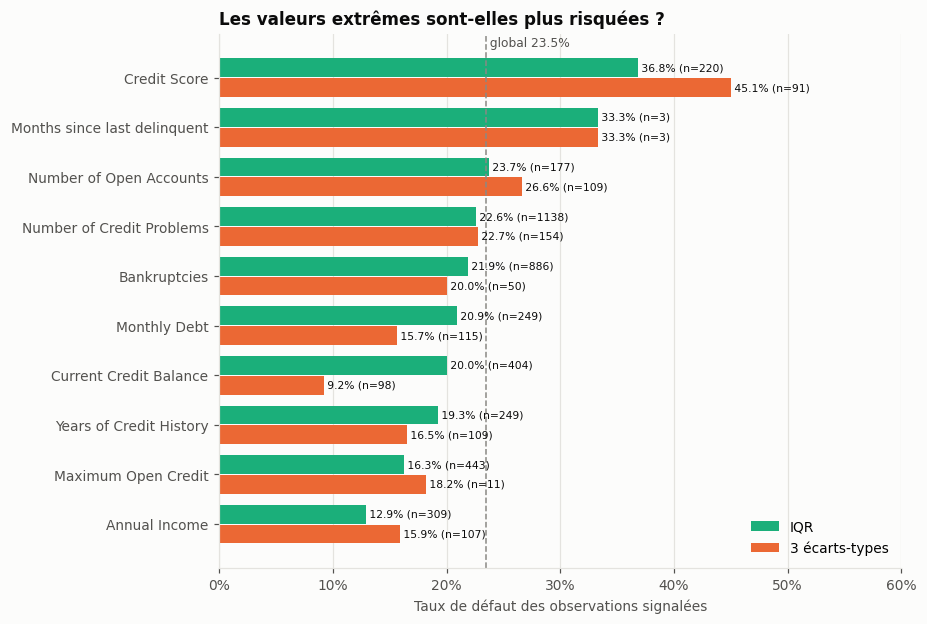

In [47]:
fig = plots_outliers.plot_outlier_default_rates(detection, y_train.mean())
plots.save(fig, FIGURES_DIR / "08_taux_defaut_outliers.png");

**Lecture.** Le taux de défaut de l'apprentissage est de 23,5 %. Les extrêmes s'en écartent nettement,
et dans les deux sens.

- **Credit Score.** Les scores bas sont **beaucoup plus risqués** : 45,1 % de défaut pour les outliers
  3σ, 36,8 % pour les outliers IQR. C'est exactement l'information que le score doit apporter.
- **Annual Income.** Les très hauts revenus sont **moins risqués** : 15,9 % (3σ) et 12,9 % (IQR).
- **Current Credit Balance.** Les encours très élevés ont un taux de défaut faible : 9,2 % pour les
  outliers 3σ.
- **Years of Credit History.** Les historiques très longs sont moins risqués : 16,5 % (3σ) et 19,3 % (IQR).
- **Comptages.** Les emprunteurs ayant des incidents ou des faillites ont un taux de défaut proche de
  la moyenne (20,0 % à 22,7 %), comme déjà constaté en partie 1.

Les valeurs extrêmes sont donc pour la plupart des **observations réelles et informatives** sur le
risque. Les supprimer ou les remplacer par la médiane détruirait précisément ce signal.

## 5. Erreurs de qualité ou valeurs réelles extrêmes ?

Deux critères complémentaires permettent de séparer une valeur **aberrante par erreur** d'une valeur
**rare mais vraie**.

1. **Extrême en ordre de grandeur.** On applique la clôture « très éloignée » de Tukey ($k = 3$) au
   **logarithme** de chaque montant positif. Un montant hors de ces bornes est 10 ou 100 fois plus
   grand (ou plus petit) que les valeurs usuelles, ce qui est rarement réaliste pour une donnée financière.
2. **Incohérence avec une autre variable.** Un plafond de crédit sans rapport avec le revenu annuel,
   par exemple, signale une erreur probable.

In [48]:
suspicious = ol.suspicious_magnitudes(train, MONETARY)
save_table(suspicious, "08_extremes_ordre_de_grandeur")
display(suspicious)
moc_bounds = ol.log_iqr_bounds(train["Maximum Open Credit"])
moc_suspects = ol.ratio_to_reference(
    train, "Maximum Open Credit", "Annual Income", train["Maximum Open Credit"] > moc_bounds.upper
)
save_table(moc_suspects, "08_maximum_open_credit_suspects", index=True)
ratio_all = (train["Maximum Open Credit"] / train["Annual Income"]).describe(percentiles=[0.5, 0.99])
print("Ratio plafond / revenu annuel sur l'apprentissage :", ratio_all[["50%", "99%"]].round(2).to_dict())
moc_suspects

,variable,n_zéros,borne_inf_log,borne_sup_log,n_sous_borne,n_sur_borne
0,Current Loan Amount,0,"10,725.8041","6,959,246.1146",0,0
1,Annual Income,0,"116,993.0378","11,747,965.0246",1,0
2,Monthly Debt,8,730.1826,"328,306.5645",26,0
3,Current Credit Balance,47,"3,211.9144","12,627,082.6663",45,0
4,Maximum Open Credit,55,"11,624.7474","18,382,805.3952",9,11


Ratio plafond / revenu annuel sur l'apprentissage : {'50%': 0.4, '99%': 2.31}


,Maximum Open Credit,Annual Income,ratio
2954,"21,372,428.0000","1,520,304.0000",14.0580
5983,"25,368,464.0000","1,064,019.0000",23.8421
3066,"26,946,898.0000","1,998,496.0000",13.4836
2622,"47,844,500.0000",NaN,NaN
3096,"54,484,386.0000","3,356,255.0000",16.2337
2037,"69,918,046.0000","1,167,588.0000",59.8825
1536,"71,309,216.0000",NaN,NaN
2749,"86,599,480.0000","2,229,574.0000",38.8413
491,"145,907,344.0000","3,355,970.0000",43.4770
2964,"162,187,168.0000","8,426,880.0000",19.2464


**Interprétation.**

- **Maximum Open Credit : erreurs probables.** 11 plafonds dépassent la borne haute en ordre de
  grandeur (18,4 M) ; ils vont de 21 M à 489 M.
  - Rapportés au revenu annuel, ils représentent **13 à 293 fois** ce revenu. Sur l'ensemble de
    l'apprentissage, ce ratio vaut 0,40 en médiane et 2,31 au 99ᵉ percentile.
  - Aucun établissement n'accorde une ligne de crédit renouvelable de plusieurs dizaines d'années de
    revenu. Ces valeurs sont très probablement des **erreurs de saisie ou d'unité**.
  - Ce sont les mêmes 11 valeurs que signale la règle des 3 écarts-types.
- **Valeurs basses de *Monthly Debt* et *Current Credit Balance*.** Elles sont sous la borne basse en
  ordre de grandeur (26 et 45 valeurs strictement positives), mais restent **plausibles** : une dette
  mensuelle de quelques dizaines d'unités, un encours presque soldé. Elles ne sont pas traitées. Les
  zéros (8, 47 et 55 selon la variable) sont des situations réelles : aucune dette, aucun encours,
  ligne fermée.
- **Annual Income, Current Loan Amount.** Une seule valeur basse pour *Annual Income* (111 245), et
  aucune en haut. Les hauts revenus signalés par l'IQR restent dans un ordre de grandeur crédible et
  sont moins risqués (section 4) : ce sont des **valeurs réelles**.
- **Credit Score.** Toutes les valeurs (586 à 751) appartiennent à l'échelle 300–850. Les outliers bas
  sont des **emprunteurs réellement risqués**.
- **Years of Credit History (≤ 53 ans), Number of Open Accounts (≤ 48), Months since last delinquent
  (≤ 152 mois).** Valeurs élevées mais plausibles. Le partie 1 a vérifié qu'aucun retard n'est
  antérieur à l'ouverture de l'historique de crédit.

## 6. Stratégies de traitement (Q6)

### 6.1 Impact de chaque stratégie sur les distributions

Pour les quatre montants à forte asymétrie, on compare sept stratégies, toutes paramétrées sur l'apprentissage :

- **aucun traitement** ;
- **suppression** des outliers (3σ ou IQR) ;
- **imputation** des outliers IQR par la médiane ;
- **plafonnement** (*capping*, winsorisation) à la borne IQR ou au 99ᵉ percentile ;
- **transformation** $\log(1+x)$.

Le tableau donne, pour chacune :

- le nombre d'observations conservées et de valeurs modifiées ;
- la moyenne, l'écart-type, l'asymétrie et le maximum après traitement ;
- le taux de défaut des observations conservées.

In [49]:
comparison = pd.concat([ol.strategy_comparison(train, y_train, col) for col in CAPPING_COLUMNS], ignore_index=True)
save_table(comparison, "09_comparaison_strategies")
comparison

,variable,stratégie,n_conservées,n_retirées,valeurs_modifiées,moyenne,écart_type,asymétrie,max,taux_defaut_conservées
0,Annual Income,Aucun traitement,6332,0,0,"1,362,427.9559","841,832.2290",2.9757,"9,458,200.0000",0.2222
1,Annual Income,Suppression (3 écarts-types),6225,107,0,"1,293,055.6644","635,184.1003",1.1937,"3,874,100.0000",0.2233
2,Annual Income,Suppression (IQR),6023,309,0,"1,227,824.0536","531,324.5008",0.6914,"2,807,250.0000",0.2270
3,Annual Income,Imputation médiane (IQR),6332,0,309,"1,223,471.5039","518,552.2419",0.7324,"2,807,250.0000",0.2222
4,Annual Income,Plafonnement (IQR),6332,0,309,"1,304,958.7494","620,094.8534",0.8471,"2,808,461.2500",0.2222
5,Annual Income,Plafonnement (P99),6332,0,64,"1,347,614.3670","755,592.1856",1.8226,"4,685,500.5100",0.2222
6,Annual Income,Transformation log(1+x),6332,0,6332,13.9833,0.5213,0.1403,16.0624,0.2222
7,Monthly Debt,Aucun traitement,7861,0,0,"18,305.7135","11,908.5953",1.6115,"120,559.5600",0.2347
8,Monthly Debt,Suppression (3 écarts-types),7746,115,0,"17,593.8009","10,328.7537",0.8347,"53,926.3700",0.2359
9,Monthly Debt,Suppression (IQR),7612,249,0,"17,040.2591","9,525.0135",0.6109,"44,796.3000",0.2355


**Lecture** (les chiffres de cette lecture portent sur *Maximum Open Credit* ; les autres montants suivent le même schéma) :

| Stratégie | Effet observé | Problème |
|---|---|---|
| Suppression (IQR) | Retire 443 lignes ; asymétrie de 63 à 0,86 | Perte d'observations, et d'observations informatives (section 4) |
| Suppression (3σ) | Retire 11 lignes ; asymétrie encore de 8,8 | Traite seulement les cas les plus grossiers |
| Imputation médiane (IQR) | Remplace 443 valeurs par la médiane ; asymétrie 0,93 | Transforme de **vrais** gros plafonds en plafonds moyens : information détruite, distribution artificiellement resserrée |
| Plafonnement (IQR) | 443 valeurs ramenées à 1,54 M ; asymétrie 0,99 | Écrase 5,6 % de la distribution, dont des valeurs réelles |
| **Plafonnement (P99)** | **79 valeurs (1 %)** ramenées à 3,62 M ; asymétrie de 63 à 2,7 ; écart-type de 6,3 M à 0,56 M | Garde l'essentiel de la forme, neutralise les erreurs |
| Transformation log(1+x) | Asymétrie de **−5,7** | Les zéros et petites valeurs créent une nouvelle queue, à gauche ; la variable perd son échelle naturelle |

Pour les trois autres montants, le plafonnement au P99 modifie exactement 1 % des valeurs (64 pour
*Annual Income*, 79 pour *Monthly Debt* et *Current Credit Balance*). Il réduit nettement l'asymétrie
(par exemple de 6,7 à 2,2 pour *Current Credit Balance*), sans retirer une seule observation.

In [50]:
deletion = ol.row_deletion_impact(train, y_train, OUTLIER_COLUMNS)
save_table(deletion, "09_impact_suppression_lignes")
deletion

,méthode,lignes_conservées,part_conservée,défauts_conservés,taux_defaut
0,Aucune suppression,7861,1.0000,1845,0.2347
1,Suppression (3 écarts-types),7176,0.9129,1690,0.2355
2,Suppression (IQR),5457,0.6942,1307,0.2395


**Suppression des lignes : un coût prohibitif.** Si l'on supprime toute ligne signalée sur au moins
une variable :

- avec **l'IQR**, il ne reste que **5 457 prêts sur 7 861 (69,4 %)** : près d'un tiers de l'apprentissage
  disparaît, dont 538 défauts ;
- avec la **règle des 3 écarts-types**, il reste 7 176 prêts (91,3 %).

Dans les deux cas, le taux de défaut est modifié (23,55 % et 23,95 % contre 23,47 %) : l'échantillon
devient **moins représentatif** de la population sur laquelle le modèle sera appliqué. En production,
un emprunteur aux valeurs extrêmes recevra quand même une PD : le modèle doit donc avoir appris sur ce
type de profil.

### 6.2 Effet sur la discrétisation

La suite du projet discrétise les variables quantitatives en classes de quantiles (sujet 1.2.2).
Le plafonnement au P99 **préserve l'ordre** des observations, sauf pour les valeurs ramenées sur la
borne, qui deviennent égales. On vérifie que les classes de déciles sont strictement identiques avant
et après traitement.

In [51]:
capping_bounds = ol.fit_capping(train, CAPPING_COLUMNS, CAPPING_QUANTILE)
train_capped = ol.apply_capping(train, capping_bounds)
bins_check = pd.DataFrame(
    {"variable": CAPPING_COLUMNS,
     "déciles_identiques": [ol.quantile_bins_preserved(train[c], train_capped[c]) for c in CAPPING_COLUMNS]}
)
bins_check

,variable,déciles_identiques
0,Annual Income,True
1,Monthly Debt,True
2,Current Credit Balance,True
3,Maximum Open Credit,True


**Lecture.** Pour les quatre variables, la discrétisation en déciles est **inchangée**. Le plafonnement
n'altère donc pas les classes utilisées par la régression logistique (WoE).

Son rôle est de protéger toute utilisation des **montants sous forme continue** (statistiques
descriptives, corrélations, XGBoost) contre l'influence de quelques valeurs démesurées.

**Il ne doit pas servir au calcul des ratios** (DTI, CUR, ACR, IES). Plafonner séparément le numérateur
et le dénominateur déformerait leur rapport, ce qui est quantifié en partie 3 : une centaine de
ratios seraient modifiés, avec un écart relatif médian de 14 à 21 %. Les ratios seront donc calculés
sur les montants non plafonnés.

### 6.3 Traitement retenu : apprentissage sur train, application à train et test

**Choix retenu.** Plafonnement des quatre montants à forte asymétrie (*Annual Income*, *Monthly Debt*,
*Current Credit Balance*, *Maximum Open Credit*) à leur **99ᵉ percentile calculé sur l'apprentissage**.
Les bornes sont apprises une seule fois (`fit_capping`), puis appliquées telles quelles à l'apprentissage
et au test (`apply_capping`).

**Pourquoi le 99ᵉ percentile plutôt que la borne IQR ?** Sur ces distributions asymétriques, la borne
IQR toucherait 3 à 6 % de valeurs réelles. Le P99 limite l'intervention à 1 % et neutralise malgré tout
les 11 plafonds aberrants, situés bien au-dessus.

On vérifie que la part de valeurs plafonnées dans le **test** reste proche de 1 %. Si c'est le cas, les
bornes apprises se transposent bien.

,variable,borne_sup,n_plafonnées_apprentissage,n_plafonnées_test,part_apprentissage,part_test
0,Annual Income,"4,685,500.5100",64,18,0.0101,0.0113
1,Monthly Debt,"58,126.4720",79,28,0.0100,0.0142
2,Current Credit Balance,"1,511,305.6000",79,24,0.0100,0.0122
3,Maximum Open Credit,"3,617,451.2000",79,21,0.0100,0.0107


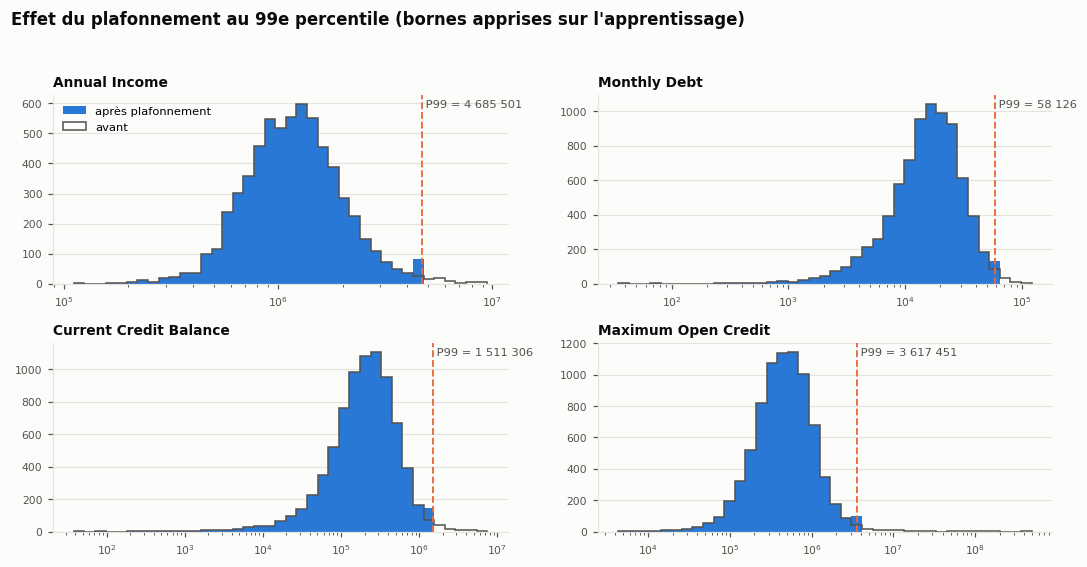

In [52]:
capping_table = ol.capping_report({"apprentissage": train, "test": test}, capping_bounds)
save_table(capping_table, "09_bornes_plafonnement")
test_capped = ol.apply_capping(test, capping_bounds)
display(capping_table)
fig = plots_outliers.plot_capping_effect(train, train_capped, capping_bounds)
plots.save(fig, FIGURES_DIR / "09_effet_plafonnement.png");

**Lecture.**

- **Apprentissage.** Par construction, 1,0 % des valeurs renseignées sont plafonnées.
- **Test.** La part est de 1,1 % à 1,4 % : la distribution du test au-delà des bornes est très proche
  de celle de l'apprentissage, et les bornes se transposent correctement.
- **Figure.** Seule l'extrémité droite de chaque distribution est modifiée : la masse des valeurs
  au-delà du P99 se reporte sur la borne.

## 7. Tableau récapitulatif des décisions

In [53]:
decisions = ol.decision_table(detection)
save_table(decisions, "09_decisions_outliers")
decisions

,variable,n_3_écarts_types,n_IQR,origine,traitement,justification
0,Current Loan Amount,0,0,Aucun outlier (sentinelle déjà retirée),Aucun,Distribution bornée et peu asymétrique.
1,Credit Score,91,220,Valeurs réelles (queue basse),Aucun,Scores dans l'échelle 300–850 ; les scores bas sont les plus risqués : information à c...
2,Annual Income,107,309,Valeurs réelles (queue haute),Plafonnement au P99 appris sur train,Revenus élevés plausibles ; plafond pour l'usage continu du montant (ratios calculés a...
3,Monthly Debt,115,249,Valeurs réelles (queue haute),Plafonnement au P99 appris sur train,Cohérentes avec le revenu (dette annuelle < revenu) ; plafond pour l'usage continu du ...
4,Years of Credit History,109,249,Valeurs réelles,Aucun,Historiques d'une cinquantaine d'années au plus : plausibles.
5,Months since last delinquent,3,3,Valeurs réelles,Aucun,"Très peu d'outliers, cohérents avec l'historique de crédit."
6,Current Credit Balance,98,404,Valeurs réelles (queue haute),Plafonnement au P99 appris sur train,Asymétrie très forte ; plafond pour l'usage continu du montant.
7,Maximum Open Credit,11,443,Erreurs probables (ordre de grandeur) et queue haute réelle,Plafonnement au P99 appris sur train,Plafonds sans rapport avec le revenu ; le plafonnement les neutralise sans perdre la l...
8,Number of Open Accounts,109,177,Valeurs réelles,Aucun,Comptage plausible ; traité par la discrétisation.
9,Number of Credit Problems,154,1138,Valeurs réelles (comptage rare),Regroupement à la discrétisation,"IQR nul : la méthode IQR signale toute valeur non nulle, ce qui est inadapté."


**Synthèse.** Aucune observation n'est supprimée et aucune variable n'est exclue pour cause d'outliers.

| Origine des valeurs extrêmes | Variables | Traitement |
|---|---|---|
| Erreurs de qualité probables | *Maximum Open Credit* : 11 plafonds de 13 à 293 fois le revenu annuel | Neutralisées par le plafonnement au P99 |
| Valeurs réelles, informatives et à forte asymétrie | *Annual Income*, *Monthly Debt*, *Current Credit Balance* | Plafonnées au P99 pour limiter leur levier, sans perte d'observation ni de classe de quantile |
| Valeurs réelles, sans traitement | *Credit Score* (scores bas = risque élevé), *Years of Credit History*, *Months since last delinquent*, *Number of Open Accounts*, *Current Loan Amount* | Aucun |
| Comptages rares, IQR dégénéré | *Number of Credit Problems*, *Bankruptcies* | Regroupement de modalités à la discrétisation (sujet 1.2.2) |

Le plafonnement de *Maximum Open Credit* conserve la ligne, et l'information « plafond très élevé ». Une
imputation par la médiane aurait au contraire affecté une valeur moyenne à des emprunteurs qui ont
manifestement un plafond élevé.

## 8. Export

In [54]:
train_capped.to_csv(PROCESSED_DIR / "train_outliers.csv", index=False, encoding="utf-8")
test_capped.to_csv(PROCESSED_DIR / "test_outliers.csv", index=False, encoding="utf-8")
assert train_capped[LOAN_ID].equals(train[LOAN_ID]) and test_capped[LOAN_ID].equals(test[LOAN_ID])

pct1, pct2, int0, num2 = percent(1), percent(2), number(0), number(2)
latex_exports = {
    "08_detection_outliers": (
        detection[["variable", "méthode", "borne_inf", "borne_sup", "n_outliers", "part", "taux_defaut_outliers"]],
        {"borne_inf": num2, "borne_sup": num2, "n_outliers": int0, "part": pct1, "taux_defaut_outliers": pct1},
        "llrrrrr"),
    "08_recouvrement_methodes": (
        overlap.drop(columns="iqr_nul"),
        {"les_deux": int0, "seulement_3_écarts_types": int0, "seulement_IQR": int0, "jaccard": number(2)},
        "lrrrr"),
    "08_maximum_open_credit_suspects": (
        moc_suspects.reset_index(drop=True),
        {"Maximum Open Credit": int0, "Annual Income": int0, "ratio": number(1)}, "rrr"),
    "09_comparaison_strategies_moc": (
        comparison.loc[comparison["variable"] == "Maximum Open Credit",
                       ["stratégie", "n_conservées", "valeurs_modifiées", "moyenne", "écart_type", "asymétrie", "max"]],
        {"n_conservées": int0, "valeurs_modifiées": int0, "moyenne": int0, "écart_type": int0,
         "asymétrie": number(2), "max": int0},
        "lrrrrrr"),
    "09_impact_suppression_lignes": (
        deletion, {"lignes_conservées": int0, "part_conservée": pct1, "défauts_conservés": int0, "taux_defaut": pct2},
        "lrrrr"),
    "09_bornes_plafonnement": (
        capping_table, {"borne_sup": int0, "n_plafonnées_apprentissage": int0, "n_plafonnées_test": int0,
                        "part_apprentissage": pct2, "part_test": pct2}, "lrrrrr"),
    "09_decisions_outliers": (
        decisions[["variable", "n_3_écarts_types", "n_IQR", "origine", "traitement"]],
        {"n_3_écarts_types": int0, "n_IQR": int0}, "lrrp{4.2cm}p{3.6cm}"),
}
for name, (table, formatters, spec) in latex_exports.items():
    save_latex_table(table, name, formatters, spec)
print("Écrits : resultats/donnees/train_outliers.csv, test_outliers.csv et", len(latex_exports), "tableaux LaTeX")

Écrits : resultats/donnees/train_outliers.csv, test_outliers.csv et 7 tableaux LaTeX


## 9. Conclusion

1. **Les deux méthodes ne sont pas équivalentes.** Sur ces données, les outliers à 3 écarts-types
   forment toujours un sous-ensemble des outliers IQR.
   - La règle des 3σ souffre d'un **effet de masquage** sur les distributions à queue lourde : elle ne
     signale que 11 plafonds aberrants alors que l'écart-type est gonflé à 6,3 M.
   - L'IQR, robuste, signale en revanche 3 à 6 % de valeurs réelles sur les montants asymétriques, et
     **dégénère sur les comptages** (IQR nul).
2. **La plupart des extrêmes sont réels et informatifs.** Les scores bas sont jusqu'à près de deux fois plus
   risqués que la moyenne ; les hauts revenus et les gros encours, moins risqués. Ils ne doivent être ni supprimés,
   ni imputés.
3. **Une seule anomalie de qualité est identifiée** : 11 plafonds *Maximum Open Credit* incohérents avec
   le revenu.
4. **Traitement retenu.** Plafonnement au 99ᵉ percentile appris sur l'apprentissage, pour 4 montants.
   - Aucune ligne n'est perdue, et les classes de quantiles sont inchangées.
   - Les bornes se transposent au test (1,1 à 1,4 % de valeurs plafonnées).

**Étape suivante (partie 3)** : construction des variables dérivées (DTI, CUR, ACR, ESR, IES).

- Elles sont ajoutées à `train_outliers.csv` / `test_outliers.csv`, mais calculées sur les montants
  **non plafonnés** (`train_dq.csv` / `test_dq.csv`).
- Les divisions par zéro sont gérées explicitement (55 plafonds nuls dans l'apprentissage).

# Partie 3 — Variables dérivées (sujet 1.2.1)

**Sujet, section 1.2.1.** Construire cinq variables dérivées, en interpréter la signification économique
et préciser leur effet attendu sur la probabilité de défaut :

| Variable | Formule |
|---|---|
| Debt-to-Income Ratio (DTI) | $\mathrm{DTI} = \dfrac{12 \times \text{Monthly Debt}}{\text{Annual Income}}$ |
| Credit Utilization Ratio (CUR) | $\mathrm{CUR} = \dfrac{\text{Current Credit Balance}}{\text{Maximum Open Credit}}$ |
| Available Credit Ratio (ACR) | $\mathrm{ACR} = \dfrac{\text{Maximum Open Credit} - \text{Current Credit Balance}}{\text{Maximum Open Credit}}$ |
| Employment Stability Ratio (ESR) | $\mathrm{ESR} = \dfrac{\text{Years in current job}}{\text{Years of Credit History}}$ |
| Income × Employment Stability (IES) | $\mathrm{IES} = \text{Annual Income} \times \text{Years in current job}$ |

**Principes de construction**

1. Les ratios sont calculés sur les montants **non plafonnés** (`train_dq.csv`, `test_dq.csv`). La section 3
   montre pourquoi.
2. Une division par zéro, ou par une valeur manquante, donne une valeur **non définie** (`NaN`), jamais
   `inf` ni une valeur arbitraire. Chaque cause est comptée.
3. Les seuls paramètres estimés le sont **sur l'apprentissage** (`fit_feature_params`), puis appliqués tels
   quels au test :
   - la borne au-delà de laquelle un plafond de crédit est jugé erroné ;
   - le plafond de l'IES.

In [55]:
import sys
from pathlib import Path


import pandas as pd
from IPython.display import display

from src.config import CORRELATION_THRESHOLD, FIGURES_DIR, PROCESSED_DIR, TARGET
from src import features as fe
from src import outliers as ol
from src import plots, plots_features, plots_outliers
from src.reporting import number, percent, save_latex_table, save_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plots.set_style()

train_dq, test_dq = pd.read_csv(PROCESSED_DIR / "train_dq.csv"), pd.read_csv(PROCESSED_DIR / "test_dq.csv")
train_capped, test_capped = pd.read_csv(PROCESSED_DIR / "train_outliers.csv"), pd.read_csv(PROCESSED_DIR / "test_outliers.csv")
y_train = train_dq[TARGET]
print(f"Apprentissage : {len(train_dq)} prêts ; test : {len(test_dq)} prêts")

Apprentissage : 7861 prêts ; test : 1966 prêts


## 1. Signification économique et effet attendu

In [56]:
definitions = fe.definitions_table()
save_table(definitions, "10_definitions_variables_derivees")
definitions

,variable,formule,signification,effet_attendu
0,DTI,12 × Monthly Debt / Annual Income,Part du revenu annuel absorbée par le service de la dette : mesure la capacité de remboursement.,"Plus le DTI est élevé, moins il reste de revenu pour absorber un choc : PD croissante."
1,CUR,Current Credit Balance / Maximum Open Credit,Taux d'utilisation des lignes de crédit renouvelables : dépendance au crédit.,Une utilisation proche du plafond signale une tension de trésorerie : PD croissante.
2,ACR,(Maximum Open Credit − Current Credit Balance) / Maximum Open Credit,Part du plafond encore disponible : réserve de liquidité mobilisable (ACR = 1 − CUR).,Une réserve importante permet de faire face à un imprévu : PD décroissante.
3,ESR,Years in current job / Years of Credit History,Ancienneté dans l'emploi rapportée à l'ancienneté de crédit : stabilité professionnelle relative.,Un emploi stable sur une grande partie de la vie de crédit rassure : PD décroissante.
4,IES,Annual Income × Years in current job,Revenu pondéré par sa durabilité : niveau et stabilité des ressources.,Un revenu élevé et ancien est plus sûr : PD décroissante.


**Lecture détaillée**

- **DTI : capacité de remboursement.** Le DTI rapporte la charge annuelle de la dette au revenu
  annuel. Un DTI de 0,30 signifie que 30 % du revenu sert à rembourser des dettes. Plus il est élevé,
  plus la marge pour absorber une baisse de revenu ou une dépense imprévue est mince. *Effet attendu :
  la PD croît avec le DTI.*
- **CUR : dépendance au crédit renouvelable.** Le CUR mesure la part des lignes de crédit déjà
  utilisée. Un emprunteur proche de son plafond (CUR ≈ 1) finance probablement des dépenses courantes
  à crédit : c'est un signe de tension de trésorerie, et l'un des facteurs de risque les plus utilisés
  par les bureaux de crédit. *Effet attendu : PD croissante.*
- **ACR : réserve de liquidité.** L'ACR est la part du plafond encore disponible, mobilisable en cas
  de coup dur. *Effet attendu : PD décroissante.* Par construction, $\mathrm{ACR} = 1 - \mathrm{CUR}$
  dès que le plafond est non nul : les deux variables portent **exactement la même information**, en
  sens opposé (section 6).
- **ESR : stabilité professionnelle relative.** L'ESR rapporte l'ancienneté dans l'emploi actuel à
  l'ancienneté de l'historique de crédit. Un ESR proche de 1 indique un emploi conservé pendant toute
  la vie de crédit. *Effet attendu : PD décroissante.*
- **IES : niveau et durabilité du revenu.** L'IES combine le niveau du revenu et la stabilité de
  l'emploi qui le procure : un revenu élevé et ancien est plus sûr qu'un revenu élevé mais récent.
  *Effet attendu : PD décroissante.* Contrairement aux autres, ce n'est pas un ratio mais un produit,
  exprimé en « unités monétaires × années ». Sa distribution est donc très asymétrique.

## 2. Conversion de *Years in current job*

*Years in current job* est une variable qualitative ordinale. ESR et IES exigent une valeur
numérique, obtenue par la règle suivante :

| Modalité | Valeur |
|---|---|
| `< 1 year` | 0 |
| `1 year` … `9 years` | 1 … 9 |
| `10+ years` | 10 |
| `n/a` | non définie |

**Deux limites, liées au codage de la source :**

- `10+ years` est **censuré** : 10 est un minorant, et un emprunteur avec 25 ans d'ancienneté reçoit
  la même valeur ;
- `< 1 year` est ramené à 0, ce qui annule ESR et IES pour ces emprunteurs.

In [57]:
job_years = fe.years_in_job(train_dq)
job_counts = job_years.value_counts(dropna=False).sort_index().rename("effectif").to_frame()
job_counts.index = job_counts.index.map(lambda v: "non défini (n/a)" if pd.isna(v) else f"{v:.0f}")
job_counts.T

,0,1,2,3,4,5,6,7,8,9,10,non défini (n/a)
effectif,671,482,704,602,508,508,492,437,344,320,2450,343


**Lecture.**

- La modalité censurée `10+ years` est la plus fréquente : 2 450 prêts, soit 31 % de l'apprentissage.
  ESR et IES sont donc **sous-estimés** pour une part importante des emprunteurs les plus stables.
- 671 prêts ont une ancienneté de 0 (`< 1 year`) et 343 une ancienneté non définie (`n/a`).

## 3. Pourquoi calculer les ratios sur les montants non plafonnés ?

Au partie 2, les montants à forte asymétrie ont été plafonnés **séparément** à leur 99ᵉ percentile.
Or le ratio de deux montants plafonnés indépendamment n'est pas le ratio des montants d'origine.

*Exemple pédagogique* : un emprunteur a un plafond de 5 M et un encours de 4,9 M, soit CUR = 0,98.
Après plafonnement séparé (plafond ramené à 3,6 M, encours à 1,5 M), on obtiendrait CUR ≈ 0,42.
Un emprunteur saturé paraîtrait modérément endetté.

Le tableau mesure l'ampleur réelle de cette déformation sur l'apprentissage.

In [58]:
params = fe.fit_feature_params(train_dq)
distortion = fe.capping_distortion(train_dq, train_capped, params)
save_table(distortion, "10_deformation_ratios_plafonnement")
distortion

,variable,lignes_modifiées,écart_relatif_médian,écart_relatif_max
0,DTI,106,0.1406,1.0186
1,CUR,101,0.2064,4.0773
2,ACR,101,0.1933,2.9681
3,ESR,0,NaN,NaN
4,IES,59,0.1950,0.5029


**Lecture.** Calculés sur les montants plafonnés, les ratios seraient modifiés pour une centaine de
prêts :

- 106 pour le DTI, 101 pour CUR et ACR ;
- l'écart relatif médian est de 14 à 21 %, et peut atteindre un facteur 4 pour CUR.

ESR n'est pas affecté, car ses composantes ne sont pas plafonnées. **Les ratios sont donc calculés sur les
montants non plafonnés.** Les ratios obtenus restent naturellement bornés (section 5) : le plafonnement
des composantes n'est pas nécessaire pour les stabiliser. Il reste utile pour les montants utilisés
seuls.

## 4. Divisions par zéro et valeurs non définies

### 4.1 Recensement

Pour chaque variable dérivée, on compte les valeurs non définies et leur cause :

- dénominateur nul ;
- dénominateur ou numérateur manquant ;
- plafond de crédit jugé erroné.

La fonction `safe_divide` remplace toute division par un dénominateur nul ou manquant par `NaN`. Le
test unitaire `test_safe_divide_never_returns_inf` vérifie qu'aucune valeur infinie n'est produite.

In [59]:
print("Bornes de plausibilité du plafond de crédit (apprises sur l'apprentissage) :", params.limit_bounds)
undefined_train = fe.undefined_report(train_dq, params)
undefined_test = fe.undefined_report(test_dq, params)
undefined = undefined_train.merge(undefined_test, on=["variable", "cause"], suffixes=("_apprentissage", "_test"))
save_table(undefined, "10_valeurs_non_definies")
undefined

Bornes de plausibilité du plafond de crédit (apprises sur l'apprentissage) : Bounds(lower=11624.747370898936, upper=18382805.395179916)


,variable,cause,n_apprentissage,part_apprentissage,n_test,part_test
0,ACR,plafond erroné (ordre de grandeur),11,0.0014,3,0.0015
1,ACR,plafond nul,55,0.0070,10,0.0051
2,ACR,total non défini,66,0.0084,13,0.0066
3,CUR,plafond erroné (ordre de grandeur),11,0.0014,3,0.0015
4,CUR,plafond nul,55,0.0070,10,0.0051
5,CUR,total non défini,66,0.0084,13,0.0066
6,DTI,revenu manquant,1529,0.1945,369,0.1877
7,DTI,revenu nul,0,0.0000,0,0.0000
8,DTI,total non défini,1529,0.1945,369,0.1877
9,ESR,ancienneté d'emploi manquante,343,0.0436,80,0.0407


**Lecture par variable**

| Variable | Dénominateur nul | Autres causes | Total non défini (apprentissage) |
|---|---|---|---|
| DTI | Revenu nul : **jamais** observé (géré quand même) | Revenu manquant : 1 529 | 1 529 (19,4 %) |
| CUR, ACR | **Plafond nul : 55** | Plafond erroné : 11 | 66 (0,8 %) |
| ESR | Ancienneté de crédit nulle : **jamais** (minimum 3,6 ans) | Ancienneté d'emploi `n/a` : 343 | 343 (4,4 %) |
| IES | Pas de division | Revenu manquant ou ancienneté `n/a` | 1 806 (23,0 %) |

- Dans le test, les proportions sont du même ordre (DTI 18,8 %, CUR et ACR 0,7 %, ESR 4,1 %, IES 21,7 %).
- La plupart des valeurs non définies **héritent des manquants des variables sources**, déjà analysés au
  partie 1 (manquants informatifs de *Annual Income*, modalité `n/a`). Seuls CUR et ACR ont un
  véritable problème de dénominateur nul.

### 4.2 Plafond de crédit nul : CUR et ACR non définis

In [60]:
zero_limit = fe.zero_denominator_profile(train_dq, y_train)
save_table(zero_limit, "10_plafond_nul")
zero_limit

,situation,n,taux_defaut
0,"plafond nul, encours nul",47,0.2340
1,"plafond nul, encours > 0",8,0.1250
2,plafond > 0,7806,0.2348


**Interprétation.** Un plafond nul correspond à deux situations distinctes.

- **47 prêts avec un plafond nul et un encours nul.** L'emprunteur n'a aucune ligne de crédit
  renouvelable ouverte : le taux d'utilisation n'existe pas. Le remplacer par 0 (« n'utilise rien »)
  ou par 1 (« saturé ») serait une affirmation fausse.
- **8 prêts avec un plafond nul mais un encours positif.** C'est une incohérence déjà repérée au
  partie 1 : ligne fermée avec un solde restant, ou plafond non renseigné. Le ratio serait infini.

Dans les deux cas, CUR et ACR sont **non définis**. Le taux de défaut des 47 prêts sans ligne de
crédit (23,4 %) est égal à la moyenne ; celui des 8 autres (12,5 %) repose sur un effectif trop faible
pour être interprété.

**Traitement à la discrétisation.** Les valeurs non définies formeront une classe dédiée « Sans plafond
de crédit ». Elle représente 0,8 % des prêts, en dessous du seuil de représentativité de 5 % du sujet ;
elle sera donc regroupée avec la classe de profil de risque le plus proche (sujet 1.2.2).

**Plafonds erronés.** Les 11 plafonds identifiés en partie 2 (13 à 293 fois le revenu annuel) sont
traités comme inconnus pour CUR et ACR. Calculé avec un plafond de 489 M, le CUR vaudrait presque 0,
et l'emprunteur paraîtrait à tort ne pas utiliser son crédit. La borne (18,4 M) est apprise sur
l'apprentissage et appliquée au test.

## 5. Construction et distributions

Les variables dérivées sont ajoutées à la base issue de la partie 2 : montants plafonnés pour leur
usage propre, ratios calculés sur les montants d'origine. On applique ensuite les deux méthodes de
détection des valeurs aberrantes, comme pour les variables d'origine.

,n,n_distinct,moyenne,médiane,écart_type,asymétrie,kurtosis,min,P1,Q1,Q3,P99,max
variable,,,,,,,,,,,,,
DTI,"6,332.0000","6,180.0000",0.1716,0.1670,0.0804,0.2504,-0.5004,0.0000,0.0183,0.1120,0.2270,0.3587,0.3990
CUR,"7,795.0000","7,771.0000",0.4850,0.4974,0.2079,-0.2341,-0.7437,0.0008,0.0242,0.3334,0.6486,0.8491,1.0156
ACR,"7,795.0000","7,771.0000",0.5150,0.5026,0.2079,0.2341,-0.7437,-0.0156,0.1509,0.3514,0.6666,0.9758,0.9992
ESR,"7,518.0000","1,472.0000",0.3518,0.3436,0.2383,0.5827,0.8138,0.0000,0.0000,0.1551,0.5108,0.9748,2.2222
IES,"6,055.0000","5,310.0000","8,314,641.1290","6,782,506.0000","7,281,864.3430",1.3909,2.5259,0.0000,0.0000,"2,713,314.0000","11,930,290.0000","37,635,355.0400","37,671,224.0000"


,variable,méthode,borne_inf,borne_sup,n_outliers,part,taux_defaut_outliers
0,DTI,3 écarts-types,-0.0696,0.4129,0,0.0000,NaN
1,DTI,IQR,-0.0605,0.3995,0,0.0000,NaN
2,CUR,3 écarts-types,-0.1386,1.1086,0,0.0000,NaN
3,CUR,IQR,-0.1395,1.1214,0,0.0000,NaN
4,ACR,3 écarts-types,-0.1086,1.1386,0,0.0000,NaN
5,ACR,IQR,-0.1214,1.1395,0,0.0000,NaN
6,ESR,3 écarts-types,-0.3631,1.0667,34,0.0045,0.2059
7,ESR,IQR,-0.3783,1.0442,40,0.0053,0.1750
8,IES,3 écarts-types,"-13,530,951.8999","30,160,234.1579",109,0.0180,0.1468
9,IES,IQR,"-11,112,150.0000","25,755,754.0000",181,0.0299,0.1215


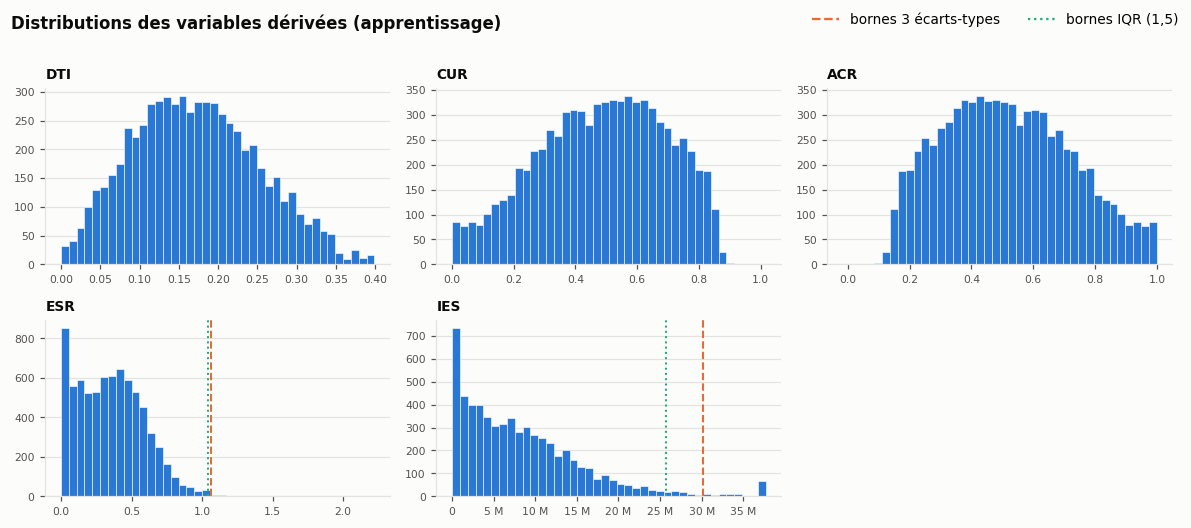

In [61]:
train = fe.add_features(train_capped, train_dq, params)
test = fe.add_features(test_capped, test_dq, params)
shape = ol.distribution_shape(train, fe.DERIVED_COLUMNS)
detection = ol.detection_table(train, y_train, fe.DERIVED_COLUMNS)
save_table(shape, "10_forme_variables_derivees", index=True)
save_table(detection, "10_outliers_variables_derivees")
display(shape)
display(detection[["variable", "méthode", "borne_inf", "borne_sup", "n_outliers", "part", "taux_defaut_outliers"]])
fig = plots_outliers.plot_histograms_with_bounds(
    train, fe.DERIVED_COLUMNS, log_columns=[], title="Distributions des variables dérivées (apprentissage)")
plots.save(fig, FIGURES_DIR / "10_histogrammes_variables_derivees.png");

**Lecture**

- **DTI.** Il varie de 0 à 0,40 (médiane 0,167), avec une distribution presque symétrique (asymétrie 0,25)
  et **aucun outlier** selon l'une ou l'autre méthode. Aucun emprunteur ne consacre plus de 40 % de son
  revenu à sa dette : le portefeuille semble filtré à l'octroi.
- **CUR et ACR.** Ils sont bornés entre 0 et 1, à une exception près (CUR = 1,016, soit un encours
  légèrement supérieur au plafond). Médiane du CUR : 0,50. Aucun outlier.
- **ESR.** Il est majoritairement compris entre 0 et 1 :
  - 671 valeurs nulles (`< 1 year`) ;
  - 57 valeurs supérieures à 1 (emploi plus ancien que le premier crédit, plausible) ;
  - 40 outliers IQR (0,5 %), jusqu'à 2,2. Ces valeurs sont réelles et ne reçoivent aucun traitement.
- **IES.** C'est la seule variable à forte asymétrie (1,4 après plafonnement), comme un montant.
  - Elle est plafonnée au **99ᵉ percentile de l'apprentissage** (37,7 M), règle déjà appliquée aux montants
    en partie 2.
  - 61 valeurs sont plafonnées dans l'apprentissage, 14 dans le test.
  - Les outliers IQR restants (181) sont moins risqués (12,2 % de défaut) : ce sont des valeurs réelles
    (hauts revenus anciens).

Seule l'IES a donc besoin d'un traitement d'outliers. Les ratios, normalisés par construction, n'en ont pas.

## 6. Effet observé sur le défaut : conforme à l'attendu ?

On compare l'effet attendu (section 1) au taux de défaut par **quintile** de chaque variable, ainsi
qu'à la corrélation de Spearman avec le défaut. Ce découpage en quintiles, calculé sur l'apprentissage,
est **descriptif**. La discrétisation retenue pour le modèle, choisie par le T de Tschuprow, sera faite
à l'étape suivante.

,variable,sens_attendu,taux_defaut_1re_classe,taux_defaut_dernière_classe,spearman_avec_défaut,sens_observé,conforme,monotone
0,DTI,+,0.1571,0.2952,0.1085,+,True,True
1,CUR,+,0.1835,0.2745,0.0691,+,True,True
2,ACR,−,0.2745,0.1835,-0.0691,−,True,True
3,ESR,−,0.2317,0.2646,0.0220,+,False,False
4,IES,−,0.2395,0.1602,-0.0576,−,True,False


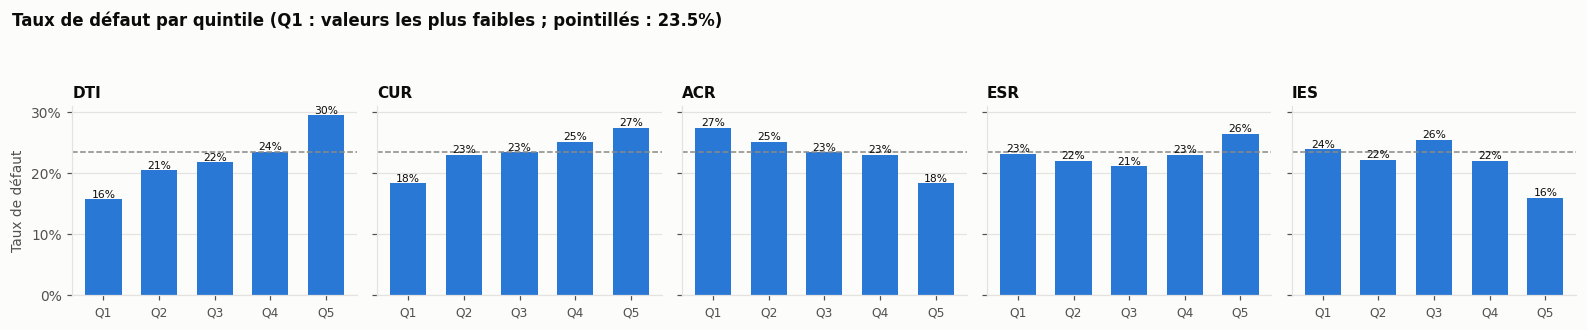

In [62]:
quintiles = {col: fe.default_rate_by_quantile(train, y_train, col) for col in fe.DERIVED_COLUMNS}
comparison = fe.expected_vs_observed(train, y_train)
save_table(pd.concat(quintiles.values(), ignore_index=True).astype({"classe": str}), "10_taux_defaut_quintiles")
save_table(comparison, "10_effet_attendu_observe")
display(comparison)
fig = plots_features.plot_default_rate_by_quantile(quintiles, y_train.mean())
plots.save(fig, FIGURES_DIR / "10_taux_defaut_quintiles.png");

**Lecture**

- **DTI : conforme et monotone.** Le taux de défaut passe de **15,7 %** dans le premier quintile à
  **29,5 %** dans le dernier, avec une progression régulière. C'est la variable dérivée au gradient le
  plus marqué (Spearman 0,11).
- **CUR : conforme et monotone**, de 18,4 % à 27,5 %. **ACR** donne l'image miroir exacte (27,5 % à
  18,4 %), puisque ACR = 1 − CUR.
- **IES : conforme, mais non monotone.** Les quatre premiers quintiles oscillent entre 22 % et 26 % ;
  seul le dernier (revenus élevés et anciens) se détache nettement, à 16,0 %. L'effet est concentré
  sur le haut de la distribution.
- **ESR : non conforme.** Le dernier quintile (ESR > 0,55) est le plus risqué (26,5 %), à l'inverse de
  l'effet attendu. La cellule suivante en cherche l'explication.

In [63]:
history = train_dq["Years of Credit History"]
esr = train["ESR"]
high_esr = esr > esr.quantile(0.8)
esr_analysis = pd.DataFrame({
    "indicateur": ["Spearman(ESR, ancienneté d'emploi)", "Spearman(ESR, ancienneté de crédit)",
                   "Ancienneté de crédit médiane, ESR dans le dernier quintile",
                   "Ancienneté de crédit médiane, autres ESR",
                   "Taux de défaut, 1er quintile d'ancienneté de crédit",
                   "Taux de défaut, dernier quintile d'ancienneté de crédit"],
    "valeur": [esr.corr(job_years, method="spearman"), esr.corr(history, method="spearman"),
               history[high_esr].median(), history[~high_esr & esr.notna()].median(),
               *y_train.groupby(pd.qcut(history, 5), observed=True).mean().iloc[[0, -1]].to_numpy()],
})
display(esr_analysis)
print("Taux de défaut par ancienneté d'emploi :", y_train.groupby(job_years).mean().round(3).to_dict())

,indicateur,valeur
0,"Spearman(ESR, ancienneté d'emploi)",0.8369
1,"Spearman(ESR, ancienneté de crédit)",-0.2200
2,"Ancienneté de crédit médiane, ESR dans le dernier quintile",14.1000
3,"Ancienneté de crédit médiane, autres ESR",18.5000
4,"Taux de défaut, 1er quintile d'ancienneté de crédit",0.2581
5,"Taux de défaut, dernier quintile d'ancienneté de crédit",0.2052


Taux de défaut par ancienneté d'emploi : {0.0: 0.255, 1.0: 0.224, 2.0: 0.24, 3.0: 0.218, 4.0: 0.224, 5.0: 0.224, 6.0: 0.22, 7.0: 0.252, 8.0: 0.23, 9.0: 0.256, 10.0: 0.227}


**Explication de l'effet inattendu de l'ESR**

- **Ce que mesure surtout l'ESR.** Il suit essentiellement l'ancienneté d'emploi (Spearman 0,84).
  Or l'ancienneté d'emploi **n'a pas d'effet net** sur le défaut : son taux de défaut fluctue entre
  22 % et 26 % sans tendance.
- **Ce qui se cache dans les ESR élevés.** Les ESR les plus élevés regroupent surtout des emprunteurs
  au **court historique de crédit** : ancienneté médiane de 14,1 ans dans le dernier quintile d'ESR,
  contre 18,5 ans ailleurs. L'historique court est, lui, un facteur de risque : 25,8 % de défaut dans
  le premier quintile d'ancienneté de crédit contre 20,5 % dans le dernier.
- **Effet de la censure.** Avec la censure à 10 ans, un ESR élevé décrit souvent un emprunteur
  « 10+ years » dont le dénominateur est petit. L'ESR capte donc davantage la **jeunesse du dossier
  de crédit** que la stabilité professionnelle.

**Conséquence.** L'hypothèse économique « emploi stable donc risque faible » n'est pas vérifiée telle
quelle sur ces données. L'ESR est conservé comme candidat, mais son lien avec le défaut est faible
(Spearman 0,02) et non monotone. Son pouvoir discriminant réel sera tranché par l'IV et le V de Cramér
à l'étape de sélection. S'il est retenu, son signe dans le modèle devra être interprété à la lumière
de cette analyse.

## 7. Redondances à surveiller

Les variables dérivées sont construites à partir des variables d'origine. Elles peuvent donc leur
être fortement corrélées. On repère dès maintenant les paires dont la corrélation de Spearman dépasse
le seuil de 0,4 fixé par le sujet. Le choix de la variable à conserver relève de l'étape de sélection
(sujet 1.3.3), à partir des indicateurs de pouvoir discriminant.

,variable_1,variable_2,spearman
0,ACR,CUR,-1.0000
1,ESR,IES,0.6831
2,DTI,Monthly Debt,0.6181
3,Annual Income,IES,0.5609
4,CUR,Current Credit Balance,0.4136
5,ACR,Current Credit Balance,-0.4136


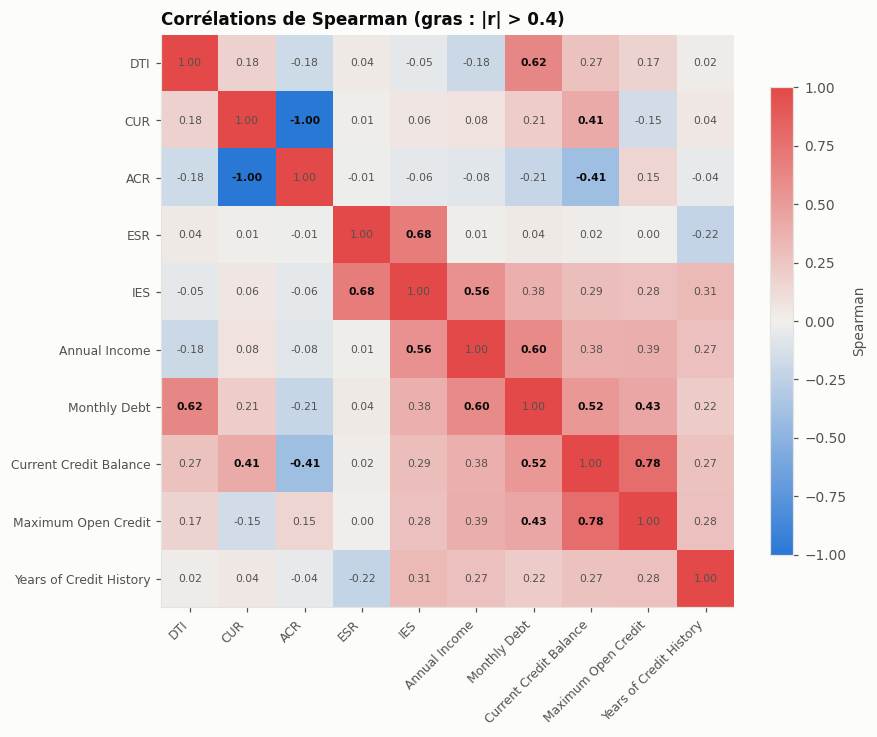

In [64]:
corr_columns = fe.DERIVED_COLUMNS + ["Annual Income", "Monthly Debt", "Current Credit Balance",
                                     "Maximum Open Credit", "Years of Credit History"]
derived = fe.DERIVED_COLUMNS
corr = train[corr_columns].corr(method="spearman")
pairs = (corr.where(lambda c: c.abs() > CORRELATION_THRESHOLD).stack().rename("spearman").reset_index()
         .rename(columns={"level_0": "variable_1", "level_1": "variable_2"})
         .query("variable_1 < variable_2 and (variable_1 in @derived or variable_2 in @derived)")
         .sort_values("spearman", key=abs, ascending=False, ignore_index=True))
save_table(pairs, "10_correlations_fortes")
display(pairs)
fig = plots_features.plot_correlation_heatmap(corr, CORRELATION_THRESHOLD)
plots.save(fig, FIGURES_DIR / "10_correlations_variables_derivees.png");

**Lecture**

- **CUR et ACR : corrélation de −1.** C'est une redondance **parfaite**, due à leur construction.
  Introduire les deux dans une régression logistique rendrait le modèle non identifiable. **Une seule des
  deux sera conservée** à l'étape de sélection.
- **ESR et IES (0,68).** Ils partagent l'ancienneté d'emploi.
- **DTI et Monthly Debt (0,62), IES et Annual Income (0,56).** Une variable dérivée reste liée à sa
  composante principale.
- **CUR et ACR avec Current Credit Balance (±0,41).** Juste au-dessus du seuil : l'encours est le
  numérateur du CUR.

Ces paires seront arbitrées par le pouvoir discriminant (IV, V de Cramér) à l'étape de sélection.

## 8. Export

In [65]:
train.to_csv(PROCESSED_DIR / "train_features.csv", index=False, encoding="utf-8")
test.to_csv(PROCESSED_DIR / "test_features.csv", index=False, encoding="utf-8")
print(f"train_features.csv : {train.shape}, test_features.csv : {test.shape}")
print("Valeurs infinies :", int(pd.DataFrame(train[fe.DERIVED_COLUMNS]).isin([float('inf'), float('-inf')]).sum().sum()))

pct1, int0, num2, num3 = percent(1), number(0), number(2), number(3)
shape_tex = shape.reset_index()[["variable", "n", "moyenne", "médiane", "écart_type", "asymétrie", "min", "P99", "max"]]
latex_exports = {
    "10_definitions_variables_derivees": (definitions, {}, "lp{3.6cm}p{5cm}p{5cm}"),
    "10_deformation_ratios_plafonnement": (
        distortion, {"lignes_modifiées": int0, "écart_relatif_médian": pct1, "écart_relatif_max": pct1}, "lrrr"),
    "10_valeurs_non_definies": (
        undefined, {"n_apprentissage": int0, "part_apprentissage": pct1, "n_test": int0, "part_test": pct1}, "llrrrr"),
    "10_plafond_nul": (zero_limit, {"n": int0, "taux_defaut": pct1}, "lrr"),
    "10_forme_variables_derivees": (
        shape_tex, {"n": int0, "moyenne": num3, "médiane": num3, "écart_type": num3, "asymétrie": num2,
                    "min": num3, "P99": num3, "max": num3}, "lrrrrrrrr"),
    "10_effet_attendu_observe": (
        comparison.drop(columns="monotone"),
        {"taux_defaut_1re_classe": pct1, "taux_defaut_dernière_classe": pct1, "spearman_avec_défaut": num3,
         "conforme": lambda v: "oui" if v else "non"}, "lcrrrcc"),
    "10_correlations_fortes": (pairs, {"spearman": num2}, "llr"),
}
for name, (table, formatters, spec) in latex_exports.items():
    save_latex_table(table, name, formatters, spec)
print(len(latex_exports), "tableaux LaTeX écrits")

train_features.csv : (7861, 22), test_features.csv : (1966, 22)
Valeurs infinies : 0
7 tableaux LaTeX écrits


## 9. Conclusion

| Variable | Divisions par zéro / non définies | Traitement | Effet observé |
|---|---|---|---|
| DTI | Revenu nul : aucun ; revenu manquant : 19,4 % | Ratio brut, aucun outlier | Conforme, monotone (15,7 % → 29,5 %) |
| CUR | Plafond nul : 55 ; plafond erroné : 11 | Non défini → classe dédiée à la discrétisation | Conforme, monotone (18,4 % → 27,5 %) |
| ACR | Idem CUR | Idem CUR ; **redondant avec CUR** (r = −1) | Conforme (miroir de CUR) |
| ESR | Ancienneté de crédit nulle : aucune ; emploi `n/a` : 4,4 % | Ratio brut ; censure de `10+ years` signalée | **Non conforme** : capte la jeunesse du dossier de crédit |
| IES | Revenu ou emploi manquant : 23,0 % | Plafonné au P99 de l'apprentissage | Conforme sur le dernier quintile seulement |

**Étape suivante (sujet 1.2.2–1.2.4).**

- Discrétiser toutes les variables quantitatives, d'origine et dérivées, en classes de quantiles de
  2 à 10, choisies par le T de Tschuprow sur l'apprentissage.
- Gérer les valeurs non définies et les manquants comme classes dédiées, puis appliquer la contrainte
  de 5 %.
- Regrouper les modalités des variables qualitatives.

# Partie 4 — Discrétisation, WoE et IV (sujet 1.2.2–1.2.4)

**Sujet, sections 1.2.2 à 1.2.4 et annexe.**

| Question du sujet | Section du notebook |
|---|---|
| 1.2.2 Discrétisation en 2 à 10 quantiles, Khi² normalisé, T de Tschuprow, choix du T maximal, classes ≥ 5 % | 2 |
| 1.2.3 Variables à grand nombre de modalités : identification et méthode | 1 |
| 1.2.4 Variables qualitatives à plus de 4 modalités : taux de défaut, IV, regroupement | 3 |
| Annexe : WoE et IV | 4 |

**Formules (annexe du sujet).** Pour une classe $i$ :

$$\mathrm{WoE}_i = \ln\frac{\mathrm{Bad}_i/\mathrm{Bad}}{\mathrm{Good}_i/\mathrm{Good}}, \qquad
\mathrm{IV} = \sum_i \left(\frac{\mathrm{Bad}_i}{\mathrm{Bad}} - \frac{\mathrm{Good}_i}{\mathrm{Good}}\right)\mathrm{WoE}_i ,$$

$$T = \sqrt{\frac{\chi^2}{n\sqrt{(r-1)(c-1)}}}, \qquad V = \sqrt{\frac{\chi^2}{n\,\min(r-1,\,c-1)}} .$$

**Correction de signe de l'IV.** L'énoncé écrit le premier facteur de l'IV dans l'ordre
$\mathrm{Good}_i/\mathrm{Good} - \mathrm{Bad}_i/\mathrm{Bad}$. Avec le WoE ci-dessus, chaque terme de la somme
est alors négatif ou nul : l'IV serait toujours ≤ 0, ce qui contredit la table d'interprétation
(IV ≥ 0,02…). On utilise donc la forme positive, qui en est l'opposé exact. Avec cette convention, un
**WoE positif** signale une classe **plus risquée** que la moyenne.

**Règles appliquées (toutes apprises sur l'apprentissage)**

1. **Valeurs manquantes.** Une valeur manquante ou non définie forme une **classe dédiée** (manquant
   informatif, partie 1). Deux exceptions, traitées par imputation :
   - *Current Loan Amount* : sa valeur sentinelle n'est portée que par des non-défauts. Elle est imputée
     par **tirage aléatoire dans la distribution de l'apprentissage**, pour ne créer aucun signal
     artificiel ;
   - *Bankruptcies* : 17 manquants, imputés par le **mode**.
2. **Discrétisation.** Pour chaque k de 2 à 10, les bornes sont les quantiles d'ordre $j/k$ des valeurs
   renseignées.
3. **Représentativité.** Chaque classe doit regrouper au moins **5 % des observations, des défauts et de
   l'encours** (note 2 du sujet ; l'encours est mesuré par *Current Loan Amount*). Une classe trop petite
   est fusionnée avec sa voisine de taux de défaut le plus proche ; la classe « manquant » rejoint la
   classe de taux de défaut le plus proche.
4. **Choix du découpage.** On retient le découpage de **T de Tschuprow maximal**, calculé après
   l'application de la règle des 5 %, c'est-à-dire sur les classes réellement utilisées.

In [66]:
import sys
from pathlib import Path


import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency

from src import binning as bn
from src import pipeline, plots, plots_model
from src.config import FIGURES_DIR
from src.reporting import number, percent, pvalue, save_latex_table, save_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plots.set_style()

prep = pipeline.prepare()
train, y = prep.train, prep.y_train
print(f"Apprentissage : {len(train)} prêts ({y.sum()} défauts) ; test : {len(prep.test)} prêts")
print(f"Imputation : {len(prep.imputation.loan_amount_pool)} montants dans le réservoir hot-deck ; "
      f"mode de Bankruptcies = {prep.imputation.bankruptcies_mode:.0f}")

Apprentissage : 7861 prêts (1845 défauts) ; test : 1966 prêts
Imputation : 7002 montants dans le réservoir hot-deck ; mode de Bankruptcies = 0


## 1. Variables à grand nombre de modalités (sujet 1.2.3)

On compte les valeurs distinctes de chaque variable candidate, sur l'apprentissage, et on indique la
méthode de transformation retenue.

In [67]:
cardinality = pd.DataFrame(
    [{"variable": v, "type": "quantitative" if v in pipeline.NUMERIC_CANDIDATES else "qualitative",
      "valeurs_distinctes": int(train[v].nunique()), "plus_de_10": train[v].nunique() > 10,
      "methode": ("discrétisation en quantiles (T de Tschuprow)" if v in pipeline.NUMERIC_CANDIDATES
                  else "regroupement par niveau de risque")}
     for v in pipeline.NUMERIC_CANDIDATES + list(pipeline.CATEGORICAL_CANDIDATES)]
).sort_values("valeurs_distinctes", ascending=False, ignore_index=True)
save_table(cardinality, "11_cardinalite")
cardinality

,variable,type,valeurs_distinctes,plus_de_10,methode
0,CUR,quantitative,7771,True,discrétisation en quantiles (T de Tschuprow)
1,ACR,quantitative,7771,True,discrétisation en quantiles (T de Tschuprow)
2,Monthly Debt,quantitative,7623,True,discrétisation en quantiles (T de Tschuprow)
3,Maximum Open Credit,quantitative,7193,True,discrétisation en quantiles (T de Tschuprow)
4,Current Credit Balance,quantitative,6796,True,discrétisation en quantiles (T de Tschuprow)
5,DTI,quantitative,6148,True,discrétisation en quantiles (T de Tschuprow)
6,Annual Income,quantitative,5744,True,discrétisation en quantiles (T de Tschuprow)
7,Current Loan Amount,quantitative,5682,True,discrétisation en quantiles (T de Tschuprow)
8,IES,quantitative,5310,True,discrétisation en quantiles (T de Tschuprow)
9,ESR,quantitative,1440,True,discrétisation en quantiles (T de Tschuprow)


**Lecture.**

- **Variables quantitatives.** Toutes sauf deux ont plus de 10 valeurs distinctes : jusqu'à 7 771 pour
  CUR, 42 pour *Number of Open Accounts*. Une variable continue ne peut pas entrer telle quelle dans
  une grille de score : une modalité par valeur rendrait le modèle impossible à estimer et à
  interpréter. Elles sont donc **discrétisées en classes de quantiles**.
- **Comptages rares.** *Number of Credit Problems* (8 valeurs) et *Bankruptcies* (6 valeurs) suivent la
  même procédure. Leurs quantiles sont presque tous égaux à 0, si bien qu'elles se réduisent à
  « 0 » contre « au moins 1 ».
- **Variables qualitatives.** *Purpose* (12 modalités après l'harmonisation de la partie 1) et
  *Years in current job* (11 modalités et `n/a`) dépassent 10 modalités. Elles sont **regroupées par
  niveau de risque** (section 3). *Home Ownership* (3 modalités) et *Term* (2) passent par la même
  procédure, qui contrôle la représentativité des classes.

## 2. Discrétisation des variables quantitatives (sujet 1.2.2)

Pour chaque variable et chaque k de 2 à 10, le tableau donne :

- le nombre d'atomes, c'est-à-dire de classes de quantiles distinctes, classe « manquant » comprise ;
- le $\chi^2$, le $\chi^2$ normalisé ($\chi^2/n$) et le T de Tschuprow, **avant** application de la règle des 5 % ;
- le nombre de classes et le T **après** application de cette règle ;
- le découpage retenu.

,k_quantiles,n_atomes,chi2,chi2_normalise,tschuprow_t,n_classes_finales,tschuprow_t_final,cramer_v_final,retenu,variable
9,2,3,47.3382,0.0060,0.0653,3,0.0653,0.0776,False,Credit Score
10,3,4,88.7860,0.0113,0.0808,4,0.0808,0.1063,False,Credit Score
11,4,5,124.5875,0.0158,0.0890,5,0.0890,0.1259,False,Credit Score
12,5,6,137.4980,0.0175,0.0884,6,0.0884,0.1323,False,Credit Score
13,6,7,155.5220,0.0198,0.0899,7,0.0899,0.1407,True,Credit Score
14,7,8,162.2371,0.0206,0.0883,8,0.0883,0.1437,False,Credit Score
15,8,9,162.1165,0.0206,0.0854,8,0.0851,0.1384,False,Credit Score
16,9,10,187.6621,0.0239,0.0892,9,0.0887,0.1491,False,Credit Score
17,10,11,166.4665,0.0212,0.0818,10,0.0813,0.1409,False,Credit Score
99,2,3,71.2548,0.0091,0.0801,3,0.0801,0.0952,False,DTI


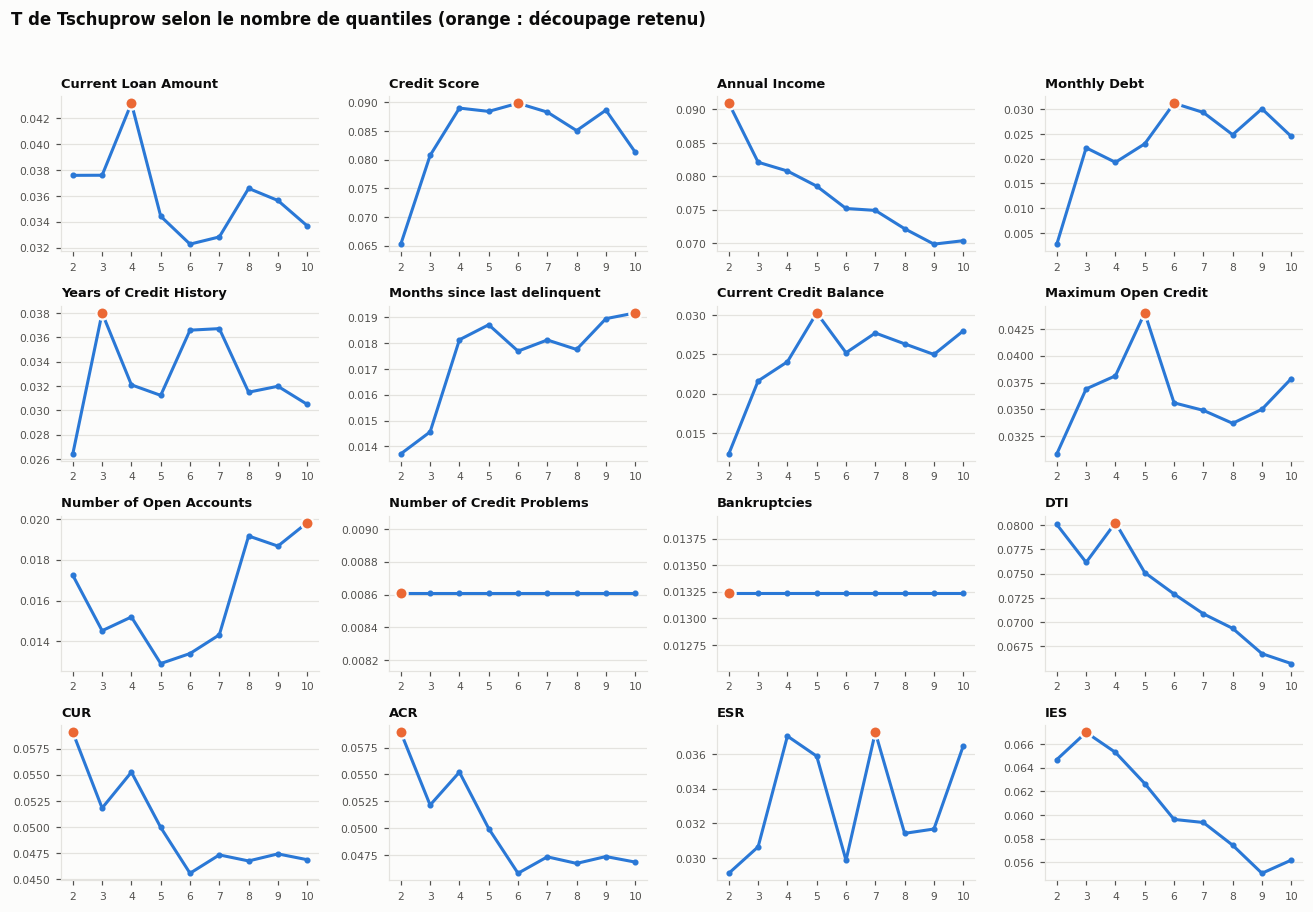

In [68]:
candidates = prep.candidates
save_table(candidates, "11_decoupages_candidats")
display(candidates[candidates["variable"].isin(["Credit Score", "DTI"])])
fig = plots_model.plot_tschuprow_by_k(candidates, pipeline.NUMERIC_CANDIDATES)
plots.save(fig, FIGURES_DIR / "11_tschuprow_par_k.png");

In [69]:
retained = candidates[candidates["retenu"]].set_index("variable")
binning_summary = pd.DataFrame([
    {"variable": v, "k_retenu": int(retained.loc[v, "k_quantiles"]), "n_atomes": int(retained.loc[v, "n_atomes"]),
     "n_classes": len(prep.specs[v].order), "tschuprow_t": retained.loc[v, "tschuprow_t_final"],
     "chi2_normalise": retained.loc[v, "chi2_normalise"],
     "part_min_obs": prep.classes_train[v].value_counts(normalize=True).min(),
     "part_min_defauts": prep.classes_train.loc[y == 1, v].value_counts(normalize=True).min(),
     "classes": " | ".join(prep.specs[v].order)}
    for v in pipeline.NUMERIC_CANDIDATES])
save_table(binning_summary, "11_decoupages_retenus")
binning_summary

,variable,k_retenu,n_atomes,n_classes,tschuprow_t,chi2_normalise,part_min_obs,part_min_defauts,classes
0,Current Loan Amount,4,4,4,0.0432,0.0032,0.2496,0.2065,]-inf ; 172 260] | ]172 260 ; 267 542] | ]267 542 ; 434 126] | ]434 126 ; +inf]
1,Credit Score,6,7,7,0.0899,0.0198,0.1261,0.0650,]-inf ; 692] | ]692 ; 711] | ]711 ; 723] | ]723 ; 734] | ]734 ; 742] | ]742 ; +inf] | Manquant
2,Annual Income,2,3,3,0.0909,0.0117,0.1945,0.2374,]-inf ; 1 166 543] | ]1 166 543 ; +inf] | Manquant
3,Monthly Debt,6,6,6,0.0312,0.0022,0.1666,0.1463,]-inf ; 7 836] | ]7 836 ; 12 068] | ]12 068 ; 16 046] | ]16 046 ; 20 838] | ]20 838 ; 27 976] | ]27 976 ; ...
4,Years of Credit History,3,3,3,0.0380,0.0020,0.3300,0.2916,]-inf ; 14.8] | ]14.8 ; 19.9] | ]19.9 ; +inf]
5,Months since last delinquent,10,11,7,0.0192,0.0012,0.0502,0.0509,]-inf ; 8] | ]8 ; 14] | ]14 ; 32] | ]32 ; 40] | ]40 ; 57] | ]57 ; +inf] | Aucun retard
6,Current Credit Balance,5,5,5,0.0303,0.0018,0.2000,0.1767,]-inf ; 92 169] | ]92 169 ; 164 483] | ]164 483 ; 258 210] | ]258 210 ; 416 404] | ]416 404 ; +inf]
7,Maximum Open Credit,5,5,5,0.0440,0.0039,0.2000,0.1566,]-inf ; 234 850] | ]234 850 ; 376 090] | ]376 090 ; 566 126] | ]566 126 ; 876 920] | ]876 920 ; +inf]
8,Number of Open Accounts,10,10,10,0.0198,0.0012,0.0636,0.0547,]-inf ; 6] | ]6 ; 7] | ]7 ; 8] | ]8 ; 9] | ]9 ; 10] | ]10 ; 11] | ]11 ; 13] | ]13 ; 15] | ]15 ; 17] | ]17 ...
9,Number of Credit Problems,2,2,2,0.0086,0.0001,0.1448,0.1393,]-inf ; 0] | ]0 ; +inf]


**Lecture : pourquoi le T de Tschuprow, et pourquoi pas le $\chi^2$ seul ?**

- **Le $\chi^2$ augmente presque mécaniquement avec le nombre de classes.** Pour *Credit Score*, il passe
  de 47 (k = 2) à 188 (k = 9). Le choisir comme critère pousserait toujours vers le découpage le plus fin,
  donc vers des classes instables.
- **Le T de Tschuprow corrige cet effet.** Il divise le $\chi^2$ par $\sqrt{r-1}$, ce qui pénalise les
  découpages fins. Il ne retient un découpage plus fin que si le gain d'association compense ce coût.
  Pour *Credit Score*, il culmine à **0,0899 pour k = 6**, soit 7 classes avec la classe « Manquant ».
  C'est ce découpage qui offre la meilleure association avec le défaut **par degré de liberté**.
- **Le découpage retenu varie selon la forme de la relation avec le défaut.**
  - *Annual Income* : k = 2. Une seule coupure à la médiane, plus la classe « Manquant », capte
    l'essentiel du signal.
  - *DTI* : k = 4, soit 4 classes de 20 % et la classe « Manquant ».
  - *Months since last delinquent* et *Number of Open Accounts* : k = 10. Leur T reste faible
    (0,019 et 0,020) : la relation est diffuse, sans palier marqué.
- **Règle des 5 %.** Elle est respectée partout : la part minimale d'une classe est de 5,0 % des
  observations et 5,1 % des défauts (*Months since last delinquent*). Elle a fusionné deux classes
  « non définies », trop petites, avec la classe de risque la plus proche :
  - pour CUR, « Sans plafond » (0,8 %) rejoint la classe des faibles utilisations ;
  - pour *Months since last delinquent* (k = 10), des classes de quantiles sont regroupées, ce qui
    ramène 11 atomes à 7 classes.
- **Monotonie.** Les WoE ne sont pas toujours monotones. Pour *Credit Score*, la classe ]723 ; 734] est
  plus risquée que ses voisines (figure de la section 4). Le sujet n'impose pas la monotonie ; ces
  irrégularités, de faible amplitude, relèvent probablement du bruit d'échantillonnage. Leur stabilité
  est examinée en partie 5.

## 3. Regroupement des variables qualitatives (sujet 1.2.4)

On identifie d'abord les variables qualitatives à plus de 4 modalités, puis on calcule pour chaque
modalité d'origine son effectif, son taux de défaut, son WoE et sa contribution à l'IV.

In [70]:
qualitative = list(pipeline.CATEGORICAL_CANDIDATES)
n_modalities = {v: int(bn.categorical_atoms(train[v]).nunique()) for v in qualitative}
print("Modalités (manquant compris) :", n_modalities)
many = [v for v, n in n_modalities.items() if n > 4]
print("Variables à plus de 4 modalités :", many)
raw_tables = {v: bn.woe_table(bn.categorical_atoms(train[v], pipeline.SPECIAL_LABELS.get(v, bn.SPECIAL)), y)
              .sort_values("taux_defaut", ignore_index=True) for v in qualitative}
for v in many:
    save_table(raw_tables[v], f"11_modalites_{v.lower().replace(' ', '_')}")
    print(f"\n{v} : IV avant regroupement = {raw_tables[v]['iv_classe'].sum():.4f}")
    display(raw_tables[v][["classe", "n", "part", "bad", "taux_defaut", "woe", "iv_classe"]])

Modalités (manquant compris) : {'Term': 2, 'Home Ownership': 3, 'Purpose': 12, 'Years in current job': 12}
Variables à plus de 4 modalités : ['Purpose', 'Years in current job']

Purpose : IV avant regroupement = 0.0086


y,classe,n,part,bad,taux_defaut,woe,iv_classe
0,Buy a Car,98,0.0125,15,0.1531,-0.5288,0.0030
1,Wedding,6,0.0008,1,0.1667,-0.4275,0.0001
2,Major Purchase,32,0.0041,6,0.1875,-0.2844,0.0003
3,Medical Bills,85,0.0108,18,0.2118,-0.1324,0.0002
4,Home Improvements,443,0.0564,95,0.2144,-0.1164,0.0007
5,Other,715,0.0910,158,0.2210,-0.0780,0.0005
6,Take a Trip,60,0.0076,14,0.2333,-0.0076,0.0000
7,Debt Consolidation,6220,0.7912,1480,0.2379,0.0179,0.0003
8,Buy House,53,0.0067,13,0.2453,0.0580,0.0000
9,Business Loan,130,0.0165,37,0.2846,0.2603,0.0012



Years in current job : IV avant regroupement = 0.0100


y,classe,n,part,bad,taux_defaut,woe,iv_classe
0,3 years,602,0.0766,131,0.2176,-0.0977,0.0007
1,6 years,492,0.0626,108,0.2195,-0.0866,0.0005
2,1 year,482,0.0613,108,0.2241,-0.0602,0.0002
3,4 years,508,0.0646,114,0.2244,-0.0582,0.0002
4,5 years,508,0.0646,114,0.2244,-0.0582,0.0002
5,10+ years,2450,0.3117,556,0.2269,-0.0437,0.0006
6,8 years,344,0.0438,79,0.2297,-0.0283,0.0000
7,2 years,704,0.0896,169,0.2401,0.0296,0.0001
8,7 years,437,0.0556,110,0.2517,0.0925,0.0005
9,< 1 year,671,0.0854,171,0.2548,0.1090,0.0010


**Méthode de regroupement**

1. **Ordre des modalités.** Pour une variable nominale, les modalités sont rangées par taux de défaut
   croissant. Pour une variable ordinale (*Years in current job*), on garde l'ordre naturel de
   l'ancienneté.
2. **Représentativité.** Une modalité qui ne représente pas 5 % des observations, des défauts et de
   l'encours est fusionnée avec sa voisine de taux de défaut le plus proche.
3. **Profils distincts.** Deux classes voisines dont les taux de défaut ne diffèrent pas
   significativement (test du $\chi^2$ 2 × 2, seuil 5 %) sont fusionnées, en commençant par la paire la
   moins significative.

In [71]:
grouping = []
for v in qualitative:
    table = bn.woe_table(prep.classes_train[v], y, prep.specs[v].order)
    for _, r in table.iterrows():
        grouping.append({"variable": v, "classe": r["classe"], "n": r["n"], "part": r["part"],
                         "part_defauts": r["dist_bad"], "taux_defaut": r["taux_defaut"], "woe": r["woe"]})
grouping = pd.DataFrame(grouping)
adjacent_tests = []
for v in qualitative:
    order = list(prep.specs[v].order)
    for a, b in zip(order[:-1], order[1:]):
        mask = prep.classes_train[v].isin([a, b])
        adjacent_tests.append({"variable": v, "classe_1": a, "classe_2": b,
                               "p_value": chi2_contingency(bn.contingency(prep.classes_train.loc[mask, v], y[mask]),
                                                              correction=False)[1]})
adjacent_tests = pd.DataFrame(adjacent_tests)
save_table(grouping, "11_regroupements_qualitatives")
save_table(adjacent_tests, "11_tests_classes_voisines")
display(grouping)
adjacent_tests

,variable,classe,n,part,part_defauts,taux_defaut,woe
0,Term,Short Term,5647,0.7184,0.6195,0.2024,-0.1894
1,Term,Long Term,2214,0.2816,0.3805,0.3171,0.4147
2,Home Ownership,Home Mortgage,3847,0.4894,0.4374,0.2098,-0.1443
3,Home Ownership,Own Home + Rent,4014,0.5106,0.5626,0.2586,0.1287
4,Purpose,Buy a Car + Wedding + Major Purchase + Medical Bills + Home Improvements + Other,1379,0.1754,0.1588,0.2125,-0.1281
5,Purpose,Take a Trip + Debt Consolidation + Buy House + Business Loan + Moving + Educational Expenses,6482,0.8246,0.8412,0.2394,0.0261
6,Years in current job,< 1 year + 1 year + 2 years + 3 years + 4 years + 5 years + 6 years + 7 years + 8 years,4748,0.6040,0.5984,0.2325,-0.0122
7,Years in current job,9 years + Non renseigné,663,0.0843,0.1003,0.2790,0.2327
8,Years in current job,10+ years,2450,0.3117,0.3014,0.2269,-0.0437


,variable,classe_1,classe_2,p_value
0,Term,Short Term,Long Term,0.0000
1,Home Ownership,Home Mortgage,Own Home + Rent,0.0000
2,Purpose,Buy a Car + Wedding + Major Purchase + Medical Bills + Home Improvements + Other,Take a Trip + Debt Consolidation + Buy House + Business Loan + Moving + Educational Expenses,0.0319
3,Years in current job,< 1 year + 1 year + 2 years + 3 years + 4 years + 5 years + 6 years + 7 years + 8 years,9 years + Non renseigné,0.0084
4,Years in current job,9 years + Non renseigné,10+ years,0.0052


**Lecture**

- **Purpose.**
  - Les taux de défaut des modalités vont de 15,3 % (*Buy a Car*) à 45,5 % (*Educational Expenses*).
    Mais les modalités extrêmes ont des effectifs minuscules (11 et 8 prêts pour *Educational
    Expenses* et *Moving*), et *Debt Consolidation* représente à elle seule 79 % des prêts.
  - Après fusion des petites modalités puis des voisines non significativement différentes, il reste
    **2 classes** :
    - les motifs « de consommation planifiée » (voiture, mariage, achat important, frais médicaux,
      travaux, autre) : 17,5 % des prêts, 21,2 % de défaut ;
    - les autres, dont *Debt Consolidation* et *Business Loan* : 23,9 % de défaut.
  - La différence est significative (p = 0,032). L'IV passe de 0,0086 à 0,0033 : la perte d'IV
    provient des modalités minuscules, dont les WoE extrêmes n'étaient pas fiables.
- **Years in current job.**
  - Aucune progression du risque avec l'ancienneté. Seule la modalité `n/a` se distingue (30,0 %
    de défaut). Représentant 4,4 % des prêts (< 5 %), elle est fusionnée avec la modalité de taux le
    plus proche (*9 years*).
  - Il reste **3 classes** : moins de 9 ans (23,3 %), « 9 ans ou non renseigné » (27,9 %) et
    « 10 ans et plus » (22,7 %). Les différences entre classes voisines sont significatives
    (p = 0,008 et p = 0,005).
  - Le regroupement « 9 ans + non renseigné » n'a pas de sens économique propre : il est dicté par
    les données, et son pouvoir discriminant reste très faible (IV 0,0055).
- **Home Ownership.** *Own Home* et *Rent* sont regroupés (25,9 % contre 21,0 % pour *Home Mortgage*,
  p < 0,001) : être propriétaire d'un bien financé à crédit est associé au risque le plus faible.
- **Term.** Les deux modalités restent séparées : 31,7 % de défaut pour les prêts longs contre
  20,2 % pour les prêts courts.

## 4. WoE et IV de toutes les variables candidates

Les WoE et IV sont calculés sur l'apprentissage, avec les classes retenues. Le V de Cramér avec la cible
est donné pour comparaison ; l'analyse détaillée de la sélection fait l'objet de la partie 5.

,variable,n_classes,iv,pouvoir,tschuprow_t,cramer_v
0,Credit Score,7,0.1210,moyen,0.0899,0.1407
1,Term,2,0.0780,faible,0.1217,0.1217
2,DTI,5,0.0740,faible,0.0802,0.1135
3,Annual Income,3,0.0673,faible,0.0909,0.1081
4,IES,4,0.0443,faible,0.0670,0.0881
5,Maximum Open Credit,5,0.0228,faible,0.0440,0.0622
6,CUR,2,0.0195,non prédictive,0.0591,0.0591
7,ACR,2,0.0194,non prédictive,0.0589,0.0589
8,Current Loan Amount,4,0.0188,non prédictive,0.0432,0.0568
9,ESR,7,0.0187,non prédictive,0.0373,0.0583


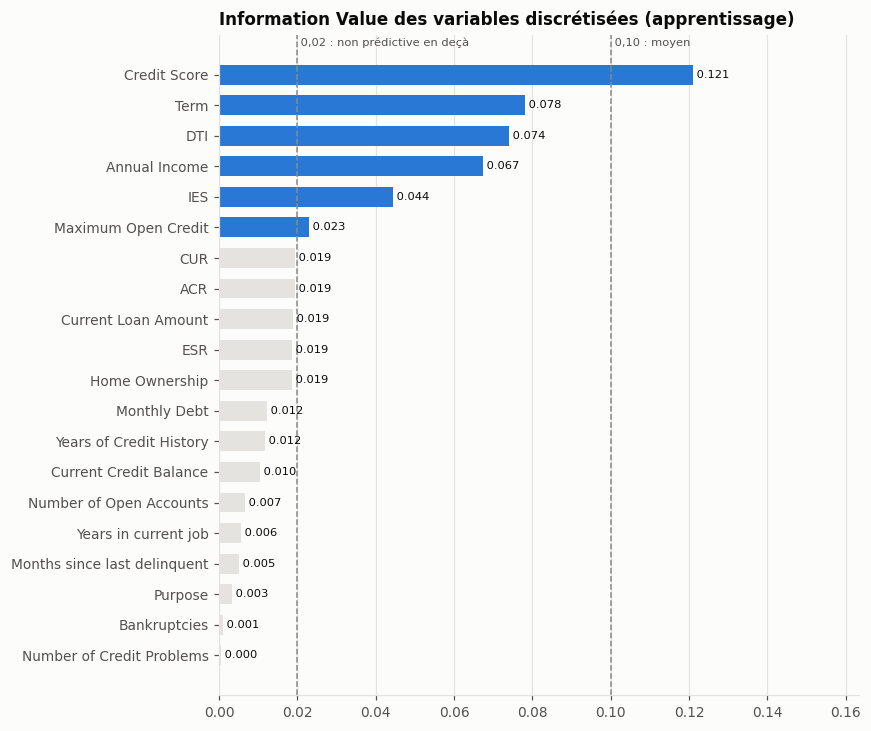

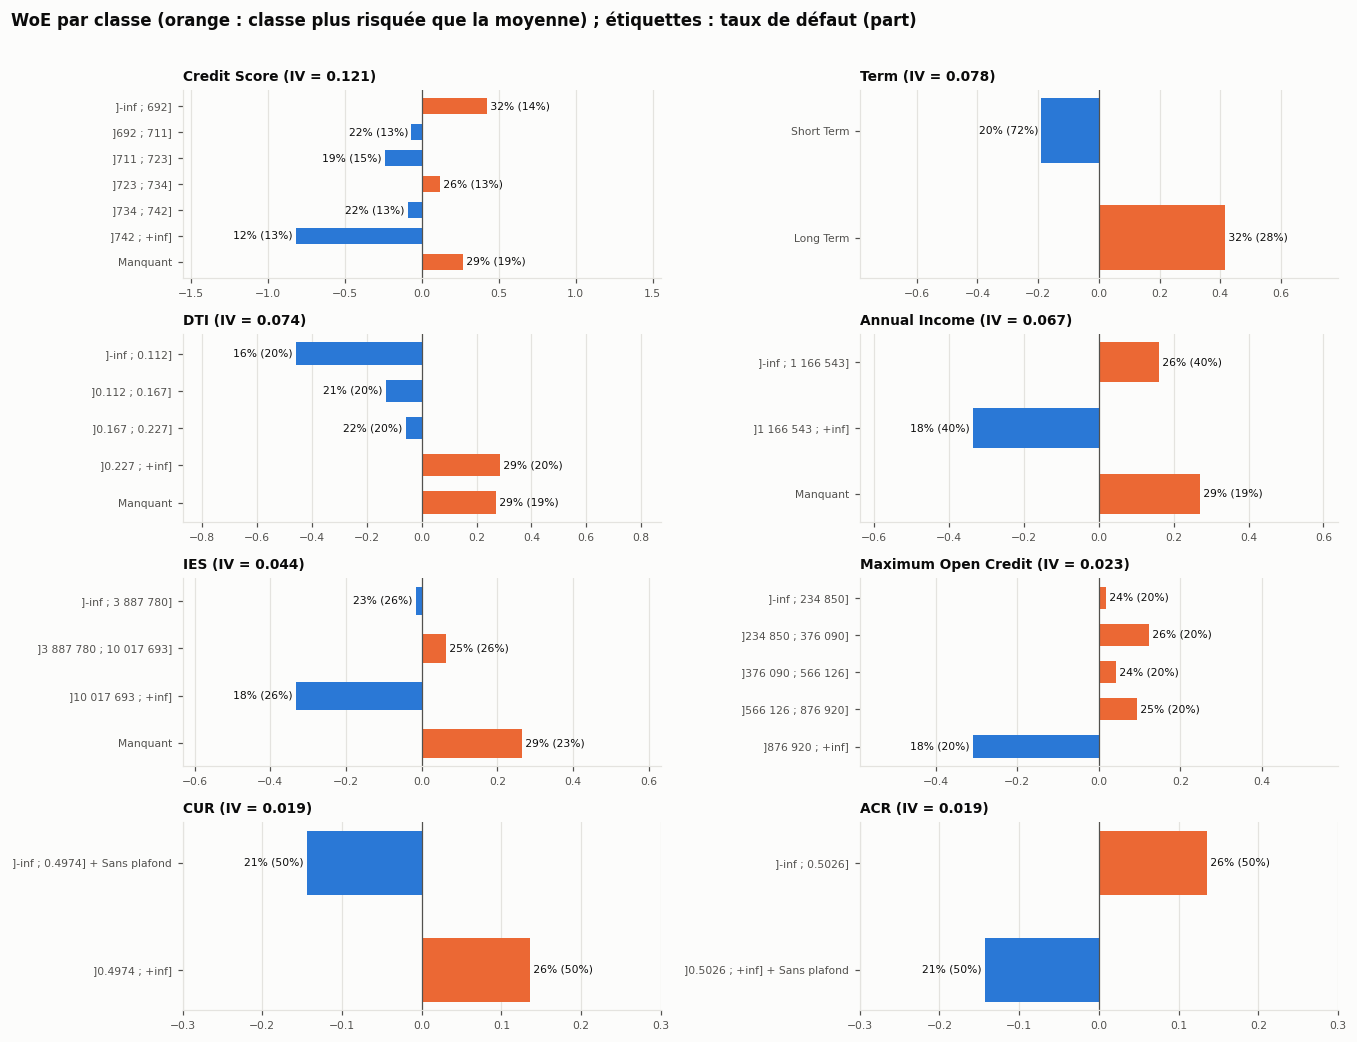

In [72]:
woe_tables = {v: bn.woe_table(prep.classes_train[v], y, prep.specs[v].order) for v in prep.specs}
all_woe = pd.concat([t.assign(variable=v) for v, t in woe_tables.items()], ignore_index=True)
save_table(all_woe, "11_woe_toutes_variables")
iv_summary = bn.iv_summary(prep.classes_train, y)
save_table(iv_summary, "11_iv_synthese")
display(iv_summary)
fig = plots_model.plot_iv_ranking(iv_summary)
plots.save(fig, FIGURES_DIR / "11_iv_variables.png")
top = iv_summary["variable"].head(8).tolist()
fig = plots_model.plot_woe_profiles({v: woe_tables[v] for v in top})
plots.save(fig, FIGURES_DIR / "11_woe_profils.png");

**Lecture des IV (table d'interprétation de l'annexe)**

- **Pouvoir discriminant moyen** (0,10 ≤ IV < 0,30) : *Credit Score* seul (IV 0,121). Sa classe la plus
  basse (score ≤ 692) a 31,9 % de défaut, la plus haute (> 742) 11,9 %.
- **Pouvoir faible** (0,02 ≤ IV < 0,10) : *Term* (0,078), *DTI* (0,074), *Annual Income* (0,067),
  *IES* (0,044) et *Maximum Open Credit* (0,023).
- **IV < 0,02** : les 14 autres variables. Quatre sont juste sous le seuil : CUR (0,0195), ACR (0,0194),
  *Current Loan Amount* (0,0188) et ESR (0,0187).
- **Aucune variable n'atteint 0,5.** Il n'y a donc pas de signe de fuite d'information. C'est le
  résultat attendu après la neutralisation, en partie 1, de la valeur sentinelle du montant et du
  *Credit Score* ×10, qui auraient produit des IV artificiellement très élevés.

**Lecture des profils de WoE.** Les WoE confirment les effets économiques attendus :

- score bas, prêt long, DTI élevé, faible revenu → WoE positif (plus de risque) ;
- plafond de crédit élevé → WoE négatif.

La classe « Manquant » de *Credit Score*, *Annual Income* et *DTI* a le même WoE (+0,27) : ce sont les
**mêmes 1 529 prêts**, dont le revenu et le score n'ont pas été collectés. La classe « Manquant » de
l'IES (1 806 prêts) les contient aussi. Cette redondance est
traitée en partie 5.

**Conclusion.** Le portefeuille est **faiblement discriminable** avec les variables disponibles. Le
modèle final aura un pouvoir de discrimination modeste, et la sélection devra examiner aussi les
variables à IV faible mais significatif.

## 5. Application à l'échantillon de test

Les règles apprises (bornes, regroupements, WoE) sont appliquées **telles quelles** au test. On vérifie :

- qu'aucune observation du test ne reste sans classe ;
- que les parts des classes y restent proches de celles de l'apprentissage. La comparaison formelle, par
  le PSI, est faite en partie 6 (sujet 1.4.1).

In [73]:
missing_classes = int(prep.classes_test.isna().sum().sum())
gap = pd.DataFrame({v: (prep.classes_test[v].value_counts(normalize=True)
                        - prep.classes_train[v].value_counts(normalize=True)).abs().max()
                    for v in prep.specs}, index=["ecart_max_part"]).T
print(f"Observations du test sans classe : {missing_classes}")
print(f"Plus grand écart de part d'une classe entre apprentissage et test : {gap['ecart_max_part'].max():.2%} "
      f"({gap['ecart_max_part'].idxmax()})")

Observations du test sans classe : 0
Plus grand écart de part d'une classe entre apprentissage et test : 2.70% (Years of Credit History)


In [74]:
pct1, int0, num3, num4 = percent(1), number(0), number(3), number(4)
save_latex_table(binning_summary[["variable", "k_retenu", "n_classes", "chi2_normalise", "tschuprow_t",
                                  "part_min_obs", "part_min_defauts"]], "11_decoupages_retenus",
                 {"k_retenu": int0, "n_classes": int0, "chi2_normalise": num4, "tschuprow_t": num4,
                  "part_min_obs": pct1, "part_min_defauts": pct1}, "lrrrrrr")
save_latex_table(candidates.loc[candidates["variable"] == "Credit Score",
                                ["k_quantiles", "n_atomes", "chi2", "chi2_normalise", "tschuprow_t",
                                 "n_classes_finales", "tschuprow_t_final"]], "11_candidats_credit_score",
                 {"k_quantiles": int0, "n_atomes": int0, "chi2": number(1), "chi2_normalise": num4,
                  "tschuprow_t": num4, "n_classes_finales": int0, "tschuprow_t_final": num4}, "rrrrrrr")
save_latex_table(grouping, "11_regroupements_qualitatives",
                 {"n": int0, "part": pct1, "part_defauts": pct1, "taux_defaut": pct1, "woe": num3}, "lp{6.5cm}rrrrr")
save_latex_table(iv_summary, "11_iv_synthese",
                 {"n_classes": int0, "iv": num4, "tschuprow_t": num4, "cramer_v": num4}, "lrrlrr")
for v in ["Credit Score", "DTI", "Term"]:
    save_latex_table(woe_tables[v][["classe", "n", "part", "taux_defaut", "woe", "iv_classe"]],
                     f"11_woe_{v.lower().replace(' ', '_')}",
                     {"n": int0, "part": pct1, "taux_defaut": pct1, "woe": num3, "iv_classe": num4}, "lrrrrr")
print("Tableaux LaTeX écrits.")

Tableaux LaTeX écrits.


## Conclusion

- **Variables quantitatives.** Les 16 variables quantitatives sont discrétisées en 2 à 10 classes. Le
  découpage retenu est celui qui maximise le T de Tschuprow, sous la contrainte de 5 % d'observations,
  de défauts et d'encours par classe.
- **Variables qualitatives.** Les 4 variables qualitatives sont regroupées en 2 ou 3 classes de risque
  significativement distinctes.
- **Classes « manquant ».** Elles sont conservées comme classes à part entière quand elles sont
  représentatives : *Credit Score*, *Annual Income*, *DTI*, *IES* et *Months since last delinquent*.
  Sinon, elles sont fusionnées avec la classe de risque la plus proche.
- **Pouvoir discriminant.** Les IV vont de 0,0004 à 0,121 : seul *Credit Score* atteint un pouvoir
  moyen.
- **Application au test.** Toutes les observations du test reçoivent une classe. La part d'une classe
  ne diffère jamais de plus de 2,7 points entre apprentissage et test.

**Étape suivante (partie 5)** : stabilité par bootstrap et PSI, V de Cramér, corrélations, puis
constitution du jeu final de variables.

# Partie 5 — Sélection des variables (sujet 1.3)

**Sujet, section 1.3.**

| Question du sujet | Section du notebook |
|---|---|
| 1.3.1 Stabilité : 4 échantillons bootstrap, taux de défaut, WoE et IV par échantillon, matrice des PSI | 1 |
| 1.3.2 V de Cramér avec la cible, comparaison avec l'IV, faible pouvoir discriminant | 2 |
| 1.3.3 Corrélations, groupes \|V\| > 0,4, jeu final justifié | 3 et 4 |

**PSI (annexe) et correction de signe.** L'énoncé définit le PSI par $\sum_i (P_i - Q_i)\ln(Q_i/P_i)$.
Chaque terme de cette somme est négatif ou nul : le PSI serait toujours ≤ 0, ce qui contredit les
seuils d'interprétation (0,10 et 0,25). On utilise la forme positive

$$\mathrm{PSI} = \sum_i (Q_i - P_i)\,\ln\frac{Q_i}{P_i},$$

qui en est l'opposé exact et qui est symétrique en $P$ et $Q$. Une classe vide reçoit une proportion
plancher de $10^{-4}$.

Toutes les analyses portent sur **l'échantillon d'apprentissage**. Les classes et les WoE sont ceux du
partie 4.

In [75]:
import sys
from pathlib import Path


import pandas as pd
from IPython.display import display

from src import binning as bn
from src import pipeline, plots, plots_model
from src import selection as sl
from src.config import FIGURES_DIR, RANDOM_STATE
from src.reporting import number, percent, pvalue, save_latex_table, save_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plots.set_style()

prep = pipeline.prepare()
classes, y, specs = prep.classes_train, prep.y_train, prep.specs
iv = bn.iv_summary(classes, y).set_index("variable")["iv"]
print(f"{classes.shape[1]} variables candidates, {len(classes)} prêts d'apprentissage")

20 variables candidates, 7861 prêts d'apprentissage


## 1. Stabilité des variables : 4 échantillons bootstrap (sujet 1.3.1)

Quatre échantillons de même taille que l'apprentissage sont tirés **avec remise** dans l'apprentissage
(`random_state = 42`). Pour chaque variable et chaque échantillon, on calcule, avec les classes du
partie 4 :

- la part de chaque classe ;
- son taux de défaut ;
- son WoE ;
- l'IV de la variable.

In [76]:
samples = sl.bootstrap_indices(len(classes), n_samples=4, random_state=RANDOM_STATE)
boot = sl.bootstrap_woe(classes, y, specs, samples)
save_table(boot, "12_bootstrap_woe_par_classe")
iv_by_sample = boot.groupby(["variable", "echantillon"])["iv"].first().unstack()
iv_by_sample.columns = [f"IV échantillon {c}" for c in iv_by_sample.columns]
iv_by_sample = iv_by_sample.assign(**{"IV apprentissage": iv}).loc[iv.index]
save_table(iv_by_sample, "12_bootstrap_iv", index=True)
display(iv_by_sample)
print("Exemple : Credit Score, taux de défaut et WoE par classe dans les 4 échantillons")
example = boot[boot["variable"] == "Credit Score"].pivot(index="classe", columns="echantillon",
                                                          values=["taux_defaut", "woe"])
display(example.loc[list(specs["Credit Score"].order)])

,IV échantillon 1,IV échantillon 2,IV échantillon 3,IV échantillon 4,IV apprentissage
variable,,,,,
Credit Score,0.1071,0.1578,0.1284,0.1504,0.1210
Term,0.0763,0.0710,0.0803,0.0860,0.0780
DTI,0.0684,0.0854,0.0688,0.0999,0.0740
Annual Income,0.0695,0.0872,0.0765,0.0679,0.0673
IES,0.0530,0.0605,0.0376,0.0310,0.0443
Maximum Open Credit,0.0162,0.0365,0.0250,0.0277,0.0228
CUR,0.0162,0.0319,0.0200,0.0241,0.0195
ACR,0.0160,0.0317,0.0199,0.0241,0.0194
Current Loan Amount,0.0189,0.0221,0.0055,0.0284,0.0188


Exemple : Credit Score, taux de défaut et WoE par classe dans les 4 échantillons


taux_defaut                          woe                        
echantillon            1      2      3      4       1       2       3       4
classe                                                                       
]-inf ; 692]      0.3169 0.3367 0.3295 0.3327  0.4445  0.4697  0.4644  0.4747
]692 ; 711]       0.2235 0.2397 0.2253 0.2289 -0.0326 -0.0068 -0.0601 -0.0437
]711 ; 723]       0.1811 0.1962 0.2171 0.1925 -0.2961 -0.2626 -0.1080 -0.2630
]723 ; 734]       0.2575 0.2503 0.2635 0.2592  0.1536  0.0503  0.1472  0.1205
]734 ; 742]       0.2112 0.2099 0.2090 0.2081 -0.1051 -0.1780 -0.1563 -0.1658
]742 ; +inf]      0.1303 0.1132 0.1129 0.1074 -0.6856 -0.9107 -0.8869 -0.9473
Manquant          0.2676 0.3097 0.2797 0.2948  0.2057  0.3460  0.2288  0.2985

### 1.1 Matrice des PSI

Pour chaque variable, on compare deux à deux les distributions des classes dans les 4 échantillons :
6 paires, présentées comme la table 2 du sujet.

,1 vs 2,1 vs 3,1 vs 4,2 vs 3,2 vs 4,3 vs 4,psi_max,statut
variable,,,,,,,,
Credit Score,0.0005,0.0022,0.0023,0.0029,0.0025,0.0018,0.0029,stable
Term,0.0001,0.0003,0.0012,0.0000,0.0006,0.0003,0.0012,stable
DTI,0.0004,0.0005,0.0001,0.0009,0.0003,0.0007,0.0009,stable
Annual Income,0.0003,0.0004,0.0001,0.0006,0.0001,0.0006,0.0006,stable
IES,0.0005,0.0009,0.0001,0.0016,0.0011,0.0008,0.0016,stable
Maximum Open Credit,0.0018,0.0002,0.0002,0.0013,0.0014,0.0001,0.0018,stable
CUR,0.0001,0.0000,0.0000,0.0002,0.0001,0.0000,0.0002,stable
ACR,0.0001,0.0000,0.0000,0.0002,0.0001,0.0000,0.0002,stable
Current Loan Amount,0.0000,0.0002,0.0002,0.0004,0.0003,0.0004,0.0004,stable


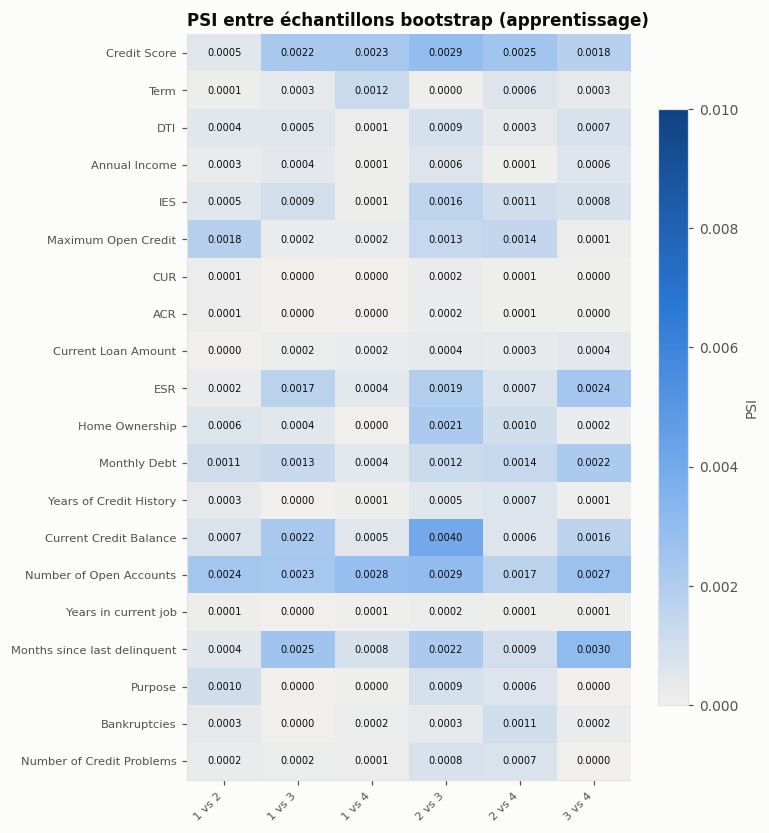

In [77]:
psi_matrix = sl.psi_matrix(classes, samples).loc[iv.index]
psi_max = psi_matrix.max(axis=1)
save_table(psi_matrix, "12_matrice_psi", index=True)
display(psi_matrix.assign(psi_max=psi_max, statut=psi_max.map(sl.psi_status)))
fig = plots_model.plot_matrix(psi_matrix, "PSI entre échantillons bootstrap (apprentissage)", vmax=0.01,
                              fmt="{:.4f}", label="PSI")
plots.save(fig, FIGURES_DIR / "12_matrice_psi.png");

**Lecture de la matrice des PSI.**

- **Toutes les variables sont stables.** Le PSI le plus élevé, toutes paires confondues, vaut 0,0040
  (*Current Credit Balance*), soit 25 fois moins que le seuil de vigilance de 0,10.
- **Pourquoi des valeurs aussi faibles ?** Les 4 échantillons sont tirés dans la même population,
  l'apprentissage. Le PSI mesure donc ici la seule **fluctuation d'échantillonnage** de la répartition
  des prêts entre classes, et le résultat montre qu'elle est négligeable.
- **Pourquoi ce n'est pas suffisant ?** Un PSI faible garantit la stabilité des **effectifs** des classes,
  mais pas celle du **lien avec le défaut**. C'est l'objet de la section suivante.

### 1.2 Cohérence du comportement des variables d'un échantillon à l'autre

Le PSI mesure la stabilité des **effectifs** des classes. On vérifie en plus la stabilité du **lien avec
le défaut**, à l'aide de quatre indicateurs :

- moyenne, écart-type et coefficient de variation (CV) de l'IV sur les 4 échantillons ;
- plus grand écart-type du WoE d'une classe ;
- nombre de classes dont le WoE **change de signe** d'un échantillon à l'autre ;
- concordance minimale, mesurée par le Spearman, entre l'ordre des classes par taux de défaut dans un
  échantillon et dans l'apprentissage complet. Une valeur de 1 signifie un ordre identique.

In [78]:
reference = pd.concat([bn.woe_table(classes[v], y, specs[v].order).assign(variable=v) for v in classes.columns])
stability = sl.woe_stability(boot, reference).set_index("variable").loc[iv.index].reset_index()
save_table(stability, "12_stabilite_woe")
stability

,variable,iv_moyen,iv_ecart_type,iv_cv,woe_ecart_type_max,classes_woe_signe_instable,concordance_rangs_min
0,Credit Score,0.1359,0.0229,0.1687,0.1173,0,0.9643
1,Term,0.0784,0.0063,0.0807,0.0217,0,1.0000
2,DTI,0.0806,0.0151,0.1870,0.0849,1,0.9000
3,Annual Income,0.0753,0.0088,0.1168,0.0643,0,1.0000
4,IES,0.0456,0.0136,0.2983,0.0805,2,1.0000
5,Maximum Open Credit,0.0264,0.0084,0.3179,0.0749,0,0.3000
6,CUR,0.0230,0.0067,0.2914,0.0225,0,1.0000
7,ACR,0.0229,0.0067,0.2934,0.0227,0,1.0000
8,Current Loan Amount,0.0187,0.0097,0.5172,0.0846,1,0.2000
9,ESR,0.0237,0.0064,0.2699,0.1037,1,0.8289


### 1.3 Stabilité des « seuils optimaux »

La table 2 du sujet est intitulée « comparaison des seuils optimaux obtenus sur différents échantillons
bootstrap ». On réapprend donc aussi la discrétisation complète, c'est-à-dire le choix de k par le T de
Tschuprow, sur chaque échantillon, et l'on compare le nombre de quantiles retenu.

In [79]:
def refit(x, y_sample, encours, var):
    return bn.fit_numeric_binning(x, y_sample, encours, variable=var,
                                  special_label=pipeline.SPECIAL_LABELS.get(var, bn.SPECIAL))

optimal_k = sl.optimal_k_by_sample(prep.train, y, prep.train[pipeline.ENCOURS], pipeline.NUMERIC_CANDIDATES,
                                   samples, refit)
retained_k = prep.candidates[prep.candidates["retenu"]].set_index("variable")["k_quantiles"]
optimal_k = optimal_k.assign(k_apprentissage=optimal_k["variable"].map(retained_k))
k_cols = [c for c in optimal_k.columns if c.startswith("k_")]
optimal_k = optimal_k.assign(k_identique_partout=optimal_k[k_cols].nunique(axis=1) == 1)
save_table(optimal_k, "12_k_optimal_bootstrap")
optimal_k

,variable,k_echantillon_1,k_echantillon_2,k_echantillon_3,k_echantillon_4,k_apprentissage,k_identique_partout
0,Current Loan Amount,4,4,9,4,4,False
1,Credit Score,7,6,9,6,6,False
2,Annual Income,2,2,2,2,2,True
3,Monthly Debt,7,9,10,7,6,False
4,Years of Credit History,8,7,7,6,3,False
5,Months since last delinquent,10,7,10,10,10,False
6,Current Credit Balance,5,8,8,6,5,False
7,Maximum Open Credit,5,5,8,4,5,False
8,Number of Open Accounts,9,10,9,3,10,False
9,Number of Credit Problems,2,2,2,2,2,True


**Lecture : cohérence du comportement d'un échantillon à l'autre.**

- **Variables au comportement stable.**
  - *Credit Score* garde le même ordre des classes dans les 4 échantillons (concordance ≥ 0,96). Sa
    classe la plus risquée (≤ 692) a un WoE compris entre +0,44 et +0,47, et sa classe la moins
    risquée (> 742) entre −0,95 et −0,69.
  - *Term*, *Annual Income*, *Home Ownership* et CUR ont une concordance de 1 et un coefficient de
    variation de l'IV ≤ 0,29.
- **Variables à forte variabilité.** Ce sont toutes des variables à IV < 0,02 :
  - *Purpose* : CV de l'IV de 0,93 (IV de 0,0003 à 0,0129) ;
  - *Bankruptcies* et *Number of Credit Problems* : CV > 1, et ordre des deux classes **inversé** d'un
    échantillon à l'autre (concordance −1) ;
  - *Number of Open Accounts* : 7 classes sur 10 dont le WoE change de signe ;
  - *Months since last delinquent* : 4 classes ;
  - *Monthly Debt* : 3 classes ;
  - *Current Loan Amount* : CV de 0,52.

  Pour ces variables, le lien avec le défaut est trop faible pour se distinguer du bruit
  d'échantillonnage.
- **Cas de *Maximum Open Credit*.** Sa concordance minimale est faible (0,30) alors que son IV est
  stable (CV 0,32). Ses quatre premières classes ont des taux de défaut très proches (23,8 % à 25,8 %),
  si bien que leur ordre fluctue. Seule la dernière classe (plafond > 876 920, 18,4 %) se distingue
  nettement, et elle le fait dans tous les échantillons.
- **Seuils optimaux.**
  - Le nombre de quantiles qui maximise le T de Tschuprow est **le même dans les 4 échantillons** pour
    *Annual Income* (k = 2) et pour les deux comptages (k = 2).
  - Pour les autres variables, il varie, par exemple de 6 à 9 pour *Credit Score*. Les courbes du T en
    fonction de k sont en effet plates (partie 4, figure du T de Tschuprow) : plusieurs découpages ont
    une association quasi équivalente, et le maximum dépend de l'échantillon.
  - L'IV, lui, reste stable pour les variables les plus discriminantes : le choix exact de k a peu
    d'effet sur l'information disponible.

**Conclusion de la stabilité.** Aucune variable n'est instable au sens du PSI (seuil de 0,25). La forte
variabilité du lien avec le défaut est identifiée pour les variables d'IV < 0,02. Cette information est
reprise dans la décision finale : la règle de pouvoir discriminant (section 4) exclut celles dont
l'association n'est pas significative, et la sélection pas à pas ainsi que le bootstrap des 100 modèles
contrôleront les autres.

## 2. Pouvoir discriminant : V de Cramér et IV (sujet 1.3.2)

$V = \sqrt{\chi^2 / (n \min(r-1, c-1))}$ mesure l'association entre la variable discrétisée et la cible.
Avec une cible binaire ($c = 2$), $V = \sqrt{\chi^2/n}$. On donne aussi la p-value du test du $\chi^2$
d'indépendance.

In [80]:
discrimination = sl.discrimination_table(classes, y, iv)
save_table(discrimination, "12_cramer_v_iv")
display(discrimination)
rank_corr = discrimination["cramer_v"].corr(discrimination["iv"], method="spearman")
print(f"Corrélation de Spearman entre les classements par V de Cramér et par IV : {rank_corr:.3f}")

,variable,cramer_v,iv,p_value_khi2,rang_v,rang_iv
0,Credit Score,0.1407,0.1210,0.0000,1,1
1,Term,0.1217,0.0780,0.0000,2,2
2,DTI,0.1135,0.0740,0.0000,3,3
3,Annual Income,0.1081,0.0673,0.0000,4,4
4,IES,0.0881,0.0443,0.0000,5,5
5,Maximum Open Credit,0.0622,0.0228,0.0000,6,6
6,CUR,0.0591,0.0195,0.0000,7,7
7,ACR,0.0589,0.0194,0.0000,8,8
8,Current Loan Amount,0.0568,0.0188,0.0000,11,9
9,ESR,0.0583,0.0187,0.0002,9,10


Corrélation de Spearman entre les classements par V de Cramér et par IV : 0.995


**Lecture.**

- **V de Cramér et IV classent les variables presque de la même façon** (Spearman 0,995). Les cinq
  premières sont identiques dans les deux classements : *Credit Score* (V 0,141), *Term* (0,122),
  *DTI* (0,114), *Annual Income* (0,108), *IES* (0,088). C'est attendu : les deux mesures quantifient
  l'écart entre la distribution des défauts et celle des non-défauts dans les classes. L'IV le fait en
  pondérant par le WoE, le V à partir du $\chi^2$.
- **Les deux mesures se complètent.**
  - L'IV dispose d'une **échelle d'interprétation métier** (table 3 de l'annexe).
  - Le V provient d'un **test statistique**, ce qui permet de distinguer un lien faible mais réel d'un
    lien nul.
- **Variables d'IV < 0,02.** Toutes ont un V inférieur à 0,06 : pouvoir discriminant faible. Elles se
  répartissent en deux groupes :
  - **association significative** (p < 0,05) : CUR, ACR, *Current Loan Amount*, ESR, *Home Ownership*,
    *Monthly Debt*, *Years of Credit History*, *Current Credit Balance*, *Years in current job*,
    *Purpose*. Elles portent un signal faible, mais réel, qui peut compléter les variables fortes dans un
    modèle multivarié ;
  - **association non significative** : *Number of Open Accounts* (p = 0,41), *Months since last
    delinquent* (0,31), *Bankruptcies* (0,24) et *Number of Credit Problems* (0,45). On ne peut pas
    rejeter l'hypothèse qu'elles soient sans lien avec le défaut : elles sont **exclues**.
- **Pourquoi ne pas exclure toutes les variables d'IV < 0,02 ?** L'IV est une mesure **univariée**. Une
  variable de faible IV peut apporter une information complémentaire une fois les autres prises en
  compte. Exclure d'emblée CUR (0,0195) en appliquant le seuil de 0,02 à la quatrième décimale près
  serait arbitraire. Les candidates « faibles » sont donc soumises à la sélection pas à pas, qui ne les
  gardera que si elles améliorent significativement le modèle.

## 3. Corrélations entre variables (sujet 1.3.3)

Les variables discrétisées étant qualitatives, leur association deux à deux est mesurée par le
**V de Cramér**. Le sujet fixe le seuil |V| > 0,4. Pour chaque paire au-dessus de ce seuil, on compare :

- **le V calculé hors des classes « manquant »**, qui indique si l'association provient seulement d'un
  motif de valeurs manquantes partagé ;
- **la corrélation linéaire des variables codées en WoE**, qui entrent ainsi dans la régression
  logistique. C'est elle qui crée la multicolinéarité.

**Règle de décision.** Une paire est **redondante** si |corrélation WoE| > 0,4 : la variable d'IV le plus
faible est alors écartée. Sinon, les deux variables sont associées dans le tableau de contingence, mais
leur information n'est pas dupliquée dans le modèle.

,variable_1,variable_2,cramer_v,cramer_v_hors_manquants,correlation_woe,redondante,a_conserver,a_exclure
0,Current Loan Amount,Term,0.4008,0.4008,0.3096,False,les deux,
1,Credit Score,Annual Income,0.7100,0.0909,0.2442,False,les deux,
2,Credit Score,DTI,0.5047,0.0791,0.2910,False,les deux,
3,Credit Score,IES,0.5199,0.0231,0.2639,False,les deux,
4,Credit Score,Term,0.4252,0.4640,0.2852,False,les deux,
5,Annual Income,DTI,0.7149,0.1491,0.3764,False,les deux,
6,Annual Income,IES,0.7249,0.5007,0.6451,True,Annual Income,IES
7,Current Credit Balance,Maximum Open Credit,0.4732,0.4732,0.1705,False,les deux,
8,Number of Credit Problems,Bankruptcies,0.8663,0.8663,0.8663,True,Bankruptcies,Number of Credit Problems
9,DTI,IES,0.5213,0.0542,0.3710,False,les deux,


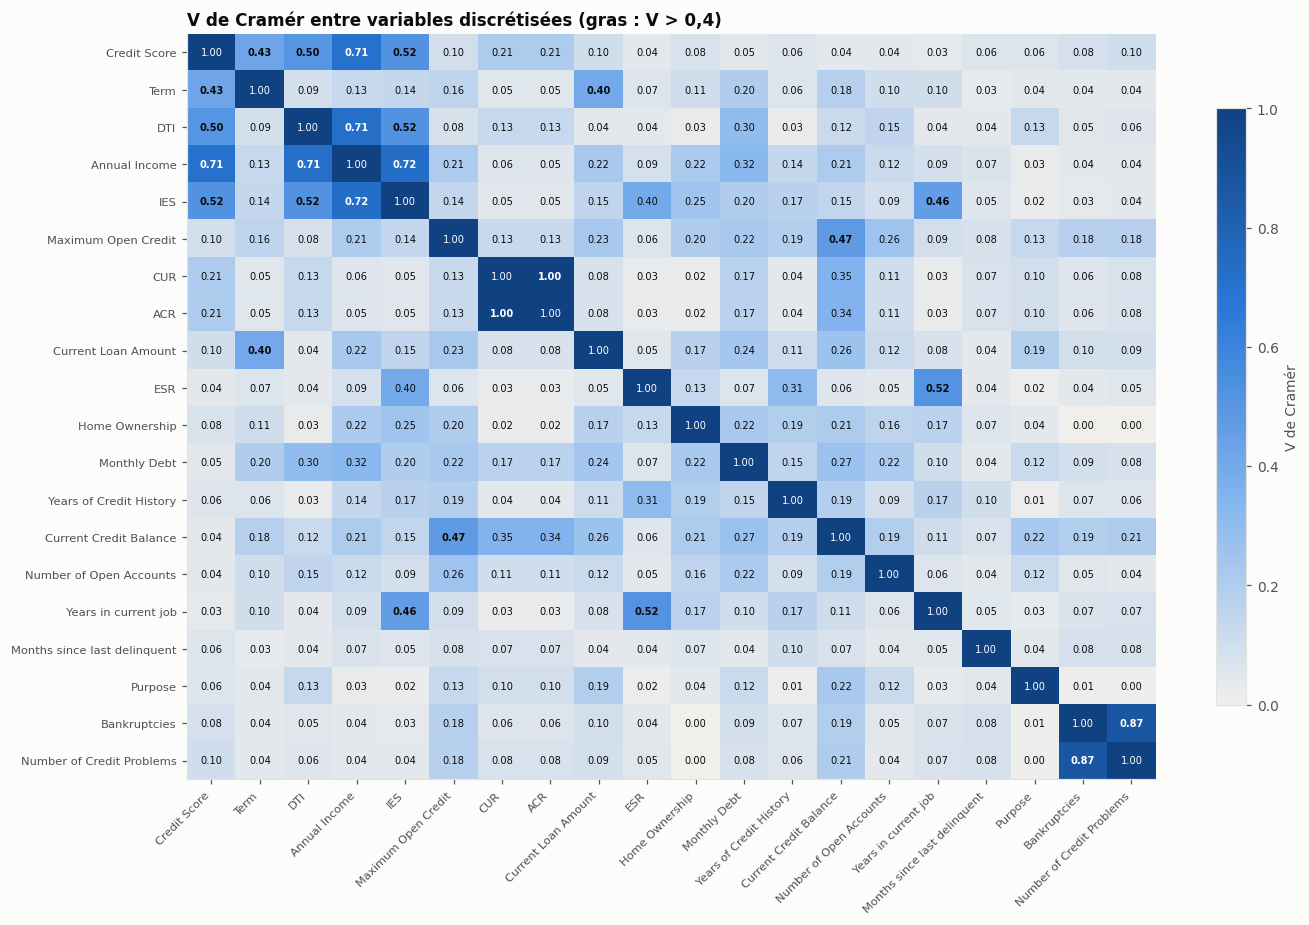

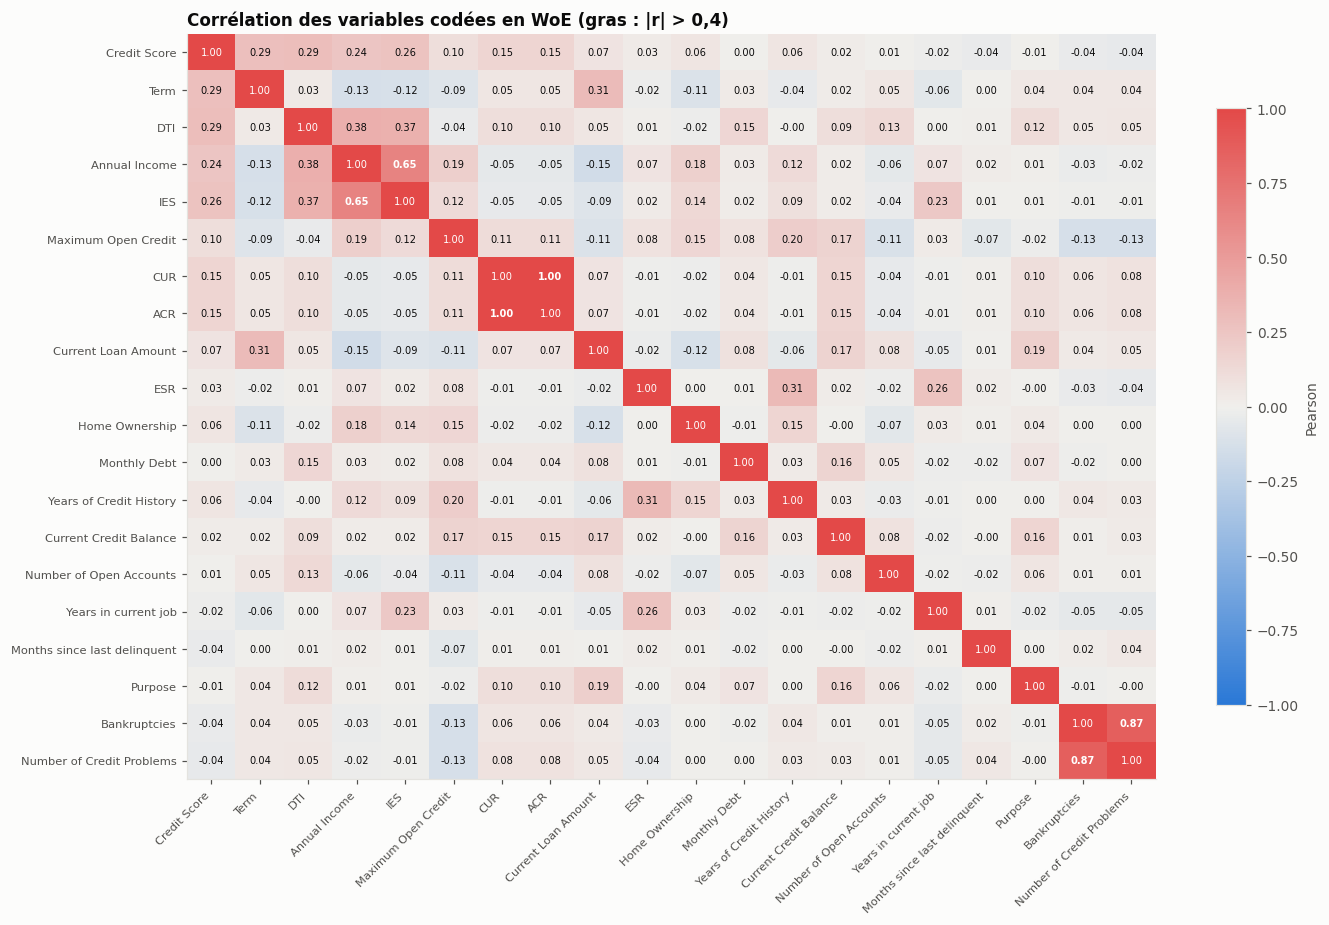

In [81]:
cramer = sl.pairwise_cramer_v(classes).loc[iv.index, iv.index]
save_table(cramer, "12_matrice_cramer_v", index=True)
fig = plots_model.plot_matrix(cramer, "V de Cramér entre variables discrétisées (gras : V > 0,4)", vmax=1.0,
                              highlight=sl.CORRELATION_THRESHOLD, label="V de Cramér")
plots.save(fig, FIGURES_DIR / "12_matrice_cramer_v.png")
woe_corr = prep.woe_train.corr().loc[iv.index, iv.index]
save_table(woe_corr, "12_correlation_woe", index=True)
fig = plots_model.plot_matrix(woe_corr, "Corrélation des variables codées en WoE (gras : |r| > 0,4)",
                              cmap=plots_model.DIVERGING, vmin=-1, vmax=1, highlight=sl.CORRELATION_THRESHOLD,
                              label="Pearson")
plots.save(fig, FIGURES_DIR / "12_correlation_woe.png")
pairs = sl.correlated_pairs(classes, prep.woe_train, specs, iv)
save_table(pairs, "12_paires_correlees")
pairs

**Lecture des paires associées (|V| > 0,4).** Treize paires dépassent le seuil.

- **Association due au motif de valeurs manquantes partagé.** *Credit Score*, *Annual Income*, *DTI* et
  *IES* sont fortement associés deux à deux (V de 0,50 à 0,72). Hors des classes « manquant », le V tombe
  à 0,02–0,15, sauf entre *Annual Income* et *IES*.
  - Ces variables partagent la classe « Manquant » des 1 529 prêts sans revenu ni score. C'est ce
    recouvrement qui crée l'association, pas une redondance d'information sur les prêts renseignés.
  - Hors du couple *Annual Income* / *IES*, leurs WoE sont corrélés à moins de 0,4 : elles ne sont **pas
    redondantes** dans le modèle.
- **Credit Score et Term (V = 0,43).**
  - L'association est réelle : V = 0,46 hors manquants. Les prêts longs ont des scores plus bas.
  - La corrélation de leurs WoE n'est cependant que de 0,29 : les deux variables apportent une
    information en grande partie distincte.
  - Exclure *Term* ferait perdre la deuxième variable la plus discriminante (IV 0,078).
  - Elles ne sont **pas jugées redondantes**. Le facteur d'inflation de la variance (VIF), calculé au
    partie 6, vérifiera l'absence de multicolinéarité.
- **Autres paires non redondantes.** *Current Loan Amount* et *Term* (V 0,40), *Current Credit Balance*
  et *Maximum Open Credit* (0,47), ESR / IES et *Years in current job* : les corrélations de WoE restent
  entre 0,17 et 0,31.
- **Paires redondantes**, avec |corrélation WoE| > 0,4 :
  - **CUR et ACR** (0,9997) : redondance par construction, ACR = 1 − CUR. **ACR est exclue**, CUR ayant
    un IV marginalement plus élevé. Les deux variables portent la même information.
  - **Annual Income et IES** (0,65, V hors manquants 0,50) : IES est le produit du revenu par
    l'ancienneté, et son information provient surtout du revenu. **IES est exclue** (IV 0,044 contre
    0,067).
  - **Number of Credit Problems et Bankruptcies** (0,87) : une faillite est un incident de crédit. Les
    deux variables sont de toute façon exclues pour absence de pouvoir discriminant.

## 4. Jeu final de variables candidates

Les règles sont appliquées dans l'ordre suivant :

1. **Pouvoir discriminant.** Exclusion si l'IV est < 0,02 **et** que le $\chi^2$ avec la cible n'est pas
   significatif à 5 %. Une variable d'IV < 0,02 mais d'association significative reste **candidate
   « faible »** : son apport sera tranché par la sélection pas à pas.
2. **Stabilité.** Exclusion si le PSI maximal entre échantillons bootstrap est ≥ 0,25.
3. **Redondance.** Exclusion de la variable d'IV le plus faible dans une paire redondante.

In [82]:
final = sl.final_selection(discrimination, psi_max, stability, pairs)
save_table(final, "12_selection_finale")
display(final)
candidates = final.loc[final["decision"].str.startswith("candidate"), "variable"].tolist()
pipeline.save_variables("candidates", candidates)
print(f"{len(candidates)} variables candidates retenues pour la modélisation :", candidates)

,variable,iv,cramer_v,p_value_khi2,psi_max,iv_cv_bootstrap,decision,justification
0,Credit Score,0.1210,0.1407,0.0000,0.0029,0.1687,candidate,"IV ≥ 0,02, stable, non redondante"
1,Term,0.0780,0.1217,0.0000,0.0012,0.0807,candidate,"IV ≥ 0,02, stable, non redondante"
2,DTI,0.0740,0.1135,0.0000,0.0009,0.1870,candidate,"IV ≥ 0,02, stable, non redondante"
3,Annual Income,0.0673,0.1081,0.0000,0.0006,0.1168,candidate,"IV ≥ 0,02, stable, non redondante"
4,IES,0.0443,0.0881,0.0000,0.0016,0.2983,exclue,redondante avec Annual Income (IV plus élevé)
5,Maximum Open Credit,0.0228,0.0622,0.0000,0.0018,0.3179,candidate,"IV ≥ 0,02, stable, non redondante"
6,CUR,0.0195,0.0591,0.0000,0.0002,0.2914,candidate (faible),"IV < 0,02 mais association significative : arbitrée par le stepwise"
7,ACR,0.0194,0.0589,0.0000,0.0002,0.2934,exclue,redondante avec CUR (IV plus élevé)
8,Current Loan Amount,0.0188,0.0568,0.0000,0.0004,0.5172,candidate (faible),"IV < 0,02 mais association significative : arbitrée par le stepwise"
9,ESR,0.0187,0.0583,0.0002,0.0024,0.2699,candidate (faible),"IV < 0,02 mais association significative : arbitrée par le stepwise"


14 variables candidates retenues pour la modélisation : ['Credit Score', 'Term', 'DTI', 'Annual Income', 'Maximum Open Credit', 'CUR', 'Current Loan Amount', 'ESR', 'Home Ownership', 'Monthly Debt', 'Years of Credit History', 'Current Credit Balance', 'Years in current job', 'Purpose']


**Jeu final : 14 variables candidates.**

| Statut | Variables | Justification |
|---|---|---|
| Candidates (IV ≥ 0,02) | *Credit Score*, *Term*, *DTI*, *Annual Income*, *Maximum Open Credit* | Pouvoir discriminant faible à moyen, stables, non redondantes |
| Candidates « faibles » (IV < 0,02, association significative) | CUR, *Current Loan Amount*, ESR, *Home Ownership*, *Monthly Debt*, *Years of Credit History*, *Current Credit Balance*, *Years in current job*, *Purpose* | Signal faible mais statistiquement réel ; arbitrage par la sélection pas à pas |
| Exclues pour redondance | ACR (avec CUR), IES (avec *Annual Income*) | Corrélation des WoE > 0,4 ; la variable de plus fort IV est conservée |
| Exclues pour absence de pouvoir discriminant | *Number of Open Accounts*, *Months since last delinquent*, *Bankruptcies*, *Number of Credit Problems* | IV < 0,02 et $\chi^2$ non significatif |

Aucune variable n'est exclue pour instabilité (PSI max < 0,01). Aucune n'atteint un IV de 0,5 : il n'y a
pas de soupçon de fuite d'information.

Le partie 6 estime la régression logistique sur ces 14 candidates (sujet 1.4.2), puis applique la
sélection pas à pas (sujet 1.4.3).

In [83]:
pct1, num3, num4 = percent(1), number(3), number(4)
save_latex_table(psi_matrix.reset_index(), "12_matrice_psi", {c: num4 for c in psi_matrix.columns}, "lrrrrrr")
save_latex_table(stability[["variable", "iv_moyen", "iv_ecart_type", "iv_cv", "classes_woe_signe_instable",
                            "concordance_rangs_min"]], "12_stabilite_woe",
                 {"iv_moyen": num4, "iv_ecart_type": num4, "iv_cv": number(2), "classes_woe_signe_instable": number(0),
                  "concordance_rangs_min": number(2)}, "lrrrrr")
save_latex_table(discrimination, "12_cramer_v_iv",
                 {"cramer_v": num4, "iv": num4, "p_value_khi2": pvalue, "rang_v": number(0), "rang_iv": number(0)},
                 "lrrrrr")
save_latex_table(pairs[["variable_1", "variable_2", "cramer_v", "cramer_v_hors_manquants", "correlation_woe",
                        "redondante", "a_exclure"]], "12_paires_correlees",
                 {"cramer_v": num3, "cramer_v_hors_manquants": num3, "correlation_woe": num3,
                  "redondante": lambda v: "oui" if v else "non"}, "llrrrcl")
save_latex_table(final[["variable", "iv", "p_value_khi2", "psi_max", "decision", "justification"]],
                 "12_selection_finale", {"iv": num4, "p_value_khi2": pvalue, "psi_max": num4}, "lrrrlp{6.2cm}")
print("Tableaux LaTeX écrits.")

Tableaux LaTeX écrits.


# Partie 6 — Régression logistique et stepwise (sujet 1.4)

**Sujet, section 1.4.**

| Question du sujet | Section du notebook |
|---|---|
| 1.4.1 Découpage 80/20 stratifié, comparaison avec la population, PSI, représentativité | 1 |
| 1.4.2 Modèle logistique sur toutes les variables candidates : coefficients, signes, log-vraisemblance, AIC, BIC, AR, AUC, test | 2 |
| 1.4.3 Sélection pas à pas (forward, backward, bidirectionnelle), comparaison, modèle final, test, vérifications | 3 et 4 |

**Spécification.** On estime
$\ln\frac{P(D=1\mid X)}{P(D=0\mid X)} = \beta_0 + \sum_j \beta_j \,\mathrm{WoE}_j(X_j)$
par maximum de vraisemblance (statsmodels).

- Chaque variable entre par le **WoE de sa classe**, appris sur l'apprentissage : une variable compte
  pour un seul coefficient, quel que soit son nombre de classes.
- Comme un WoE positif signale une classe risquée, **le signe attendu de chaque coefficient est
  positif**. Avec $\beta_j \approx 1$, le modèle reproduit l'effet univarié de la variable ;
  $0 < \beta_j < 1$ signifie qu'une partie de cet effet est déjà portée par d'autres variables.

**Indicateurs.**

- $\mathrm{AIC} = -2\ln L + 2k$ et $\mathrm{BIC} = -2\ln L + k\ln n$, où $k$ est le nombre de paramètres.
- AUC : aire sous la courbe ROC.
- Accuracy Ratio : $\mathrm{AR} = 2\,\mathrm{AUC} - 1$.
- Matrice de confusion, au **seuil égal au taux de défaut de l'apprentissage** : un prêt est classé
  « défaut » si sa PD dépasse le risque moyen.

In [84]:
import sys
from pathlib import Path


import pandas as pd
from IPython.display import display

from src import modeling as md
from src import pipeline, plots, plots_model, sampling
from src.config import FIGURES_DIR, PROCESSED_DIR, TARGET
from src.reporting import number, percent, pvalue, save_latex_table, save_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 230)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plots.set_style()

prep = pipeline.prepare()
candidates = pipeline.load_variables("candidates")
X_train, X_test = prep.woe_train[candidates], prep.woe_test[candidates]
y_train, y_test = prep.y_train, prep.y_test
threshold = y_train.mean()
print(f"{len(candidates)} variables candidates ; seuil de classification = {threshold:.4f}")

14 variables candidates ; seuil de classification = 0.2347


## 1. Échantillons d'apprentissage et de test (sujet 1.4.1)

Le découpage a été réalisé en partie 1, juste après le contrôle qualité : 80 % / 20 %, stratifié sur
la cible, `random_state = 42`. Il a été fait **avant** toute étape qui estime un paramètre, pour que le
test n'intervienne dans aucune décision. On vérifie ici sa représentativité :

1. taux de défaut et effectifs comparés à la population ;
2. distribution des principales variables brutes ;
3. PSI et test d'homogénéité du $\chi^2$ sur les variables discrétisées.

In [85]:
population = pd.read_csv(PROCESSED_DIR / "loans_after_data_quality.csv")
split = sampling.TrainTestSplit(pd.read_csv(PROCESSED_DIR / "train_dq.csv"), pd.read_csv(PROCESSED_DIR / "test_dq.csv"))
split_table = sampling.split_summary(split)
display(split_table)
main_vars = ["Credit Score", "Annual Income", "Monthly Debt", "Current Credit Balance", "Years of Credit History"]
describe = pd.concat({name: df[main_vars].describe().loc[["mean", "50%", "std"]]
                      for name, df in [("population", population), ("apprentissage", split.train), ("test", split.test)]})
save_table(describe, "13_distribution_echantillons", index=True)
describe

,échantillon,effectif,part,n_defauts,taux_defaut
0,Population,9827,1.0000,2307,0.2348
1,Apprentissage,7861,0.7999,1845,0.2347
2,Test,1966,0.2001,462,0.2350


Credit Score  Annual Income  Monthly Debt  Current Credit Balance  Years of Credit History
population    mean      716.5190 1,372,655.2492   18,391.5156            292,465.3295                  18.2396
              50%       723.0000 1,167,702.0000   16,157.7900            209,285.0000                  17.0000
              std        28.3551   858,570.1770   12,026.8502            348,839.0541                   6.9579
apprentissage mean      716.2879 1,362,427.9559   18,305.7135            290,144.2216                  18.2581
              50%       723.0000 1,166,543.0000   16,046.2600            209,285.0000                  17.0000
              std        28.4489   841,832.2290   11,908.5953            347,169.0146                   7.0130
test          mean      717.4352 1,413,205.7946   18,734.5933            301,746.2192                  18.1655
              50%       723.0000 1,183,073.0000   16,662.9050            209,389.5000                  16.9000
              std        27.9700   921,110.2565   12,485.7301            355,376.3163                   6.7342

In [86]:
representativity = sampling.representativity(prep.classes_train, prep.classes_test)
save_table(representativity, "13_representativite_psi")
display(representativity)
print("Variables avec PSI ≥ 0,10 :", representativity.loc[representativity["psi"] >= 0.10, "variable"].tolist())
print("Tests d'homogénéité significatifs à 5 % :",
      representativity.loc[representativity["p_value_homogeneite"] < 0.05, "variable"].tolist())

,variable,psi,stabilite,p_value_homogeneite
0,Number of Open Accounts,0.0063,stable,0.3661
1,Monthly Debt,0.0039,stable,0.2951
2,Credit Score,0.0039,stable,0.3980
3,Current Credit Balance,0.0036,stable,0.2181
4,Years of Credit History,0.0033,stable,0.0719
5,IES,0.0030,stable,0.2004
6,DTI,0.0026,stable,0.3875
7,ESR,0.0024,stable,0.7075
8,Maximum Open Credit,0.0021,stable,0.4959
9,Months since last delinquent,0.0018,stable,0.8350


Variables avec PSI ≥ 0,10 : []
Tests d'homogénéité significatifs à 5 % : []


**Lecture : les deux échantillons sont représentatifs.**

- **Taux de défaut.** 23,47 % en apprentissage, 23,50 % en test, 23,48 % dans la population : la
  stratification conserve la proportion de défauts à 0,03 point près.
- **Variables brutes.** Les médianes sont presque identiques. *Credit Score* : 723 dans les trois
  échantillons. *Current Credit Balance* : 209 285 contre 209 390. *Years of Credit History* : 17,0
  contre 16,9. Les moyennes du test sont légèrement plus élevées pour les montants (revenu moyen de
  1,41 M contre 1,36 M), ce qui tient à quelques valeurs élevées dans un échantillon de 1 966 prêts.
- **Variables discrétisées.**
  - Le PSI entre apprentissage et test est inférieur à 0,01 pour les 20 variables (maximum 0,0063,
    *Number of Open Accounts*), très loin du seuil de vigilance de 0,10.
  - Aucun test d'homogénéité du $\chi^2$ n'est significatif à 5 % : la plus petite p-value est de
    0,072 (*Years of Credit History*).

**Conclusion.** Les distributions des variables explicatives et le taux de défaut sont comparables. Le
test est un échantillon représentatif, sur lequel la performance du modèle peut être mesurée sans biais
de composition. Les écarts de performance constatés plus loin relèveront donc du sur-ajustement ou de la
variance d'échantillonnage, et non d'une différence de population.

## 2. Modèle avec toutes les variables candidates (sujet 1.4.2)

In [87]:
full = md.fit_logit(X_train, y_train)
full_coefs = md.coefficient_table(full)
save_table(full_coefs, "13_modele_complet_coefficients")
display(full_coefs)
full_metrics = pd.Series(md.model_metrics(full, X_train, y_train))
display(full_metrics.to_frame("modèle complet"))
display(md.vif_table(X_train).sort_values("vif", ascending=False))

,variable,coefficient,ecart_type,z,p_value,odds_ratio,or_ic_bas,or_ic_haut
0,const,-1.1829,0.0276,-42.8286,0.0000,0.3064,0.2902,0.3234
1,Credit Score,0.4767,0.0917,5.1958,0.0000,1.6107,1.3457,1.9281
2,Term,0.9340,0.1076,8.6788,0.0000,2.5448,2.0608,3.1424
3,DTI,0.5337,0.1171,4.5589,0.0000,1.7053,1.3556,2.1452
4,Annual Income,0.6461,0.1240,5.2107,0.0000,1.9081,1.4964,2.4331
5,Maximum Open Credit,0.6584,0.1997,3.2965,0.0010,1.9317,1.3060,2.8573
6,CUR,0.6355,0.2028,3.1333,0.0017,1.8880,1.2687,2.8096
7,Current Loan Amount,0.5838,0.2238,2.6082,0.0091,1.7929,1.1562,2.7803
8,ESR,0.7332,0.2182,3.3602,0.0008,2.0817,1.3573,3.1926
9,Home Ownership,0.9573,0.2093,4.5747,0.0000,2.6046,1.7283,3.9251


,modèle complet
n_variables,14.0000
log_vraisemblance,"-4,078.5160"
aic,"8,187.0321"
bic,"8,291.5771"
r2_mcfadden,0.0478
auc,0.6489
accuracy_ratio,0.2978


,variable,vif
3,Annual Income,1.3778
2,DTI,1.3301
0,Credit Score,1.3000
1,Term,1.2504
6,Current Loan Amount,1.2162
7,ESR,1.2082
10,Years of Credit History,1.1904
4,Maximum Open Credit,1.1742
11,Current Credit Balance,1.1266
12,Years in current job,1.0958


**Lecture du modèle complet (14 variables).**

- **Signes.** 13 coefficients sur 14 sont positifs, comme attendu en codage WoE. Leurs valeurs vont de
  0,25 à 0,96 : chaque variable conserve, une fois les autres prises en compte, une partie de son effet
  univarié.
- **Variables non significatives à 5 %.** Il y en a trois :
  - *Purpose* : coefficient **négatif** (−0,08), p = 0,86. Son faible effet univarié (IV 0,0033)
    disparaît une fois les autres variables prises en compte, et le signe négatif n'a pas de sens ;
  - *Current Credit Balance* : p = 0,39 ;
  - *Years of Credit History* : p = 0,28.
- **Variables à la limite.** *Monthly Debt* (p = 0,046) et *Years in current job* (p = 0,026) ne sont
  significatives qu'au seuil de 5 %.
- **Multicolinéarité.** Elle est faible : tous les VIF sont inférieurs à 1,4. Les variables sont donc
  peu redondantes, mais certaines n'apportent pas d'information propre.
- **Qualité d'ajustement.** Log-vraisemblance −4 078,5 ; AIC 8 187,0 ; BIC 8 291,6 ; AUC 0,649 ;
  AR 0,298 ; R² de McFadden 0,048.

Le modèle complet n'est donc pas satisfaisant en l'état : il contient des variables non significatives
et un coefficient de signe incohérent. Cela justifie la sélection pas à pas.

In [88]:
full_eval = md.train_test_comparison(full, X_train, y_train, X_test, y_test, threshold)
save_table(full_eval, "13_modele_complet_apprentissage_test", index=True)
display(full_eval)
print("Matrice de confusion (test) :")
display(md.confusion_table(y_test, md.predict_pd(full, X_test), threshold))

,apprentissage,test,ecart
auc,0.6489,0.6265,-0.0224
accuracy_ratio,0.2978,0.2530,-0.0448
log_vraisemblance,"-4,078.5160","-1,038.3879","3,040.1282"
log_loss,0.5188,0.5282,0.0093
brier,0.1704,0.1739,0.0035
pd_moyenne,0.2347,0.2307,-0.0040
taux_defaut_observe,0.2347,0.2350,0.0003
seuil,0.2347,0.2347,0.0000
accuracy,0.5961,0.5936,-0.0025
precision,0.3157,0.3087,-0.0069


Matrice de confusion (test) :


prédit,0,1
observé,,
0,895,609
1,190,272


**Généralisation du modèle complet.**

- **Discrimination.** L'AUC passe de 0,649 en apprentissage à 0,626 en test, et l'AR de 0,298 à 0,253.
  Une baisse de cet ordre est habituelle. Elle reflète en partie un léger sur-ajustement aux variables
  faibles.
- **Calibration.** Elle est bonne en moyenne : PD moyenne de 23,1 % sur le test pour un taux observé de
  23,5 %.
- **Classification** au seuil de 23,5 % : 272 des 462 défauts du test sont détectés (rappel 58,9 %), au
  prix de 609 fausses alertes.

## 3. Sélection pas à pas (sujet 1.4.3)

Trois procédures sont appliquées, chacune avec deux critères :

- **forward** : on part du modèle constant et on ajoute, à chaque étape, la variable qui diminue le plus
  le critère ;
- **backward** : on part du modèle complet et on retire la variable dont le retrait diminue le plus le
  critère ;
- **bidirectionnelle** : on part du modèle constant ; à chaque étape, on envisage tous les ajouts et
  tous les retraits, et l'on applique le meilleur mouvement.

Chaque procédure s'arrête quand plus aucun mouvement ne diminue le critère. Deux critères sont
utilisés :

- l'**AIC**, qui pénalise chaque paramètre de 2 ;
- le **BIC**, qui le pénalise de $\ln n \approx 9{,}0$ et favorise donc les modèles plus parcimonieux.


forward-aic :


,etape,mouvement,variable,critere
0,0,départ,,"8,568.8681"
1,1,ajout,Credit Score,"8,407.0213"
2,2,ajout,Term,"8,357.0700"
3,3,ajout,Annual Income,"8,282.3391"
4,4,ajout,ESR,"8,262.9264"
5,5,ajout,DTI,"8,243.3634"
6,6,ajout,Home Ownership,"8,220.7638"
7,7,ajout,Maximum Open Credit,"8,204.1951"
8,8,ajout,CUR,"8,194.1733"
9,9,ajout,Current Loan Amount,"8,187.6176"



forward-bic :


,etape,mouvement,variable,critere
0,0,départ,,"8,575.8377"
1,1,ajout,Credit Score,"8,420.9606"
2,2,ajout,Term,"8,377.9790"
3,3,ajout,Annual Income,"8,310.2178"
4,4,ajout,ESR,"8,297.7748"
5,5,ajout,DTI,"8,285.1814"
6,6,ajout,Home Ownership,"8,269.5515"
7,7,ajout,Maximum Open Credit,"8,259.9524"
8,8,ajout,CUR,"8,256.9003"



backward-aic :


...

,etape,mouvement,variable,critere
0,0,départ,,"8,291.5771"
1,1,retrait,Purpose,"8,282.6367"
2,2,retrait,Current Credit Balance,"8,274.3944"
3,3,retrait,Years of Credit History,"8,266.6073"
4,4,retrait,Years in current job,"8,261.9753"
5,5,retrait,Monthly Debt,"8,257.3143"
6,6,retrait,Current Loan Amount,"8,256.9003"



both-aic :


,etape,mouvement,variable,critere
0,0,départ,,"8,568.8681"
1,1,ajout,Credit Score,"8,407.0213"
2,2,ajout,Term,"8,357.0700"
3,3,ajout,Annual Income,"8,282.3391"
4,4,ajout,ESR,"8,262.9264"
5,5,ajout,DTI,"8,243.3634"
6,6,ajout,Home Ownership,"8,220.7638"
7,7,ajout,Maximum Open Credit,"8,204.1951"
8,8,ajout,CUR,"8,194.1733"
9,9,ajout,Current Loan Amount,"8,187.6176"



both-bic :


,etape,mouvement,variable,critere
0,0,départ,,"8,575.8377"
1,1,ajout,Credit Score,"8,420.9606"
2,2,ajout,Term,"8,377.9790"
3,3,ajout,Annual Income,"8,310.2178"
4,4,ajout,ESR,"8,297.7748"
5,5,ajout,DTI,"8,285.1814"
6,6,ajout,Home Ownership,"8,269.5515"
7,7,ajout,Maximum Open Credit,"8,259.9524"
8,8,ajout,CUR,"8,256.9003"


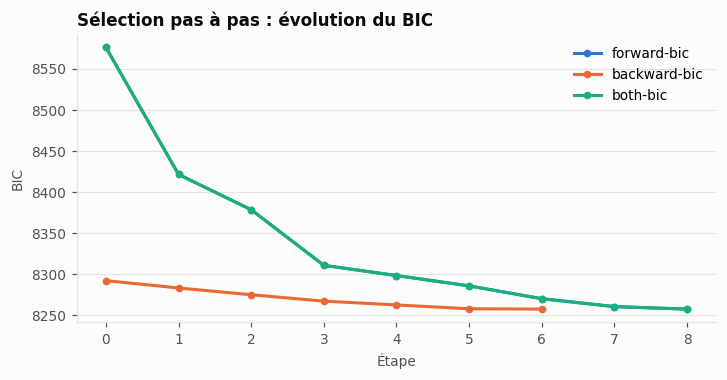

In [89]:
runs, paths = {}, {}
for direction in ("forward", "backward", "both"):
    for criterion in ("aic", "bic"):
        selected, path = md.stepwise(X_train, y_train, direction, criterion)
        runs[f"{direction}-{criterion}"] = selected
        paths[f"{direction}-{criterion}"] = path
        save_table(path, f"13_stepwise_{direction}_{criterion}")
for name, path in paths.items():
    print(f"\n{name} :")
    display(path[["etape", "mouvement", "variable", "critere"]])
fig = plots_model.plot_stepwise_paths({k: paths[k] for k in ("forward-bic", "backward-bic", "both-bic")}, "bic")
plots.save(fig, FIGURES_DIR / "13_stepwise_bic.png");

In [90]:
iv = pd.read_csv(TABLES_DIR / "12_selection_finale.csv", encoding="utf-8-sig").set_index("variable")
core = [v for v in candidates if iv.loc[v, "decision"] == "candidate"]
models = {"complet (14 candidates)": candidates, "IV ≥ 0,02 seules": core, **runs}
comparison = md.compare_models(models, prep.woe_train, y_train, prep.woe_test, y_test)
save_table(comparison, "13_comparaison_modeles")
comparison

,modele,n_variables,log_vraisemblance,aic,bic,r2_mcfadden,auc,accuracy_ratio,auc_test,ar_test,variables_non_significatives,coefficients_negatifs,variables
0,complet (14 candidates),14,"-4,078.5160","8,187.0321","8,291.5771",0.0478,0.6489,0.2978,0.6265,0.2530,3,1,"Credit Score, Term, DTI, Annual Income, Maximum Open Credit, CUR, Current Loan Amount, ESR, Home Ownership, Monthly ..."
1,"IV ≥ 0,02 seules",5,"-4,114.2053","8,240.4105","8,282.2285",0.0395,0.6337,0.2675,0.6144,0.2288,0,0,"Credit Score, Term, DTI, Annual Income, Maximum Open Credit"
2,forward-aic,11,"-4,079.4857","8,182.9713","8,266.6073",0.0476,0.6484,0.2968,0.6258,0.2515,0,0,"Credit Score, Term, Annual Income, ESR, DTI, Home Ownership, Maximum Open Credit, CUR, Current Loan Amount, Monthly ..."
3,forward-bic,8,"-4,088.0867","8,194.1733","8,256.9003",0.0456,0.6456,0.2912,0.6268,0.2536,0,0,"Credit Score, Term, Annual Income, ESR, DTI, Home Ownership, Maximum Open Credit, CUR"
4,backward-aic,11,"-4,079.4857","8,182.9713","8,266.6073",0.0476,0.6484,0.2968,0.6258,0.2515,0,0,"Credit Score, Term, DTI, Annual Income, Maximum Open Credit, CUR, Current Loan Amount, ESR, Home Ownership, Monthly ..."
5,backward-bic,8,"-4,088.0867","8,194.1733","8,256.9003",0.0456,0.6456,0.2912,0.6268,0.2536,0,0,"Credit Score, Term, DTI, Annual Income, Maximum Open Credit, CUR, ESR, Home Ownership"
6,both-aic,11,"-4,079.4857","8,182.9713","8,266.6073",0.0476,0.6484,0.2968,0.6258,0.2515,0,0,"Credit Score, Term, Annual Income, ESR, DTI, Home Ownership, Maximum Open Credit, CUR, Current Loan Amount, Monthly ..."
7,both-bic,8,"-4,088.0867","8,194.1733","8,256.9003",0.0456,0.6456,0.2912,0.6268,0.2536,0,0,"Credit Score, Term, Annual Income, ESR, DTI, Home Ownership, Maximum Open Credit, CUR"


**Règle de choix du modèle final.** On retient le modèle de **BIC minimal** parmi ceux qui satisfont deux
vérifications du sujet :

- toutes les variables significatives à 5 % ;
- tous les coefficients de signe cohérent, c'est-à-dire positif en codage WoE.

La troisième vérification, l'absence de forte corrélation entre variables, est contrôlée sur le modèle
retenu (VIF et corrélations des WoE).

Le BIC est préféré à l'AIC parce que le sujet demande un modèle **parcimonieux**, et parce que sa
pénalité plus forte limite le risque de retenir des variables au signal faible ou instable (partie 5).
Le choix repose uniquement sur l'apprentissage ; le test sert ensuite à juger la généralisation.

In [91]:
eligible = comparison[(comparison["variables_non_significatives"] == 0) & (comparison["coefficients_negatifs"] == 0)]
best = eligible.sort_values(["bic", "n_variables"]).iloc[0]
final_vars = models[best["modele"]]
print(f"Modèle retenu : {best['modele']} ({len(final_vars)} variables)")
print("Procédures aboutissant au même ensemble de variables :",
      [name for name, v in models.items() if sorted(v) == sorted(final_vars)])
pipeline.save_variables("final", final_vars)
final = md.fit_logit(prep.woe_train[final_vars], y_train)
final_coefs = md.coefficient_table(final)
save_table(final_coefs, "13_modele_final_coefficients")
display(final_coefs)
vif = md.vif_table(prep.woe_train[final_vars])
display(vif)
woe_corr = prep.woe_train[final_vars].corr()
print(f"Corrélation maximale entre WoE du modèle final : {woe_corr.where(lambda c: c < 0.999).abs().max().max():.3f}")

Modèle retenu : forward-bic (8 variables)
Procédures aboutissant au même ensemble de variables : ['forward-bic', 'backward-bic', 'both-bic']


,variable,coefficient,ecart_type,z,p_value,odds_ratio,or_ic_bas,or_ic_haut
0,const,-1.1836,0.0276,-42.9149,0.0000,0.3062,0.2900,0.3232
1,Credit Score,0.4599,0.0912,5.0456,0.0000,1.5839,1.3248,1.8938
2,Term,1.0194,0.1029,9.9110,0.0000,2.7716,2.2656,3.3907
3,Annual Income,0.6274,0.1227,5.1109,0.0000,1.8726,1.4722,2.3820
4,ESR,0.9214,0.1992,4.6244,0.0000,2.5128,1.7004,3.7133
5,DTI,0.5941,0.1137,5.2233,0.0000,1.8114,1.4495,2.2638
6,Home Ownership,0.9479,0.2069,4.5807,0.0000,2.5803,1.7200,3.8708
7,Maximum Open Credit,0.7327,0.1936,3.7847,0.0002,2.0806,1.4237,3.0407
8,CUR,0.6931,0.2001,3.4638,0.0005,1.9999,1.3511,2.9602


,variable,vif
0,Credit Score,1.2864
1,Term,1.1592
2,Annual Income,1.3518
3,ESR,1.0101
4,DTI,1.2717
5,Home Ownership,1.0648
6,Maximum Open Credit,1.1015
7,CUR,1.0595


Corrélation maximale entre WoE du modèle final : 0.376


**Comparaison des procédures et choix du modèle final.**

- **Les trois procédures convergent pour un même critère.**
  - **BIC** : forward, backward et bidirectionnelle aboutissent au **même modèle à 8 variables**. Le
    backward retire successivement *Purpose*, *Current Credit Balance*, *Years of Credit History*,
    *Years in current job*, *Monthly Debt* et *Current Loan Amount*.
  - **AIC** : les trois aboutissent au même modèle à 11 variables, qui conserve en plus *Current Loan
    Amount*, *Monthly Debt* et *Years in current job*.
- **Comparaison des modèles.**

  | Modèle | Variables | BIC | AIC | AUC apprentissage | AUC test |
  |---|---|---|---|---|---|
  | BIC (retenu) | 8 | **8 256,9** | 8 194,2 | 0,646 | **0,627** |
  | AIC | 11 | 8 266,6 | **8 183,0** | 0,648 | 0,626 |
  | Complet | 14 | 8 291,6 | 8 187,0 | 0,649 | 0,626 |
  | IV ≥ 0,02 seules | 5 | 8 282,2 | 8 240,4 | 0,634 | 0,614 |

- **Choix.** Le modèle BIC a le BIC le plus faible. Les trois variables supplémentaires du modèle AIC
  n'améliorent la log-vraisemblance que de 8,6 points et n'apportent rien en test (AUC 0,626 contre
  0,627). Le modèle BIC est donc **retenu**.
- **Apport des candidates faibles.** Le modèle restreint aux 5 variables d'IV ≥ 0,02 est nettement moins
  bon (BIC 8 282,2, AUC test 0,614). Trois candidates « faibles » de la partie 5 (ESR, *Home Ownership*,
  CUR) apportent donc une information significative une fois combinées aux autres. Cela confirme qu'il
  ne fallait pas les exclure sur la seule base du seuil d'IV.

**Vérifications du sujet sur le modèle final.**

- **Significativité.** Toutes les variables sont significatives à 1 % : p ≤ 0,0005, z de 3,5 à 9,9.
- **Corrélations.** VIF de 1,01 à 1,35 ; la corrélation maximale entre WoE du modèle est de 0,376,
  sous le seuil de 0,4.
- **Cohérence avec le défaut.** Les 8 coefficients sont positifs, compris entre 0,46 et 1,02 : chaque
  variable agit dans le sens de son profil de risque univarié.

## 4. Évaluation du modèle final sur le test

In [92]:
final_eval = md.train_test_comparison(final, prep.woe_train[final_vars], y_train, prep.woe_test[final_vars], y_test,
                                      threshold)
save_table(final_eval, "13_modele_final_apprentissage_test", index=True)
display(final_eval)
confusion_train = md.confusion_table(y_train, md.predict_pd(final, prep.woe_train[final_vars]), threshold)
confusion_test = md.confusion_table(y_test, md.predict_pd(final, prep.woe_test[final_vars]), threshold)
save_table(confusion_test, "13_modele_final_confusion_test", index=True)
print("Matrice de confusion — apprentissage :"); display(confusion_train)
print("Matrice de confusion — test :"); display(confusion_test)

,apprentissage,test,ecart
auc,0.6456,0.6268,-0.0188
accuracy_ratio,0.2912,0.2536,-0.0376
log_vraisemblance,"-4,088.0867","-1,036.4351","3,051.6516"
log_loss,0.5200,0.5272,0.0071
brier,0.1708,0.1735,0.0027
pd_moyenne,0.2347,0.2308,-0.0039
taux_defaut_observe,0.2347,0.2350,0.0003
seuil,0.2347,0.2347,0.0000
accuracy,0.5939,0.5900,-0.0039
precision,0.3144,0.3014,-0.0130


Matrice de confusion — apprentissage :


prédit,0,1
observé,,
0,3528,2488
1,704,1141


Matrice de confusion — test :


prédit,0,1
observé,,
0,899,605
1,201,261


**Généralisation du modèle final.**

- **Discrimination.** AUC de 0,646 en apprentissage et 0,627 en test ; AR de 0,291 et 0,254. L'écart
  (−0,019 d'AUC) est plus faible que celui du modèle complet (−0,022) : moins de variables, moins de
  sur-ajustement, pour la même performance en test.
- **Calibration.** PD moyenne de 23,1 % sur le test pour 23,5 % de défauts observés. Le modèle ne biaise
  pas le niveau moyen de risque.
- **Classification** au seuil de 23,5 % :

  | | Défauts détectés (rappel) | Non-défauts correctement classés (spécificité) |
  |---|---|---|
  | Apprentissage | 61,8 % | 58,6 % |
  | Test | 56,5 % (261 sur 462) | 59,8 % |

  La précision est faible (30,1 % en test) : sur 10 prêts signalés, 3 font défaut. C'est la conséquence
  directe d'un pouvoir discriminant modeste (AR ≈ 0,25), et non d'un défaut de calibration.

**Conclusion sur la généralisation.** Les performances baissent peu entre apprentissage et test, et ces
deux échantillons sont représentatifs l'un de l'autre. Le modèle généralise donc correctement. Sa
limite est sa capacité de discrimination, contrainte par la faiblesse des variables disponibles
(IV maximal de 0,12), et non le sur-ajustement.

### 4.1 Contribution des variables et lecture de chaque variable conservée

La contribution relative de chaque variable suit l'annexe du sujet :
$C_i = \sigma(\alpha_i X_i)/\sum_j \sigma(\alpha_j X_j)$, avec, pour une variable discrète,
$\sigma(\alpha_i X_i) = \sqrt{\sum_k p_k \alpha_k^2 - (\sum_k p_k \alpha_k)^2}$.

En codage WoE, le coefficient de la modalité $k$ est $\alpha_k = \beta_i \times \mathrm{WoE}_k$ : c'est
la contribution de la classe au score logistique.

,variable,ecart_type_terme,contribution
0,Term,0.2770,0.2231
1,Credit Score,0.1689,0.1360
2,Annual Income,0.1656,0.1333
3,DTI,0.1645,0.1325
4,Home Ownership,0.1294,0.1042
5,ESR,0.1254,0.1010
6,Maximum Open Credit,0.1140,0.0918
7,CUR,0.0968,0.0780


,variable,classe,part,taux_defaut,woe,contribution_score
0,Credit Score,]-inf ; 692],0.1380,0.3189,0.4231,0.1946
1,Credit Score,]692 ; 711],0.1313,0.2229,-0.0671,-0.0309
2,Credit Score,]711 ; 723],0.1483,0.1947,-0.2379,-0.1094
3,Credit Score,]723 ; 734],0.1261,0.2563,0.1167,0.0537
4,Credit Score,]734 ; 742],0.1338,0.2186,-0.0917,-0.0422
5,Credit Score,]742 ; +inf],0.1280,0.1193,-0.8173,-0.3759
6,Credit Score,Manquant,0.1945,0.2865,0.2693,0.1239
7,Term,Short Term,0.7184,0.2024,-0.1894,-0.1930
8,Term,Long Term,0.2816,0.3171,0.4147,0.4227
9,Annual Income,]-inf ; 1 166 543],0.4027,0.2647,0.1602,0.1005


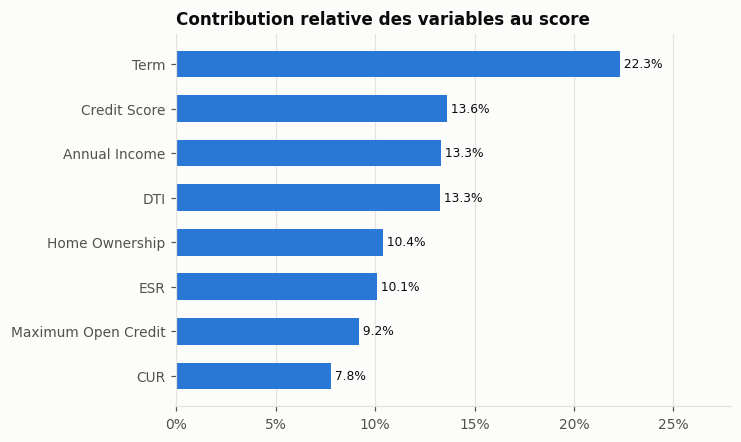

In [93]:
contrib = md.contributions(prep.woe_train[final_vars], final.params)
save_table(contrib, "13_contributions")
display(contrib)
fig = plots_model.plot_contributions(contrib)
plots.save(fig, FIGURES_DIR / "13_contributions.png")
points = []
for v in final_vars:
    for cls in prep.specs[v].order:
        woe = prep.woe_maps[v][cls]
        mask = prep.classes_train[v] == cls
        points.append({"variable": v, "classe": cls, "part": mask.mean(), "taux_defaut": y_train[mask].mean(),
                       "woe": woe, "contribution_score": final.params[v] * woe})
points = pd.DataFrame(points)
save_table(points, "13_contributions_par_classe")
points

**Contribution et lecture de chaque variable conservée.** Les contributions sont calculées selon
l'annexe ; la colonne `contribution_score` donne $\beta \times \mathrm{WoE}$, l'apport de la classe au score
logistique.

| Variable | Contribution | Coefficient (OR) | Lecture économique |
|---|---|---|---|
| **Term** | 22,3 % | 1,02 (2,77) | Un prêt long apporte +0,42 au score, un prêt court −0,19. C'est la variable qui sépare le plus les emprunteurs : une durée longue expose plus longtemps à un choc de revenu et concerne des montants plus élevés. |
| **Credit Score** | 13,6 % | 0,46 (1,58) | De +0,19 (score ≤ 692) à −0,38 (score > 742). Le coefficient est inférieur à 1 parce que la classe « Manquant » est partagée avec *Annual Income* et *DTI* : son effet est réparti entre les trois variables. |
| **Annual Income** | 13,3 % | 0,63 (1,87) | Revenu au-dessus de la médiane : −0,21 ; revenu non renseigné : +0,17. Un revenu élevé donne une marge de remboursement. |
| **DTI** | 13,3 % | 0,59 (1,81) | De −0,27 (DTI ≤ 0,11) à +0,17 (DTI > 0,23). Plus la dette absorbe le revenu, plus le risque augmente : c'est l'effet attendu en partie 3. |
| **Home Ownership** | 10,4 % | 0,95 (2,58) | Propriétaire avec crédit immobilier : −0,14 ; locataire ou propriétaire sans crédit : +0,12. Avoir obtenu un crédit immobilier signale une solvabilité déjà validée par un prêteur. |
| **ESR** | 10,1 % | 0,92 (2,51) | Les ESR les plus élevés et l'ancienneté d'emploi inconnue sont les plus risqués (jusqu'à +0,19). Comme montré en partie 3, l'ESR capte surtout la **jeunesse de l'historique de crédit**, et non la stabilité professionnelle. |
| **Maximum Open Credit** | 9,2 % | 0,73 (2,08) | Seule la classe des plafonds les plus élevés (> 876 920) se distingue (−0,23) : un prêteur n'accorde un plafond élevé qu'à un emprunteur jugé solide. |
| **CUR** | 7,8 % | 0,69 (2,00) | Utilisation supérieure à 50 % du plafond : +0,09 ; inférieure : −0,10. Une forte utilisation du crédit renouvelable traduit une tension de trésorerie. |

**Interprétation des odds ratios.** En codage WoE, l'odds ratio porte sur une hausse d'**une unité de
WoE**. Pour *Term*, passer de « court » (WoE −0,19) à « long » (WoE +0,41) multiplie la cote de défaut
par $\exp(1{,}02 \times 0{,}60) \approx 1{,}85$.

In [94]:
pct1, pct2, num3, num4, int0 = percent(1), percent(2), number(3), number(4), number(0)
coef_fmt = {"coefficient": num3, "ecart_type": num3, "z": number(2), "p_value": pvalue, "odds_ratio": num3,
            "or_ic_bas": num3, "or_ic_haut": num3}
save_latex_table(representativity, "13_representativite_psi", {"psi": num4, "p_value_homogeneite": pvalue}, "lrlr")
save_latex_table(full_coefs, "13_modele_complet_coefficients", coef_fmt, "lrrrrrrr")
save_latex_table(final_coefs, "13_modele_final_coefficients", coef_fmt, "lrrrrrrr")
cmp_cols = ["modele", "n_variables", "log_vraisemblance", "aic", "bic", "auc", "accuracy_ratio", "auc_test",
            "ar_test", "variables_non_significatives", "coefficients_negatifs"]
save_latex_table(comparison[cmp_cols], "13_comparaison_modeles",
                 {"n_variables": int0, "log_vraisemblance": number(1), "aic": number(1), "bic": number(1), "auc": num4,
                  "accuracy_ratio": num4, "auc_test": num4, "ar_test": num4, "variables_non_significatives": int0,
                  "coefficients_negatifs": int0}, "lrrrrrrrrrr")
eval_rows = ["auc", "accuracy_ratio", "log_loss", "brier", "pd_moyenne", "taux_defaut_observe", "accuracy",
             "precision", "rappel", "specificite", "f1"]
save_latex_table(final_eval.loc[eval_rows].reset_index().rename(columns={"index": "indicateur"}),
                 "13_modele_final_apprentissage_test", {"apprentissage": num4, "test": num4, "ecart": num4}, "lrrr")
save_latex_table(confusion_test.rename(index={0: "observé 0", 1: "observé 1"}, columns={0: "prédit 0", 1: "prédit 1"})
                 .reset_index().rename(columns={"observé": ""}), "13_modele_final_confusion_test",
                 {"prédit 0": int0, "prédit 1": int0}, "lrr")
save_latex_table(contrib, "13_contributions", {"ecart_type_terme": num4, "contribution": pct1}, "lrr")
save_latex_table(points, "13_contributions_par_classe",
                 {"part": pct1, "taux_defaut": pct1, "woe": num3, "contribution_score": num3}, "llrrrr")
print("Tableaux LaTeX écrits.")

Tableaux LaTeX écrits.


## Conclusion

- **Échantillons.** Apprentissage et test sont représentatifs : PSI < 0,01 et aucun écart
  significatif.
- **Modèle complet.** Le modèle sur les 14 candidates contient 3 variables non significatives et un
  coefficient de signe incohérent.
- **Sélection pas à pas.** Sous le critère BIC, les trois procédures convergent vers un **modèle à
  8 variables** :
  - *Term*, *Credit Score*, *Annual Income*, *DTI*, *Home Ownership*, ESR, *Maximum Open Credit*, CUR ;
  - toutes significatives, de signe cohérent et peu corrélées ;
  - **AUC test 0,627 (AR 0,254)** : la meilleure performance en test, légèrement au-dessus du modèle
    complet (0,626), avec moins de variables.
- **Fichier produit.** `resultats/donnees/variables_final.json`. Le partie 7 en évalue la robustesse
  (100 bootstraps) et calcule les PD ; le partie 8 le compare à XGBoost.

# Partie 7 — Robustesse et probabilité de défaut (sujet 1.5.1–1.5.2)

**Sujet, sections 1.5.1 et 1.5.2.**

| Question du sujet | Section du notebook |
|---|---|
| 1.5.1 100 échantillons bootstrap, réestimation, moyenne et écart-type des coefficients, robustesse | 1 |
| 1.5.2 Score $S_i = \beta_0 + \sum_j \beta_j X_{ij}$, $\mathrm{PD}_i = 1/(1+e^{-S_i})$, distribution des PD | 2 |

Le modèle étudié est le modèle final de la partie 6 (`variables_final.json`), dont les variables
entrent sous forme WoE.

In [95]:
import sys
from pathlib import Path


import numpy as np
import pandas as pd
from IPython.display import display

from src import modeling as md
from src import pipeline, plots, plots_model
from src.config import FIGURES_DIR, PROCESSED_DIR, RANDOM_STATE
from src.reporting import number, percent, save_latex_table, save_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plots.set_style()

prep = pipeline.prepare()
final_vars = pipeline.load_variables("final")
X_train, X_test = prep.woe_train[final_vars], prep.woe_test[final_vars]
y_train, y_test = prep.y_train, prep.y_test
model = md.fit_logit(X_train, y_train)
print("Variables du modèle final :", final_vars)

Variables du modèle final : ['Credit Score', 'Term', 'Annual Income', 'ESR', 'DTI', 'Home Ownership', 'Maximum Open Credit', 'CUR']


## 1. Robustesse : 100 modèles bootstrap (sujet 1.5.1)

On tire 100 échantillons de 7 861 prêts **avec remise** dans l'apprentissage (`random_state = 42`), puis
on réestime le modèle sur chacun, avec les mêmes variables et les mêmes WoE. Pour chaque coefficient,
on compare :

- le coefficient du modèle initial ;
- la moyenne et l'écart-type des 100 estimations bootstrap ;
- le biais (moyenne bootstrap − coefficient initial) et le coefficient de variation ;
- l'écart-type asymptotique fourni par la régression, que l'écart-type bootstrap doit retrouver si
  l'estimation est fiable ;
- l'intervalle percentile à 95 % et la part des échantillons où le coefficient garde son signe.

,variable,coefficient_initial,moyenne_bootstrap,ecart_type_bootstrap,ecart_type_asymptotique,biais,cv,percentile_2_5,percentile_97_5,part_meme_signe,ratio_ecarts_types
0,const,-1.1836,-1.1779,0.0288,0.0276,0.0057,0.0245,-1.2272,-1.1251,1.0000,1.0445
1,Credit Score,0.4599,0.4630,0.0950,0.0912,0.0031,0.2051,0.2729,0.6290,1.0000,1.0421
2,Term,1.0194,1.0110,0.0973,0.1029,-0.0084,0.0962,0.8378,1.2011,1.0000,0.9456
3,Annual Income,0.6274,0.6064,0.1234,0.1227,-0.0210,0.2035,0.3613,0.8483,1.0000,1.0052
4,ESR,0.9214,0.9209,0.1977,0.1992,-0.0005,0.2147,0.5643,1.3213,1.0000,0.9922
5,DTI,0.5941,0.6014,0.1089,0.1137,0.0073,0.1811,0.4141,0.7955,1.0000,0.9574
6,Home Ownership,0.9479,0.9721,0.2257,0.2069,0.0243,0.2322,0.5844,1.3759,1.0000,1.0908
7,Maximum Open Credit,0.7327,0.7386,0.1876,0.1936,0.0059,0.2540,0.3553,1.0557,1.0000,0.9689
8,CUR,0.6931,0.6552,0.1914,0.2001,-0.0379,0.2922,0.3073,1.0181,1.0000,0.9568


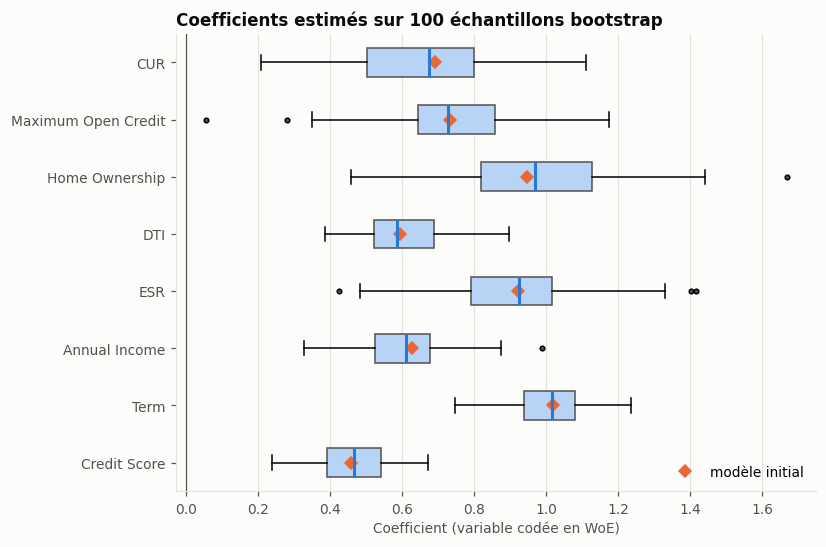

In [96]:
boot = md.bootstrap_coefficients(X_train, y_train, n_samples=100, random_state=RANDOM_STATE)
save_table(boot, "14_bootstrap_coefficients", index=True)
summary = md.bootstrap_summary(boot, model)
summary = summary.assign(ratio_ecarts_types=summary["ecart_type_bootstrap"] / summary["ecart_type_asymptotique"])
save_table(summary, "14_bootstrap_synthese")
display(summary)
fig = plots_model.plot_bootstrap_coefficients(boot, model.params)
plots.save(fig, FIGURES_DIR / "14_bootstrap_coefficients.png");

In [97]:
boot_auc = []
for _, params in boot.iterrows():
    p_test = md.pd_from_score(md.logistic_score(X_test, params))
    boot_auc.append(md.sample_metrics(y_test, p_test)["auc"])
boot_auc = pd.Series(boot_auc, name="auc_test")
print(f"AUC test des 100 modèles bootstrap : moyenne {boot_auc.mean():.4f}, écart-type {boot_auc.std():.4f}, "
      f"min {boot_auc.min():.4f}, max {boot_auc.max():.4f}")

AUC test des 100 modèles bootstrap : moyenne 0.6257, écart-type 0.0014, min 0.6211, max 0.6288


**Lecture : le modèle est robuste.**

- **Absence de biais.** La moyenne des 100 coefficients bootstrap est très proche du coefficient
  initial pour toutes les variables. Le biais le plus important est celui de CUR (−0,038, soit 5,5 % du
  coefficient, qui vaut 0,693). Les autres sont inférieurs à 0,025 en valeur absolue.
- **Dispersion cohérente avec la théorie.** L'écart-type bootstrap retrouve l'écart-type asymptotique
  de la régression (rapport compris entre 0,95 et 1,09). Les erreurs standards, et donc les tests de
  significativité de la partie 6, sont fiables.
- **Stabilité des signes.** Chaque coefficient garde son signe positif dans **100 % des échantillons**,
  et aucun intervalle percentile à 95 % ne contient 0 : le plus proche de 0 est celui de *Credit Score*,
  dont la borne basse vaut 0,27. Aucune variable ne change d'effet selon l'échantillon.
- **Précision relative.**
  - Elle est la meilleure pour *Term* (coefficient de variation de 0,10) et l'intercept (0,02).
  - Les variables à IV faible ont les coefficients les moins précis : CUR (CV de 0,29), *Maximum Open
    Credit* (0,25), *Home Ownership* (0,23). C'est attendu pour des variables au signal faible.
  - Même pour celles-ci, l'effet reste significativement positif.
- **Stabilité des prédictions.** Appliqués au même échantillon de test, les 100 modèles bootstrap ont une
  AUC comprise entre 0,621 et 0,629 (écart-type 0,0014). La capacité de classement du modèle ne dépend
  pas de l'échantillon d'estimation.

**Conclusion.** Les coefficients sont stables en valeur et en signe, leur incertitude est correctement
mesurée par la régression, et le pouvoir discriminant ne varie pas selon l'échantillon d'estimation.
Le modèle final est **robuste**.

## 2. Score logistique et probabilité de défaut (sujet 1.5.2)

Pour chaque emprunteur $i$, le score est calculé **explicitement** à partir des coefficients estimés :

$$S_i = \beta_0 + \sum_{j=1}^{p}\beta_j X_{ij}, \qquad \mathrm{PD}_i = \frac{1}{1+\exp(-S_i)} = \frac{\exp(S_i)}{1+\exp(S_i)} .$$

$X_{ij}$ est le WoE de la classe de l'emprunteur pour la variable $j$. On vérifie ensuite que :

- ce calcul donne exactement les PD prédites par statsmodels ;
- toutes les PD sont comprises entre 0 et 1.

In [98]:
coefficients = model.params.rename("beta").to_frame()
display(coefficients)
score_train, score_test = md.logistic_score(X_train, model.params), md.logistic_score(X_test, model.params)
pd_train, pd_test = md.pd_from_score(score_train), md.pd_from_score(score_test)
print("Écart maximal avec statsmodels :", float(np.abs(pd_train - md.predict_pd(model, X_train)).max()))
print("Toutes les PD dans [0, 1] :", bool(pd_train.between(0, 1).all() and pd_test.between(0, 1).all()))
example = pd.concat([prep.classes_train.loc[:2, final_vars].T, X_train.loc[:2].T.add_prefix("woe_")], axis=1)
print("\nExemple : classes et WoE des trois premiers emprunteurs de l'apprentissage")
display(example)
print("Scores :", score_train.loc[:2].round(4).tolist(), " PD :", pd_train.loc[:2].round(4).tolist())

,beta
const,-1.1836
Credit Score,0.4599
Term,1.0194
Annual Income,0.6274
ESR,0.9214
DTI,0.5941
Home Ownership,0.9479
Maximum Open Credit,0.7327
CUR,0.6931


Écart maximal avec statsmodels : 1.1102230246251565e-16
Toutes les PD dans [0, 1] : True

Exemple : classes et WoE des trois premiers emprunteurs de l'apprentissage


,0,1,2,woe_0,woe_1,woe_2
Credit Score,]692 ; 711],Manquant,]734 ; 742],-0.0671,0.2693,-0.0917
Term,Short Term,Short Term,Short Term,-0.1894,-0.1894,-0.1894
Annual Income,]1 166 543 ; +inf],Manquant,]1 166 543 ; +inf],-0.3363,0.2693,-0.3363
ESR,]0.3906 ; 0.4848],]0.3906 ; 0.4848],]0.4848 ; 0.6061],-0.1292,-0.1292,0.1231
DTI,]-inf ; 0.112],Manquant,]0.112 ; 0.167],-0.4589,0.2693,-0.1294
Home Ownership,Home Mortgage,Home Mortgage,Own Home + Rent,-0.1443,-0.1443,0.1287
Maximum Open Credit,]376 090 ; 566 126],]566 126 ; 876 920],]566 126 ; 876 920],0.0422,0.0935,0.0935
CUR,]0.4974 ; +inf],]-inf ; 0.4974] + Sans plafond,]-inf ; 0.4974] + Sans plafond,0.1357,-0.1437,-0.1437


Scores : [-2.0221, -1.2108, -1.5024]  PD : [0.1169, 0.2296, 0.1821]


,apprentissage,test
statistique,,
n,"7,861.0000","1,966.0000"
moyenne,0.2347,0.2308
ecart_type,0.0941,0.0940
min,0.0547,0.0547
q01,0.0683,0.0702
q05,0.0972,0.0937
q10,0.1182,0.1153
q25,0.1635,0.1590
q50,0.2249,0.2200


,classe,n,pd_moyenne,taux_observe
0,1,197,0.0926,0.1117
1,2,197,0.1317,0.1269
2,3,197,0.1588,0.1980
3,4,196,0.1844,0.1837
4,5,196,0.2079,0.2347
5,6,197,0.2328,0.2640
6,7,196,0.2635,0.2449
7,8,197,0.2923,0.2690
8,9,197,0.3304,0.3249
9,10,196,0.4143,0.3929


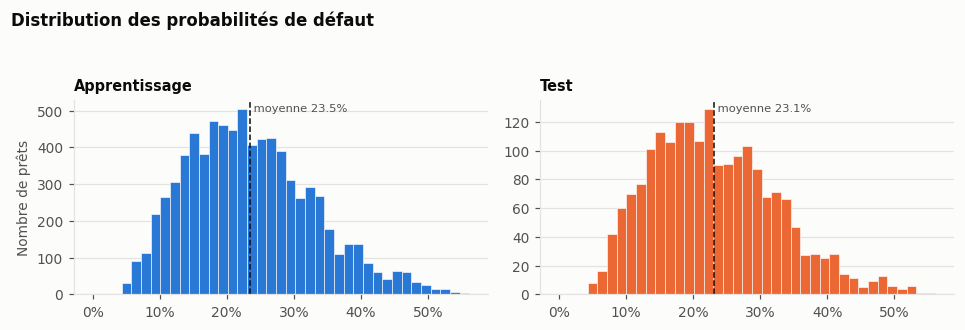

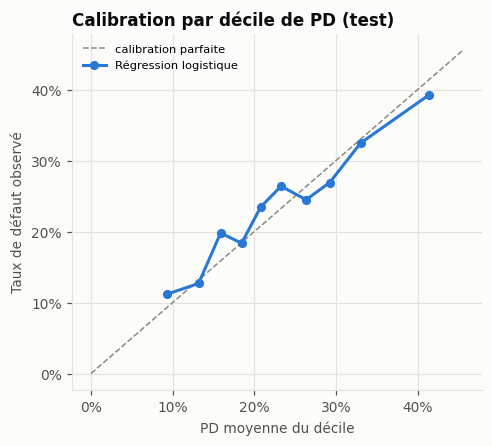

In [99]:
distribution = pd.concat({"apprentissage": md.distribution_summary(pd_train).set_index("statistique")["valeur"],
                          "test": md.distribution_summary(pd_test).set_index("statistique")["valeur"]}, axis=1)
save_table(distribution, "14_distribution_pd", index=True)
display(distribution)
fig = plots_model.plot_pd_distribution({"Apprentissage": pd_train, "Test": pd_test})
plots.save(fig, FIGURES_DIR / "14_distribution_pd.png")
calibration = md.calibration_table(y_test, pd_test)
save_table(calibration, "14_calibration_test")
display(calibration)
fig = plots_model.plot_calibration({"Régression logistique": calibration})
plots.save(fig, FIGURES_DIR / "14_calibration_logistique.png")
pd.DataFrame({"Loan ID": prep.test["Loan ID"], "score": score_test, "pd_logistique": pd_test,
              "default": y_test}).to_csv(PROCESSED_DIR / "pd_test_logistique.csv", index=False)

**Lecture**

- **Calcul explicite.** Le score calculé à partir des coefficients redonne exactement les PD de
  statsmodels (écart maximal $10^{-16}$, l'erreur d'arrondi machine). Toutes les PD sont dans [0, 1],
  comme le garantit la fonction logistique.
- **Exemple de calcul.** Le premier emprunteur a :
  - un score de crédit de 692 à 711 (WoE −0,07) ;
  - un prêt court (−0,19) ;
  - un revenu au-dessus de la médiane (−0,34) ;
  - un DTI ≤ 0,11 (−0,46).

  Les WoE négatifs l'emportent : son score vaut $S = -2{,}02$ et sa PD $1/(1+e^{2{,}02}) = 11{,}7\,\%$, la
  moitié du taux moyen. Le deuxième emprunteur, dont le revenu, le score et le DTI ne sont pas
  renseignés (WoE +0,27 chacun), a une PD de 23,0 %.
- **Distribution des PD.**
  - La moyenne vaut 23,5 % en apprentissage, ce qui est exactement le taux de défaut observé : c'est une
    propriété du maximum de vraisemblance avec constante. Elle vaut 23,1 % en test.
  - La médiane (22,5 %) est proche de la moyenne. Les PD vont de 5,5 % à 55,0 %. 90 % des emprunteurs ont
    une PD entre 9,7 % et 40,6 % (quantiles à 5 % et 95 %).
  - La distribution est concentrée autour du taux moyen : écart-type de 9,4 points. C'est la traduction
    directe d'un pouvoir discriminant modeste : le modèle sépare les emprunteurs, mais sans produire de
    PD très faibles ou très élevées.
  - Les distributions de l'apprentissage et du test sont presque identiques.
- **Calibration par décile (test).** Le taux de défaut observé croît du premier décile de PD (11,2 %) au
  dernier (39,3 %), et les PD moyennes suivent ce taux : 9,3 % à 41,4 %. Les écarts par décile
  (au plus 4 points, au 3e décile) restent compatibles avec la taille des déciles (environ 196 prêts) :
  les PD sont bien **calibrées**.

In [100]:
num3, num4, pct1, pct2 = number(3), number(4), percent(1), percent(2)
save_latex_table(summary[["variable", "coefficient_initial", "moyenne_bootstrap", "ecart_type_bootstrap",
                          "ecart_type_asymptotique", "biais", "percentile_2_5", "percentile_97_5", "part_meme_signe"]],
                 "14_bootstrap_synthese",
                 {"coefficient_initial": num4, "moyenne_bootstrap": num4, "ecart_type_bootstrap": num4,
                  "ecart_type_asymptotique": num4, "biais": num4, "percentile_2_5": num3, "percentile_97_5": num3,
                  "part_meme_signe": percent(0)}, "lrrrrrrrr")
save_latex_table(distribution.reset_index(), "14_distribution_pd",
                 {"apprentissage": lambda v: f"{v:,.0f}".replace(",", "\\,") if v > 1 else pct2(v),
                  "test": lambda v: f"{v:,.0f}".replace(",", "\\,") if v > 1 else pct2(v)}, "lrr")
save_latex_table(calibration, "14_calibration_test", {"n": number(0), "pd_moyenne": pct1, "taux_observe": pct1}, "rrrr")
print("Tableaux LaTeX écrits.")

Tableaux LaTeX écrits.


## Conclusion

- **Robustesse.** Les 100 réestimations bootstrap confirment :
  - des coefficients sans biais notable ;
  - une dispersion conforme aux erreurs standards ;
  - un signe positif dans 100 % des échantillons ;
  - une AUC test stable (0,621 à 0,629).
- **PD.** Calculées explicitement par $\mathrm{PD} = 1/(1+e^{-S})$, elles sont comprises entre 5,5 % et
  55,0 % et bien calibrées par décile.
- **Fichier produit.** Les PD du test sont enregistrées (`resultats/donnees/pd_test_logistique.csv`) pour
  la comparaison avec XGBoost (partie 8).

# Partie 8 — XGBoost et comparaison (sujet 1.5.3)

**Sujet, section 1.5.3.**

| Question du sujet | Section du notebook |
|---|---|
| Même échantillon d'apprentissage, mêmes variables explicatives | 1 |
| Ajustement des hyperparamètres par validation croisée / grille | 2 |
| PD de chaque emprunteur du test | 3 |
| Comparaison des PD des deux modèles sur le test | 3 et 4 |
| Modèle à privilégier dans un contexte bancaire réglementé | 5 |

**Principe.** XGBoost construit séquentiellement des arbres de décision peu profonds. Chaque nouvel
arbre corrige les erreurs des précédents en suivant le gradient de la log-vraisemblance binomiale (même
fonction de perte que la régression logistique). Contrairement à la régression logistique, il peut
capter :

- des **effets non linéaires** à l'intérieur d'une variable ;
- des **interactions** entre variables, sans qu'on ait à les spécifier.

In [101]:
import sys
from pathlib import Path


import pandas as pd
from IPython.display import display

from src import modeling as md
from src import pipeline, plots, plots_model
from src import xgb_model as xm
from src.config import FIGURES_DIR, PROCESSED_DIR, RANDOM_STATE
from src.reporting import auto_number, number, percent, save_latex_table, save_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plots.set_style()

prep = pipeline.prepare()
final_vars = pipeline.load_variables("final")
y_train, y_test = prep.y_train, prep.y_test
logit = md.fit_logit(prep.woe_train[final_vars], y_train)
pd_logit = md.predict_pd(logit, prep.woe_test[final_vars])
print("Variables :", final_vars)

Variables : ['Credit Score', 'Term', 'Annual Income', 'ESR', 'DTI', 'Home Ownership', 'Maximum Open Credit', 'CUR']


## 1. Mêmes données, mêmes variables

XGBoost est estimé sur le **même apprentissage** (7 861 prêts) et avec les **8 variables du modèle
logistique final**. Deux codages de ces variables sont comparés.

1. **Valeurs traitées (codage principal).** Les variables quantitatives gardent leurs valeurs continues
   issues des parties 1 à 3 : montants plafonnés, ratios. Les arbres trouvent eux-mêmes les seuils
   pertinents. Les valeurs manquantes sont conservées : XGBoost apprend, à chaque division, de quel côté
   les envoyer (gestion native). C'est légitime ici, puisque le manquant de *Credit Score*, *Annual
   Income* et *DTI* est informatif et a été traité comme une classe dans la régression logistique. Les
   variables qualitatives (*Term*, *Home Ownership*) deviennent des indicatrices.
2. **WoE (analyse de sensibilité).** Les mêmes colonnes WoE que la régression logistique. XGBoost ne peut
   alors exploiter que des interactions entre classes déjà définies, et non des seuils plus fins.

In [102]:
categorical = [v for v in final_vars if v in pipeline.CATEGORICAL_CANDIDATES]
levels = xm.fit_levels(prep.train, categorical)
X_raw_train, X_raw_test = (xm.raw_features(prep.train, final_vars, levels),
                           xm.raw_features(prep.test, final_vars, levels))
X_woe_train = prep.woe_train[final_vars].rename(columns=xm.safe_name)
X_woe_test = prep.woe_test[final_vars].rename(columns=xm.safe_name)
print("Modalités de référence :", {v: lv[0] for v, lv in levels.items()})
print("Colonnes (valeurs traitées) :", list(X_raw_train.columns))
print("Part de valeurs manquantes :", X_raw_train.isna().mean().round(3)[lambda s: s > 0].to_dict())

Modalités de référence : {'Term': 'Long Term', 'Home Ownership': 'Home Mortgage'}
Colonnes (valeurs traitées) : ['Credit_Score', 'Term_Short_Term', 'Annual_Income', 'ESR', 'DTI', 'Home_Ownership_Own_Home', 'Home_Ownership_Rent', 'Maximum_Open_Credit', 'CUR']
Part de valeurs manquantes : {'Credit_Score': 0.195, 'Annual_Income': 0.195, 'ESR': 0.044, 'DTI': 0.195, 'CUR': 0.008}


## 2. Ajustement des hyperparamètres (validation croisée sur grille)

La grille porte sur les principaux hyperparamètres :

| Hyperparamètre | Rôle | Valeurs testées |
|---|---|---|
| `n_estimators` | nombre d'arbres | 100, 300, 600 |
| `max_depth` | profondeur maximale, donc ordre maximal des interactions | 1, 2, 3, 4 |
| `learning_rate` | pas d'apprentissage (contribution de chaque arbre) | 0,01 ; 0,05 ; 0,1 |
| `min_child_weight` | poids minimal d'une feuille (régularisation) | 1, 10 |
| `subsample`, `colsample_bytree` | part des observations et des variables tirées pour chaque arbre | 0,8 |

Les 72 combinaisons sont évaluées par **validation croisée stratifiée à 5 plis sur l'apprentissage
seul**, avec l'AUC comme critère. Le test n'intervient pas dans le choix. La meilleure combinaison est
ensuite réestimée sur tout l'apprentissage. La graine est fixée (`random_state = 42`).

In [103]:
searches = {"valeurs traitées": xm.grid_search(X_raw_train, y_train, random_state=RANDOM_STATE),
            "WoE": xm.grid_search(X_woe_train, y_train, random_state=RANDOM_STATE)}
cv_tables = {}
for name, search in searches.items():
    cv_tables[name] = xm.cv_results_table(search, top=8)
    save_table(cv_tables[name], f"15_grille_xgboost_{'woe' if name == 'WoE' else 'brut'}")
    print(f"\n{name} — meilleurs hyperparamètres : {search.best_params_} ; AUC de validation croisée "
          f"{search.best_score_:.4f}")
    display(cv_tables[name])


valeurs traitées — meilleurs hyperparamètres : {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 1, 'min_child_weight': 10, 'n_estimators': 300, 'subsample': 0.8} ; AUC de validation croisée 0.6475


,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,subsample,auc_validation,ecart_type_validation,auc_apprentissage,rang
0,0.8000,0.0500,1,10,300,0.8000,0.6475,0.0154,0.6687,1
1,0.8000,0.0500,1,1,300,0.8000,0.6470,0.0156,0.6692,2
2,0.8000,0.0500,1,1,600,0.8000,0.6466,0.0149,0.6771,3
3,0.8000,0.1000,1,1,300,0.8000,0.6465,0.0150,0.6770,4
4,0.8000,0.0500,1,10,600,0.8000,0.6465,0.0148,0.6762,5
5,0.8000,0.1000,1,10,300,0.8000,0.6462,0.0144,0.6763,6
6,0.8000,0.0500,2,1,300,0.8000,0.6458,0.0155,0.7109,7
7,0.8000,0.0500,2,10,300,0.8000,0.6458,0.0145,0.7076,8



WoE — meilleurs hyperparamètres : {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 100, 'subsample': 0.8} ; AUC de validation croisée 0.6447


,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,subsample,auc_validation,ecart_type_validation,auc_apprentissage,rang
0,0.8000,0.1000,2,1,100,0.8000,0.6447,0.0132,0.6664,1
1,0.8000,0.1000,2,10,100,0.8000,0.6447,0.0131,0.6664,2
2,0.8000,0.0500,2,10,300,0.8000,0.6445,0.0116,0.6697,3
3,0.8000,0.0100,2,10,600,0.8000,0.6444,0.0124,0.6617,4
4,0.8000,0.0100,2,1,600,0.8000,0.6443,0.0125,0.6618,5
5,0.8000,0.0500,2,1,300,0.8000,0.6442,0.0120,0.6698,6
6,0.8000,0.1000,1,1,300,0.8000,0.6441,0.0111,0.6519,7
7,0.8000,0.1000,1,10,300,0.8000,0.6441,0.0111,0.6519,7


**Lecture de la recherche sur grille**

- **Valeurs traitées.**
  - Meilleure combinaison : **300 arbres de profondeur 1**, pas de 0,05, poids minimal de feuille de 10.
    AUC de validation croisée : 0,6475 (± 0,015 entre plis).
  - Les six meilleures combinaisons ont toutes une profondeur de 1. La première de profondeur 2 n'arrive
    qu'en 7e position (0,6458), avec une AUC d'apprentissage bien plus élevée (0,711 contre 0,669) : les
    arbres plus profonds sur-ajustent sans gagner en validation.
  - Un arbre de profondeur 1 (une seule division) ne fait intervenir qu'une variable. Le modèle retenu
    est donc une **somme d'effets univariés non linéaires**, sans interaction : un modèle additif, comme
    la régression logistique, mais avec des seuils appris finement sur les valeurs continues au lieu des
    classes de quantiles.
- **WoE.** La meilleure combinaison (100 arbres de profondeur 2) atteint 0,6447 en validation croisée.
- **Écarts entre combinaisons.** Ils sont faibles : moins de 0,002 d'AUC entre les huit premières, soit
  bien moins que l'écart-type entre plis (environ 0,015). Le choix précis des hyperparamètres a peu
  d'influence.

## 3. PD sur l'échantillon de test et comparaison des modèles

Chaque modèle produit, pour chaque emprunteur du test, une PD : la probabilité prédite de la classe
« défaut ». On compare sur le **même échantillon de test** de 1 966 prêts :

- la **discrimination** : AUC et AR ;
- la **qualité probabiliste** : log-vraisemblance, log-loss, score de Brier ;
- le **niveau moyen** : PD moyenne comparée au taux observé.

In [104]:
pd_xgb = pd.Series(searches["valeurs traitées"].best_estimator_.predict_proba(X_raw_test)[:, 1], index=X_raw_test.index)
pd_xgb_woe = pd.Series(searches["WoE"].best_estimator_.predict_proba(X_woe_test)[:, 1], index=X_woe_test.index)
predictions = {"Régression logistique": pd_logit, "XGBoost (valeurs traitées)": pd_xgb, "XGBoost (WoE)": pd_xgb_woe}
comparison = xm.comparison_table(y_test, predictions)
save_table(comparison, "15_comparaison_modeles_test")
display(comparison)
train_auc = {"Régression logistique": md.sample_metrics(y_train, md.predict_pd(logit, prep.woe_train[final_vars]))["auc"],
             "XGBoost (valeurs traitées)": md.sample_metrics(y_train, searches["valeurs traitées"].best_estimator_
                                                             .predict_proba(X_raw_train)[:, 1])["auc"],
             "XGBoost (WoE)": md.sample_metrics(y_train, searches["WoE"].best_estimator_
                                                .predict_proba(X_woe_train)[:, 1])["auc"]}
overfit = pd.DataFrame({"auc_apprentissage": train_auc, "auc_test": comparison.set_index("modele")["auc"]})
overfit = overfit.assign(ecart=overfit["auc_test"] - overfit["auc_apprentissage"])
display(overfit)

,modele,auc,accuracy_ratio,log_vraisemblance,log_loss,brier,pd_moyenne,taux_defaut_observe
0,Régression logistique,0.6268,0.2536,"-1,036.4351",0.5272,0.1735,0.2308,0.2350
1,XGBoost (valeurs traitées),0.6454,0.2908,"-1,028.3085",0.5230,0.1719,0.2311,0.2350
2,XGBoost (WoE),0.6318,0.2636,"-1,034.3486",0.5261,0.1731,0.2313,0.2350


,auc_apprentissage,auc_test,ecart
Régression logistique,0.6456,0.6268,-0.0188
XGBoost (valeurs traitées),0.6663,0.6454,-0.0209
XGBoost (WoE),0.6632,0.6318,-0.0314


In [105]:
differences = pd.DataFrame({name: xm.bootstrap_auc_difference(y_test, p, pd_logit, n_samples=1000,
                                                              random_state=RANDOM_STATE)
                            for name, p in predictions.items() if name != "Régression logistique"}).T
save_table(differences, "15_ecart_auc_bootstrap", index=True)
display(differences)

,ecart_auc,ic_bas,ic_haut,part_ecarts_negatifs
XGBoost (valeurs traitées),0.0186,0.0055,0.0307,0.0010
XGBoost (WoE),0.0050,-0.0055,0.0150,0.1510


**Lecture de la comparaison sur le test (1 966 prêts, 462 défauts)**

| Modèle | AUC | AR | Log-vraisemblance | Brier |
|---|---|---|---|---|
| Régression logistique | 0,627 | 0,254 | −1 036,4 | 0,1735 |
| XGBoost (valeurs traitées) | **0,645** | **0,291** | **−1 028,3** | **0,1719** |
| XGBoost (WoE) | 0,632 | 0,264 | −1 034,3 | 0,1731 |

- **XGBoost sur les valeurs traitées est meilleur sur tous les critères.**
  - Le gain d'AUC est de **+0,019** (AR +0,037), avec un intervalle de confiance bootstrap à 95 % de
    [+0,006 ; +0,031] qui exclut 0. L'écart est donc statistiquement significatif, mais modeste.
  - Avec des arbres de profondeur 1, ce gain ne vient pas d'interactions. Il vient d'une **utilisation
    plus fine des valeurs continues** : les arbres placent leurs seuils où le risque change, au lieu des
    4 à 7 classes de quantiles du WoE.
- **XGBoost sur les WoE ne fait pas mieux que la régression logistique.** L'écart (+0,005, IC
  [−0,006 ; +0,015]) n'est pas significatif. Une fois les variables résumées par leurs classes, les
  arbres n'ont presque rien à ajouter : il y a peu d'interactions exploitables entre ces variables.
- **Sur-ajustement.** La baisse d'AUC entre apprentissage et test est comparable pour la régression
  logistique (−0,019) et pour XGBoost sur valeurs traitées (−0,021). La validation croisée a choisi un
  modèle XGBoost peu complexe, qui ne sur-ajuste pas davantage.
- **Niveau moyen.** Les deux modèles reproduisent bien le taux de défaut du test : PD moyenne de 23,1 %
  pour un taux observé de 23,5 %.

,logistique vs XGBoost
correlation_pearson,0.9014
correlation_spearman,0.9036
ecart_absolu_moyen,0.0326
ecart_absolu_p95,0.0785


,logistique,xgboost
statistique,,
n,"1,966.0000","1,966.0000"
moyenne,0.2308,0.2311
ecart_type,0.0940,0.0869
min,0.0547,0.0294
q01,0.0702,0.0576
q05,0.0937,0.0913
q10,0.1153,0.1155
q25,0.1590,0.1725
q50,0.2200,0.2297


,variable,importance_gain
0,Term_Short_Term,0.2229
1,Annual_Income,0.1962
2,DTI,0.1324
3,Credit_Score,0.1218
4,CUR,0.0971
5,Home_Ownership_Rent,0.0960
6,ESR,0.0713
7,Maximum_Open_Credit,0.0623
8,Home_Ownership_Own_Home,0.0000


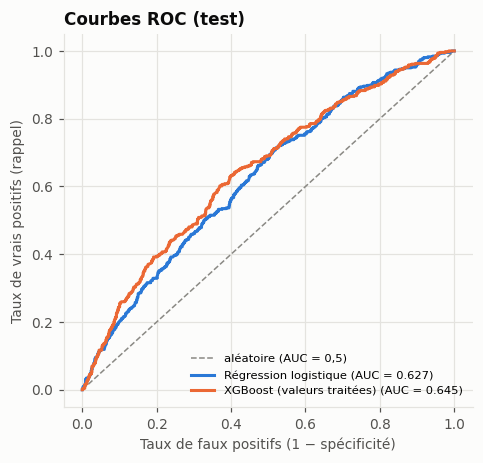

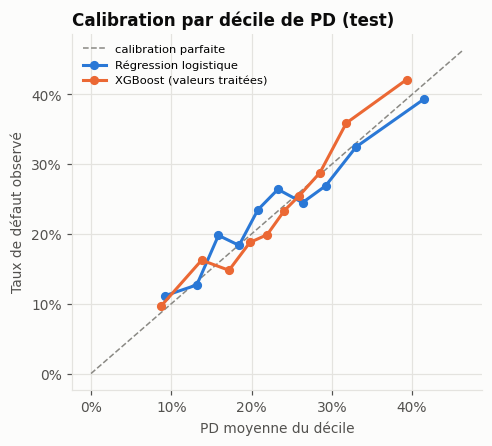

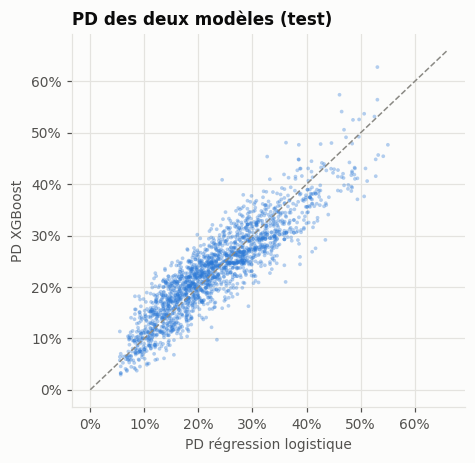

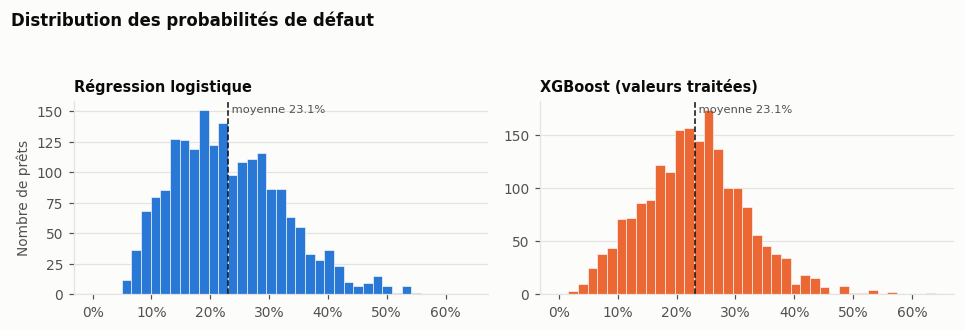

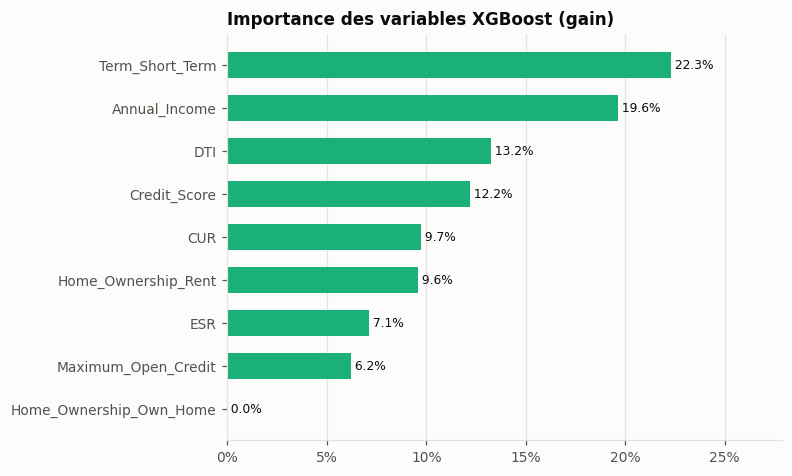

In [106]:
curves = {name: xm.roc_points(y_test, p) for name, p in predictions.items()}
fig = plots_model.plot_roc({k: curves[k] for k in ("Régression logistique", "XGBoost (valeurs traitées)")},
                           comparison.set_index("modele")["auc"].to_dict())
plots.save(fig, FIGURES_DIR / "15_roc_test.png")
calibration = {name: md.calibration_table(y_test, p) for name, p in
               [("Régression logistique", pd_logit), ("XGBoost (valeurs traitées)", pd_xgb)]}
fig = plots_model.plot_calibration(calibration)
plots.save(fig, FIGURES_DIR / "15_calibration_test.png")
agreement = pd.Series(xm.pd_agreement(pd_logit, pd_xgb), name="logistique vs XGBoost")
display(agreement.to_frame())
pd_stats = pd.concat({name: md.distribution_summary(p).set_index("statistique")["valeur"]
                      for name, p in [("logistique", pd_logit), ("xgboost", pd_xgb)]}, axis=1)
save_table(pd_stats, "15_distribution_pd_test", index=True)
display(pd_stats)
fig = plots_model.plot_pd_scatter(pd_logit, pd_xgb, "régression logistique", "XGBoost")
plots.save(fig, FIGURES_DIR / "15_pd_logistique_vs_xgboost.png")
fig = plots_model.plot_pd_distribution({"Régression logistique": pd_logit, "XGBoost (valeurs traitées)": pd_xgb})
plots.save(fig, FIGURES_DIR / "15_distribution_pd_test.png")
importance = xm.feature_importance(searches["valeurs traitées"].best_estimator_, list(X_raw_train.columns))
save_table(importance, "15_importance_xgboost")
display(importance)
fig = plots_model.plot_importance(importance)
plots.save(fig, FIGURES_DIR / "15_importance_xgboost.png")
pd.DataFrame({"Loan ID": prep.test["Loan ID"], "pd_logistique": pd_logit, "pd_xgboost": pd_xgb,
              "default": y_test}).to_csv(PROCESSED_DIR / "pd_test_comparaison.csv", index=False)

**Comparaison des PD individuelles**

- **Forte concordance.** Les PD des deux modèles sont fortement corrélées (Pearson 0,90, Spearman
  0,90). L'écart absolu moyen est de 3,3 points, et 95 % des emprunteurs ont un écart inférieur à
  7,8 points. Les deux modèles classent donc les emprunteurs de façon proche, mais pas identique (nuage
  de points).
- **Forme des distributions.**
  - XGBoost produit des PD plus dispersées aux extrémités : minimum de 2,9 % contre 5,5 %, maximum de
    62,8 % contre 55,0 %.
  - Sa distribution est plus resserrée au centre : écart-type de 8,7 points contre 9,4 ; quantile à 95 %
    de 37,9 % contre 40,3 %.
  - Les arbres attribuent ainsi des PD extrêmes à des combinaisons rares de valeurs, alors que la
    régression logistique lisse l'effet par classe.
- **Calibration.** Les deux modèles suivent la diagonale par décile, sans biais systématique. L'écart maximal
  entre PD moyenne et taux observé est d'environ 4 points pour chacun (3e décile pour la régression
  logistique, 9e pour XGBoost).
- **Importance des variables (gain).** L'ordre est cohérent avec les contributions de la régression
  logistique (partie 6) :
  - *Term* (22,3 %), *Annual Income* (19,6 %), *DTI* (13,2 %) et *Credit Score* (12,2 %) dominent ;
  - les autres variables comptent pour 6 à 10 % chacune ;
  - l'indicatrice *Own Home* n'est jamais utilisée (0 %) : la différence de risque se fait entre
    *Rent* et *Home Mortgage*.

## 5. Quel modèle privilégier dans un contexte bancaire réglementé ?

**Recommandation : la régression logistique est le modèle à privilégier comme modèle de PD
réglementaire. XGBoost est un outil de challenge et de diagnostic.**

| Critère | Régression logistique (WoE) | XGBoost |
|---|---|---|
| Discrimination (test) | AUC 0,627 | AUC 0,645 (+0,019, significatif mais modeste) |
| Interprétabilité | Une ligne de score par classe ($\beta \times$ WoE), signes contrôlés, odds ratios | 300 arbres ; explication par variable seulement via des outils post-hoc (importance, SHAP) |
| Contrôle du sens économique | Coefficients tous positifs : un risque croissant par classe est garanti | Aucune contrainte : une relation non monotone ou contre-intuitive peut apparaître sans être vue |
| Robustesse démontrée | 100 bootstraps : coefficients stables, signes constants | Non démontrée avec la même transparence ; sensible aux hyperparamètres |
| Explication d'une décision à un client (refus de crédit) | Directe : contribution de chaque variable au score | Indirecte, approximative |
| Validation, audit, suivi (PSI, backtesting par classe) | Standard, documenté classe par classe | Plus lourd ; suivi de l'importance et de la stabilité des arbres |
| Exigences réglementaires (modèles de notation interne, guide de la BCE sur les modèles internes, explicabilité au sens de l'AI Act pour le scoring de crédit) | Pratique éprouvée et acceptée par les superviseurs | Admissible en principe, mais charge de justification beaucoup plus élevée |

**Justification**

1. **Le gain de performance est faible.** +0,019 d'AUC, sur un modèle qui reste faiblement discriminant
   dans les deux cas. Il ne compense pas la perte de transparence. Comme le rappelle le projet, une
   meilleure performance prédictive ne rend pas automatiquement un modèle préférable.
2. **L'origine du gain est connue.** Avec des arbres de profondeur 1, le gain vient de seuils plus fins
   sur les variables continues, pas d'interactions. On peut donc en récupérer une partie **dans la
   régression logistique**, en affinant la discrétisation des variables où XGBoost trouve des seuils
   utiles (*Annual Income*, *DTI*, *Credit Score*), sans renoncer à son interprétabilité.
3. **Usage recommandé de XGBoost : modèle challenger.**
   - Il confirme que le modèle logistique ne laisse pas d'interaction majeure inexploitée : le
     XGBoost sur WoE ne fait pas mieux.
   - Il indique les variables dont le découpage gagnerait à être revu.
   - Il peut servir de référence de performance lors du suivi du modèle.

In [107]:
num4, pct1, pct2 = number(4), percent(1), percent(2)
best_params = pd.DataFrame({name: s.best_params_ | {"auc_validation_croisee": s.best_score_}
                            for name, s in searches.items()}).reset_index().rename(columns={"index": "hyperparametre"})
save_table(best_params, "15_hyperparametres_retenus")
save_latex_table(best_params, "15_hyperparametres_retenus",
                 {c: auto_number for c in searches}, "lrr")
save_latex_table(comparison[["modele", "auc", "accuracy_ratio", "log_vraisemblance", "log_loss", "brier", "pd_moyenne",
                             "taux_defaut_observe"]], "15_comparaison_modeles_test",
                 {"auc": num4, "accuracy_ratio": num4, "log_vraisemblance": number(1), "log_loss": num4, "brier": num4,
                  "pd_moyenne": pct2, "taux_defaut_observe": pct2}, "lrrrrrrr")
save_latex_table(differences.reset_index().rename(columns={"index": "modele"}), "15_ecart_auc_bootstrap",
                 {"ecart_auc": num4, "ic_bas": num4, "ic_haut": num4, "part_ecarts_negatifs": pct1}, "lrrrr")
save_latex_table(importance, "15_importance_xgboost", {"importance_gain": pct1}, "lr")
print("Tableaux LaTeX écrits.")

Tableaux LaTeX écrits.


## Conclusion

- **Construction de XGBoost.** Il est construit sur le même apprentissage et les mêmes 8 variables que
  la régression logistique. Ses hyperparamètres ont été choisis par validation croisée à 5 plis sur
  72 combinaisons.
- **Performance.** XGBoost sur valeurs traitées atteint une AUC test de 0,645, contre 0,627 pour la
  régression logistique. L'écart est significatif mais modeste, et il provient de seuils plus fins, pas
  d'interactions.
- **PD.** Les PD des deux modèles sont fortement concordantes (corrélation 0,90) et toutes deux bien
  calibrées.
- **Recommandation.** Dans un contexte réglementé, **la régression logistique est recommandée** pour sa
  transparence, sa robustesse démontrée et son contrôle du sens économique. XGBoost sert de challenger
  et oriente les améliorations possibles de la discrétisation.

# Partie 9 — Tests unitaires

Les tests vérifient les propriétés essentielles du code :

- formules du sujet (WoE, IV, PSI, T de Tschuprow, V de Cramér, AR) ;
- divisions par zéro ;
- apprentissage des paramètres sur l'apprentissage seul ;
- absence de modification des entrées ;
- reproductibilité.

Chaque cellule `%%testfile` ci-dessous contient un fichier de tests. Elle l'enregistre en mémoire sans
l'exécuter. La dernière cellule écrit ces fichiers dans un dossier temporaire, les exécute avec
**pytest** sur les modules définis plus haut, puis supprime le dossier.

In [108]:
TEST_FILES: dict[str, str] = {}


@register_cell_magic
def testfile(line: str, cell: str) -> None:
    """Enregistre le contenu de la cellule comme fichier de tests ``line``."""
    TEST_FILES[line.strip()] = cell
    print(f"{line.strip()} : {cell.count('def test_')} tests")

### `test_binning.py`

In [109]:
%%testfile test_binning.py
"""Tests de la discrétisation, du Khi², du T de Tschuprow, du WoE et de l'IV."""

import numpy as np
import pandas as pd
import pytest

from src.binning import (
    BinningSpec,
    apply_spec,
    association,
    cramers_v,
    enforce_min_share,
    fit_categorical_binning,
    fit_numeric_binning,
    fit_woe,
    information_value,
    iv_strength,
    numeric_atoms,
    quantile_edges,
    tschuprow_t,
    woe_table,
    woe_transform,
)
from src.imputation import apply_imputation, fit_imputation


@pytest.fixture
def risky_x() -> tuple[pd.Series, pd.Series]:
    rng = np.random.default_rng(0)
    x = pd.Series(rng.uniform(0, 1, 4000))
    y = pd.Series((rng.uniform(0, 1, 4000) < 0.1 + 0.3 * x).astype(int))
    return x, y


def test_tschuprow_and_cramer_match_definitions() -> None:
    assert tschuprow_t(100.0, 1000, 5) == pytest.approx(np.sqrt(100 / (1000 * np.sqrt(4))))
    assert cramers_v(100.0, 1000, 5) == pytest.approx(np.sqrt(100 / 1000))
    assert tschuprow_t(100.0, 1000, 2) == pytest.approx(cramers_v(100.0, 1000, 2))


def test_quantile_edges_and_atoms(risky_x: tuple[pd.Series, pd.Series]) -> None:
    x, _ = risky_x
    edges = quantile_edges(x, 4)
    assert len(edges) == 3
    atoms = numeric_atoms(pd.concat([x, pd.Series([np.nan])], ignore_index=True), edges)
    assert atoms.iloc[-1] == "Manquant"
    assert atoms.iloc[:-1].value_counts(normalize=True).between(0.24, 0.26).all()


def test_woe_and_iv_follow_annex_formulas() -> None:
    classes = pd.Series(["a"] * 100 + ["b"] * 100)
    y = pd.Series([1] * 30 + [0] * 70 + [1] * 10 + [0] * 90)
    table = woe_table(classes, y).set_index("classe")
    bad, good = np.array([30, 10]) / 40, np.array([70, 90]) / 160
    assert table.loc["a", "woe"] == pytest.approx(np.log(bad[0] / good[0]))
    assert information_value(classes, y) == pytest.approx(np.sum((bad - good) * np.log(bad / good)))
    assert information_value(classes, y) > 0


def test_woe_smoothing_handles_class_without_bad() -> None:
    table = woe_table(pd.Series(["a"] * 10 + ["b"] * 10), pd.Series([0] * 10 + [1, 0] * 5))
    assert np.isfinite(table["woe"]).all()


def test_iv_strength_thresholds() -> None:
    assert [iv_strength(v) for v in (0.01, 0.05, 0.2, 0.4, 0.6)] == [
        "non prédictive", "faible", "moyen", "fort", "très fort (à examiner)"]


def test_numeric_binning_selects_max_tschuprow_and_respects_min_share(risky_x) -> None:
    x, y = risky_x
    spec, candidates = fit_numeric_binning(x, y, variable="x")
    retained = candidates.loc[candidates["retenu"]].iloc[0]
    assert retained["tschuprow_t_final"] == candidates["tschuprow_t_final"].max()
    classes = apply_spec(x.to_frame("x"), spec)
    assert classes.value_counts(normalize=True).min() >= 0.05


def test_small_missing_class_is_merged(risky_x) -> None:
    x, y = risky_x
    x = x.copy()
    x.iloc[:20] = np.nan  # 0,5 % de manquants : sous le seuil de 5 %
    spec, _ = fit_numeric_binning(x, y, variable="x")
    assert "Manquant" not in spec.order
    assert any("Manquant" in c for c in spec.order)


def test_enforce_min_share_merges_with_closest_neighbour() -> None:
    atoms = pd.Series(["a"] * 50 + ["b"] * 2 + ["c"] * 48)
    y = pd.Series([0] * 45 + [1] * 5 + [1, 1] + [1] * 20 + [0] * 28)
    groups = enforce_min_share(atoms, y, None, ["a", "b", "c"], special=None)
    assert groups["b"] == groups["c"]  # b (100 % de défaut) rejoint c (taux le plus proche)


def test_categorical_grouping_and_unknown_modality() -> None:
    rng = np.random.default_rng(1)
    x = pd.Series(rng.choice(["A", "B", "C", "D", "E"], 5000, p=[0.3, 0.3, 0.2, 0.15, 0.05]))
    rate = x.map({"A": 0.1, "B": 0.1, "C": 0.3, "D": 0.3, "E": 0.3})
    y = pd.Series((rng.uniform(0, 1, 5000) < rate).astype(int))
    spec = fit_categorical_binning(x, y, variable="v")
    assert len(spec.order) == 2  # A+B (10 %) et C+D+E (30 %)
    assert apply_spec(pd.DataFrame({"v": ["Z"]}), spec).iloc[0] == spec.default_class


def test_woe_transform_uses_train_values(risky_x) -> None:
    x, y = risky_x
    spec, _ = fit_numeric_binning(x, y, variable="x")
    classes = apply_spec(x.to_frame("x"), spec).to_frame()
    maps = fit_woe(classes, y, {"x": spec})
    encoded = woe_transform(classes, maps)
    assert encoded["x"].nunique() == len(spec.order)
    assert association(classes["x"], y)["cramer_v"] > 0


def test_apply_spec_rejects_unknown_classes() -> None:
    spec = BinningSpec("v", "nominal", groups={"A": "A"}, order=("A",))
    with pytest.raises(ValueError):
        apply_spec(pd.DataFrame({"v": ["B"]}), spec)


def test_hot_deck_imputation_draws_from_train_pool() -> None:
    train = pd.DataFrame({"Current Loan Amount": [1.0, 2.0, np.nan], "Bankruptcies": [0.0, 0.0, np.nan]})
    params = fit_imputation(train)
    imputed = apply_imputation(train, params)
    assert imputed["Current Loan Amount"].iloc[2] in (1.0, 2.0)
    assert imputed["Bankruptcies"].iloc[2] == 0.0
    assert apply_imputation(train, params).equals(imputed)  # reproductible
    assert np.isnan(train["Current Loan Amount"].iloc[2])  # entrée non modifiée

test_binning.py : 12 tests


### `test_data_quality.py`

In [110]:
%%testfile test_data_quality.py
"""Tests unitaires du chargement et de l'analyse de qualité des données."""

import numpy as np
import pandas as pd
import pytest

from src.config import LOAN_AMOUNT_SENTINEL
from src.data_loading import encode_target
from src.data_quality import (
    changed_cells,
    chi2_pvalue,
    dominant_modality_table,
    harmonize_labels,
    label_variants,
    missing_token_counts,
    parse_years_in_job,
    replace_loan_amount_sentinel,
    rescale_credit_score,
    resolve_loan_id_duplicates,
)


def test_encode_target_maps_default_to_one() -> None:
    status = pd.Series(["Charged Off", "Fully Paid", "Fully Paid"])
    assert encode_target(status).tolist() == [1, 0, 0]


def test_encode_target_rejects_unknown_label() -> None:
    with pytest.raises(ValueError):
        encode_target(pd.Series(["Charged Off", "Current"]))


def test_encode_target_rejects_missing_label() -> None:
    with pytest.raises(ValueError):
        encode_target(pd.Series(["Charged Off", None]))


def test_parse_years_in_job_handles_special_labels() -> None:
    values = pd.Series(["< 1 year", "1 year", "7 years", "10+ years", pd.NA])
    parsed = parse_years_in_job(values)
    assert parsed.iloc[:4].tolist() == [0.0, 1.0, 7.0, 10.0]
    assert np.isnan(parsed.iloc[4])


def test_missing_token_counts_separates_tokens() -> None:
    raw = pd.DataFrame({"a": ["", "NA", "n/a", "1", ""], "b": ["x", "y", "z", "NA", "w"]})
    counts = missing_token_counts(raw, ["a", "b"])
    assert counts.loc["a"].tolist() == [2, 1, 1]
    assert counts.loc["b"].tolist() == [0, 1, 0]


def test_replace_loan_amount_sentinel() -> None:
    df = pd.DataFrame({"Current Loan Amount": [1000.0, float(LOAN_AMOUNT_SENTINEL)]})
    out = replace_loan_amount_sentinel(df)
    assert out["Current Loan Amount"].iloc[0] == 1000.0
    assert np.isnan(out["Current Loan Amount"].iloc[1])
    assert df["Current Loan Amount"].iloc[1] == LOAN_AMOUNT_SENTINEL  # entrée non modifiée


def test_rescale_credit_score_only_above_850() -> None:
    df = pd.DataFrame({"Credit Score": [700.0, 850.0, 7100.0, np.nan]})
    out = rescale_credit_score(df)["Credit Score"]
    assert out.iloc[:3].tolist() == [700.0, 850.0, 710.0]
    assert np.isnan(out.iloc[3])


def test_resolve_duplicates_keeps_most_complete_row() -> None:
    df = pd.DataFrame(
        {
            "Loan ID": ["a", "a", "b", "b", "c"],
            "x": [np.nan, 1.0, 2.0, 2.0, 3.0],
            "y": [5.0, 5.0, 6.0, 6.0, np.nan],
        }
    )
    out = resolve_loan_id_duplicates(df)
    assert out["Loan ID"].tolist() == ["a", "b", "c"]
    assert out.loc[out["Loan ID"] == "a", "x"].item() == 1.0


def test_harmonize_labels_merges_variants() -> None:
    df = pd.DataFrame({"Purpose": ["other", "Other", "Buy a Car"]})
    out = harmonize_labels(df, {"Purpose": {"other": "Other"}})
    assert out["Purpose"].tolist() == ["Other", "Other", "Buy a Car"]


def test_label_variants_detects_case_and_separator_duplicates() -> None:
    df = pd.DataFrame({"Purpose": ["other", "Other", "small_business", "Small Business", "Car"]})
    found = label_variants(df, ["Purpose"])
    assert sorted(found["modalités"]) == ["Other | other", "Small Business | small_business"]


def test_dominant_modality_counts_missing_as_modality() -> None:
    df = pd.DataFrame({"v": [np.nan] * 3 + [1.0]})
    y = pd.Series([0, 1, 0, 1])
    row = dominant_modality_table(df, y, ["v"], threshold=0.7).iloc[0]
    assert row["modalité_dominante"] == "Manquant"
    assert row["part_dominante"] == 0.75
    assert bool(row["dépasse_70%"])


def test_chi2_pvalue_returns_nan_for_constant_feature() -> None:
    assert np.isnan(chi2_pvalue(pd.Series([1, 1, 1]), pd.Series([0, 1, 0])))


def test_changed_cells_ignores_shared_missing() -> None:
    before = pd.DataFrame({"a": [1.0, np.nan, 3.0]})
    after = pd.DataFrame({"a": [1.0, np.nan, np.nan]})
    assert changed_cells(before, after) == 1

test_data_quality.py : 13 tests


### `test_features.py`

In [111]:
%%testfile test_features.py
"""Tests des variables dérivées (DTI, CUR, ACR, ESR, IES)."""

import numpy as np
import pandas as pd
import pytest

from src.features import (
    FeatureParams,
    add_features,
    compute_ratios,
    derive_features,
    expected_vs_observed,
    fit_feature_params,
    safe_divide,
    undefined_report,
)
from src.outliers import Bounds

NO_LIMIT = Bounds(-np.inf, np.inf)


def _loans() -> pd.DataFrame:
    return pd.DataFrame(
        {
            "Loan ID": ["a", "b", "c", "d"],
            "Monthly Debt": [1_000.0, 500.0, 0.0, 200.0],
            "Annual Income": [120_000.0, np.nan, 60_000.0, 0.0],
            "Current Credit Balance": [300.0, 50.0, 0.0, 10.0],
            "Maximum Open Credit": [1_000.0, 0.0, 0.0, 1e12],
            "Years in current job": ["10+ years", "< 1 year", pd.NA, "4 years"],
            "Years of Credit History": [20.0, 5.0, 8.0, 0.0],
        }
    )


def test_safe_divide_never_returns_inf() -> None:
    result = safe_divide(pd.Series([1.0, 1.0, 1.0, np.nan]), pd.Series([2.0, 0.0, np.nan, 1.0]))
    assert result.iloc[0] == 0.5
    assert result.iloc[1:].isna().all()
    assert not np.isinf(result).any()


def test_ratios_follow_subject_formulas() -> None:
    ratios = compute_ratios(_loans(), NO_LIMIT)
    row = ratios.iloc[0]
    assert row["DTI"] == pytest.approx(12 * 1_000 / 120_000)
    assert row["CUR"] == pytest.approx(0.3)
    assert row["ACR"] == pytest.approx(0.7)
    assert row["ESR"] == pytest.approx(10 / 20)
    assert row["IES"] == pytest.approx(120_000 * 10)


def test_acr_is_one_minus_cur_when_defined() -> None:
    ratios = compute_ratios(_loans(), NO_LIMIT).dropna(subset=["CUR"])
    assert np.allclose(ratios["ACR"], 1 - ratios["CUR"])


def test_zero_or_missing_denominators_give_nan() -> None:
    ratios = compute_ratios(_loans(), NO_LIMIT)
    assert np.isnan(ratios.loc[1, "DTI"])  # revenu manquant
    assert np.isnan(ratios.loc[3, "DTI"])  # revenu nul
    assert ratios.loc[[1, 2], ["CUR", "ACR"]].isna().all().all()  # plafond nul
    assert np.isnan(ratios.loc[3, "ESR"])  # ancienneté de crédit nulle
    assert np.isnan(ratios.loc[2, "ESR"])  # ancienneté d'emploi manquante


def test_less_than_one_year_gives_zero_ies_and_esr() -> None:
    ratios = compute_ratios(_loans().assign(**{"Annual Income": 50_000.0}), NO_LIMIT)
    assert ratios.loc[1, "IES"] == 0.0
    assert ratios.loc[1, "ESR"] == 0.0


def test_suspicious_limit_makes_utilisation_undefined() -> None:
    ratios = compute_ratios(_loans(), Bounds(0.0, 1e6))
    assert ratios.loc[3, ["CUR", "ACR"]].isna().all()
    assert ratios.loc[0, "CUR"] == pytest.approx(0.3)


def test_undefined_report_counts_causes() -> None:
    report = undefined_report(_loans(), FeatureParams(NO_LIMIT, NO_LIMIT)).set_index(["variable", "cause"])
    assert report.loc[("CUR", "plafond nul"), "n"] == 2
    assert report.loc[("DTI", "total non défini"), "n"] == 2


def test_params_are_fitted_on_train_and_ies_is_capped() -> None:
    train = pd.concat([_loans()] * 30, ignore_index=True).assign(
        **{"Loan ID": lambda d: d.index.astype(str), "Annual Income": np.linspace(1e4, 1e6, 120)}
    )
    params = fit_feature_params(train)
    features = derive_features(train, params)
    assert features["IES"].max() == pytest.approx(params.ies_cap.upper)


def test_add_features_requires_aligned_tables() -> None:
    loans = _loans()
    params = FeatureParams(NO_LIMIT, NO_LIMIT)
    assert set(add_features(loans, loans, params).columns) >= {"DTI", "CUR", "ACR", "ESR", "IES"}
    with pytest.raises(ValueError):
        add_features(loans.iloc[::-1], loans, params)


def test_expected_vs_observed_detects_increasing_risk() -> None:
    x = pd.Series(np.arange(100.0))
    df = pd.DataFrame({name: x for name in ["DTI", "CUR", "ACR", "ESR", "IES"]})
    y = pd.Series((x >= 50).astype(int))
    table = expected_vs_observed(df, y).set_index("variable")
    assert table.loc["DTI", "conforme"]
    assert not table.loc["ACR", "conforme"]

test_features.py : 10 tests


### `test_outliers.py`

In [112]:
%%testfile test_outliers.py
"""Tests unitaires de la détection et du traitement des valeurs aberrantes."""

import numpy as np
import pandas as pd
import pytest

from src.outliers import (
    Bounds,
    apply_capping,
    cap,
    delete,
    fit_capping,
    impute_median,
    iqr_bounds,
    is_outlier,
    log_iqr_bounds,
    method_overlap,
    quantile_bins_preserved,
    sigma_bounds,
)


@pytest.fixture
def values() -> pd.Series:
    return pd.Series([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 100.0, np.nan])


def test_sigma_bounds_match_definition(values: pd.Series) -> None:
    x = values.dropna()
    bounds = sigma_bounds(values)
    assert bounds.lower == pytest.approx(x.mean() - 3 * x.std())
    assert bounds.upper == pytest.approx(x.mean() + 3 * x.std())


def test_iqr_bounds_match_tukey_fences(values: pd.Series) -> None:
    q1, q3 = values.dropna().quantile([0.25, 0.75])
    assert iqr_bounds(values) == Bounds(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))


def test_is_outlier_ignores_missing(values: pd.Series) -> None:
    mask = is_outlier(values, iqr_bounds(values))
    assert mask.tolist() == [False] * 8 + [True, False]


def test_sigma_rule_masks_extreme_value_in_small_sample() -> None:
    # Une valeur très extrême gonfle l'écart-type au point de ne plus être détectée.
    x = pd.Series([1.0, 2.0, 3.0, 4.0, 1000.0])
    assert not is_outlier(x, sigma_bounds(x)).any()
    assert is_outlier(x, iqr_bounds(x)).iloc[-1]


def test_log_iqr_bounds_are_positive_and_ordered() -> None:
    bounds = log_iqr_bounds(pd.Series(np.exp(np.arange(1.0, 21.0))))
    assert 0 < bounds.lower < bounds.upper


def test_cap_delete_and_impute(values: pd.Series) -> None:
    bounds = Bounds(-np.inf, 10.0)
    mask = is_outlier(values, bounds)
    assert cap(values, bounds).max() == 10.0
    assert delete(values, mask).notna().sum() == 8
    assert impute_median(values, mask).iloc[8] == values[:8].median()


def test_capping_is_fitted_on_train_only() -> None:
    train = pd.DataFrame({"a": np.arange(1.0, 101.0)})
    test = pd.DataFrame({"a": [50.0, 1_000.0]})
    bounds = fit_capping(train, ["a"], q=0.99)
    capped = apply_capping(test, bounds)
    assert capped["a"].tolist() == [50.0, train["a"].quantile(0.99)]
    assert test["a"].iloc[1] == 1_000.0  # entrée non modifiée


def test_method_overlap_flags_zero_iqr() -> None:
    df = pd.DataFrame({"count": [0.0] * 18 + [1.0, 5.0]})
    row = method_overlap(df, ["count"]).iloc[0]
    assert row["iqr_nul"]
    assert row["seulement_IQR"] + row["les_deux"] == 2


def test_capping_upper_tail_preserves_quantile_bins() -> None:
    x = pd.Series(np.arange(1.0, 1001.0))
    assert quantile_bins_preserved(x, cap(x, Bounds(-np.inf, x.quantile(0.99))))

test_outliers.py : 9 tests


### `test_sampling_reporting.py`

In [113]:
%%testfile test_sampling_reporting.py
"""Tests du découpage apprentissage / test et de l'export LaTeX."""

import numpy as np
import pandas as pd

from src.reporting import header_label, number, percent, pvalue, to_latex_tabular
from src.sampling import split_summary, stratified_split


def _toy_dataset() -> pd.DataFrame:
    return pd.DataFrame({"x": np.arange(1000), "default": [1] * 250 + [0] * 750})


def test_split_is_stratified_and_reproducible() -> None:
    df = _toy_dataset()
    first, second = stratified_split(df), stratified_split(df)
    assert first.train.index.equals(second.train.index)
    assert len(first.test) == 200
    assert first.train["default"].mean() == first.test["default"].mean() == 0.25


def test_split_has_no_overlap_and_covers_all_rows() -> None:
    split = stratified_split(_toy_dataset())
    assert split.train.index.intersection(split.test.index).empty
    assert split_summary(split)["effectif"].tolist() == [1000, 800, 200]


def test_latex_formatters() -> None:
    assert percent(1)(0.2307) == "23,1\\,\\%"
    assert number(0)(9827) == "9\\,827"
    assert pvalue(0.0001) == "$<$\\,0,001"


def test_header_label_is_readable() -> None:
    assert header_label("taux_defaut_autres") == "taux défaut autres"
    assert header_label("p_value_khi2") == "p-value Khi²"


def test_latex_tabular_escapes_special_characters() -> None:
    table = pd.DataFrame({"variable": ["Tax_Liens & co"], "taux": [0.5]})
    latex = to_latex_tabular(table, {"taux": percent(0)})
    assert "Tax\\_Liens \\& co & 50\\,\\% \\\\" in latex
    assert latex.startswith("\\begin{tabular}{lr}")

test_sampling_reporting.py : 5 tests


### `test_selection_modeling.py`

In [114]:
%%testfile test_selection_modeling.py
"""Tests du PSI, de la sélection des variables, de la régression logistique et de XGBoost."""

import numpy as np
import pandas as pd
import pytest

from src import modeling as md
from src.selection import bootstrap_indices, correlated_pairs, psi, psi_status
from src.xgb_model import bootstrap_auc_difference, pd_agreement


@pytest.fixture
def logistic_data() -> tuple[pd.DataFrame, pd.Series]:
    rng = np.random.default_rng(0)
    X = pd.DataFrame({"a": rng.normal(size=3000), "b": rng.normal(size=3000), "bruit": rng.normal(size=3000)})
    p = 1 / (1 + np.exp(-(-1 + 0.8 * X["a"] + 0.5 * X["b"])))
    return X, pd.Series((rng.uniform(size=3000) < p).astype(int))


def test_psi_is_positive_symmetric_and_zero_for_identical() -> None:
    p = pd.Series({"a": 0.5, "b": 0.3, "c": 0.2})
    q = pd.Series({"a": 0.3, "b": 0.4, "c": 0.3})
    assert psi(p, p) == pytest.approx(0.0)
    assert psi(p, q) > 0
    assert psi(p, q) == pytest.approx(psi(q, p))
    assert psi(p, q) == pytest.approx(float(((q - p) * np.log(q / p)).sum()))


def test_psi_thresholds_and_empty_class() -> None:
    assert [psi_status(v) for v in (0.05, 0.15, 0.3)] == ["stable", "à surveiller", "instable"]
    assert np.isfinite(psi(pd.Series({"a": 1.0}), pd.Series({"a": 0.9, "b": 0.1})))


def test_bootstrap_indices_are_reproducible() -> None:
    first, second = bootstrap_indices(100, 4), bootstrap_indices(100, 4)
    assert len(first) == 4 and all((a == b).all() for a, b in zip(first, second))


def test_correlated_pairs_flags_perfect_redundancy() -> None:
    from src.binning import BinningSpec
    classes = pd.DataFrame({"u": ["x", "y"] * 50, "v": ["x", "y"] * 50, "w": ["x"] * 50 + ["y"] * 50})
    woe = classes.apply(lambda col: col.map({"x": -0.5, "y": 0.5}))
    specs = {c: BinningSpec(c, "nominal") for c in classes}
    pairs = correlated_pairs(classes, woe, specs, pd.Series({"u": 0.2, "v": 0.1, "w": 0.3}))
    row = pairs.loc[(pairs["variable_1"] == "u") & (pairs["variable_2"] == "v")].iloc[0]
    assert row["redondante"] and row["a_exclure"] == "v"


def test_logit_metrics_and_accuracy_ratio(logistic_data) -> None:
    X, y = logistic_data
    result = md.fit_logit(X[["a", "b"]], y)
    metrics = md.model_metrics(result, X[["a", "b"]], y)
    assert metrics["accuracy_ratio"] == pytest.approx(2 * metrics["auc"] - 1)
    assert metrics["aic"] == pytest.approx(-2 * metrics["log_vraisemblance"] + 2 * 3)
    table = md.coefficient_table(result).set_index("variable")
    assert table.loc["a", "odds_ratio"] == pytest.approx(np.exp(table.loc["a", "coefficient"]))


def test_explicit_score_matches_model_prediction(logistic_data) -> None:
    X, y = logistic_data
    result = md.fit_logit(X[["a", "b"]], y)
    pd_manual = md.pd_from_score(md.logistic_score(X, result.params))
    assert np.allclose(pd_manual, md.predict_pd(result, X))
    assert pd_manual.between(0, 1).all()


def test_stepwise_drops_noise_in_all_directions(logistic_data) -> None:
    X, y = logistic_data
    for direction in ("forward", "backward", "both"):
        selected, path = md.stepwise(X, y, direction, "bic")
        assert sorted(selected) == ["a", "b"], direction
        assert path["critere"].is_monotonic_decreasing


def test_confusion_and_classification_metrics() -> None:
    y = pd.Series([0, 0, 1, 1])
    p = pd.Series([0.1, 0.6, 0.4, 0.9])
    table = md.confusion_table(y, p, 0.5)
    assert table.to_numpy().tolist() == [[1, 1], [1, 1]]
    metrics = md.classification_metrics(y, p, 0.5)
    assert metrics["precision"] == 0.5 and metrics["rappel"] == 0.5


def test_bootstrap_coefficients_and_contributions(logistic_data) -> None:
    X, y = logistic_data
    result = md.fit_logit(X[["a", "b"]], y)
    boot = md.bootstrap_coefficients(X[["a", "b"]], y, n_samples=20)
    summary = md.bootstrap_summary(boot, result).set_index("variable")
    assert len(boot) == 20 and summary.loc["a", "part_meme_signe"] == 1.0
    discrete = X[["a", "b"]].round(0)
    contrib = md.contributions(discrete, md.fit_logit(discrete, y).params)
    assert contrib["contribution"].sum() == pytest.approx(1.0)


def test_auc_difference_and_agreement() -> None:
    rng = np.random.default_rng(0)
    y = pd.Series(rng.integers(0, 2, 500))
    good, noise = y + rng.normal(0, 0.5, 500), pd.Series(rng.normal(size=500))
    diff = bootstrap_auc_difference(y, good, noise, n_samples=200)
    assert diff["ecart_auc"] > 0 and diff["ic_bas"] > 0
    assert pd_agreement(good, good)["correlation_pearson"] == pytest.approx(1.0)

test_selection_modeling.py : 10 tests


In [115]:
import tempfile

import pytest

with tempfile.TemporaryDirectory() as tmp:
    for name, source in TEST_FILES.items():
        (Path(tmp) / name).write_text(source, encoding="utf-8")
    exit_code = pytest.main([tmp, "-q", "-p", "no:cacheprovider", "--color=no", "--rootdir", tmp])
print("Résultat :", "tous les tests réussissent" if exit_code == 0 else f"échec (code {exit_code})")

.

.

.

.

.

...

.

.

              [100%]


59 passed in 2.16s


Résultat : tous les tests réussissent


# Fin du notebook

Toutes les étapes du sujet ont été exécutées. Le modèle retenu est la **régression logistique à
8 variables codées en WoE** (partie 6) :

- *Term* ;
- *Credit Score* ;
- *Annual Income* ;
- *DTI* ;
- *Home Ownership* ;
- ESR ;
- *Maximum Open Credit* ;
- CUR.

Sa robustesse est vérifiée par 100 bootstraps (partie 7), et il est comparé à XGBoost (partie 8).
Le rapport (`rapport.pdf`) reprend ces résultats avec la méthodologie détaillée et les démonstrations
mathématiques.